# Generative Adversarial Networks

This notebook presents a Vanilla GAN, conditional and advanced GAN variants on MNIST/Fashion-MNIST, and a progressive GAN on CIFAR-10. Saved losses, generated batches and diversity diagnostics show both improvements and remaining failures.

## Part 1: Vanilla GAN

An unconditional generator and discriminator were trained on both grayscale datasets. Loss curves and sample batches were recorded to study training stability and possible mode collapse.


In [2]:
import gzip, json, math, random, struct, time, urllib.request
from datetime import datetime,timezone
from functools import lru_cache
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader,TensorDataset,Subset,random_split
from IPython.display import display,Markdown

SEED = 42
DATASET_NAMES = ['mnist','fashion_mnist']
NOISE_DIM = 100
EPOCHS = 40
BATCH_SIZE = 128
LEARNING_RATE_G = 2e-4
LEARNING_RATE_D = 2e-4
ADAM_BETAS = (0.5,0.999)
SAMPLE_EVERY = 5
SMOKE_TEST = False
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
HERE = Path.cwd()
HW = HERE/'HW1' if (HERE/'HW1'/'GAN.ipynb').exists() else HERE
ROOT = HW.parent
DATA_DIR = ROOT/'.local'/'datasets'
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RESULTS = HW/'results'/'gan'/('smoke' if SMOKE_TEST else 'full')/RUN_ID
CHECKPOINTS = ROOT/'.local'/'hw1'/'gan'/'checkpoints'/RUN_ID
RESULTS.mkdir(parents=True,exist_ok=True)
CHECKPOINTS.mkdir(parents=True,exist_ok=True)
def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_all()
environment=dict(torch=str(torch.__version__),numpy=np.__version__,pandas=pd.__version__,
                 device=str(DEVICE),gpu=torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None)
(RESULTS/'environment.json').write_text(json.dumps(environment,indent=2))
print(environment)
print('GAN results:',RESULTS)


{'torch': '2.11.0+cu128', 'numpy': '2.4.1', 'pandas': '2.3.3', 'device': 'cuda', 'gpu': 'NVIDIA GeForce RTX 4070'}
GAN results: c:\Users\Admin\Desktop\GEN_AI_CV\HW1\results\gan\full\20261112T210110693996Z


## 1. Data and image scaling

Each official training set was split into 50,000 training and 10,000 validation images with a fixed seed. Official test images were used for final diagnostics and visual references. Labels were not given to the Vanilla GAN.

Real pixels were mapped from [0,1] to [-1,1] with 2x−1 to match the generator's tanh output. Generated pixels were mapped back with (x+1)/2 only for display and pixel diagnostics.


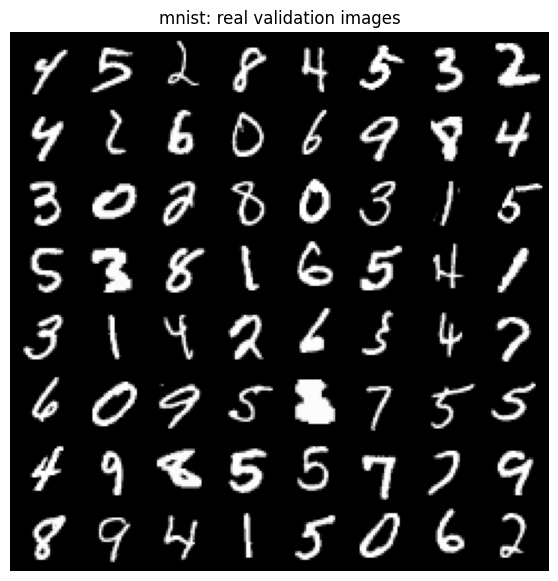

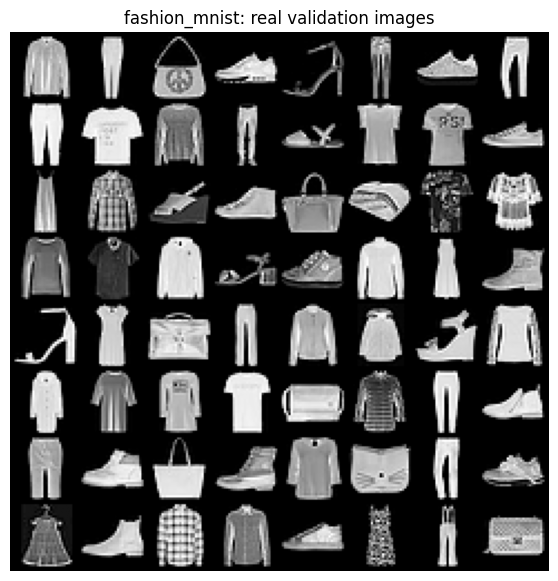

In [ ]:
# Native IDX loading avoids any dependency on torchvision compiled operators.
DATASETS = {
    'mnist': 'https://ossci-datasets.s3.amazonaws.com/mnist/',
    'fashion_mnist': 'https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/'
}
def load_idx_dataset(name, train=True):
    folder = DATA_DIR / name / 'raw'
    folder.mkdir(parents=True, exist_ok=True)
    split = 'train' if train else 't10k'
    arrays = []
    for is_image, suffix in [(True, 'images-idx3-ubyte'), (False, 'labels-idx1-ubyte')]:
        filename = f'{split}-{suffix}.gz'
        path = folder / filename
        legacy=ROOT/'.local'/'hw1'/'data'/name/'raw'/filename
        if not path.exists() and legacy.exists():
            path=legacy 
        if not path.exists():
            temporary = path.with_suffix('.download')
            try:
                print('Downloading', name, filename)
                with urllib.request.urlopen(DATASETS[name] + filename, timeout=120) as response:
                    temporary.write_bytes(response.read())
                # Reading through EOF validates the gzip CRC before caching the download.
                with gzip.open(temporary, 'rb') as stream:
                    stream.read()
                temporary.replace(path)
            finally:
                temporary.unlink(missing_ok=True)
        with gzip.open(path, 'rb') as stream:
            magic, count = struct.unpack('>II', stream.read(8))
            if is_image:
                if magic != 2051:
                    raise ValueError('Invalid image IDX header')
                rows, cols = struct.unpack('>II', stream.read(8))
                assert (rows, cols) == (28, 28)
                data = np.frombuffer(stream.read(), dtype=np.uint8).copy().reshape(count, 1, rows, cols)
                arrays.append(torch.from_numpy(data).float() / 255.)
            else:
                if magic != 2049:
                    raise ValueError('Invalid label IDX header')
                data = np.frombuffer(stream.read(), dtype=np.uint8).copy().reshape(count)
                arrays.append(torch.from_numpy(data).long())
    assert len(arrays[0]) == len(arrays[1]) == (60000 if train else 10000)
    return TensorDataset(*arrays)





load_idx_dataset=lru_cache(maxsize=4)(load_idx_dataset)
def training_loaders(name):
    full=load_idx_dataset(name,train=True)
    train,val=random_split(full,[50000,10000],generator=torch.Generator().manual_seed(SEED))
    if SMOKE_TEST: train,val=Subset(train,range(256)),Subset(val,range(128))
    options=dict(batch_size=BATCH_SIZE,num_workers=0,pin_memory=DEVICE.type=='cuda')
    return (DataLoader(train,shuffle=True,generator=torch.Generator().manual_seed(SEED),**options),
            DataLoader(val,shuffle=False,**options))
def testing_loader(name):
    dataset=load_idx_dataset(name,train=False)
    if SMOKE_TEST: dataset=Subset(dataset,range(128))
    return DataLoader(dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)

def image_grid(images,nrow=8,padding=2):
    images=images.detach().cpu()
    n,c,h,w=images.shape
    columns=min(nrow,n)
    rows=math.ceil(n/columns)
    grid=images.new_zeros(c,rows*(h+padding)+padding,columns*(w+padding)+padding)
    for index,image in enumerate(images):
        row,col=divmod(index,columns)
        top,left=padding+row*(h+padding),padding+col*(w+padding)
        grid[:,top:top+h,left:left+w]=image
    return grid[0].numpy()
def show_grid(images,title,path):
    fig,ax=plt.subplots(figsize=(7,7))
    ax.imshow(image_grid(images),cmap='gray',vmin=0,vmax=1)
    ax.set_title(('SMOKE TEST | ' if SMOKE_TEST else '')+title)
    ax.axis('off')
    fig.savefig(path,dpi=120,bbox_inches='tight')
    plt.show()
    plt.close(fig)
for dataset in DATASET_NAMES:
    show_grid(next(iter(training_loaders(dataset)[1]))[0][:64],
              dataset+': real validation images',RESULTS/f'{dataset}_real_validation.png')


## 2. Architecture and losses

**Generator:** 100-dimensional standard normal noise → Linear 256 → LeakyReLU → Linear 512 → LeakyReLU → Linear 1024 → LeakyReLU → Linear 784 → tanh → 1×28×28 image.

**Discriminator:** flatten → Linear 512 → LeakyReLU → Linear 256 → LeakyReLU → Linear 1. The output is a logit, used with BCE-with-logits for numerical stability.

This MLP baseline has no conditioning, convolutional discriminator, batch normalization or dropout. Each batch used one discriminator step followed by one generator step:

$$L_D=\tfrac12[\mathrm{BCEWithLogits}(D(x),1)+\mathrm{BCEWithLogits}(D(G(z)),0)],$$

$$L_G=\mathrm{BCEWithLogits}(D(G(z)),1).$$

Fake images were detached during the D update. During the G update, D parameters were frozen while gradients passed through D to G. Fresh noise was used for that update. The non-saturating G objective helps maintain useful gradients.

Losses near log(2) do not prove good generation. These adversarial losses are not likelihoods and cannot be compared directly with VAE ELBO or RealNVP bpd.


In [4]:
class Generator(nn.Module):
    def __init__(self,noise_dim=100):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(noise_dim,256),nn.LeakyReLU(0.2),
                               nn.Linear(256,512),nn.LeakyReLU(0.2),
                               nn.Linear(512,1024),nn.LeakyReLU(0.2),
                               nn.Linear(1024,784),nn.Tanh())
    def forward(self,z): return self.net(z).reshape(-1,1,28,28)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Flatten(),nn.Linear(784,512),nn.LeakyReLU(0.2),
                               nn.Linear(512,256),nn.LeakyReLU(0.2),nn.Linear(256,1))
    def forward(self,x): return self.net(x).flatten()

def gan_step(real,generator,discriminator,optimizer_g,optimizer_d,noise_dim=100):
    batch=len(real)
    optimizer_g.zero_grad(set_to_none=True)
    optimizer_d.zero_grad(set_to_none=True)
    with torch.no_grad():
        fake=generator(torch.randn(batch,noise_dim,device=real.device))
    real_logits=discriminator(real)
    fake_logits=discriminator(fake)
    d_loss=0.5*(F.binary_cross_entropy_with_logits(real_logits,torch.ones_like(real_logits))+
                F.binary_cross_entropy_with_logits(fake_logits,torch.zeros_like(fake_logits)))
    if not torch.isfinite(d_loss): raise FloatingPointError('Non-finite discriminator loss')
    d_loss.backward()
    optimizer_d.step()
    optimizer_d.zero_grad(set_to_none=True)
    for parameter in discriminator.parameters(): parameter.requires_grad_(False)
    try:
        fresh_fake=generator(torch.randn(batch,noise_dim,device=real.device))
        generator_logits=discriminator(fresh_fake)
        g_loss=F.binary_cross_entropy_with_logits(generator_logits,torch.ones_like(generator_logits))
        if not torch.isfinite(g_loss): raise FloatingPointError('Non-finite generator loss')
        g_loss.backward()
        optimizer_g.step()
    finally:
        for parameter in discriminator.parameters(): parameter.requires_grad_(True)
    return dict(g_loss=g_loss.item(),d_loss=d_loss.item(),
                d_real_probability=torch.sigmoid(real_logits).mean().item(),
                d_fake_probability=torch.sigmoid(fake_logits).mean().item())

# Small CPU check of shapes, ranges, finite losses and alternating updates.
def check_gan():
    generator=Generator(noise_dim=8)
    discriminator=Discriminator()
    x=generator(torch.randn(4,8))
    assert x.shape==(4,1,28,28) and ((x>=-1)&(x<=1)).all()
    assert discriminator(x).shape==(4,)
    before_g=[p.detach().clone() for p in generator.parameters()]
    before_d=[p.detach().clone() for p in discriminator.parameters()]
    opt_g=torch.optim.Adam(generator.parameters(),lr=2e-4)
    opt_d=torch.optim.Adam(discriminator.parameters(),lr=2e-4)
    stats=gan_step(torch.rand(4,1,28,28)*2-1,generator,discriminator,opt_g,opt_d,noise_dim=8)
    assert all(math.isfinite(value) for value in stats.values())
    assert any(not torch.equal(a,b) for a,b in zip(before_g,generator.parameters()))
    assert any(not torch.equal(a,b) for a,b in zip(before_d,discriminator.parameters()))
    assert all(p.grad is None and p.requires_grad for p in discriminator.parameters())
    print('Passed: output shapes/ranges, finite losses, both parameter updates, frozen-D generator step.')
check_gan()


Passed: output shapes/ranges, finite losses, both parameter updates, frozen-D generator step.


## 3. Training and mode-collapse monitoring

Both datasets used independent training from scratch for 40 epochs, batch size 128 and Adam at 2e-4 with betas (0.5, 0.999). G and D had a 1:1 update ratio.

Epoch logs contain sample-weighted losses, D(real)/D(fake), validation diagnostics and runtime. Validation used held-out real images and repeatable noise. These values describe adversarial behaviour; they did not select checkpoints.

Saved snapshots include fixed noise to track changes over time and fresh noise to show other samples. Pairwise per-pixel MSE across the fixed batch provided a simple variation diagnostic. Small values can indicate repeated outputs, but noise can inflate this measure. It does not establish semantic diversity or full class coverage.


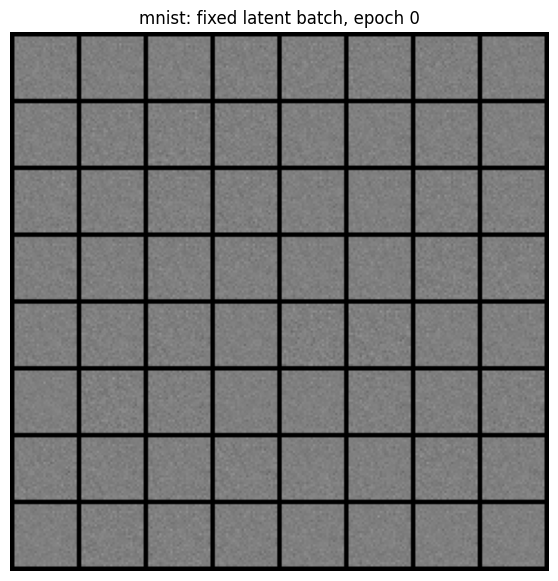

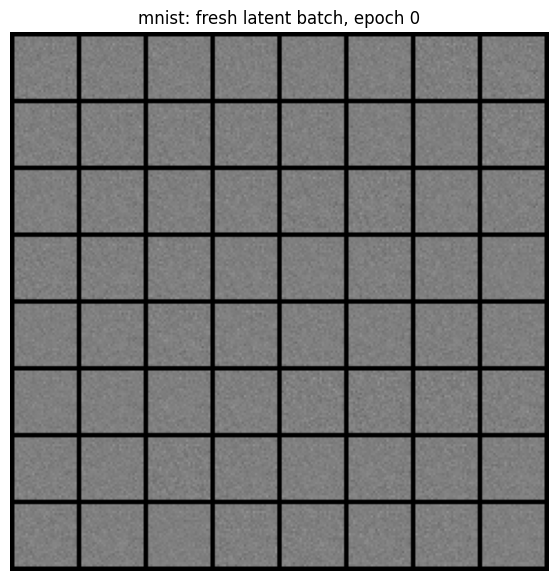

mnist | 1/40 | G 0.9059, D 0.5953 | D(real) 0.675, D(fake) 0.535 | 2.4s


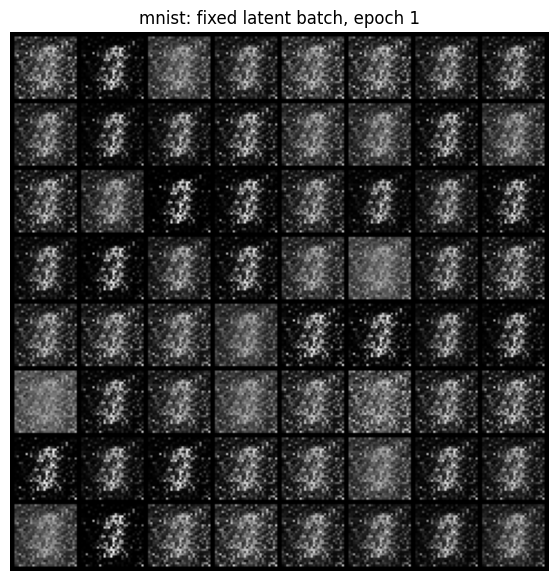

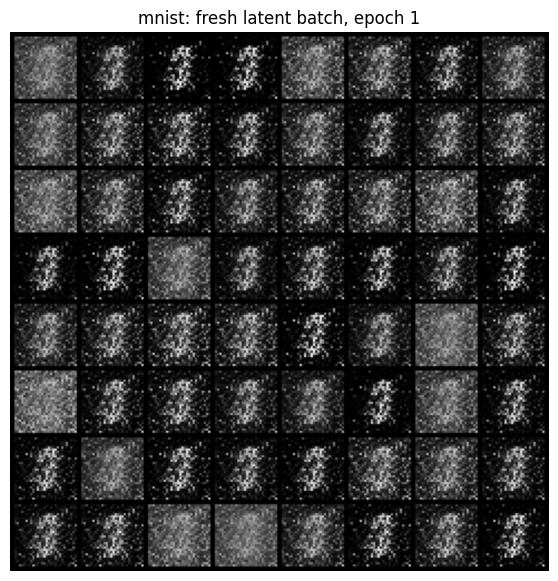

mnist | 2/40 | G 1.4236, D 0.5196 | D(real) 0.684, D(fake) 0.433 | 2.2s
mnist | 3/40 | G 1.7152, D 0.4945 | D(real) 0.686, D(fake) 0.376 | 2.3s
mnist | 4/40 | G 1.7597, D 0.4655 | D(real) 0.696, D(fake) 0.344 | 2.3s
mnist | 5/40 | G 1.8216, D 0.4537 | D(real) 0.700, D(fake) 0.324 | 2.2s


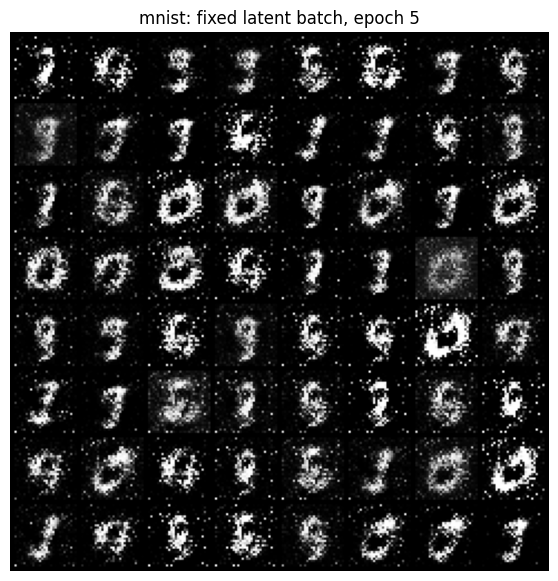

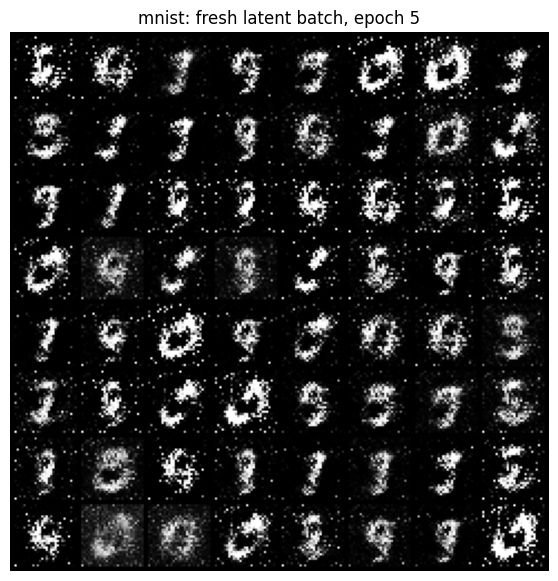

mnist | 6/40 | G 1.8982, D 0.4401 | D(real) 0.712, D(fake) 0.317 | 2.1s
mnist | 7/40 | G 1.8684, D 0.4407 | D(real) 0.706, D(fake) 0.306 | 2.1s
mnist | 8/40 | G 1.9618, D 0.4196 | D(real) 0.725, D(fake) 0.289 | 2.1s
mnist | 9/40 | G 1.7996, D 0.4396 | D(real) 0.708, D(fake) 0.306 | 2.1s
mnist | 10/40 | G 1.8575, D 0.4205 | D(real) 0.721, D(fake) 0.291 | 2.1s


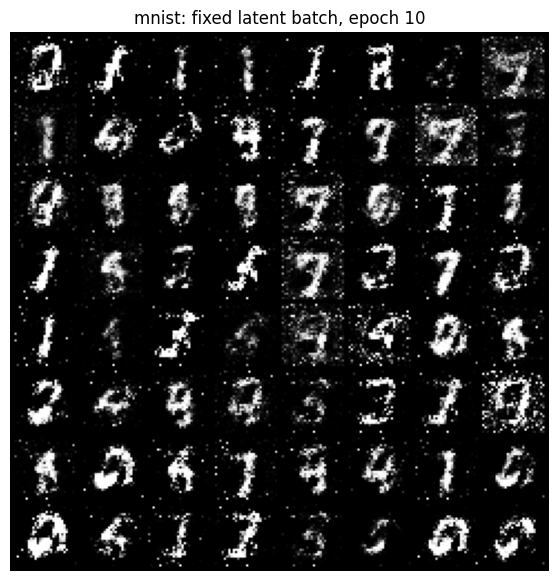

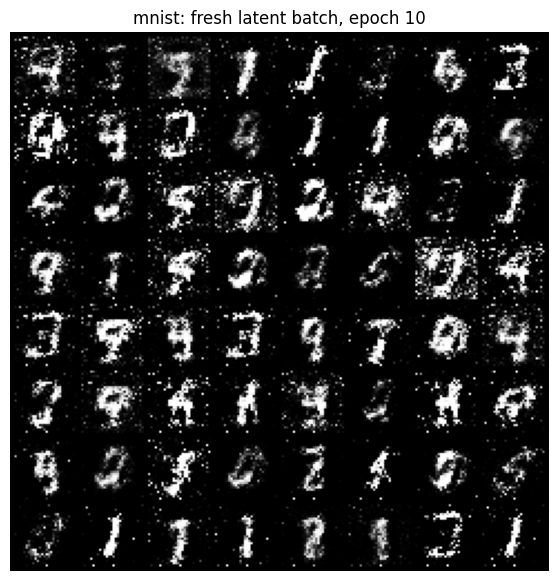

mnist | 11/40 | G 1.6823, D 0.4525 | D(real) 0.702, D(fake) 0.306 | 2.1s
mnist | 12/40 | G 1.6127, D 0.4520 | D(real) 0.699, D(fake) 0.310 | 2.1s
mnist | 13/40 | G 1.5841, D 0.4531 | D(real) 0.698, D(fake) 0.309 | 2.1s
mnist | 14/40 | G 1.4911, D 0.4831 | D(real) 0.678, D(fake) 0.328 | 2.1s
mnist | 15/40 | G 1.3139, D 0.5218 | D(real) 0.650, D(fake) 0.356 | 2.1s


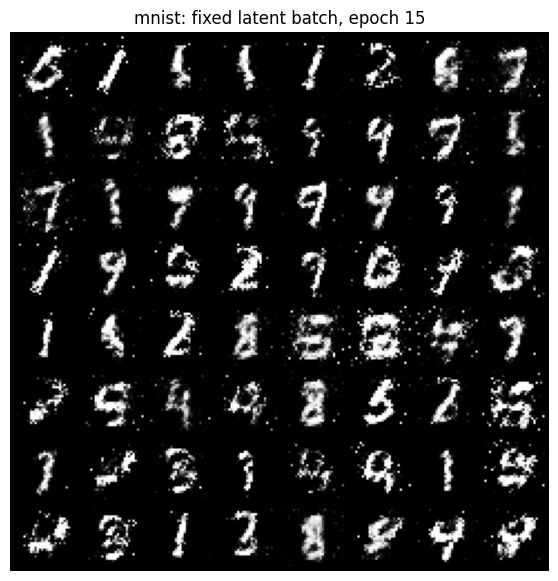

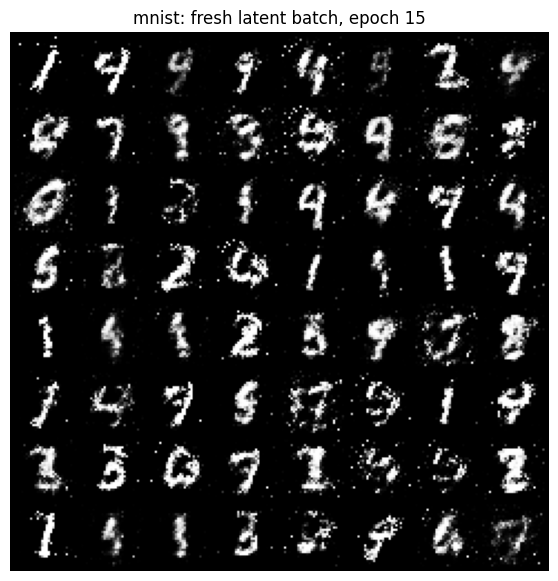

mnist | 16/40 | G 1.2317, D 0.5382 | D(real) 0.636, D(fake) 0.370 | 2.1s
mnist | 17/40 | G 1.1460, D 0.5636 | D(real) 0.616, D(fake) 0.389 | 2.2s
mnist | 18/40 | G 1.1042, D 0.5835 | D(real) 0.603, D(fake) 0.402 | 2.1s
mnist | 19/40 | G 1.0916, D 0.5795 | D(real) 0.602, D(fake) 0.403 | 2.1s
mnist | 20/40 | G 1.0838, D 0.5788 | D(real) 0.601, D(fake) 0.404 | 2.1s


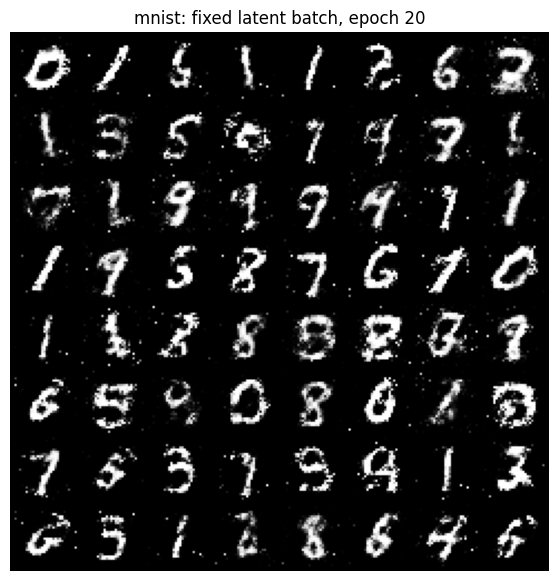

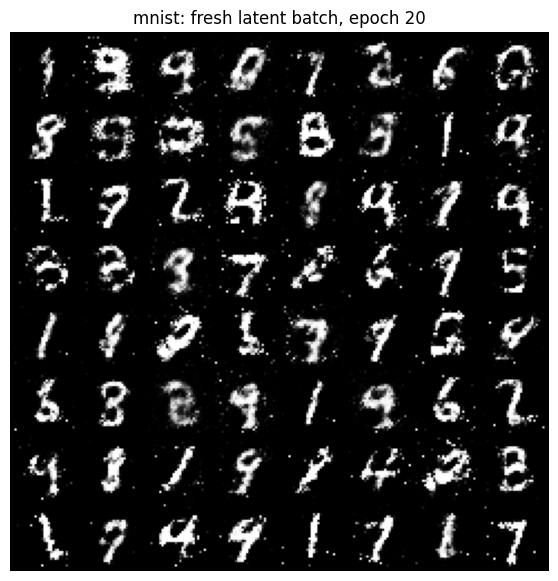

mnist | 21/40 | G 1.0545, D 0.5943 | D(real) 0.592, D(fake) 0.413 | 2.2s
mnist | 22/40 | G 1.0409, D 0.5961 | D(real) 0.588, D(fake) 0.416 | 2.2s
mnist | 23/40 | G 1.0387, D 0.5969 | D(real) 0.587, D(fake) 0.418 | 2.1s
mnist | 24/40 | G 1.0361, D 0.5998 | D(real) 0.584, D(fake) 0.419 | 2.1s
mnist | 25/40 | G 1.0224, D 0.5994 | D(real) 0.584, D(fake) 0.420 | 2.1s


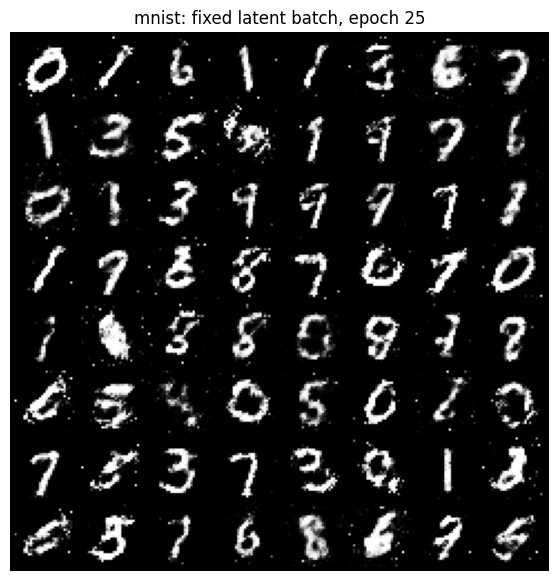

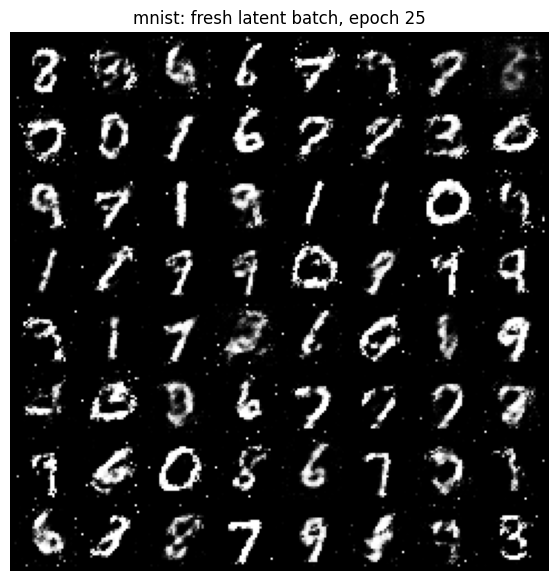

mnist | 26/40 | G 1.0333, D 0.5961 | D(real) 0.586, D(fake) 0.417 | 2.2s
mnist | 27/40 | G 1.0374, D 0.5969 | D(real) 0.585, D(fake) 0.418 | 2.2s
mnist | 28/40 | G 1.0405, D 0.5953 | D(real) 0.587, D(fake) 0.416 | 2.1s
mnist | 29/40 | G 1.0290, D 0.5991 | D(real) 0.584, D(fake) 0.419 | 2.1s
mnist | 30/40 | G 1.0211, D 0.5988 | D(real) 0.583, D(fake) 0.419 | 2.1s


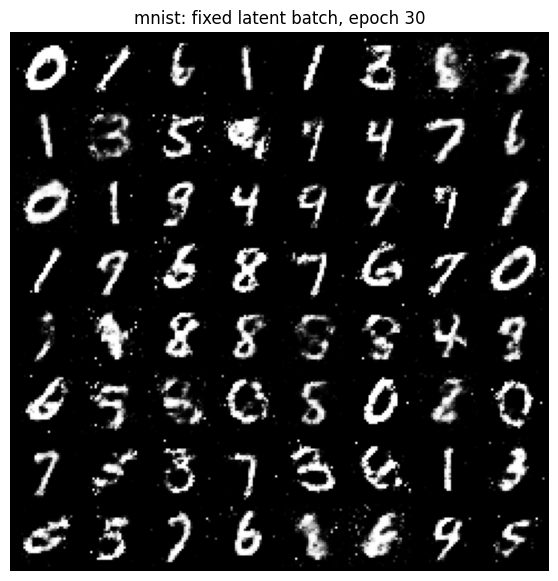

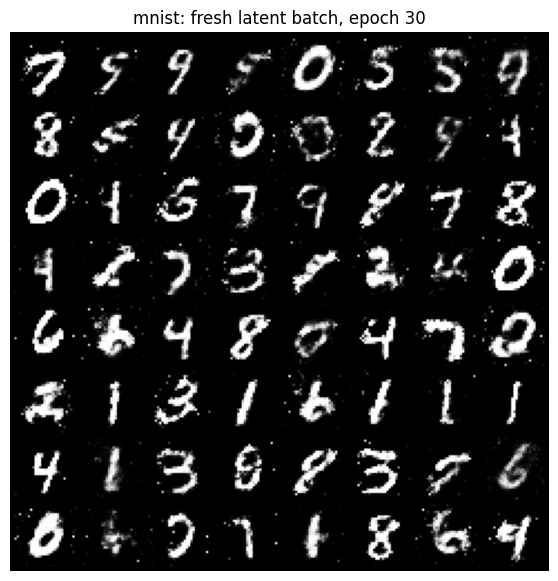

mnist | 31/40 | G 1.0266, D 0.5967 | D(real) 0.585, D(fake) 0.418 | 2.1s
mnist | 32/40 | G 1.0163, D 0.6002 | D(real) 0.582, D(fake) 0.421 | 2.1s
mnist | 33/40 | G 1.0225, D 0.5992 | D(real) 0.583, D(fake) 0.420 | 2.1s
mnist | 34/40 | G 1.0236, D 0.5974 | D(real) 0.584, D(fake) 0.419 | 2.1s
mnist | 35/40 | G 1.0214, D 0.5983 | D(real) 0.583, D(fake) 0.419 | 2.1s


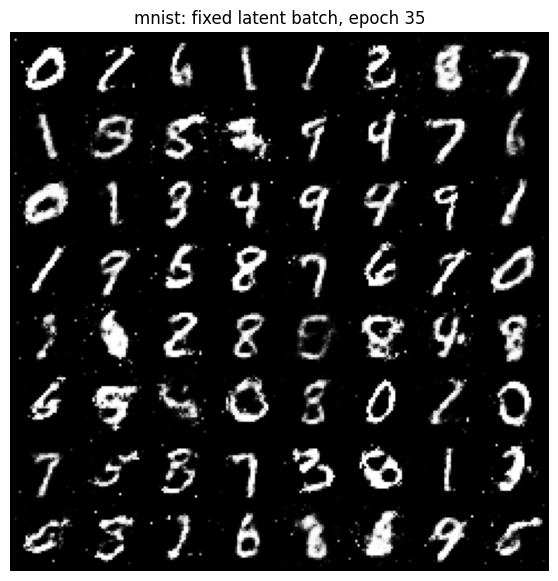

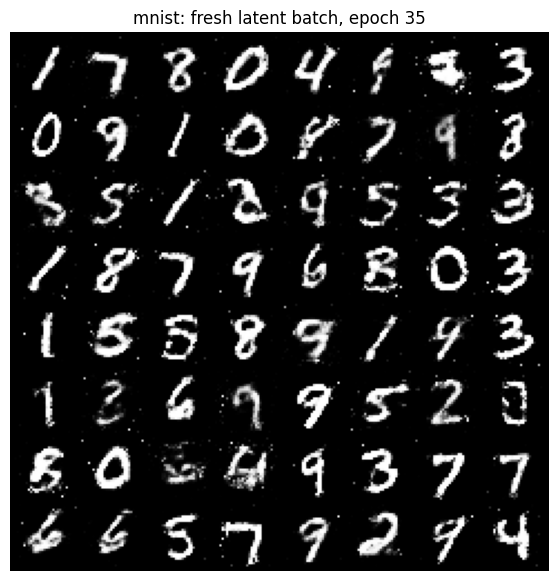

mnist | 36/40 | G 1.0287, D 0.5947 | D(real) 0.585, D(fake) 0.417 | 2.1s
mnist | 37/40 | G 1.0195, D 0.5973 | D(real) 0.584, D(fake) 0.419 | 2.1s
mnist | 38/40 | G 1.0256, D 0.5970 | D(real) 0.585, D(fake) 0.418 | 2.1s
mnist | 39/40 | G 1.0317, D 0.5917 | D(real) 0.587, D(fake) 0.415 | 2.1s
mnist | 40/40 | G 1.0340, D 0.5937 | D(real) 0.587, D(fake) 0.416 | 2.1s


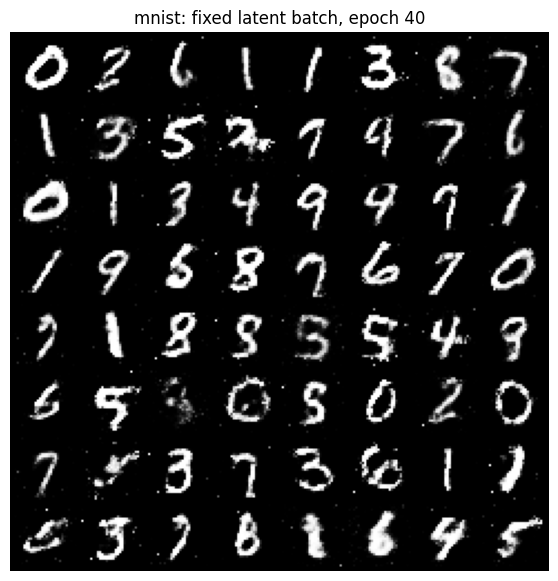

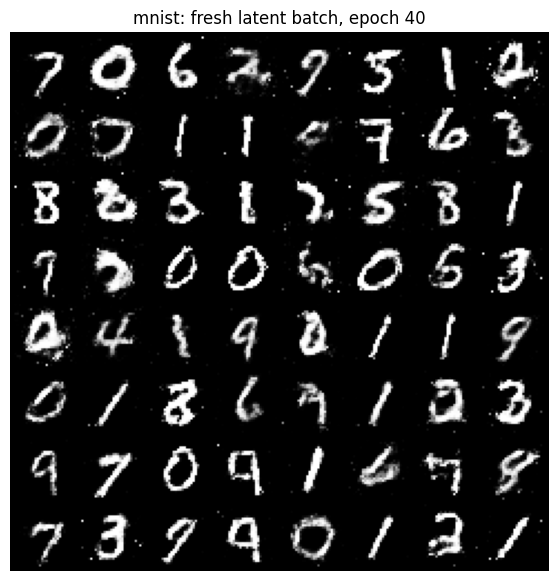

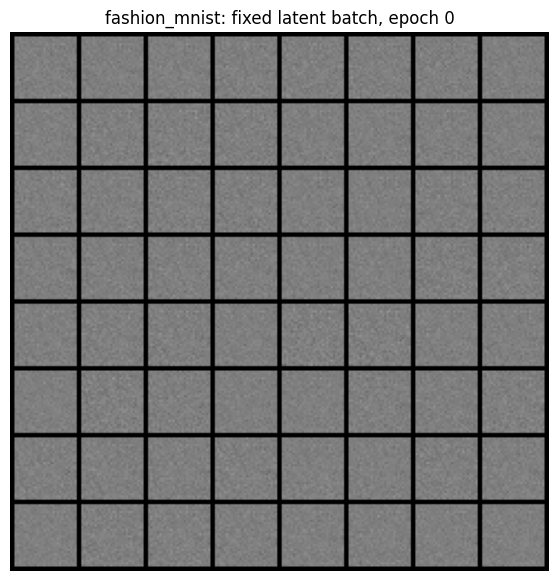

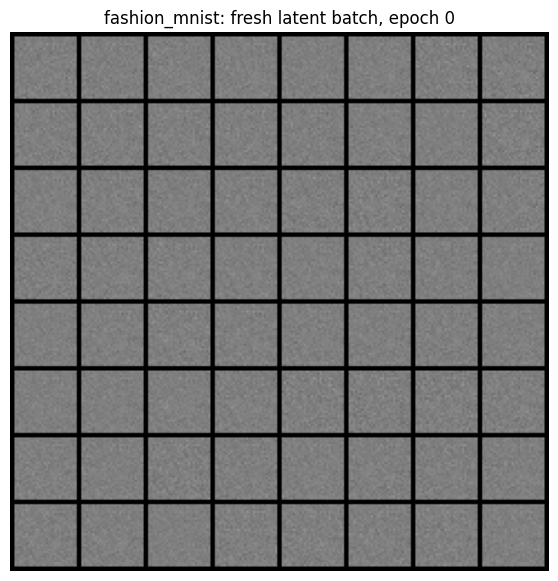

fashion_mnist | 1/40 | G 1.1592, D 0.4637 | D(real) 0.807, D(fake) 0.470 | 2.4s


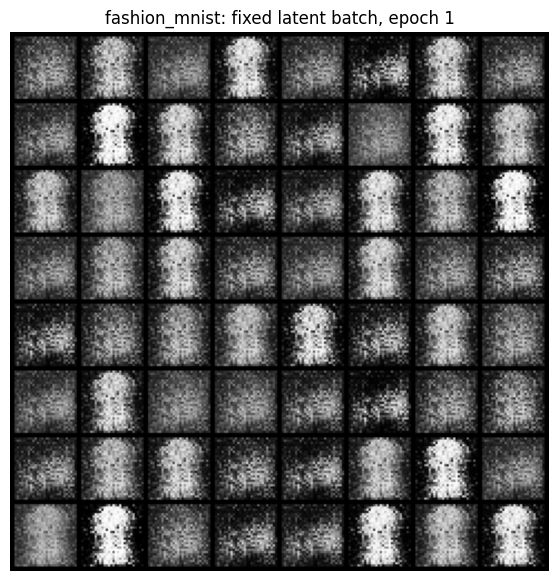

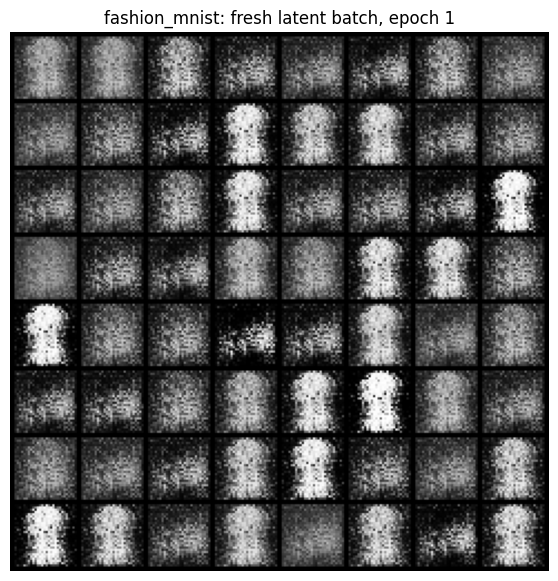

fashion_mnist | 2/40 | G 1.7353, D 0.4813 | D(real) 0.690, D(fake) 0.382 | 2.2s
fashion_mnist | 3/40 | G 1.8942, D 0.4814 | D(real) 0.684, D(fake) 0.351 | 2.1s
fashion_mnist | 4/40 | G 1.8318, D 0.4768 | D(real) 0.682, D(fake) 0.336 | 2.1s
fashion_mnist | 5/40 | G 1.5395, D 0.5023 | D(real) 0.660, D(fake) 0.357 | 2.0s


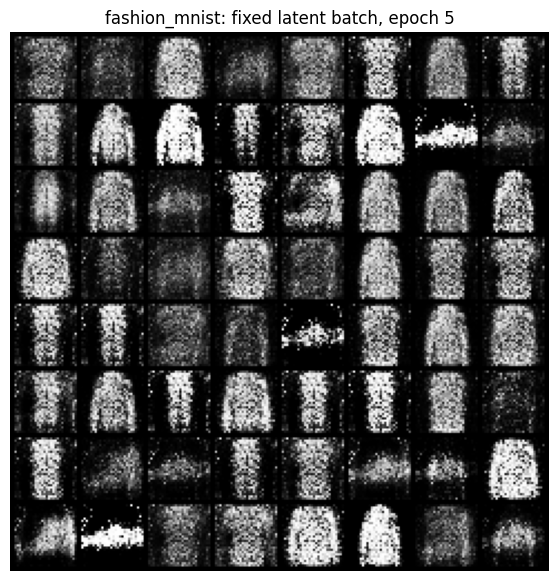

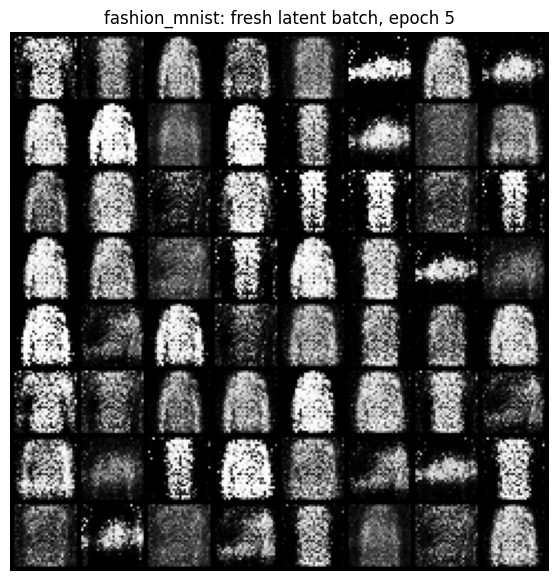

fashion_mnist | 6/40 | G 1.3942, D 0.5404 | D(real) 0.630, D(fake) 0.381 | 2.1s
fashion_mnist | 7/40 | G 1.3600, D 0.5597 | D(real) 0.618, D(fake) 0.393 | 2.1s
fashion_mnist | 8/40 | G 1.2433, D 0.5574 | D(real) 0.613, D(fake) 0.395 | 2.1s
fashion_mnist | 9/40 | G 1.2064, D 0.5877 | D(real) 0.595, D(fake) 0.411 | 2.1s
fashion_mnist | 10/40 | G 1.1538, D 0.6011 | D(real) 0.585, D(fake) 0.421 | 2.1s


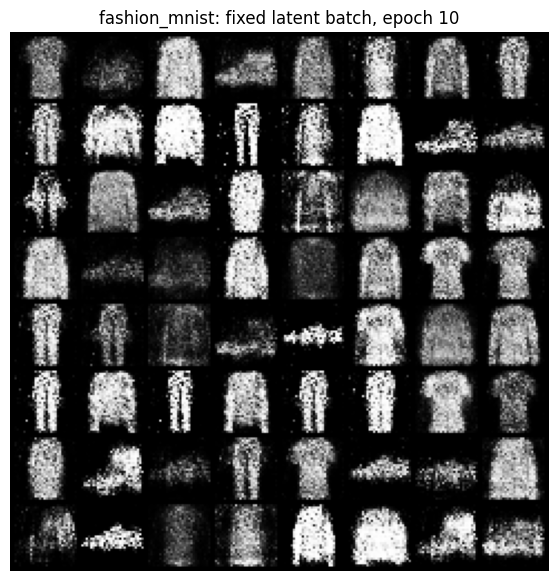

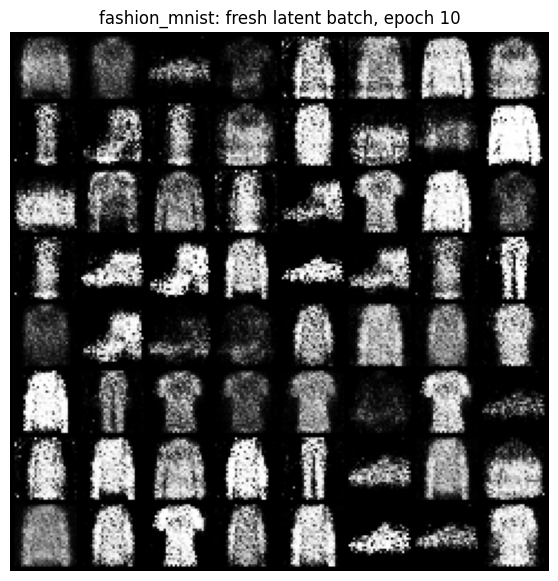

fashion_mnist | 11/40 | G 1.0775, D 0.6014 | D(real) 0.579, D(fake) 0.426 | 2.0s
fashion_mnist | 12/40 | G 1.1147, D 0.6047 | D(real) 0.580, D(fake) 0.426 | 2.1s
fashion_mnist | 13/40 | G 1.1084, D 0.6031 | D(real) 0.580, D(fake) 0.425 | 2.1s
fashion_mnist | 14/40 | G 1.0678, D 0.6099 | D(real) 0.576, D(fake) 0.429 | 2.1s
fashion_mnist | 15/40 | G 1.0485, D 0.6148 | D(real) 0.571, D(fake) 0.433 | 2.1s


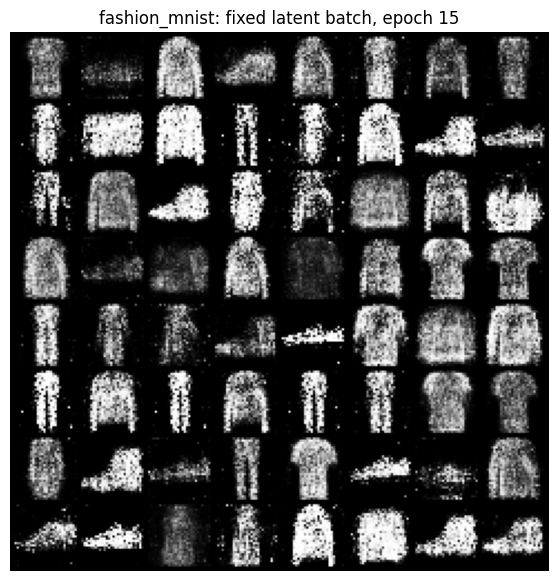

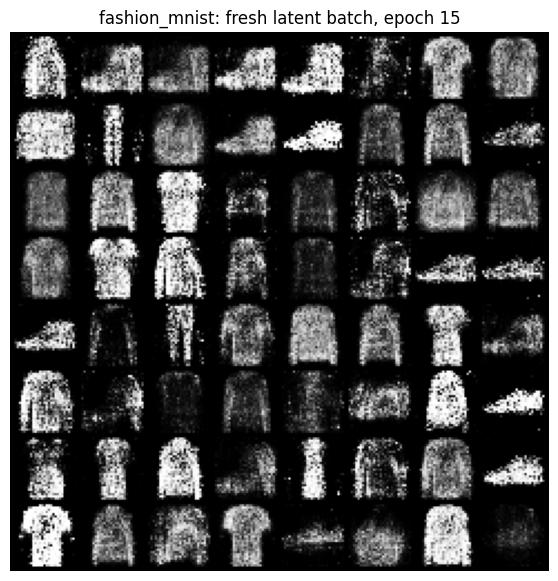

fashion_mnist | 16/40 | G 1.0247, D 0.6198 | D(real) 0.567, D(fake) 0.436 | 2.1s
fashion_mnist | 17/40 | G 1.0311, D 0.6206 | D(real) 0.566, D(fake) 0.437 | 2.0s
fashion_mnist | 18/40 | G 1.0042, D 0.6250 | D(real) 0.564, D(fake) 0.440 | 2.0s
fashion_mnist | 19/40 | G 0.9796, D 0.6280 | D(real) 0.559, D(fake) 0.443 | 2.1s
fashion_mnist | 20/40 | G 0.9726, D 0.6335 | D(real) 0.556, D(fake) 0.447 | 2.1s


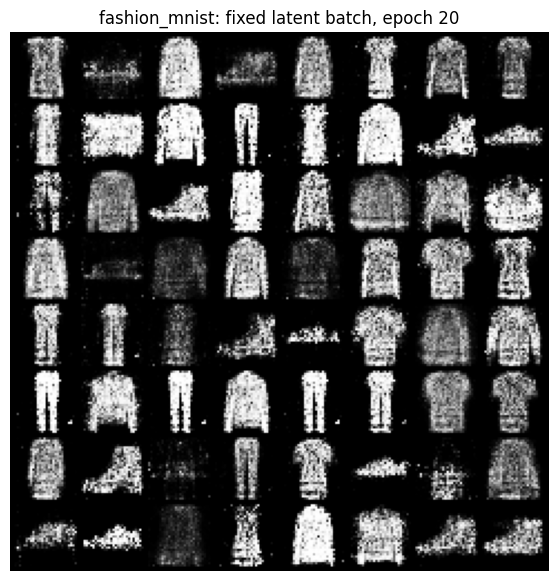

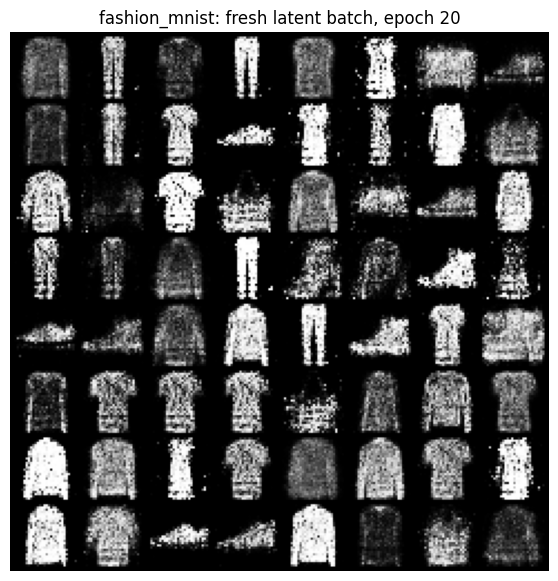

fashion_mnist | 21/40 | G 0.9350, D 0.6375 | D(real) 0.551, D(fake) 0.451 | 2.1s
fashion_mnist | 22/40 | G 0.9399, D 0.6407 | D(real) 0.549, D(fake) 0.452 | 2.1s
fashion_mnist | 23/40 | G 0.9317, D 0.6430 | D(real) 0.547, D(fake) 0.454 | 2.1s
fashion_mnist | 24/40 | G 0.9311, D 0.6427 | D(real) 0.548, D(fake) 0.454 | 2.1s
fashion_mnist | 25/40 | G 0.9223, D 0.6463 | D(real) 0.545, D(fake) 0.457 | 2.0s


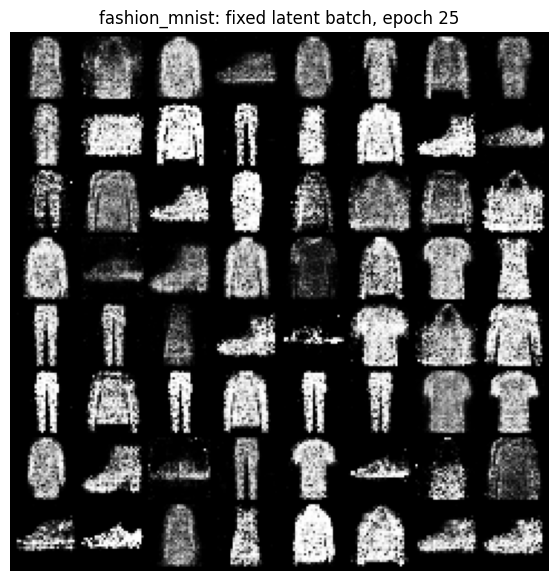

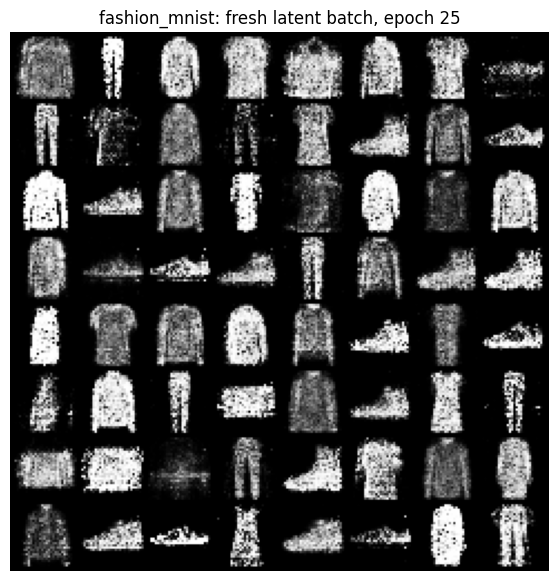

fashion_mnist | 26/40 | G 0.9091, D 0.6459 | D(real) 0.544, D(fake) 0.457 | 2.1s
fashion_mnist | 27/40 | G 0.9139, D 0.6487 | D(real) 0.542, D(fake) 0.459 | 2.0s
fashion_mnist | 28/40 | G 0.8934, D 0.6508 | D(real) 0.540, D(fake) 0.461 | 2.1s
fashion_mnist | 29/40 | G 0.8911, D 0.6526 | D(real) 0.538, D(fake) 0.462 | 2.1s
fashion_mnist | 30/40 | G 0.8919, D 0.6514 | D(real) 0.540, D(fake) 0.462 | 2.0s


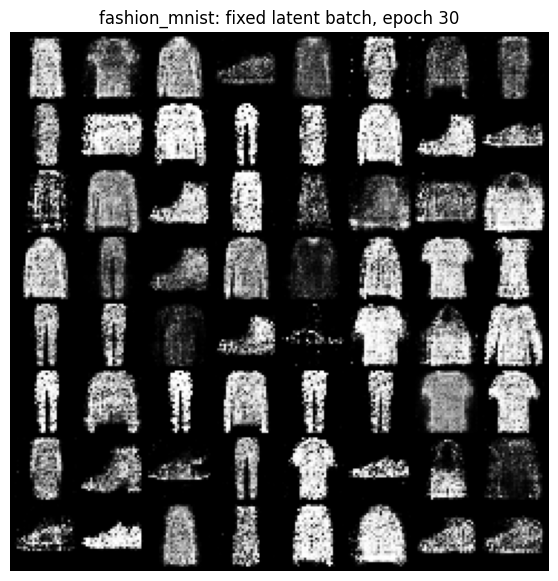

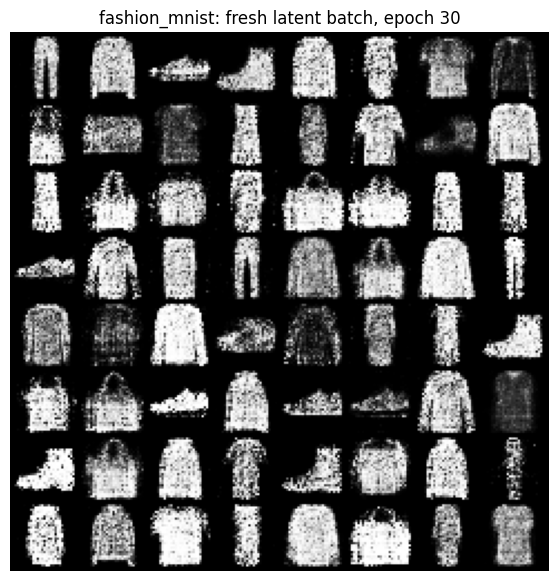

fashion_mnist | 31/40 | G 0.8885, D 0.6517 | D(real) 0.539, D(fake) 0.462 | 2.1s
fashion_mnist | 32/40 | G 0.8799, D 0.6527 | D(real) 0.538, D(fake) 0.464 | 2.0s
fashion_mnist | 33/40 | G 0.8734, D 0.6565 | D(real) 0.535, D(fake) 0.465 | 2.1s
fashion_mnist | 34/40 | G 0.8633, D 0.6575 | D(real) 0.534, D(fake) 0.466 | 2.1s
fashion_mnist | 35/40 | G 0.8595, D 0.6564 | D(real) 0.535, D(fake) 0.467 | 2.0s


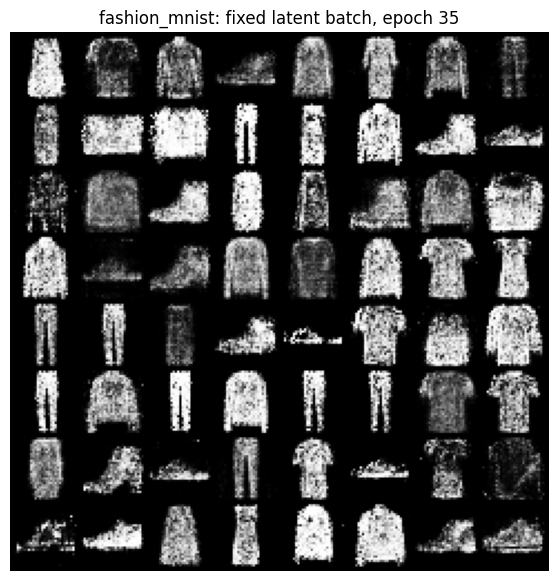

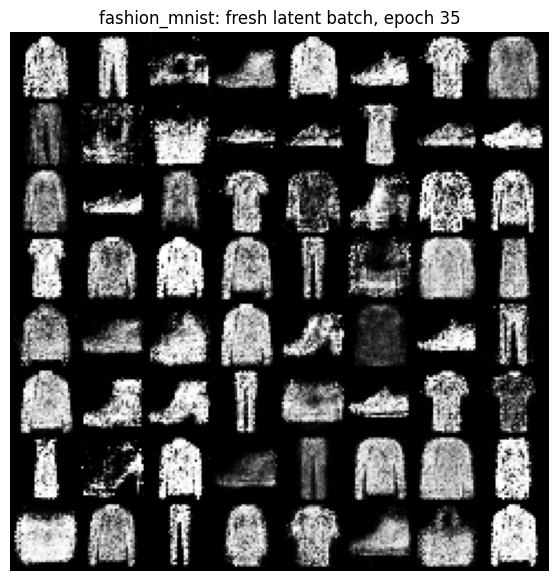

fashion_mnist | 36/40 | G 0.8630, D 0.6598 | D(real) 0.533, D(fake) 0.468 | 2.1s
fashion_mnist | 37/40 | G 0.8506, D 0.6590 | D(real) 0.532, D(fake) 0.469 | 2.0s
fashion_mnist | 38/40 | G 0.8542, D 0.6594 | D(real) 0.532, D(fake) 0.468 | 2.0s
fashion_mnist | 39/40 | G 0.8517, D 0.6596 | D(real) 0.532, D(fake) 0.469 | 2.0s
fashion_mnist | 40/40 | G 0.8571, D 0.6590 | D(real) 0.532, D(fake) 0.468 | 2.0s


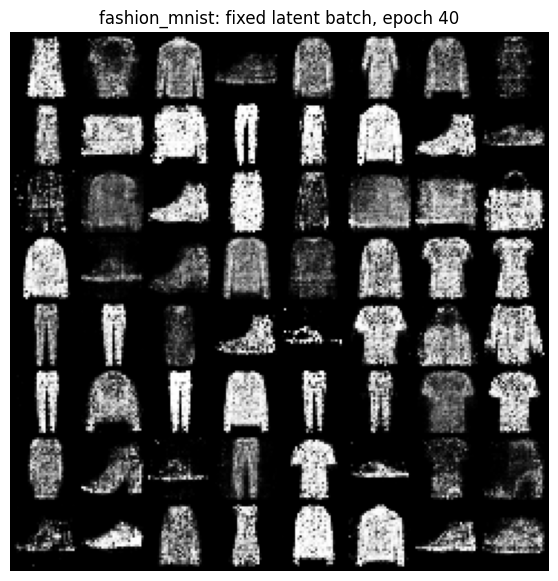

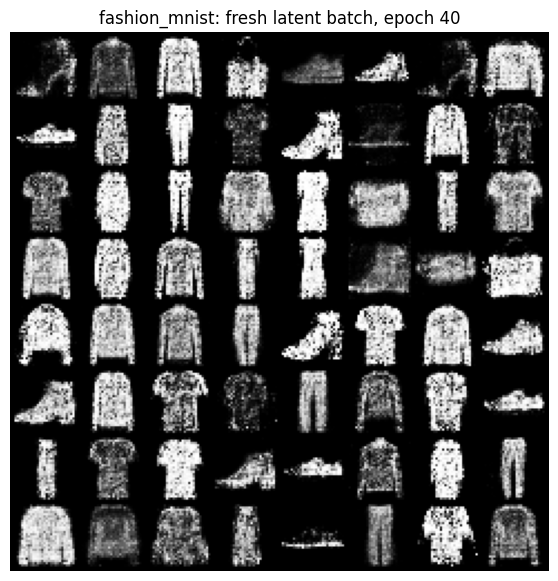

,dataset,epochs,seconds,final_fixed_pairwise_pixel_mse
0,mnist,40,85.326175,0.119504
1,fashion_mnist,40,82.732448,0.159301


In [5]:
@torch.no_grad()
def evaluate_gan(generator,discriminator,loader,seed=2026):
    generator.eval()
    discriminator.eval()
    noise_rng=torch.Generator(device=DEVICE).manual_seed(seed)
    totals=dict(g_loss=0.,d_loss=0.,d_real_probability=0.,d_fake_probability=0.)
    count=0
    for gray,_ in loader:
        real=gray.to(DEVICE)*2-1
        fake=generator(torch.randn(len(real),NOISE_DIM,device=DEVICE,generator=noise_rng))
        real_logits,fake_logits=discriminator(real),discriminator(fake)
        real_bce=F.binary_cross_entropy_with_logits(real_logits,torch.ones_like(real_logits))
        fake_bce=F.binary_cross_entropy_with_logits(fake_logits,torch.zeros_like(fake_logits))
        values=dict(g_loss=F.binary_cross_entropy_with_logits(fake_logits,torch.ones_like(fake_logits)),
                    d_loss=0.5*(real_bce+fake_bce),d_real_probability=torch.sigmoid(real_logits).mean(),
                    d_fake_probability=torch.sigmoid(fake_logits).mean())
        for key,value in values.items(): totals[key]+=value.item()*len(real)
        count+=len(real)
    return {key:value/count for key,value in totals.items()}

@torch.no_grad()
def generate_images(generator,seed=123,n=64):
    generator.eval()
    rng=torch.Generator(device=DEVICE).manual_seed(seed)
    z=torch.randn(n,NOISE_DIM,device=DEVICE,generator=rng)
    return ((generator(z)+1)/2).cpu()

def pairwise_pixel_mse(images):
    return torch.pdist(images.flatten(1),p=2).square().mean().item()/784

def save_progress(generator,folder,epoch,dataset):
    fixed=generate_images(generator,seed=123)
    fresh=generate_images(generator,seed=1000+epoch)
    show_grid(fixed,f'{dataset}: fixed latent batch, epoch {epoch}',folder/f'fixed_epoch_{epoch:03d}.png')
    show_grid(fresh,f'{dataset}: fresh latent batch, epoch {epoch}',folder/f'fresh_epoch_{epoch:03d}.png')
    return pairwise_pixel_mse(fixed)

def train_gan(dataset):
    seed_all()
    train,val=training_loaders(dataset)
    generator=Generator(NOISE_DIM).to(DEVICE)
    discriminator=Discriminator().to(DEVICE)
    seed_all()
    opt_g=torch.optim.Adam(generator.parameters(),lr=LEARNING_RATE_G,betas=ADAM_BETAS)
    opt_d=torch.optim.Adam(discriminator.parameters(),lr=LEARNING_RATE_D,betas=ADAM_BETAS)
    folder=RESULTS/dataset
    folder.mkdir(parents=True,exist_ok=True)
    epochs=2 if SMOKE_TEST else EPOCHS
    config=dict(dataset=dataset,noise_dim=NOISE_DIM,epochs=epochs,batch_size=BATCH_SIZE,seed=SEED,
                learning_rate_g=LEARNING_RATE_G,learning_rate_d=LEARNING_RATE_D,adam_betas=ADAM_BETAS,
                updates='one D and one G per batch',d_loss_scaling='half sum of real/fake BCE means',
                generator_parameters=sum(p.numel() for p in generator.parameters()),
                discriminator_parameters=sum(p.numel() for p in discriminator.parameters()),
                train_size=len(train.dataset),validation_size=len(val.dataset),smoke_test=SMOKE_TEST)
    (folder/'config.json').write_text(json.dumps(config,indent=2))
    save_progress(generator,folder,0,dataset)
    history=[]
    for epoch in range(1,epochs+1):
        started=time.perf_counter()
        generator.train()
        discriminator.train()
        totals=dict(g_loss=0.,d_loss=0.,d_real_probability=0.,d_fake_probability=0.)
        count=0
        for gray,_ in train:
            real=gray.to(DEVICE)*2-1
            values=gan_step(real,generator,discriminator,opt_g,opt_d,NOISE_DIM)
            for key,value in values.items(): totals[key]+=value*len(real)
            count+=len(real)
        validation=evaluate_gan(generator,discriminator,val)
        fixed=generate_images(generator,seed=123)
        row=dict(epoch=epoch,**{'train_'+key:value/count for key,value in totals.items()},
                 **{'val_'+key:value for key,value in validation.items()},
                 fixed_batch_pairwise_pixel_mse=pairwise_pixel_mse(fixed),
                 seconds=time.perf_counter()-started)
        history.append(row)
        pd.DataFrame(history).to_csv(folder/'history.csv',index=False)
        print(f'{dataset} | {epoch}/{epochs} | G {row["train_g_loss"]:.4f}, D {row["train_d_loss"]:.4f} | D(real) {row["train_d_real_probability"]:.3f}, D(fake) {row["train_d_fake_probability"]:.3f} | {row["seconds"]:.1f}s',flush=True)
        if epoch==1 or epoch%SAMPLE_EVERY==0 or epoch==epochs:
            save_progress(generator,folder,epoch,dataset)
            torch.save(dict(generator=generator.state_dict(),discriminator=discriminator.state_dict(),
                            epoch=epoch,config=config),CHECKPOINTS/f'{dataset}_epoch_{epoch:03d}.pt')
    final_checkpoint=CHECKPOINTS/f'{dataset}_final.pt'
    torch.save(dict(generator=generator.state_dict(),discriminator=discriminator.state_dict(),
                    epoch=epochs,config=config),final_checkpoint)
    return dict(dataset=dataset,epochs=epochs,checkpoint=str(final_checkpoint),
                seconds=sum(row['seconds'] for row in history),
                final_fixed_pairwise_pixel_mse=history[-1]['fixed_batch_pairwise_pixel_mse'])

gan_runs=[]
for dataset in DATASET_NAMES:
    gan_runs.append(train_gan(dataset))
    pd.DataFrame([{key:value for key,value in run.items() if key!='checkpoint'} for run in gan_runs]).to_csv(RESULTS/'run_summary.csv',index=False)
display(pd.DataFrame([{key:value for key,value in run.items() if key!='checkpoint'} for run in gan_runs]))


## 4. Loss curves and sample evolution

The plots show train/validation G and D losses, discriminator confidence and pixel variation. Training probabilities were recorded before the batch's D update; validation used epoch-end models.

The image progression gives context for oscillating losses and changing quality. The reported model is the final fixed-epoch checkpoint, rather than the checkpoint with the lowest G or D loss.


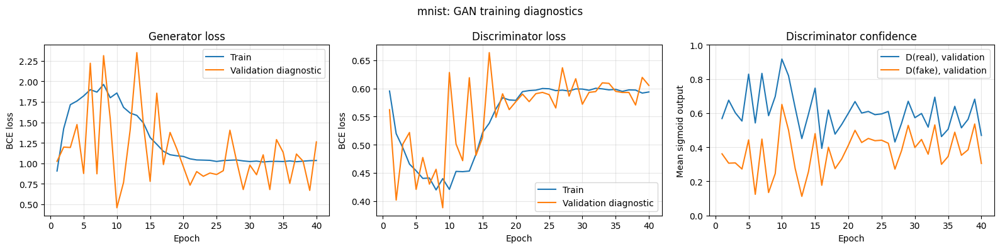

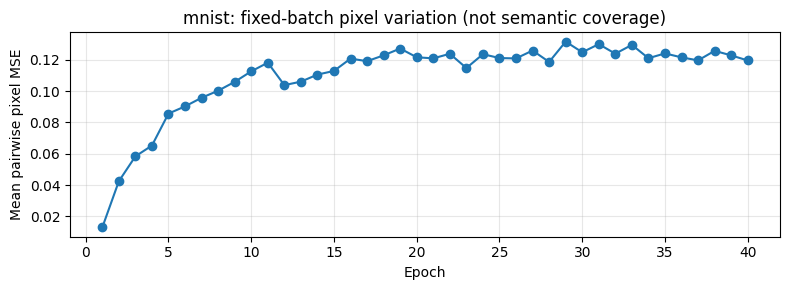

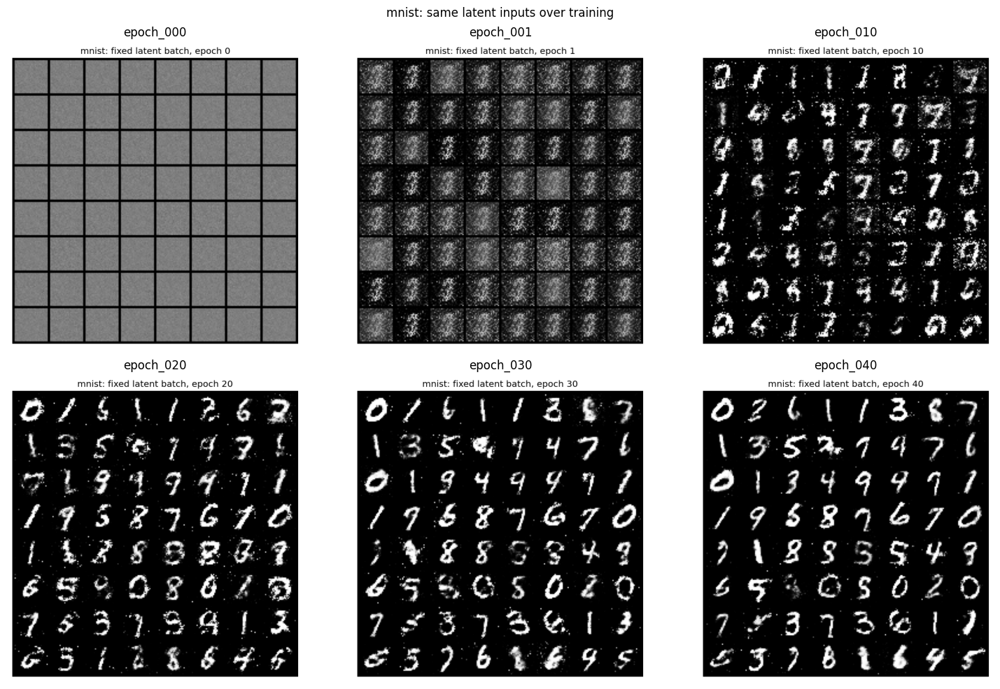

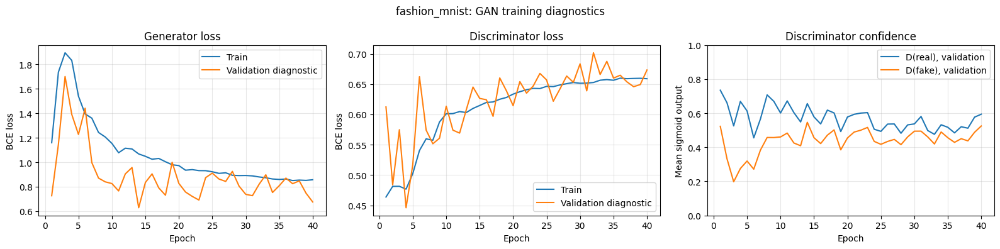

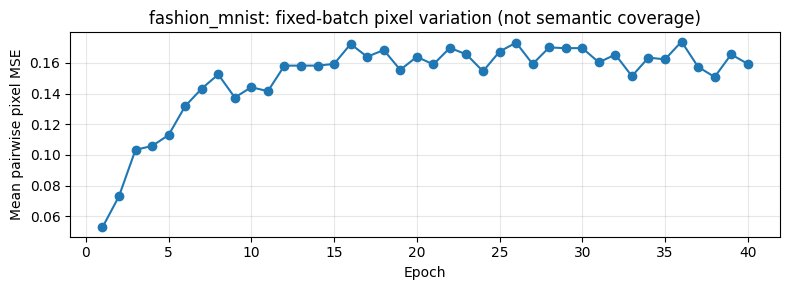

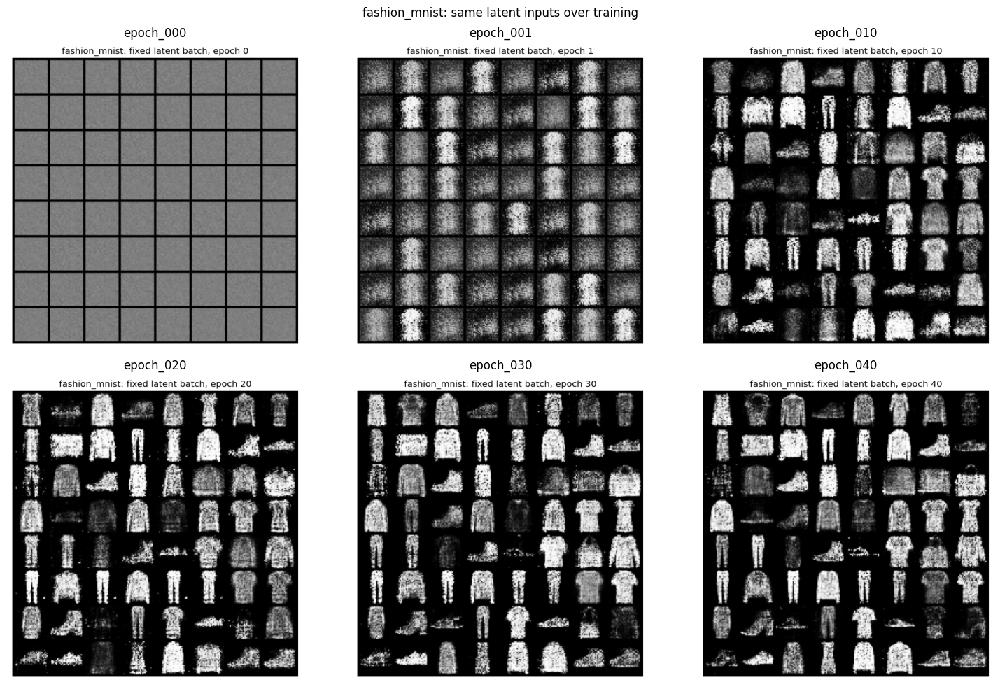

In [6]:
for dataset in DATASET_NAMES:
    history=pd.read_csv(RESULTS/dataset/'history.csv')
    fig,axes=plt.subplots(1,3,figsize=(16,4))
    for ax,metric,title in zip(axes[:2],['g_loss','d_loss'],['Generator loss','Discriminator loss']):
        ax.plot(history.epoch,history['train_'+metric],label='Train')
        ax.plot(history.epoch,history['val_'+metric],label='Validation diagnostic')
        ax.set(title=title,xlabel='Epoch',ylabel='BCE loss')
        ax.grid(alpha=0.3)
        ax.legend()
    axes[2].plot(history.epoch,history.val_d_real_probability,label='D(real), validation')
    axes[2].plot(history.epoch,history.val_d_fake_probability,label='D(fake), validation')
    axes[2].set(title='Discriminator confidence',xlabel='Epoch',ylabel='Mean sigmoid output',ylim=(0,1))
    axes[2].grid(alpha=0.3)
    axes[2].legend()
    fig.suptitle(('SMOKE TEST | ' if SMOKE_TEST else '')+dataset+': GAN training diagnostics')
    fig.tight_layout()
    fig.savefig(RESULTS/f'{dataset}_loss_curves.png',dpi=130)
    plt.show()
    plt.close(fig)
    fig,ax=plt.subplots(figsize=(8,3))
    ax.plot(history.epoch,history.fixed_batch_pairwise_pixel_mse,'o-')
    ax.set(title=dataset+': fixed-batch pixel variation (not semantic coverage)',
           xlabel='Epoch',ylabel='Mean pairwise pixel MSE')
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(RESULTS/f'{dataset}_diversity_proxy.png',dpi=130)
    plt.show()
    plt.close(fig)

    paths=sorted((RESULTS/dataset).glob('fixed_epoch_*.png'))
    selected=[paths[i] for i in sorted(set(np.linspace(0,len(paths)-1,min(6,len(paths)),dtype=int)))]
    fig,axes=plt.subplots(2,3,figsize=(15,10))
    for ax in axes.flat: ax.axis('off')
    for ax,path in zip(axes.flat,selected):
        ax.imshow(plt.imread(path))
        ax.set_title(path.stem.replace('fixed_',''))
    fig.suptitle(('SMOKE TEST | ' if SMOKE_TEST else '')+dataset+': same latent inputs over training')
    fig.tight_layout()
    fig.savefig(RESULTS/f'{dataset}_generation_progress.png',dpi=130,bbox_inches='tight')
    plt.show()
    plt.close(fig)


## 5. Final real/generated comparison

Real test images are shown beside independent generated images, not reconstruction pairs. Three additional latent seeds show variety beyond the fixed training grid.

The saved samples have limited detail and diversity, especially noisy Fashion-MNIST outputs. Test discriminator diagnostics describe adversarial behaviour only; they are not likelihood, FID or evidence that mode collapse is absent.


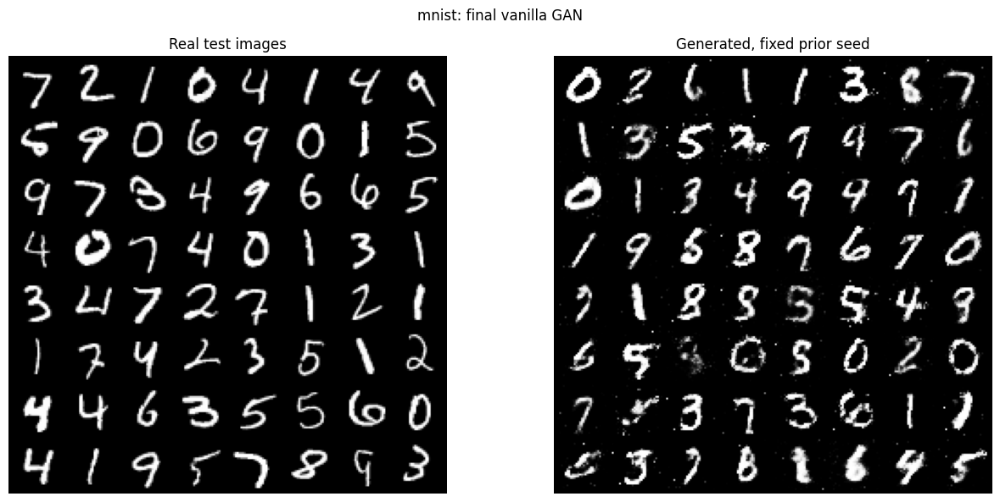

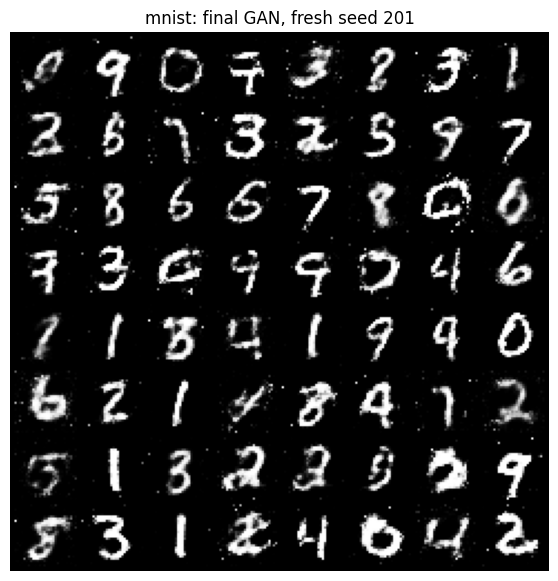

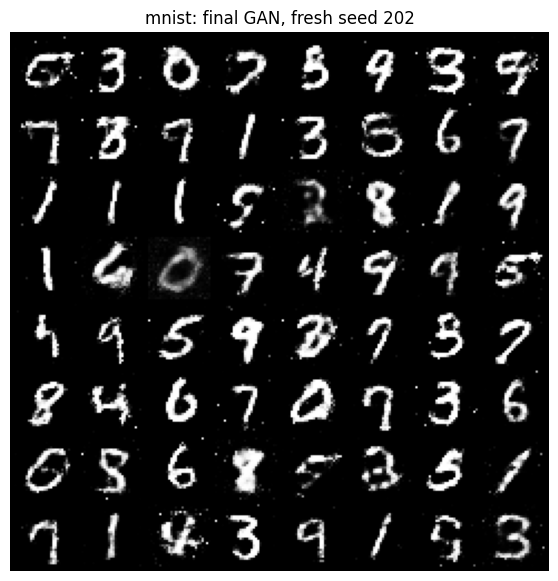

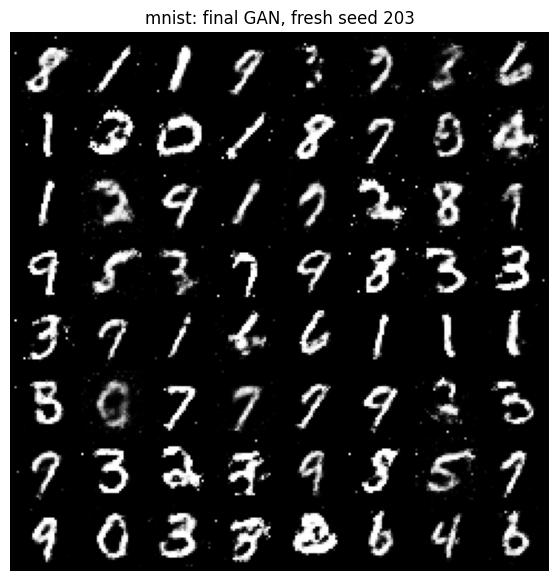

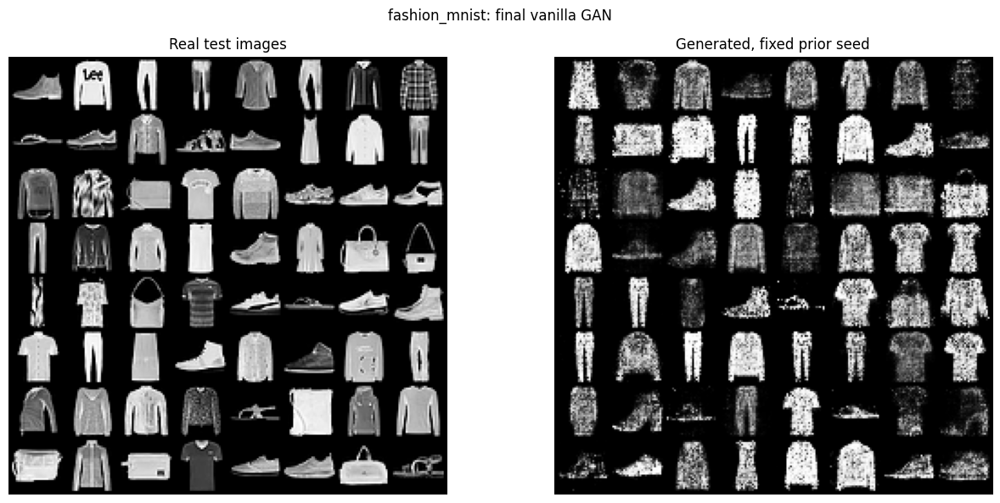

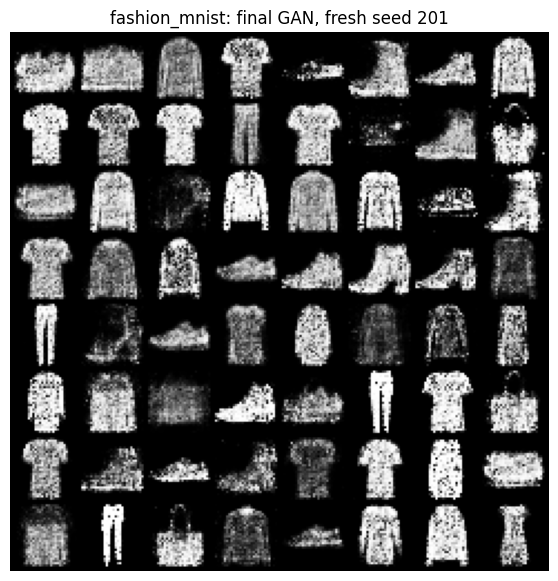

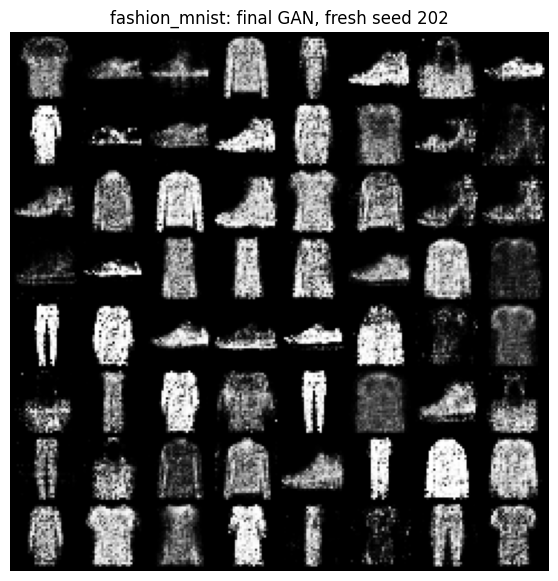

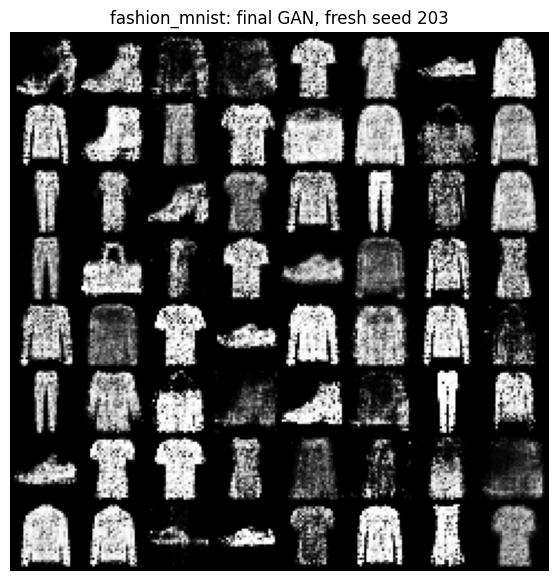

,dataset,epoch,g_loss,d_loss,d_real_probability,d_fake_probability,interpretation,smoke_test
0,mnist,40,1.258955,0.606419,0.468128,0.305277,"discriminator diagnostics, not perceptual metrics",False
1,fashion_mnist,40,0.672401,0.677816,0.593565,0.527197,"discriminator diagnostics, not perceptual metrics",False


In [7]:
gan_test_rows=[]
for run in gan_runs:
    dataset=run['dataset']
    generator=Generator(NOISE_DIM).to(DEVICE)
    discriminator=Discriminator().to(DEVICE)
    saved=torch.load(run['checkpoint'],map_location=DEVICE,weights_only=True)
    generator.load_state_dict(saved['generator'])
    discriminator.load_state_dict(saved['discriminator'])
    test=testing_loader(dataset)
    values=evaluate_gan(generator,discriminator,test,seed=3030)
    gan_test_rows.append(dict(dataset=dataset,epoch=saved['epoch'],**values,
                              interpretation='discriminator diagnostics, not perceptual metrics',smoke_test=SMOKE_TEST))
    real=next(iter(test))[0][:64]
    fake=generate_images(generator,seed=123)
    fig,axes=plt.subplots(1,2,figsize=(13,6))
    for ax,images,title in zip(axes,[real,fake],['Real test images','Generated, fixed prior seed']):
        ax.imshow(image_grid(images),cmap='gray',vmin=0,vmax=1)
        ax.set_title(title)
        ax.axis('off')
    fig.suptitle(('SMOKE TEST | ' if SMOKE_TEST else '')+dataset+': final vanilla GAN')
    fig.tight_layout()
    fig.savefig(RESULTS/f'{dataset}_real_vs_generated.png',dpi=130,bbox_inches='tight')
    plt.show()
    plt.close(fig)
    for seed in (201,202,203):
        show_grid(generate_images(generator,seed=seed),f'{dataset}: final GAN, fresh seed {seed}',
                  RESULTS/f'{dataset}_final_seed_{seed}.png')
gan_test_results=pd.DataFrame(gan_test_rows)
gan_test_results.to_csv(RESULTS/'test_discriminator_diagnostics.csv',index=False)
display(gan_test_results)


## Part 2: Conditional and Advanced GAN Variants

Five variants were trained on both datasets: an unconditional control, cGAN, cGAN+PatchGAN, cGAN+feature matching, and the combined variant.

They shared generator dimensions, a convolutional discriminator backbone, seed, split, initialization, optimizer and a 40-epoch budget. This matched control separates class conditioning from the backbone change. The all-MLP Vanilla GAN remains an additional baseline.


In [9]:
CG_EPOCHS = 40
CG_NOISE_DIM = 100
CG_CLASSES = 10
CG_LR = 2e-4
CG_FM_WEIGHT = 10.
CG_SAMPLES_PER_CLASS = 4 if SMOKE_TEST else 8
CG_CONFIGS = [
    dict(name='unconditional_control',conditional=False,patch=False,fm_weight=0.),
    dict(name='cgan',conditional=True,patch=False,fm_weight=0.),
    dict(name='cgan_patch',conditional=True,patch=True,fm_weight=0.),
    dict(name='cgan_feature_matching',conditional=True,patch=False,fm_weight=CG_FM_WEIGHT),
    dict(name='cgan_patch_feature_matching',conditional=True,patch=True,fm_weight=CG_FM_WEIGHT)]
CG_RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
CG_RESULTS = HW/'results'/'conditional_gan'/('smoke' if SMOKE_TEST else 'full')/CG_RUN_ID
CG_CHECKPOINTS = ROOT/'.local'/'hw1'/'conditional_gan'/'checkpoints'/CG_RUN_ID
CG_RESULTS.mkdir(parents=True,exist_ok=True)
CG_CHECKPOINTS.mkdir(parents=True,exist_ok=True)
(CG_RESULTS/'environment.json').write_text(json.dumps(environment,indent=2))
print('Conditional GAN results:',CG_RESULTS)


Conditional GAN results: c:\Users\Admin\Desktop\GEN_AI_CV\HW1\results\conditional_gan\full\20261112T210414243555Z


### 2.1 Class conditioning and PatchGAN

The generator concatenated 100-dimensional Gaussian noise with a ten-dimensional one-hot class vector, then used MLP widths 256→512→1024→784 and tanh. The unconditional control received zeros instead of labels.

The discriminator received the image and ten broadcast label channels. Its shared architecture was:

| Layer | Output | Receptive field |
|---|---|---:|
| Conv 11→32, kernel 3/stride 1/padding 1; LeakyReLU | 32×28×28 | 3×3 |
| Conv 32→64, kernel 4/stride 2/padding 1; LeakyReLU | 64×14×14 | 6×6 |
| Conv 64→128, kernel 3/stride 1/padding 1; LeakyReLU | 128×14×14 | 10×10 |
| Conv 128→1, kernel 3/stride 1/padding 1 | 1×14×14 | 14×14 |

Global scoring applied BCE after averaging the logit map. PatchGAN applied BCE to each patch logit before averaging, using the same parameter count. This small-image version is inspired by PatchGAN rather than a reproduction of the 70×70 pix2pix model. Local scoring may miss global shape errors.

Both networks received the same labels. Fake training images used real-batch labels to match class frequencies. Test images and labels were excluded from optimization. Requested class rows do not guarantee correct generated classes.


In [10]:
class ConditionalGenerator(nn.Module):
    def __init__(self,conditional=True):
        super().__init__()
        self.conditional=conditional
        self.net=nn.Sequential(nn.Linear(CG_NOISE_DIM+CG_CLASSES,256),nn.LeakyReLU(0.2),
                               nn.Linear(256,512),nn.LeakyReLU(0.2),
                               nn.Linear(512,1024),nn.LeakyReLU(0.2),nn.Linear(1024,784),nn.Tanh())
    def forward(self,z,labels):
        if self.conditional:
            condition=F.one_hot(labels,num_classes=CG_CLASSES).to(z.dtype)
        else:
            condition=z.new_zeros(len(z),CG_CLASSES)
        return self.net(torch.cat([z,condition],dim=1)).reshape(-1,1,28,28)

class ConditionalDiscriminator(nn.Module):
    def __init__(self,conditional=True,patch=False):
        super().__init__()
        self.conditional=conditional
        self.patch=patch
        self.features=nn.Sequential(nn.Conv2d(11,32,3,padding=1),nn.LeakyReLU(0.2),
                                    nn.Conv2d(32,64,4,stride=2,padding=1),nn.LeakyReLU(0.2),
                                    nn.Conv2d(64,128,3,padding=1),nn.LeakyReLU(0.2))
        self.head=nn.Conv2d(128,1,3,padding=1)
    def forward(self,x,labels):
        if self.conditional:
            condition=F.one_hot(labels,num_classes=CG_CLASSES).to(x.dtype)
        else:
            condition=x.new_zeros(len(x),CG_CLASSES)
        maps=condition[:,:,None,None].expand(-1,-1,x.shape[2],x.shape[3])
        features=self.features(torch.cat([x,maps],dim=1))
        logits=self.head(features)
        if not self.patch: logits=logits.flatten(1).mean(1)
        return logits,features.mean(dim=(2,3))

def class_feature_matching(fake_features,real_features,labels):
    # Match each present class separately, rather than allowing class means to cancel.
    losses=[]
    for label in labels.unique():
        mask=labels==label
        fake_mean=fake_features[mask].mean(0)
        real_mean=real_features[mask].detach().mean(0)
        losses.append((fake_mean-real_mean).square().mean())
    return torch.stack(losses).mean()

def conditional_step(real,labels,generator,discriminator,opt_g,opt_d,fm_weight):
    opt_g.zero_grad(set_to_none=True)
    opt_d.zero_grad(set_to_none=True)
    with torch.no_grad():
        fake=generator(torch.randn(len(real),CG_NOISE_DIM,device=real.device),labels)
    real_logits,_=discriminator(real,labels)
    fake_logits,_=discriminator(fake,labels)
    d_loss=0.5*(F.binary_cross_entropy_with_logits(real_logits,torch.ones_like(real_logits))+
                F.binary_cross_entropy_with_logits(fake_logits,torch.zeros_like(fake_logits)))
    if not torch.isfinite(d_loss): raise FloatingPointError('Non-finite conditional D loss')
    d_loss.backward()
    opt_d.step()
    opt_d.zero_grad(set_to_none=True)
    for parameter in discriminator.parameters(): parameter.requires_grad_(False)
    try:
        fresh=generator(torch.randn(len(real),CG_NOISE_DIM,device=real.device),labels)
        logits,fake_features=discriminator(fresh,labels)
        adversarial=F.binary_cross_entropy_with_logits(logits,torch.ones_like(logits))
        fm=fake_features.new_zeros(())
        if fm_weight>0:
            # Real and fake features use the SAME current, frozen D after its update.
            with torch.no_grad(): _,real_features=discriminator(real,labels)
            fm=class_feature_matching(fake_features,real_features,labels)
        g_loss=adversarial+fm_weight*fm
        if not torch.isfinite(g_loss): raise FloatingPointError('Non-finite conditional G loss')
        g_loss.backward()
        opt_g.step()
    finally:
        for parameter in discriminator.parameters(): parameter.requires_grad_(True)
    return dict(g_total=g_loss.item(),g_adversarial=adversarial.item(),feature_matching=fm.item(),
                d_loss=d_loss.item(),d_real_probability=torch.sigmoid(real_logits).mean().item(),
                d_fake_probability=torch.sigmoid(fake_logits).mean().item())


### 2.2 Feature matching

Feature matching added a generator loss based on the discriminator's spatially pooled 128-channel features. Real and fake feature means were compared separately for each class present in the batch:

$$L_{\rm FM}=\frac1{|\mathcal C_B|}\sum_{c\in\mathcal C_B}\operatorname{mean}_j\left(\operatorname{mean}_{i:y_i=c}f_j(G(z_i,c),c)-\operatorname{mean}_{i:y_i=c}f_j(x_i,c)\right)^2.$$

FM variants used $L_G=L_{\rm adv}+10L_{\rm FM}$. Real features were detached, while fake-feature gradients reached G through the frozen D. Both were recomputed after the D update. D still optimized only adversarial BCE.

This loss matches class-level statistics, not individual real/fake image pairs. The comparisons isolate conditioning, patch scoring, FM and their combination. FM values depend on the learned feature scale and are not universal quality scores. All results are from one seed.


In [11]:
def check_conditional_gan():
    labels=torch.tensor([0,1,2,3])
    z=torch.randn(4,CG_NOISE_DIM)
    for conditional in (False,True):
        generator=ConditionalGenerator(conditional)
        fake=generator(z,labels)
        assert fake.shape==(4,1,28,28) and ((fake>=-1)&(fake<=1)).all()
        if not conditional:
            torch.testing.assert_close(fake,generator(z,(labels+1)%10))
        else:
            assert not torch.allclose(fake,generator(z,(labels+1)%10))
        for patch in (False,True):
            discriminator=ConditionalDiscriminator(conditional,patch)
            logits,features=discriminator(fake,labels)
            assert logits.shape==((4,1,14,14) if patch else (4,))
            assert features.shape==(4,128)
    # Per-class means must not cancel a class swap; the real branch must stay detached.
    features=torch.tensor([[0.,0.],[0.,0.],[2.,2.],[2.,2.]],requires_grad=True)
    target=torch.tensor([[2.,2.],[2.,2.],[0.,0.],[0.,0.]],requires_grad=True)
    fm=class_feature_matching(features,target,torch.tensor([0,0,1,1]))
    assert fm.item()==4.
    fm.backward()
    assert features.grad is not None and target.grad is None
    for patch in (False,True):
        generator=ConditionalGenerator(True)
        discriminator=ConditionalDiscriminator(True,patch)
        before=[p.detach().clone() for p in generator.parameters()]
        values=conditional_step(torch.rand(4,1,28,28)*2-1,labels,generator,discriminator,
                                torch.optim.Adam(generator.parameters(),lr=CG_LR),
                                torch.optim.Adam(discriminator.parameters(),lr=CG_LR),CG_FM_WEIGHT)
        assert all(math.isfinite(value) for value in values.values())
        assert any(not torch.equal(a,b) for a,b in zip(before,generator.parameters()))
        assert all(p.requires_grad and p.grad is None for p in discriminator.parameters())
    print('Passed: conditioning, global/patch shapes, class-specific FM, detached real target and G/D updates.')
check_conditional_gan()


Passed: conditioning, global/patch shapes, class-specific FM, detached real target and G/D updates.


### 2.3 Class grids and within-class diversity

Each grid has ten requested-class rows and eight independent noise vectors per row. The same latent bank and labels were shared across variants. The unconditional control ignored labels; each cell still had its own noise vector.

Fixed and fresh grids were saved during training. Pairwise pixel MSE was measured within each requested class and then averaged across classes. This can expose one-prototype-per-class collapse that a global variation measure may miss. It does not measure semantic diversity or class accuracy.


In [12]:
@torch.no_grad()
def generate_conditional(generator,seed=123,per_class=None):
    generator.eval()
    per_class=CG_SAMPLES_PER_CLASS if per_class is None else per_class
    labels=torch.arange(CG_CLASSES,device=DEVICE).repeat_interleave(per_class)
    rng=torch.Generator(device=DEVICE).manual_seed(seed)
    z=torch.randn(len(labels),CG_NOISE_DIM,device=DEVICE,generator=rng)
    return ((generator(z,labels)+1)/2).cpu()

def within_class_variation(images,per_class):
    return [torch.pdist(images[c*per_class:(c+1)*per_class].flatten(1),p=2).square().mean().item()/784
            for c in range(CG_CLASSES)]

def show_class_grid(images,title,path):
    columns=CG_SAMPLES_PER_CLASS
    fig,axes=plt.subplots(CG_CLASSES,columns,figsize=(1.25*columns,12),squeeze=False)
    for label in range(CG_CLASSES):
        for column,ax in enumerate(axes[label]):
            ax.imshow(images[label*columns+column].squeeze().detach().cpu(),cmap='gray',vmin=0,vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[label,0].set_ylabel(f'class {label}',rotation=0,labelpad=25,va='center')
    fig.suptitle(('SMOKE TEST | ' if SMOKE_TEST else '')+title)
    fig.tight_layout()
    fig.savefig(path,dpi=120,bbox_inches='tight')
    plt.show()
    plt.close(fig)

@torch.no_grad()
def evaluate_conditional(generator,discriminator,loader,fm_weight,seed=2026):
    generator.eval()
    discriminator.eval()
    rng=torch.Generator(device=DEVICE).manual_seed(seed)
    totals=dict(g_total=0.,g_adversarial=0.,feature_matching=0.,d_loss=0.,
                d_real_probability=0.,d_fake_probability=0.)
    count=0
    for gray,labels in loader:
        real=gray.to(DEVICE)*2-1
        labels=labels.to(DEVICE)
        fake=generator(torch.randn(len(real),CG_NOISE_DIM,device=DEVICE,generator=rng),labels)
        real_logits,real_features=discriminator(real,labels)
        fake_logits,fake_features=discriminator(fake,labels)
        d_loss=0.5*(F.binary_cross_entropy_with_logits(real_logits,torch.ones_like(real_logits))+
                    F.binary_cross_entropy_with_logits(fake_logits,torch.zeros_like(fake_logits)))
        adversarial=F.binary_cross_entropy_with_logits(fake_logits,torch.ones_like(fake_logits))
        fm=class_feature_matching(fake_features,real_features,labels) if fm_weight else adversarial.new_zeros(())
        values=dict(g_total=adversarial+fm_weight*fm,g_adversarial=adversarial,feature_matching=fm,
                    d_loss=d_loss,d_real_probability=torch.sigmoid(real_logits).mean(),
                    d_fake_probability=torch.sigmoid(fake_logits).mean())
        for key,value in values.items(): totals[key]+=value.item()*len(real)
        count+=len(real)
    return {key:value/count for key,value in totals.items()}


### 2.4 Matched training on both datasets

All five variants were trained from scratch for 40 epochs using the same split, scaling, batch size and Adam settings. Parameter shapes stayed the same; conditioning inputs, patch aggregation and FM weight were the experimental changes. Seeds were reset before initialization and training.

The final fixed-epoch models were reported. Saved results include losses, discriminator confidence, within-class variation and fixed/fresh grids. Validation diagnostics were not used as likelihood or visual-quality scores.


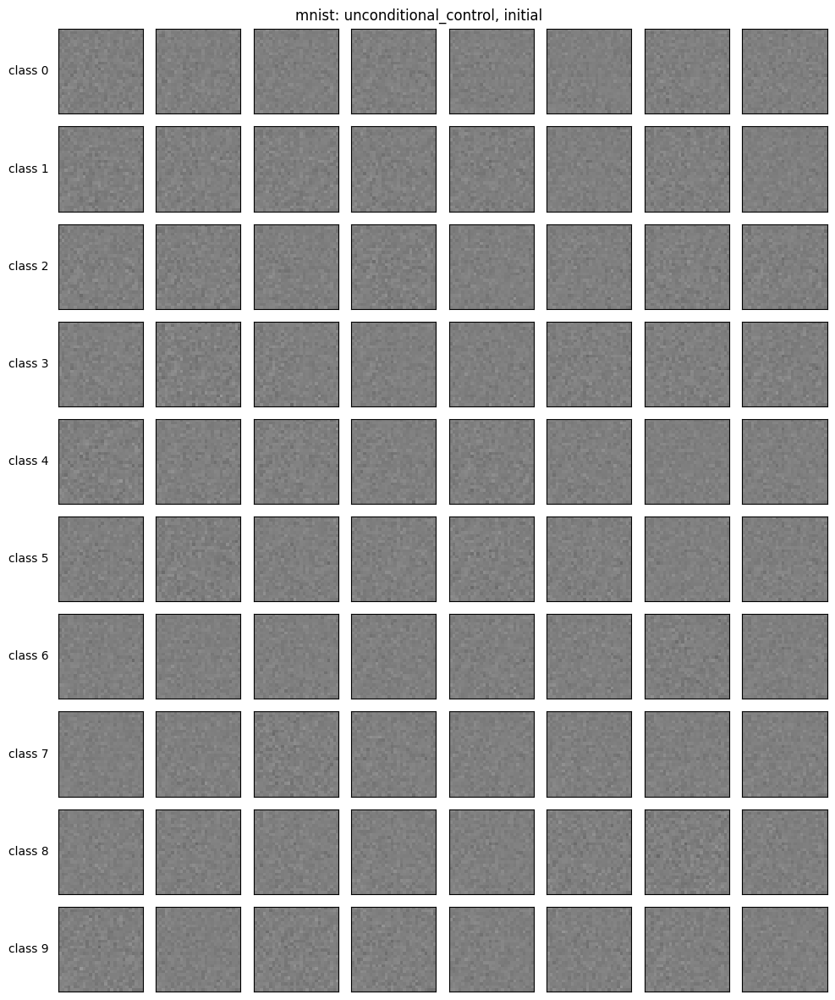

mnist unconditional_control | 1/40 | G total 1.077, adv 1.077, FM 0.00000, D 0.587


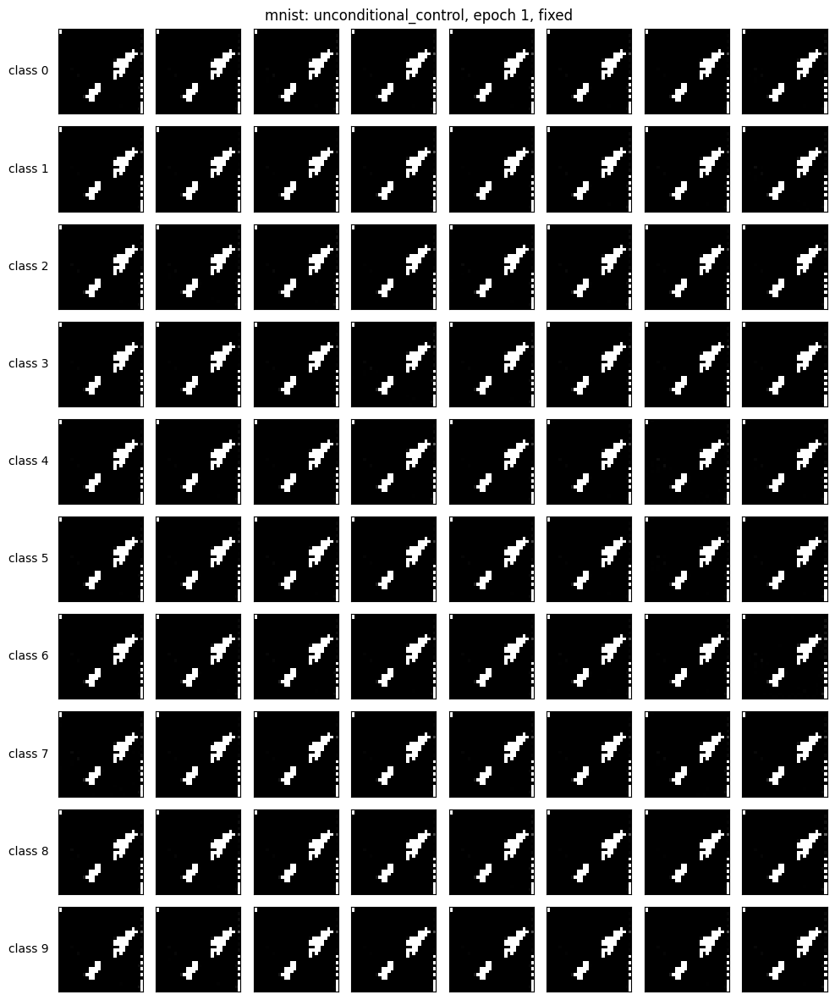

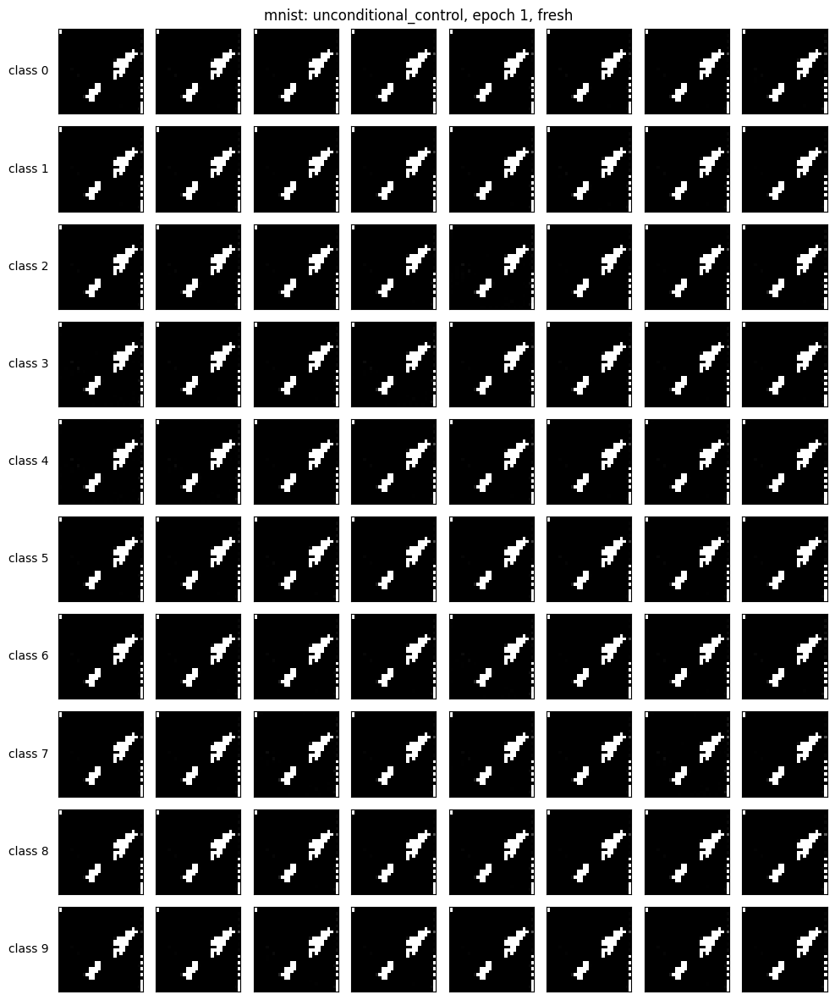

mnist unconditional_control | 2/40 | G total 1.415, adv 1.415, FM 0.00000, D 0.440
mnist unconditional_control | 3/40 | G total 0.884, adv 0.884, FM 0.00000, D 0.623
mnist unconditional_control | 4/40 | G total 0.771, adv 0.771, FM 0.00000, D 0.646
mnist unconditional_control | 5/40 | G total 0.801, adv 0.801, FM 0.00000, D 0.635


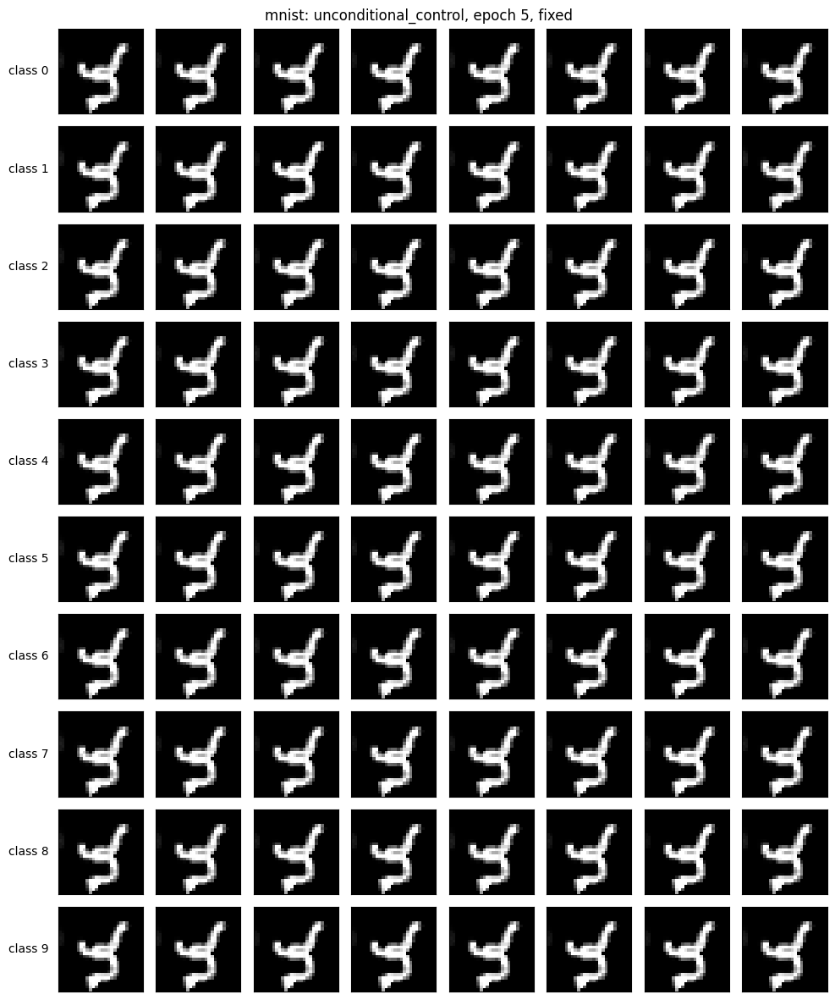

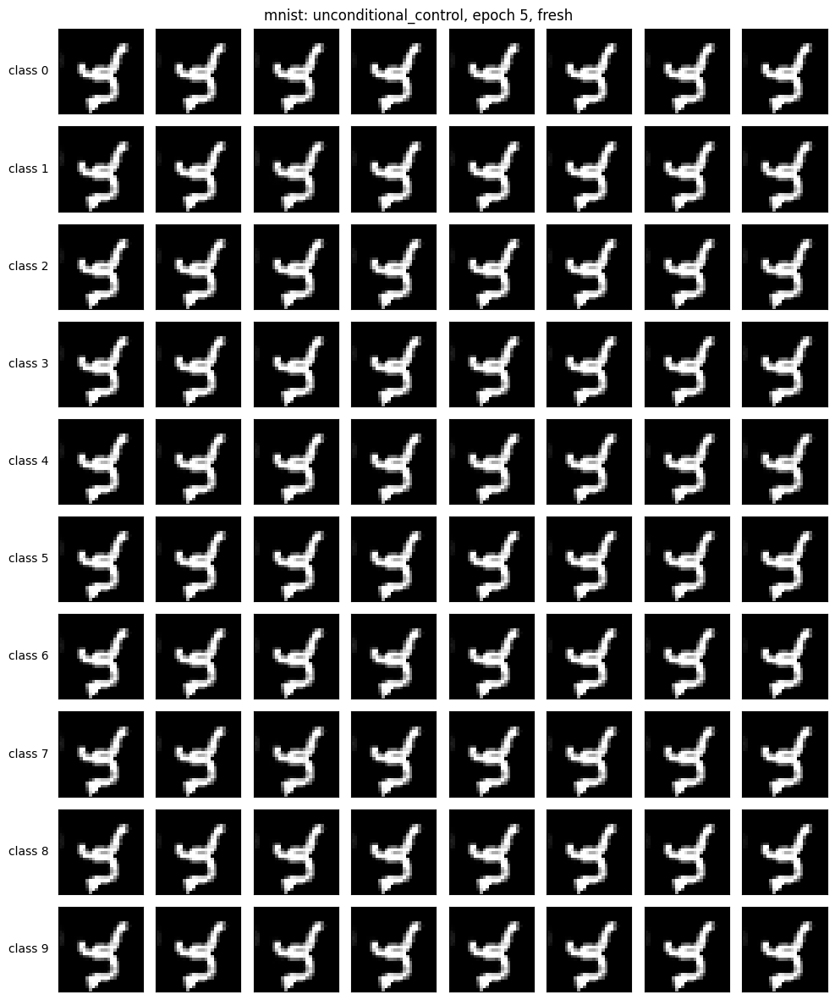

mnist unconditional_control | 6/40 | G total 0.793, adv 0.793, FM 0.00000, D 0.643
mnist unconditional_control | 7/40 | G total 0.767, adv 0.767, FM 0.00000, D 0.654
mnist unconditional_control | 8/40 | G total 0.827, adv 0.827, FM 0.00000, D 0.618
mnist unconditional_control | 9/40 | G total 0.863, adv 0.863, FM 0.00000, D 0.602
mnist unconditional_control | 10/40 | G total 0.764, adv 0.764, FM 0.00000, D 0.673


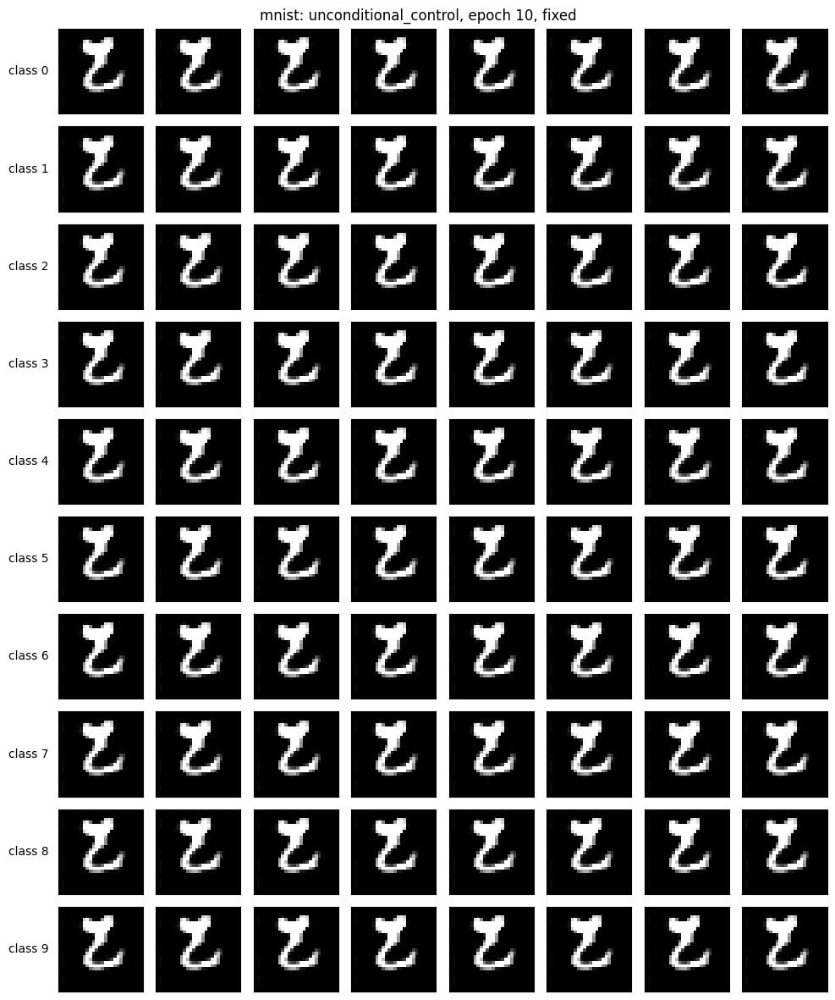

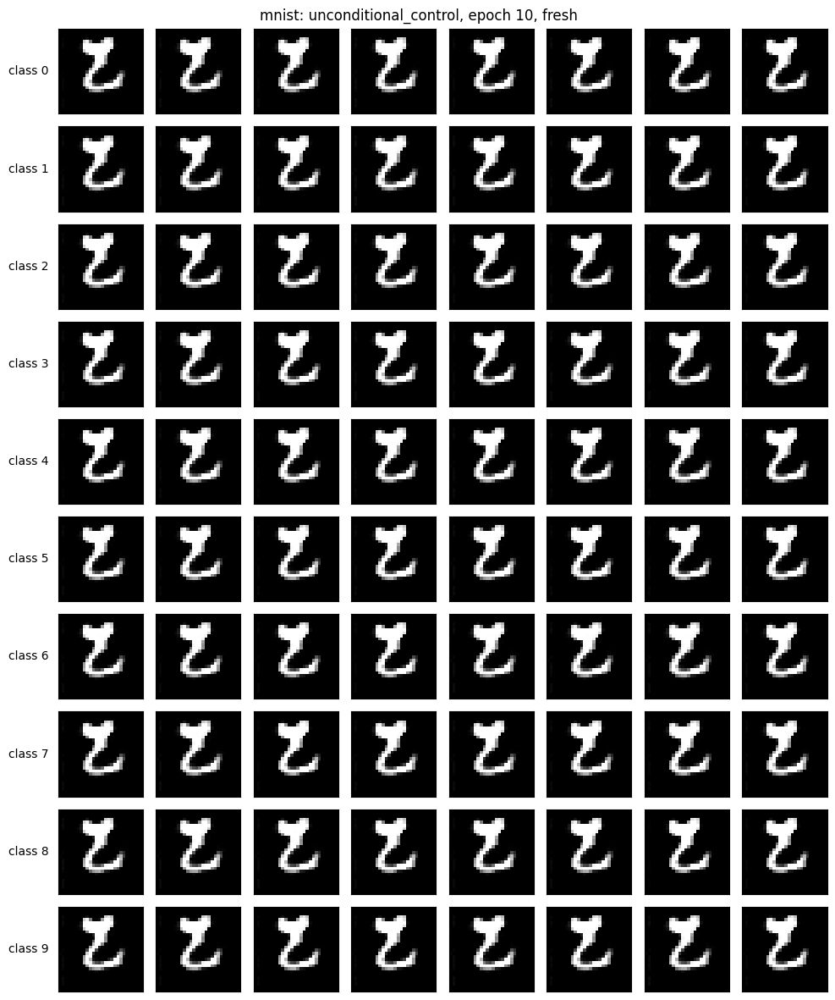

mnist unconditional_control | 11/40 | G total 0.778, adv 0.778, FM 0.00000, D 0.662
mnist unconditional_control | 12/40 | G total 0.746, adv 0.746, FM 0.00000, D 0.681
mnist unconditional_control | 13/40 | G total 0.804, adv 0.804, FM 0.00000, D 0.641
mnist unconditional_control | 14/40 | G total 0.831, adv 0.831, FM 0.00000, D 0.630
mnist unconditional_control | 15/40 | G total 0.857, adv 0.857, FM 0.00000, D 0.616


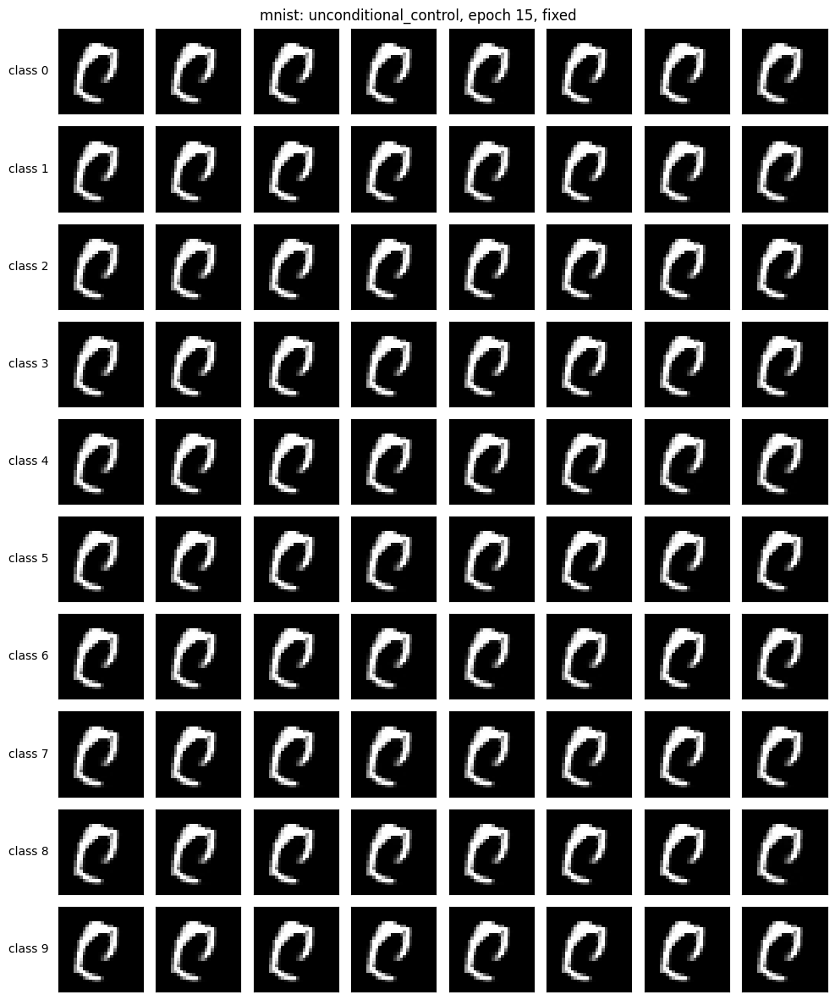

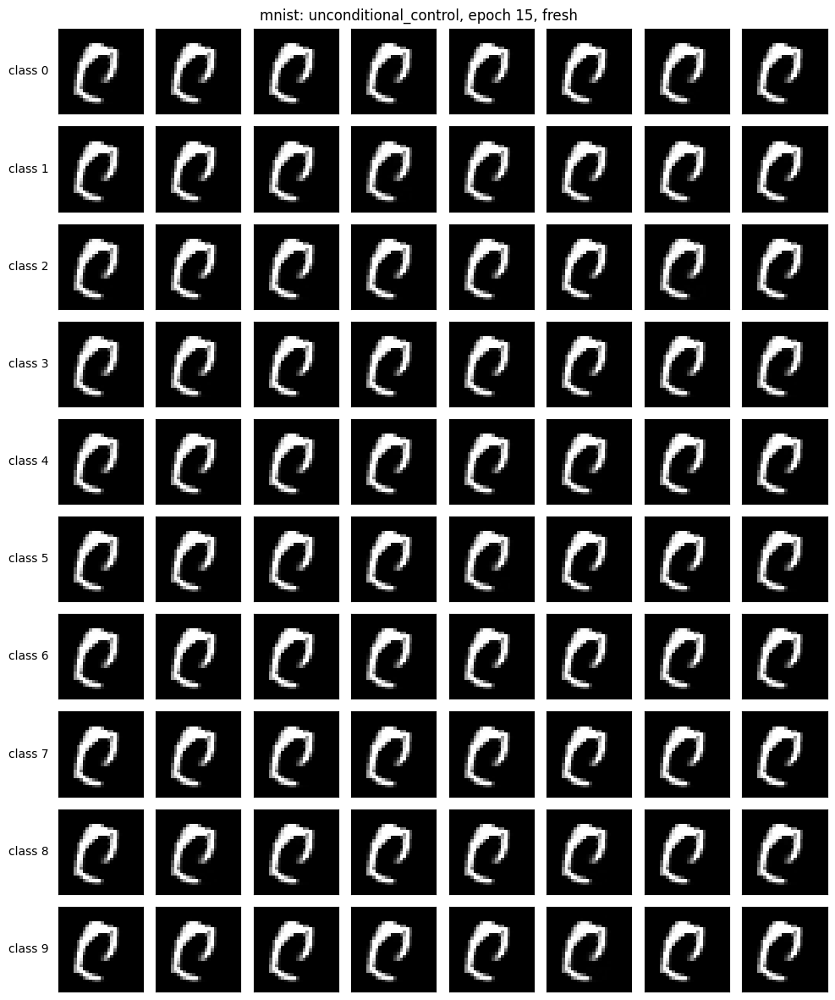

mnist unconditional_control | 16/40 | G total 0.843, adv 0.843, FM 0.00000, D 0.638
mnist unconditional_control | 17/40 | G total 0.918, adv 0.918, FM 0.00000, D 0.584
mnist unconditional_control | 18/40 | G total 0.867, adv 0.867, FM 0.00000, D 0.621
mnist unconditional_control | 19/40 | G total 0.936, adv 0.936, FM 0.00000, D 0.593
mnist unconditional_control | 20/40 | G total 0.884, adv 0.884, FM 0.00000, D 0.603


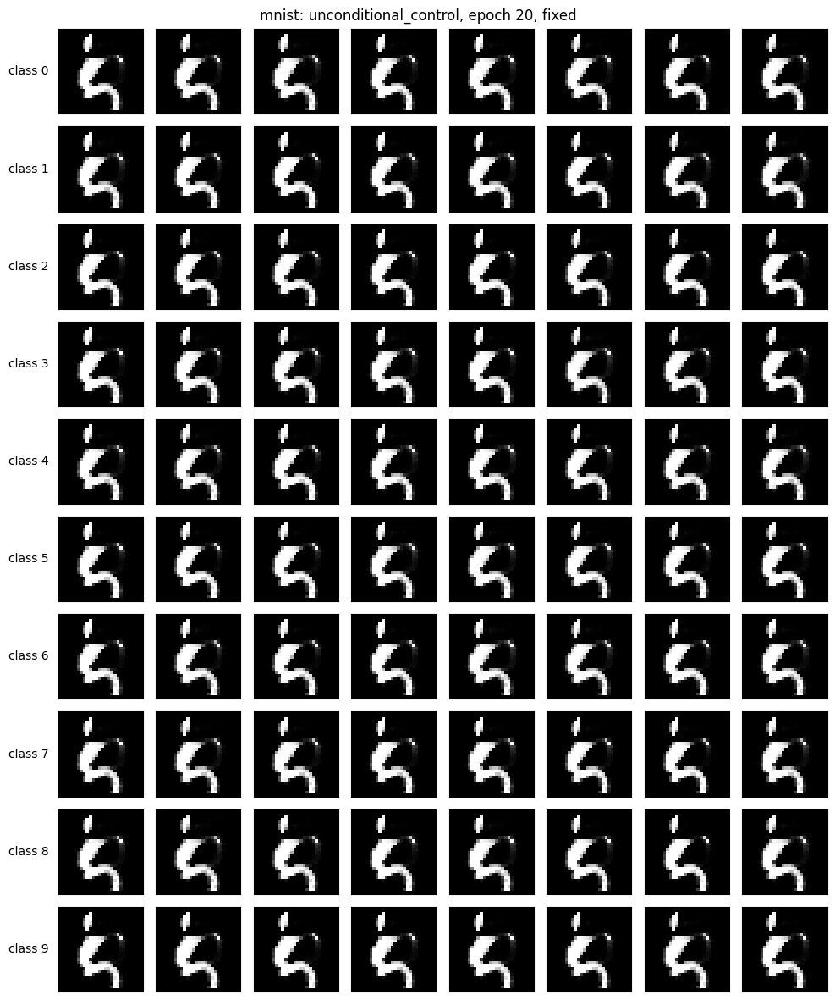

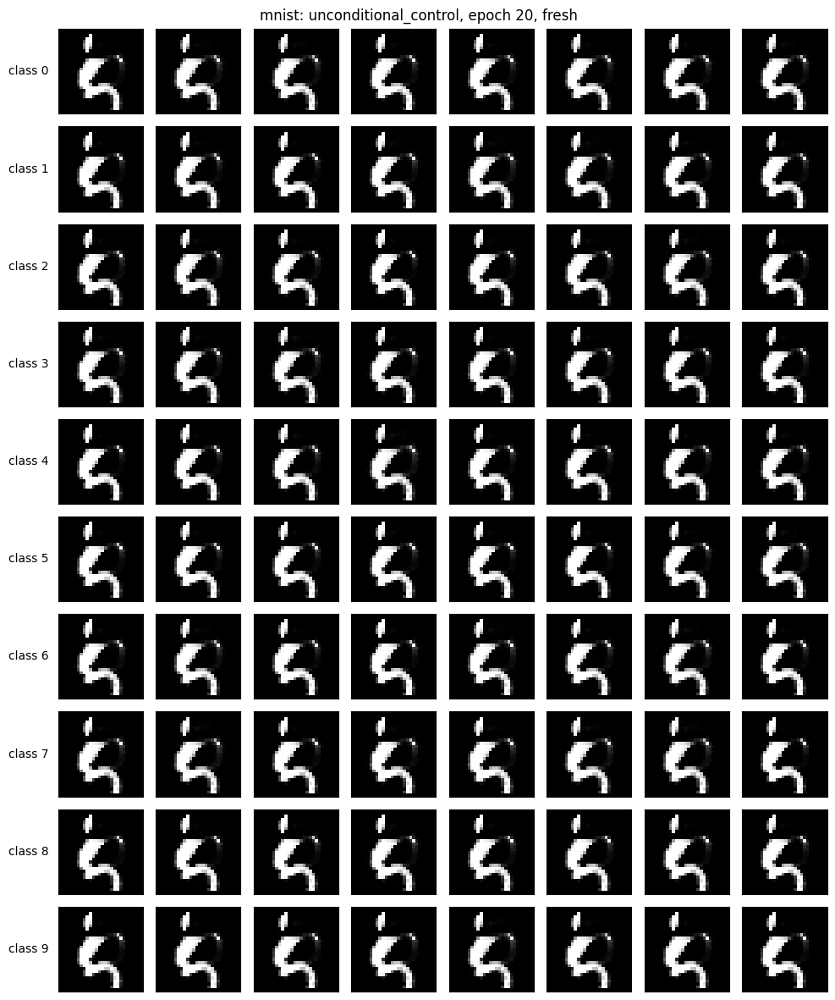

mnist unconditional_control | 21/40 | G total 1.114, adv 1.114, FM 0.00000, D 0.493
mnist unconditional_control | 22/40 | G total 0.923, adv 0.923, FM 0.00000, D 0.604
mnist unconditional_control | 23/40 | G total 1.026, adv 1.026, FM 0.00000, D 0.520
mnist unconditional_control | 24/40 | G total 0.954, adv 0.954, FM 0.00000, D 0.617
mnist unconditional_control | 25/40 | G total 1.050, adv 1.050, FM 0.00000, D 0.544


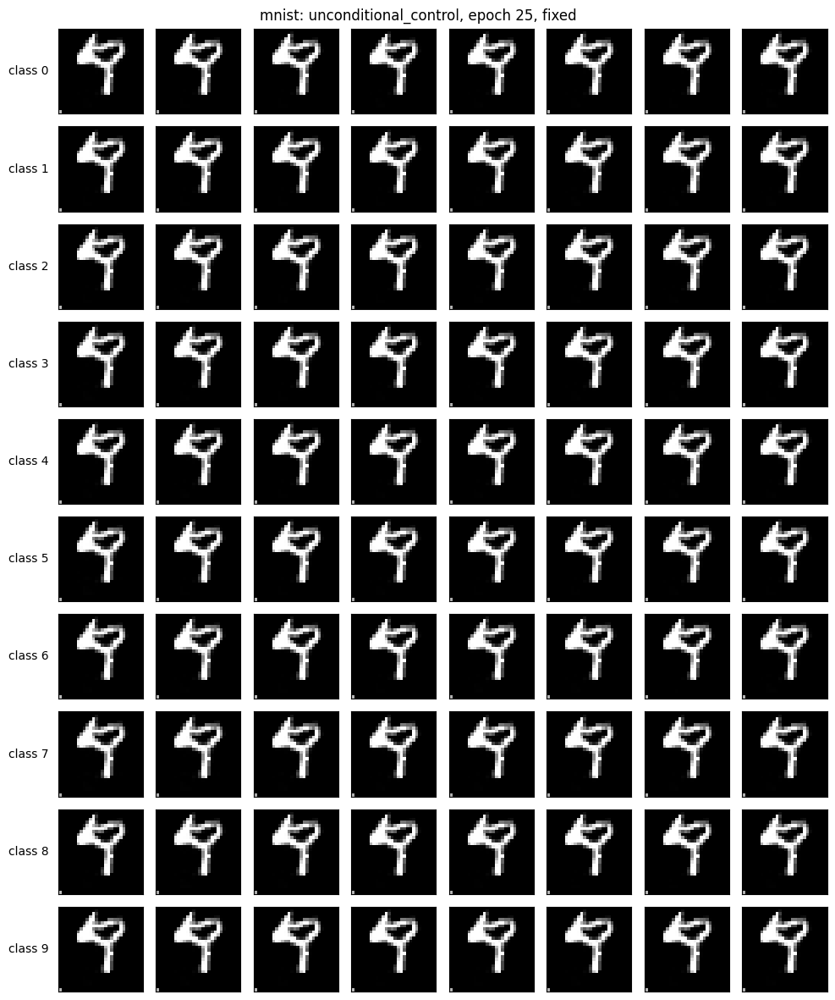

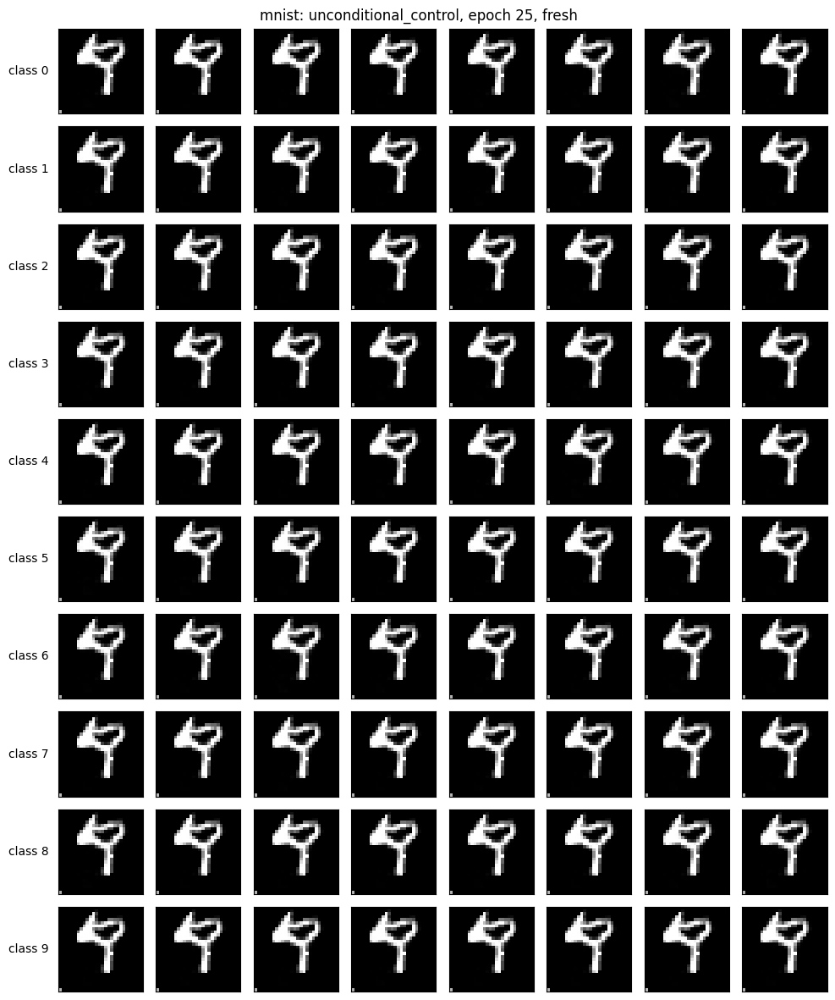

mnist unconditional_control | 26/40 | G total 1.054, adv 1.054, FM 0.00000, D 0.510
mnist unconditional_control | 27/40 | G total 0.998, adv 0.998, FM 0.00000, D 0.584
mnist unconditional_control | 28/40 | G total 1.111, adv 1.111, FM 0.00000, D 0.532
mnist unconditional_control | 29/40 | G total 0.950, adv 0.950, FM 0.00000, D 0.577
mnist unconditional_control | 30/40 | G total 1.148, adv 1.148, FM 0.00000, D 0.501


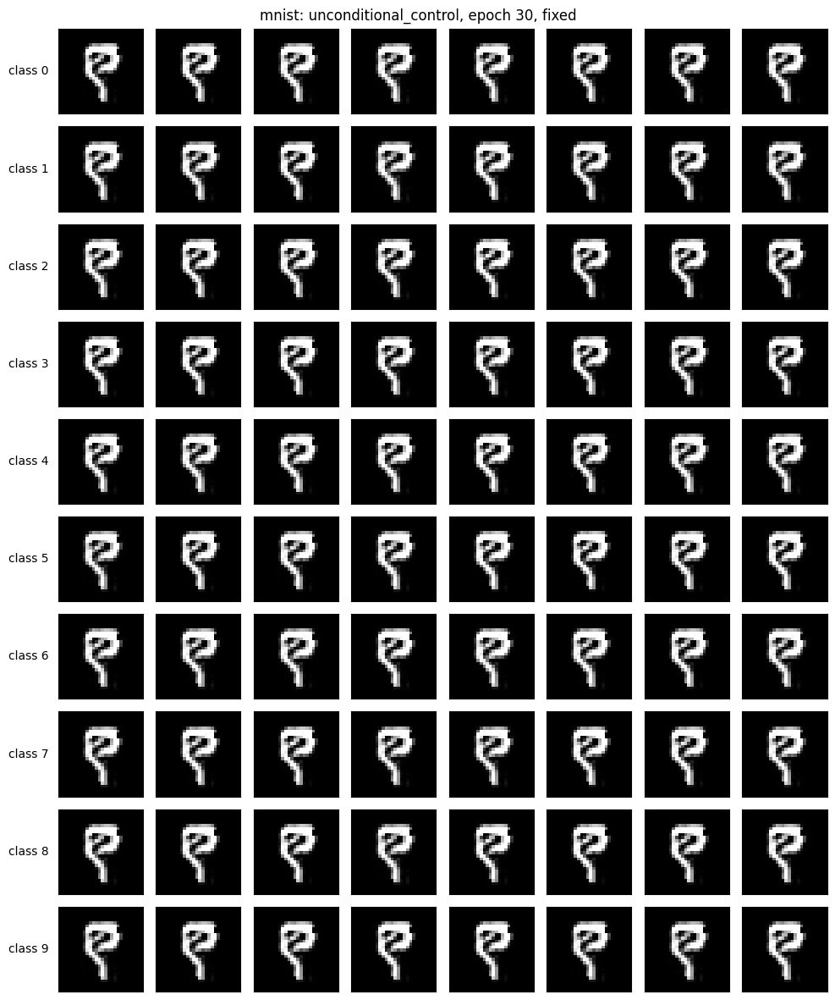

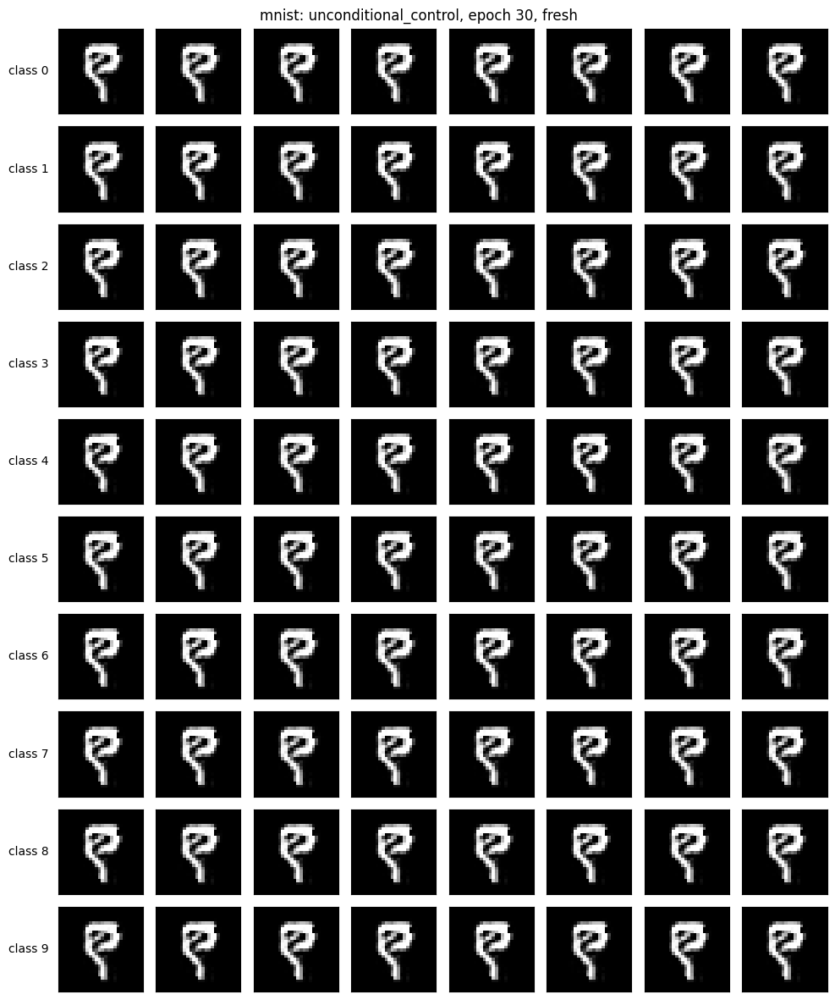

mnist unconditional_control | 31/40 | G total 0.974, adv 0.974, FM 0.00000, D 0.590
mnist unconditional_control | 32/40 | G total 1.049, adv 1.049, FM 0.00000, D 0.528
mnist unconditional_control | 33/40 | G total 1.006, adv 1.006, FM 0.00000, D 0.608
mnist unconditional_control | 34/40 | G total 1.089, adv 1.089, FM 0.00000, D 0.504
mnist unconditional_control | 35/40 | G total 0.957, adv 0.957, FM 0.00000, D 0.612


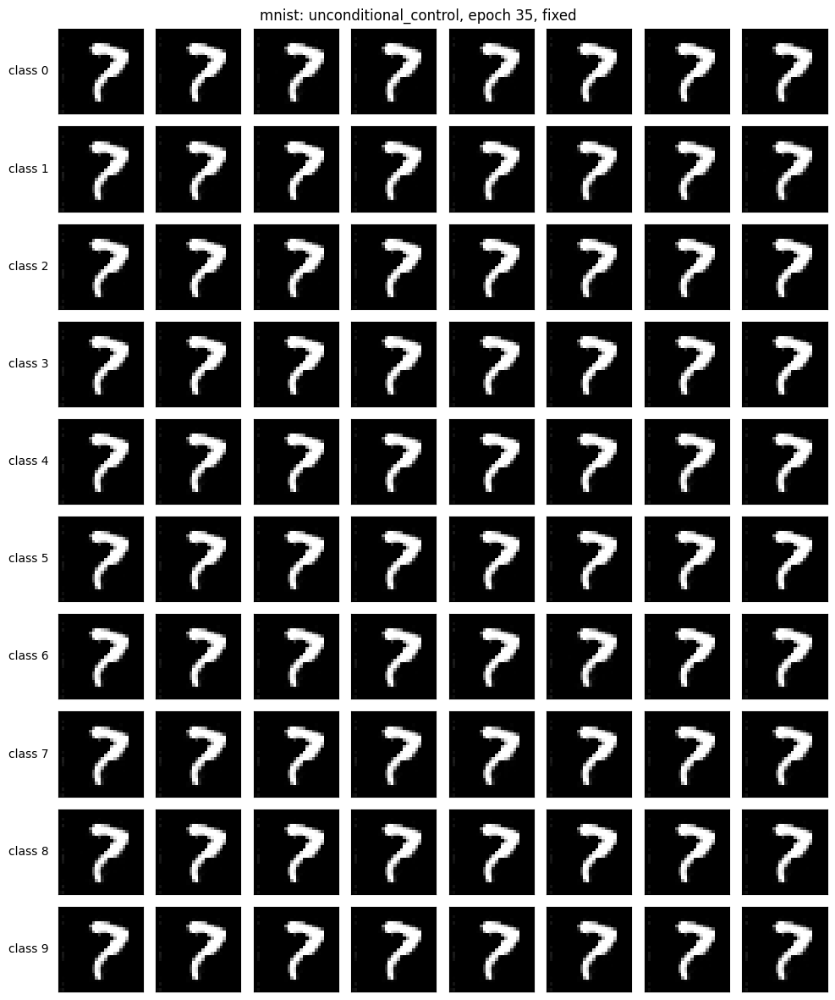

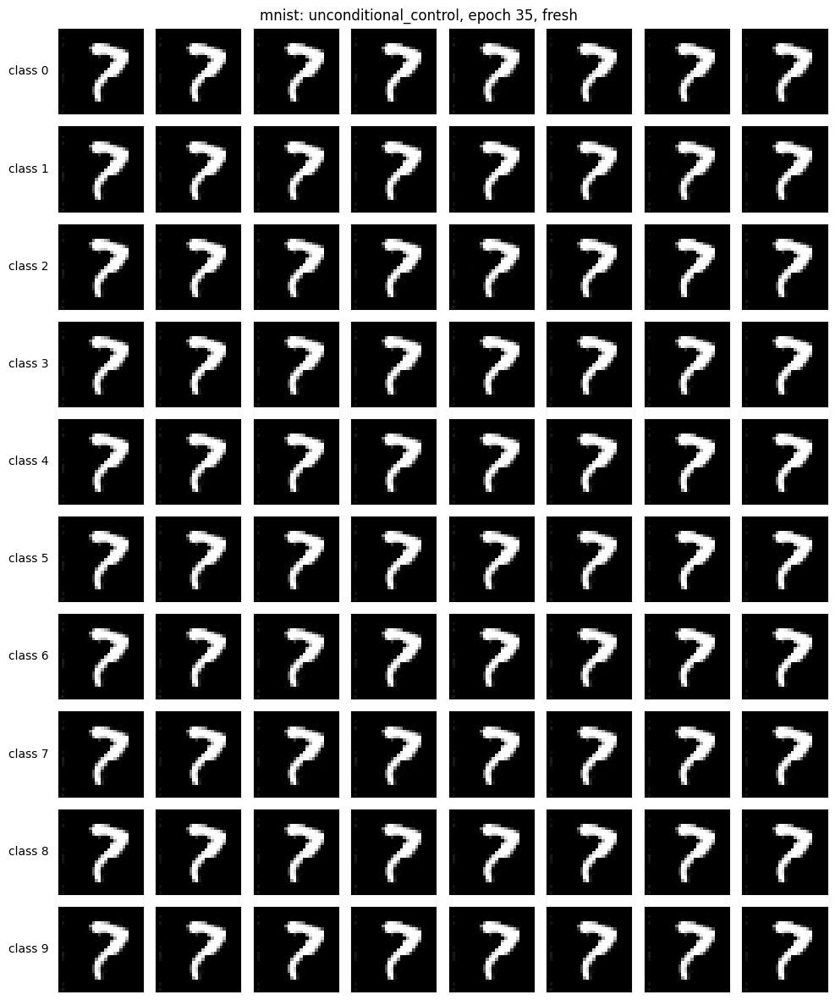

mnist unconditional_control | 36/40 | G total 1.076, adv 1.076, FM 0.00000, D 0.550
mnist unconditional_control | 37/40 | G total 1.091, adv 1.091, FM 0.00000, D 0.581
mnist unconditional_control | 38/40 | G total 1.284, adv 1.284, FM 0.00000, D 0.413
mnist unconditional_control | 39/40 | G total 1.050, adv 1.050, FM 0.00000, D 0.587
mnist unconditional_control | 40/40 | G total 1.143, adv 1.143, FM 0.00000, D 0.529


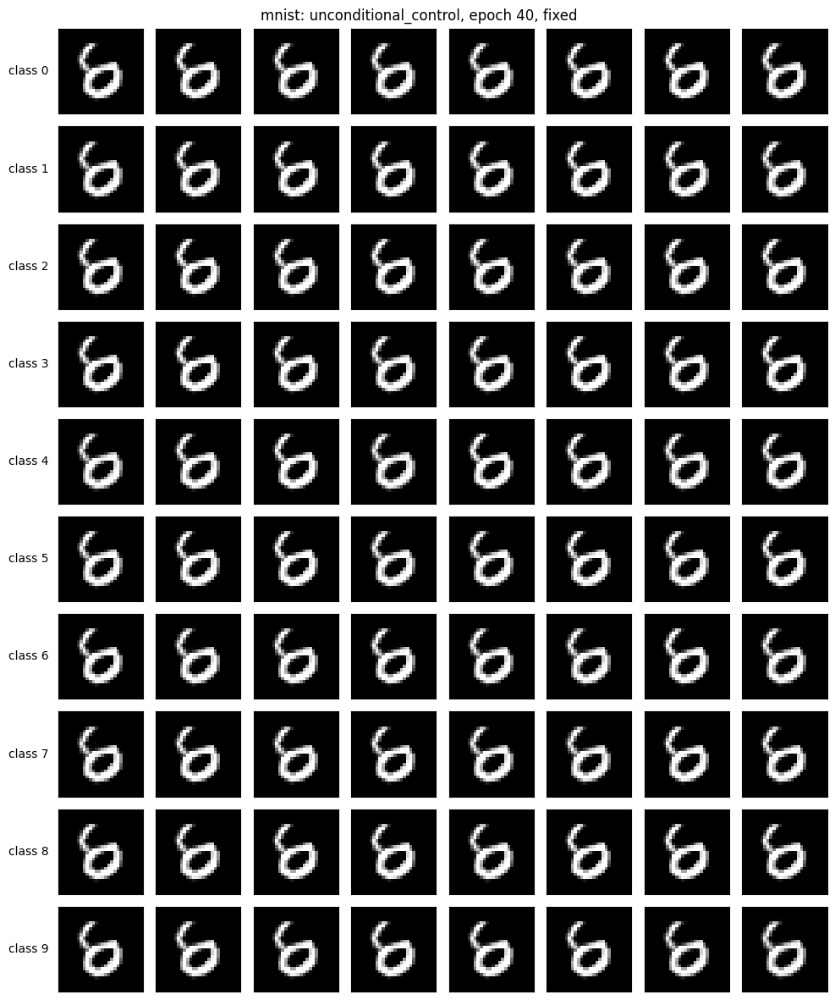

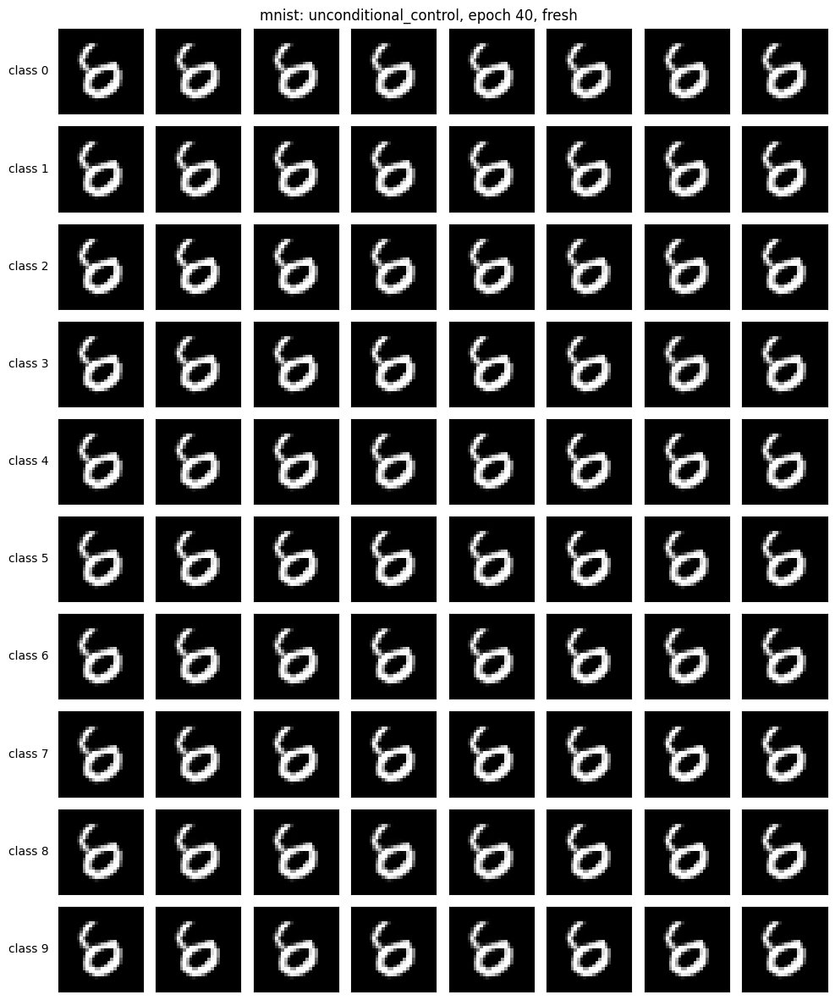

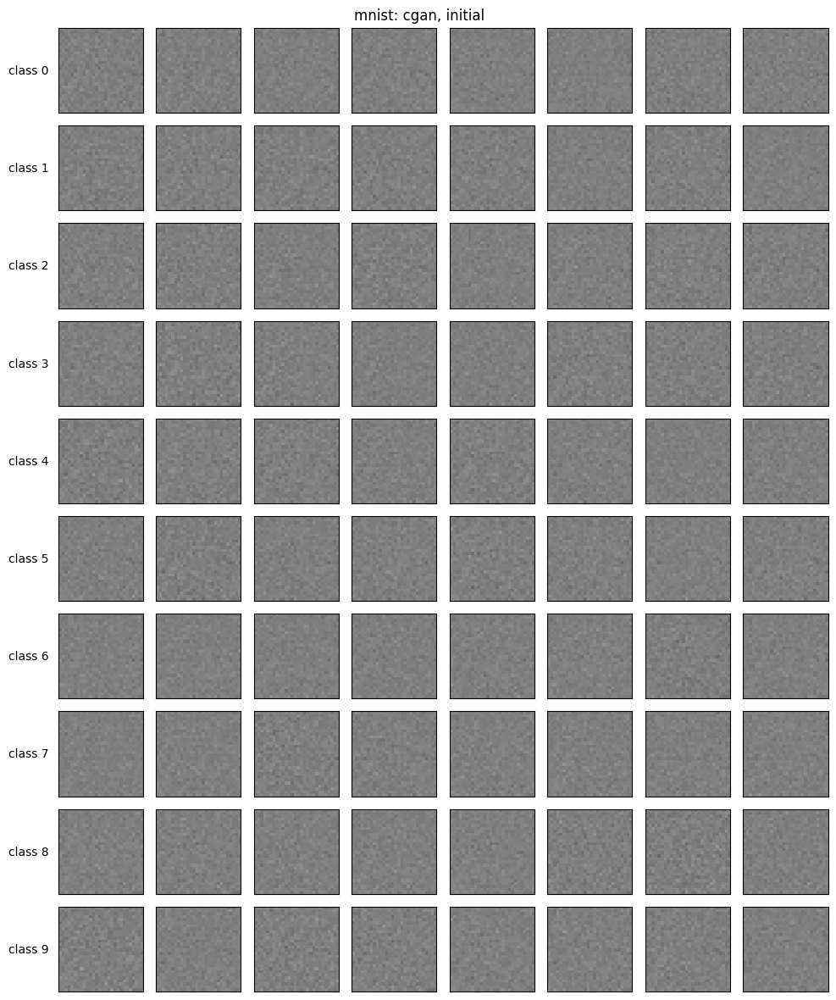

mnist cgan | 1/40 | G total 1.121, adv 1.121, FM 0.00000, D 0.594


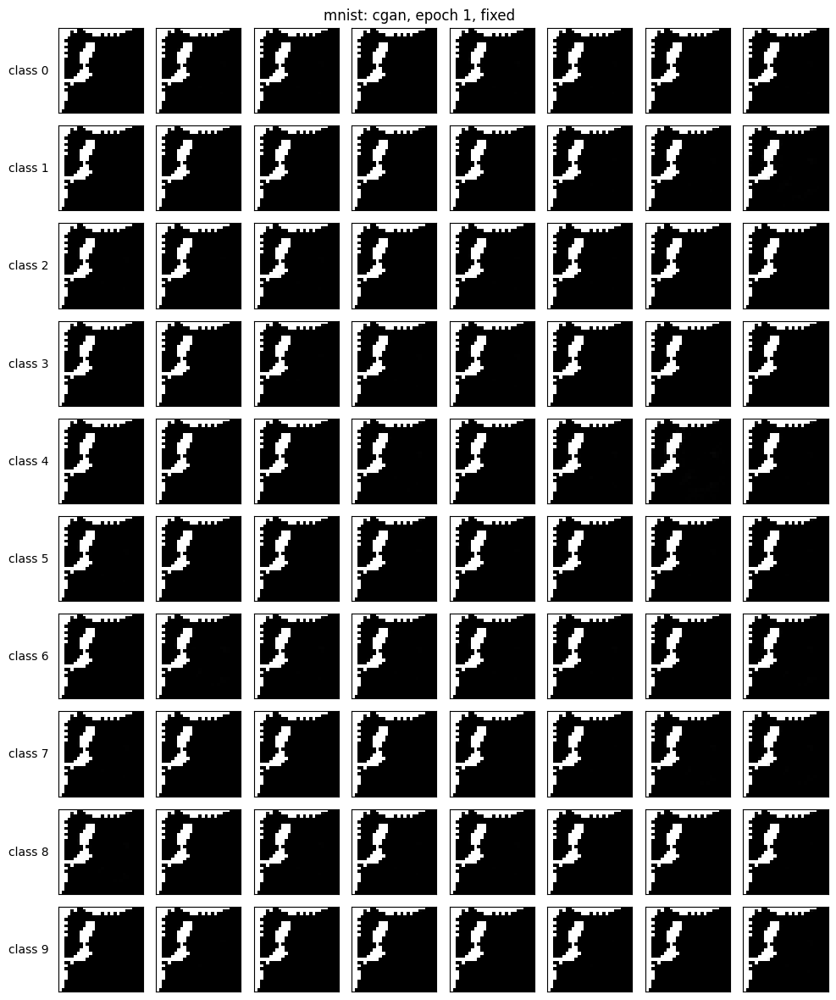

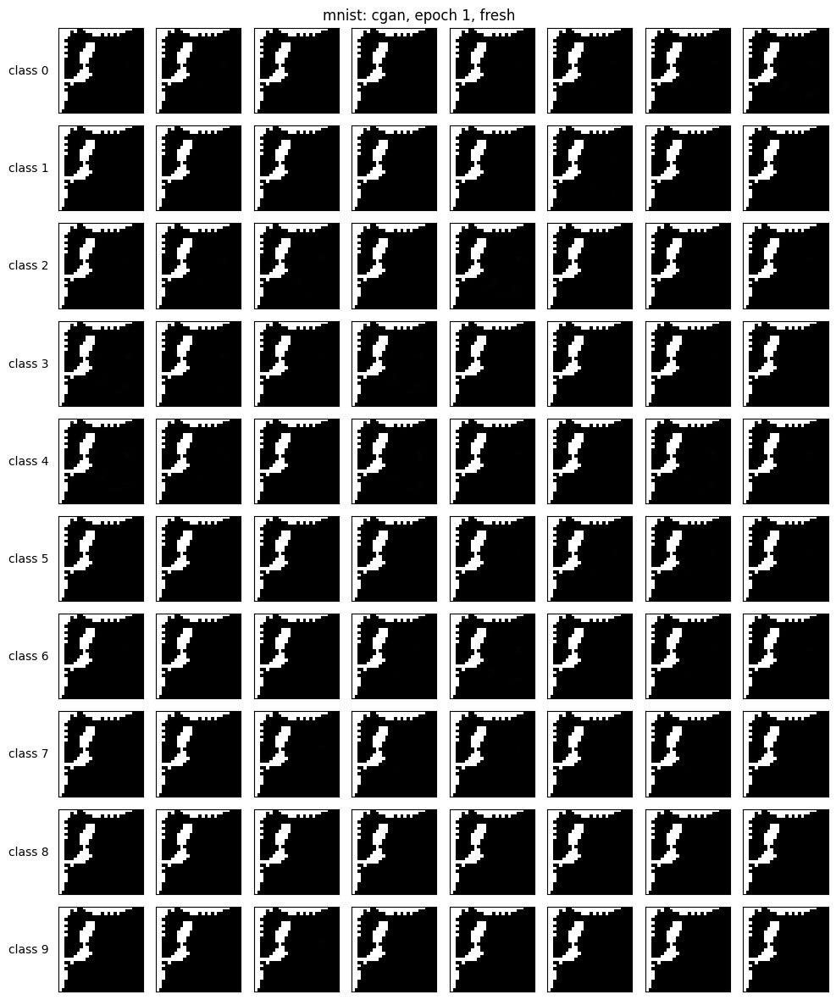

mnist cgan | 2/40 | G total 1.300, adv 1.300, FM 0.00000, D 0.441
mnist cgan | 3/40 | G total 1.450, adv 1.450, FM 0.00000, D 0.394
mnist cgan | 4/40 | G total 1.326, adv 1.326, FM 0.00000, D 0.493
mnist cgan | 5/40 | G total 0.683, adv 0.683, FM 0.00000, D 0.725


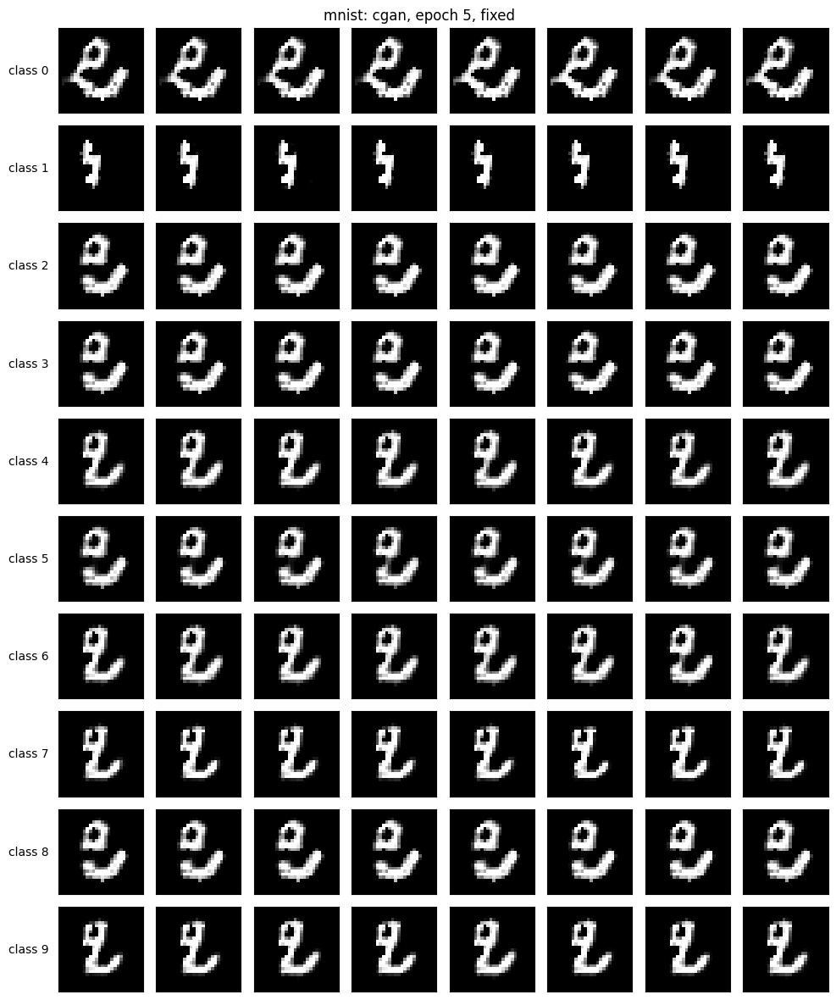

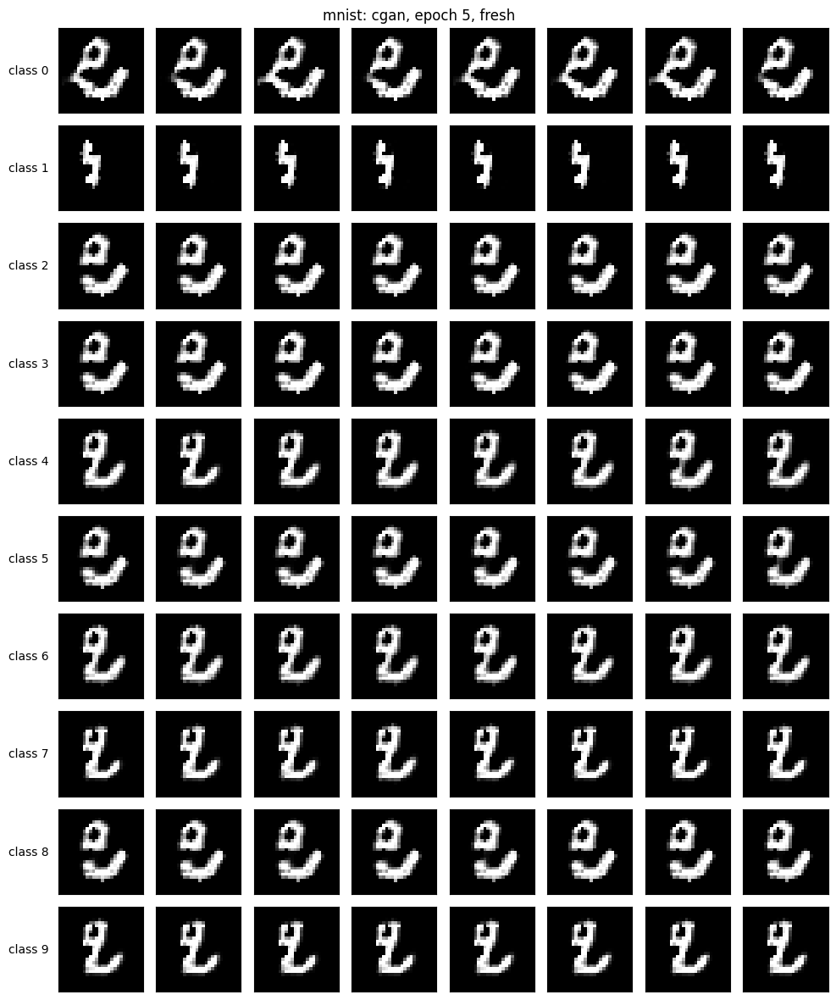

mnist cgan | 6/40 | G total 0.742, adv 0.742, FM 0.00000, D 0.669
mnist cgan | 7/40 | G total 0.775, adv 0.775, FM 0.00000, D 0.651
mnist cgan | 8/40 | G total 0.778, adv 0.778, FM 0.00000, D 0.652
mnist cgan | 9/40 | G total 0.812, adv 0.812, FM 0.00000, D 0.630
mnist cgan | 10/40 | G total 0.840, adv 0.840, FM 0.00000, D 0.625


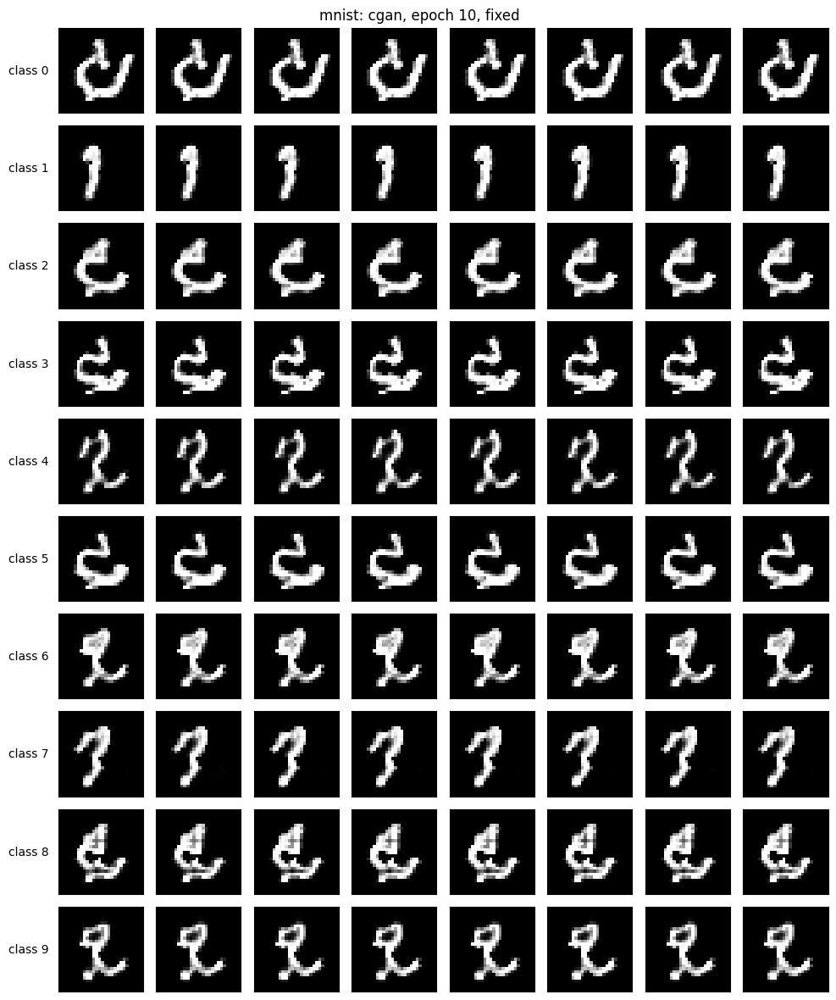

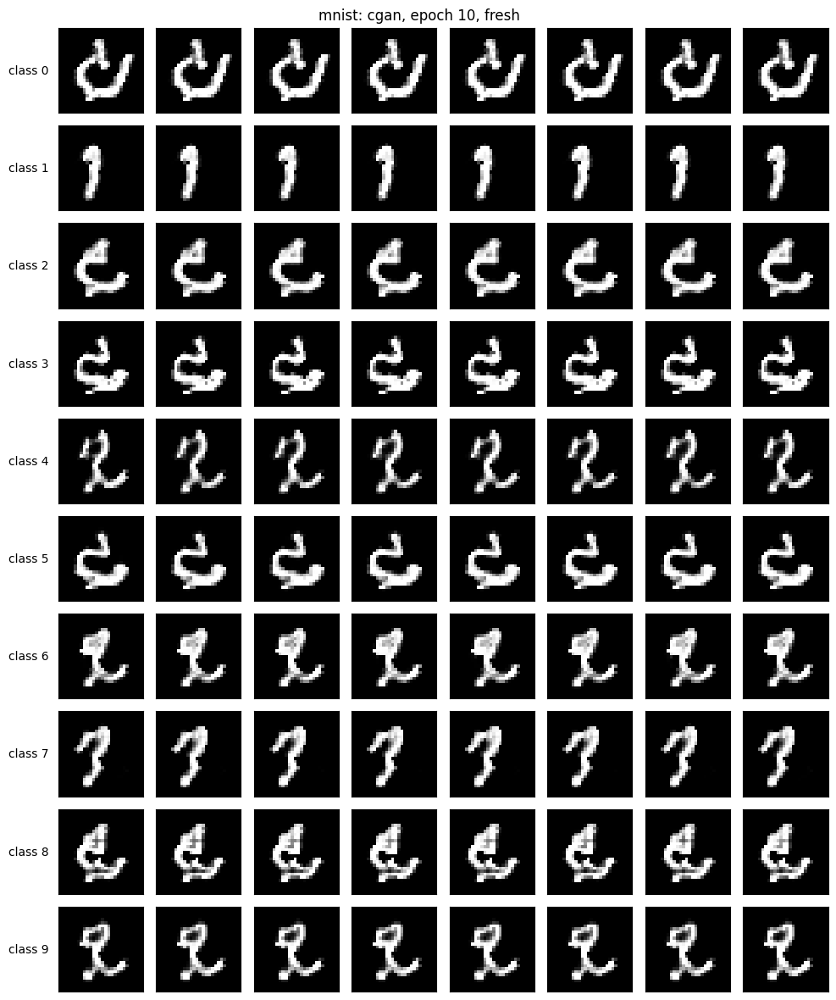

mnist cgan | 11/40 | G total 0.755, adv 0.755, FM 0.00000, D 0.660
mnist cgan | 12/40 | G total 0.762, adv 0.762, FM 0.00000, D 0.656
mnist cgan | 13/40 | G total 0.758, adv 0.758, FM 0.00000, D 0.664
mnist cgan | 14/40 | G total 0.778, adv 0.778, FM 0.00000, D 0.653
mnist cgan | 15/40 | G total 0.781, adv 0.781, FM 0.00000, D 0.652


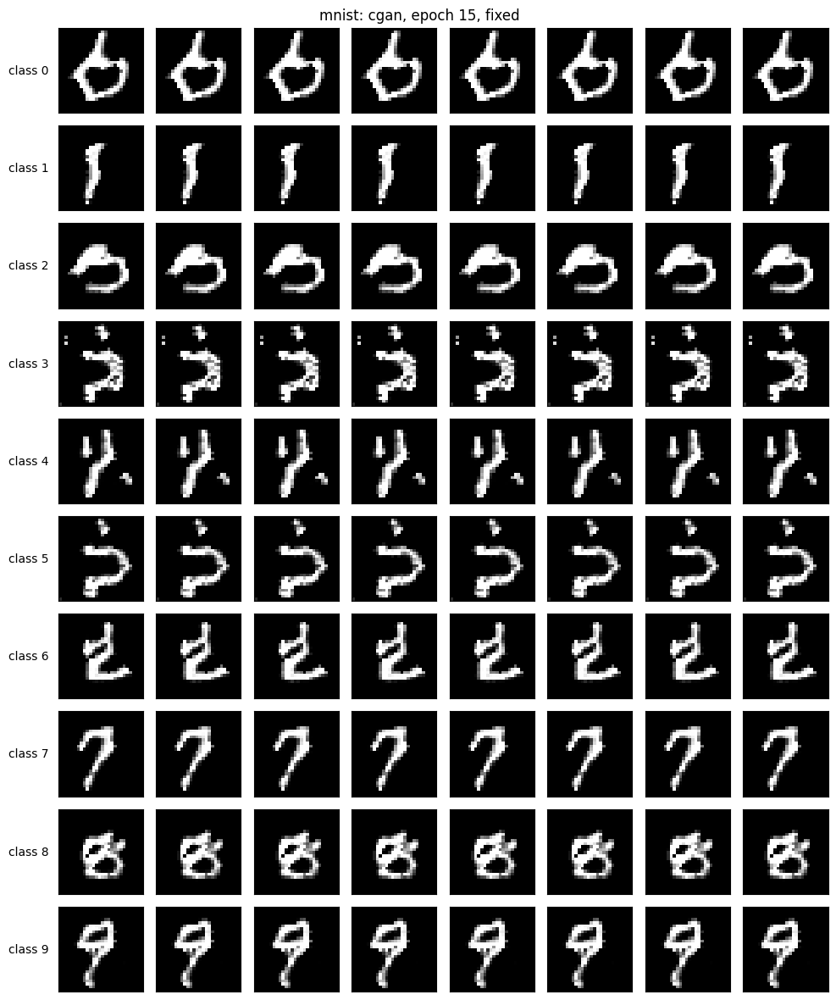

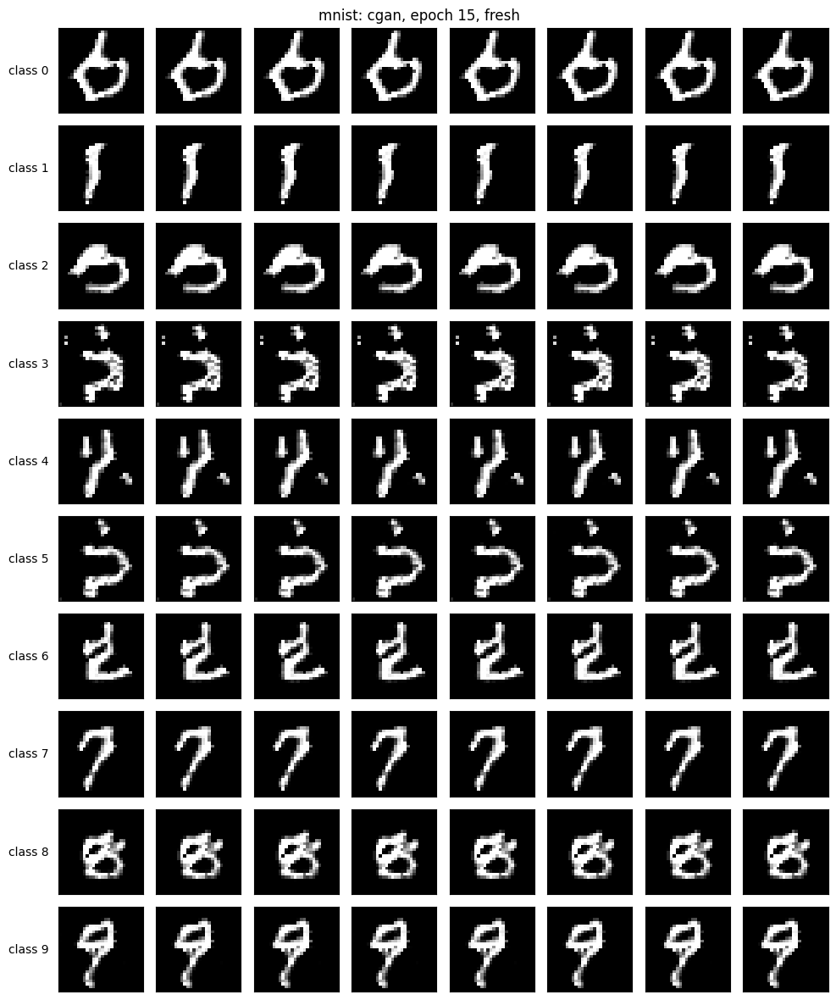

mnist cgan | 16/40 | G total 0.777, adv 0.777, FM 0.00000, D 0.652
mnist cgan | 17/40 | G total 0.783, adv 0.783, FM 0.00000, D 0.648
mnist cgan | 18/40 | G total 0.781, adv 0.781, FM 0.00000, D 0.651
mnist cgan | 19/40 | G total 0.791, adv 0.791, FM 0.00000, D 0.644
mnist cgan | 20/40 | G total 0.746, adv 0.746, FM 0.00000, D 0.680


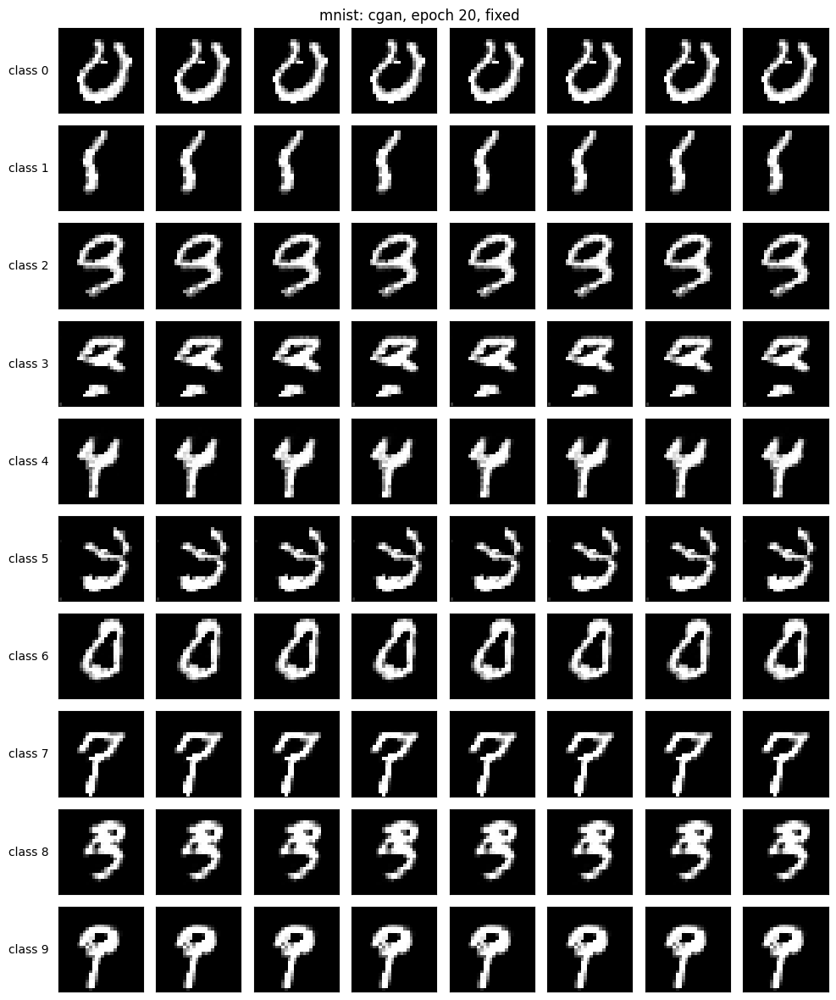

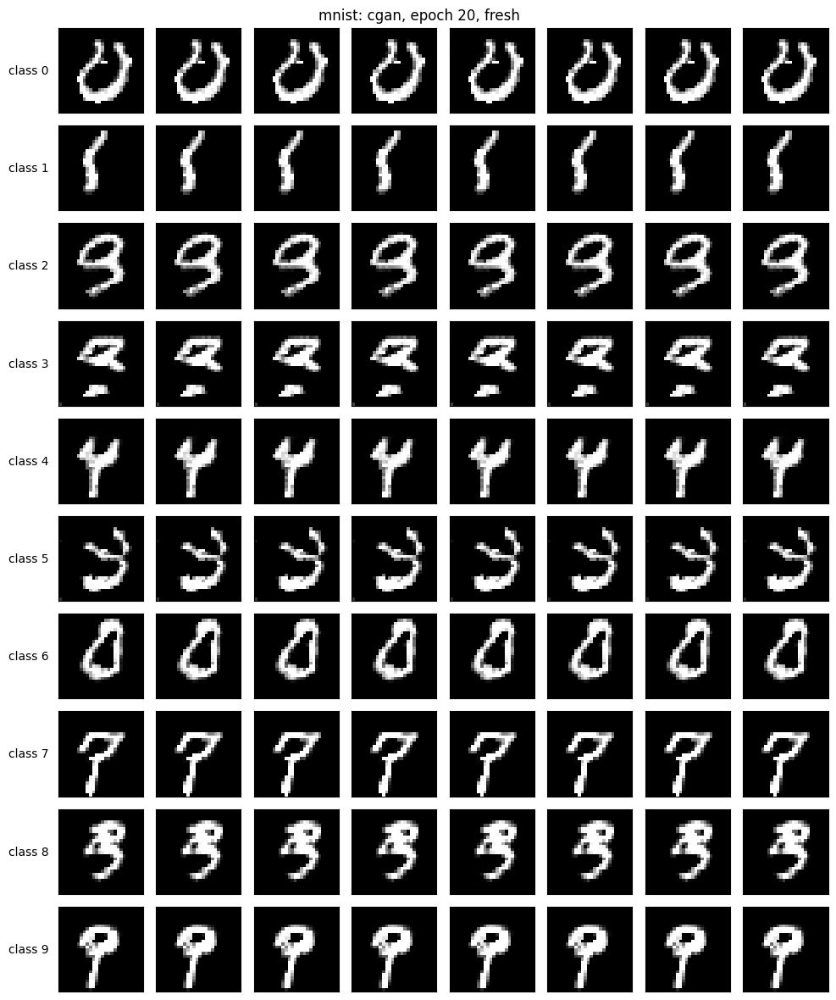

mnist cgan | 21/40 | G total 0.760, adv 0.760, FM 0.00000, D 0.662
mnist cgan | 22/40 | G total 0.779, adv 0.779, FM 0.00000, D 0.650
mnist cgan | 23/40 | G total 0.763, adv 0.763, FM 0.00000, D 0.663
mnist cgan | 24/40 | G total 0.743, adv 0.743, FM 0.00000, D 0.674
mnist cgan | 25/40 | G total 0.741, adv 0.741, FM 0.00000, D 0.675


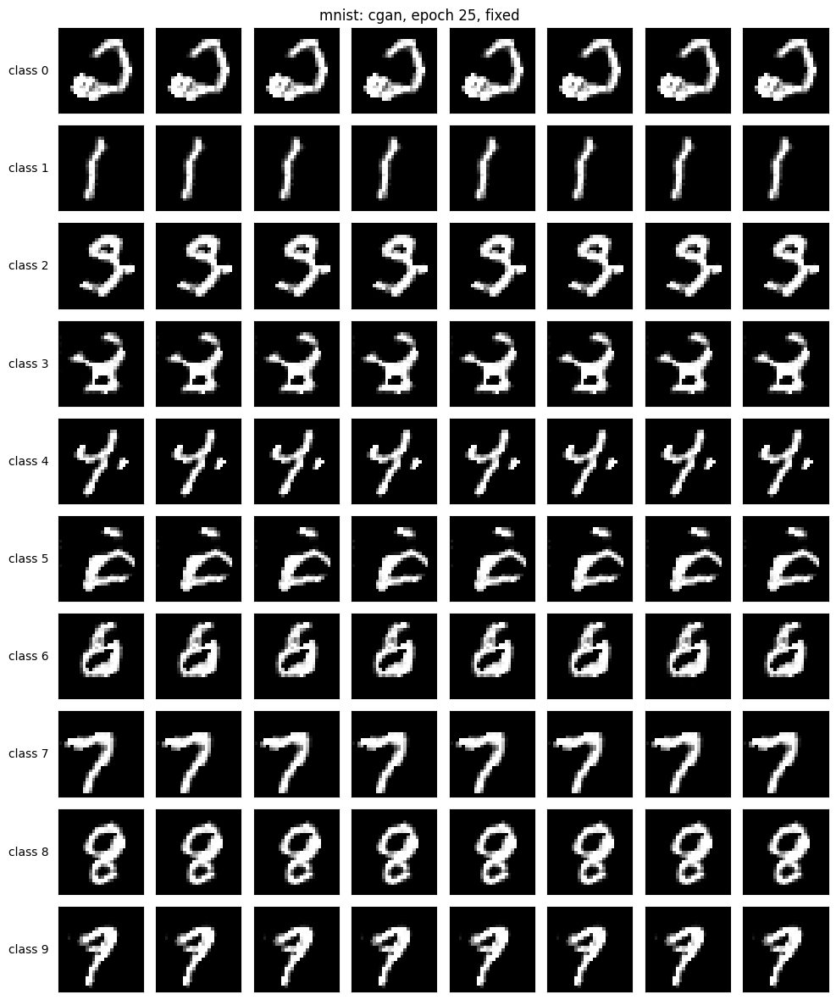

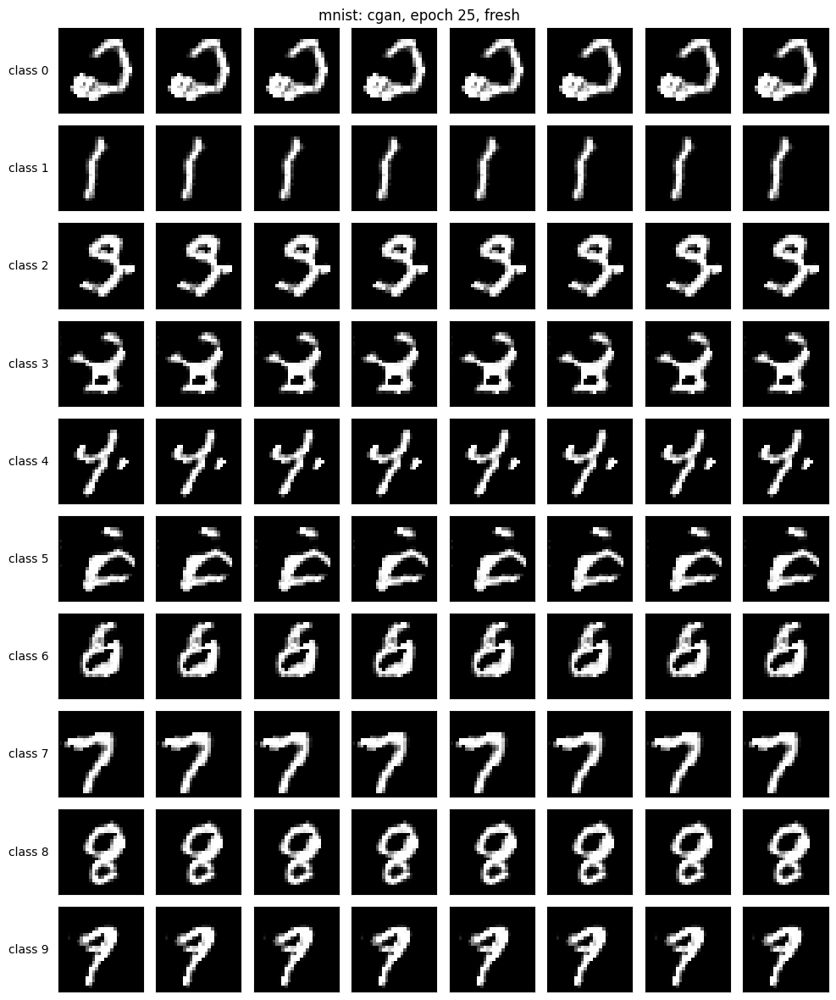

mnist cgan | 26/40 | G total 0.751, adv 0.751, FM 0.00000, D 0.666
mnist cgan | 27/40 | G total 0.759, adv 0.759, FM 0.00000, D 0.663
mnist cgan | 28/40 | G total 0.757, adv 0.757, FM 0.00000, D 0.666
mnist cgan | 29/40 | G total 0.747, adv 0.747, FM 0.00000, D 0.670
mnist cgan | 30/40 | G total 0.751, adv 0.751, FM 0.00000, D 0.673


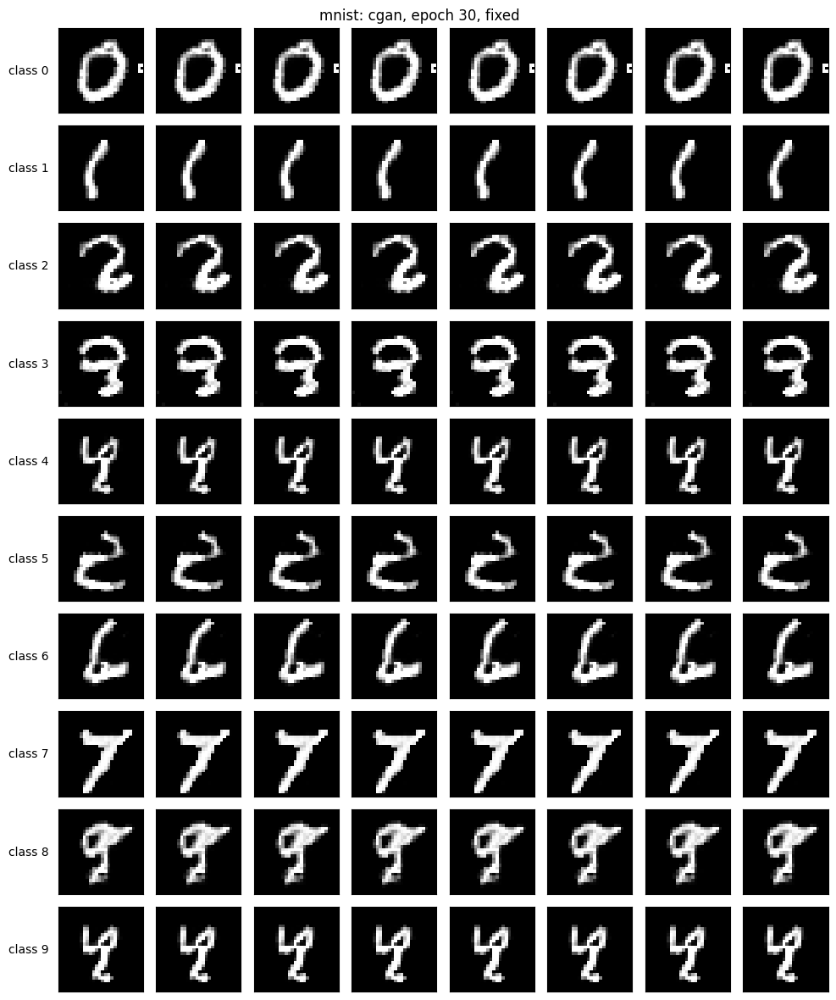

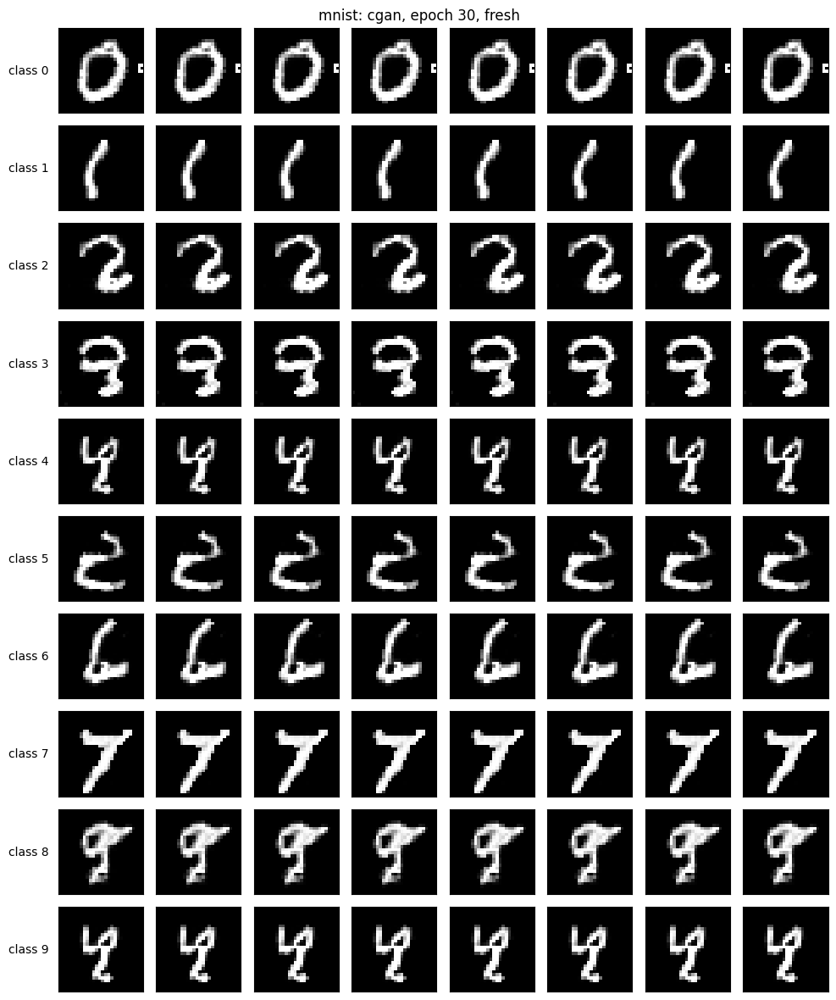

mnist cgan | 31/40 | G total 0.770, adv 0.770, FM 0.00000, D 0.655
mnist cgan | 32/40 | G total 0.741, adv 0.741, FM 0.00000, D 0.677
mnist cgan | 33/40 | G total 0.737, adv 0.737, FM 0.00000, D 0.676
mnist cgan | 34/40 | G total 0.739, adv 0.739, FM 0.00000, D 0.673
mnist cgan | 35/40 | G total 0.732, adv 0.732, FM 0.00000, D 0.677


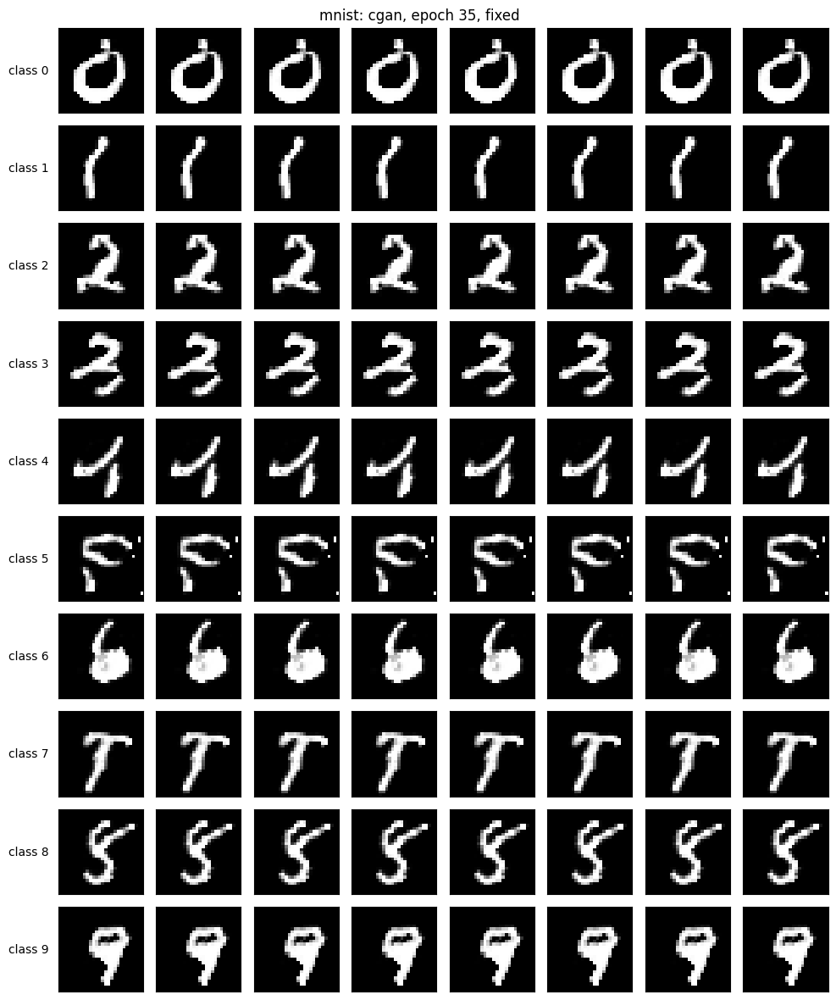

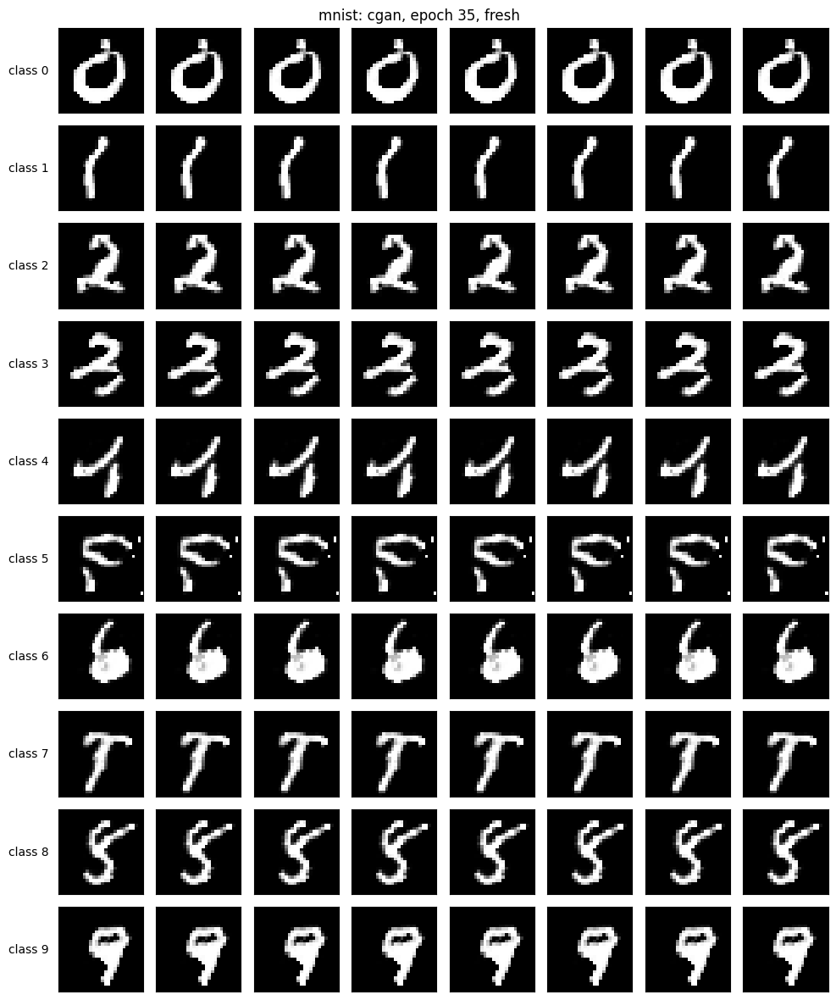

mnist cgan | 36/40 | G total 0.740, adv 0.740, FM 0.00000, D 0.670
mnist cgan | 37/40 | G total 0.746, adv 0.746, FM 0.00000, D 0.673
mnist cgan | 38/40 | G total 0.759, adv 0.759, FM 0.00000, D 0.664
mnist cgan | 39/40 | G total 0.762, adv 0.762, FM 0.00000, D 0.665
mnist cgan | 40/40 | G total 0.779, adv 0.779, FM 0.00000, D 0.653


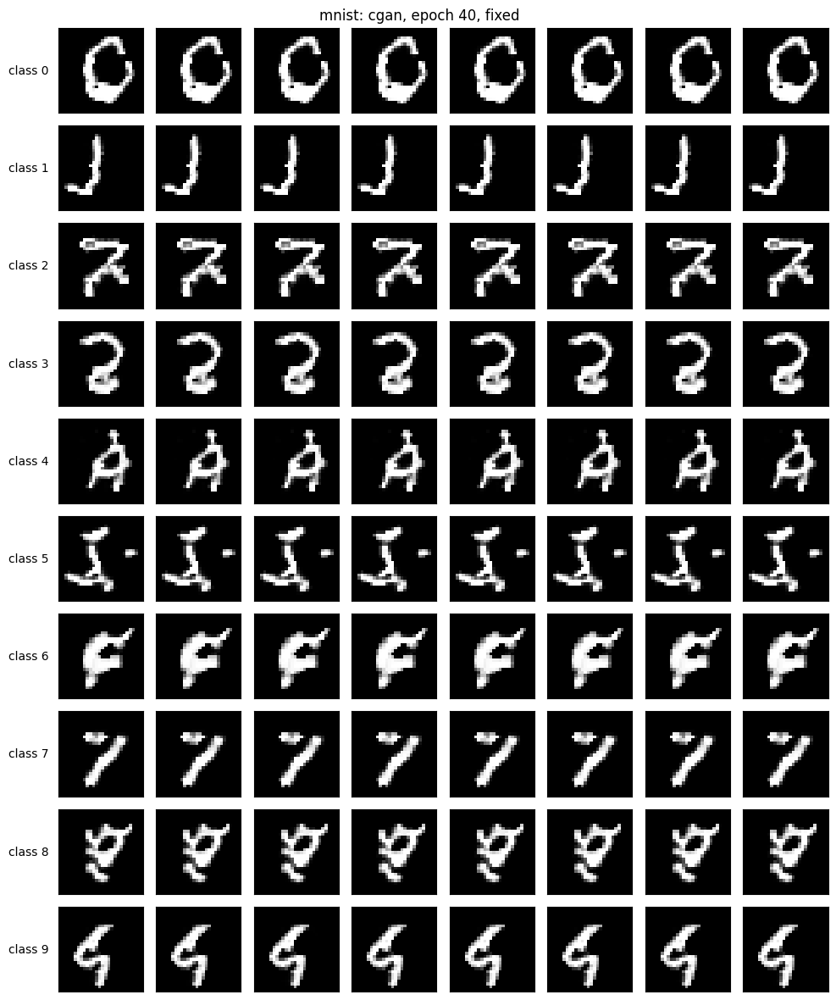

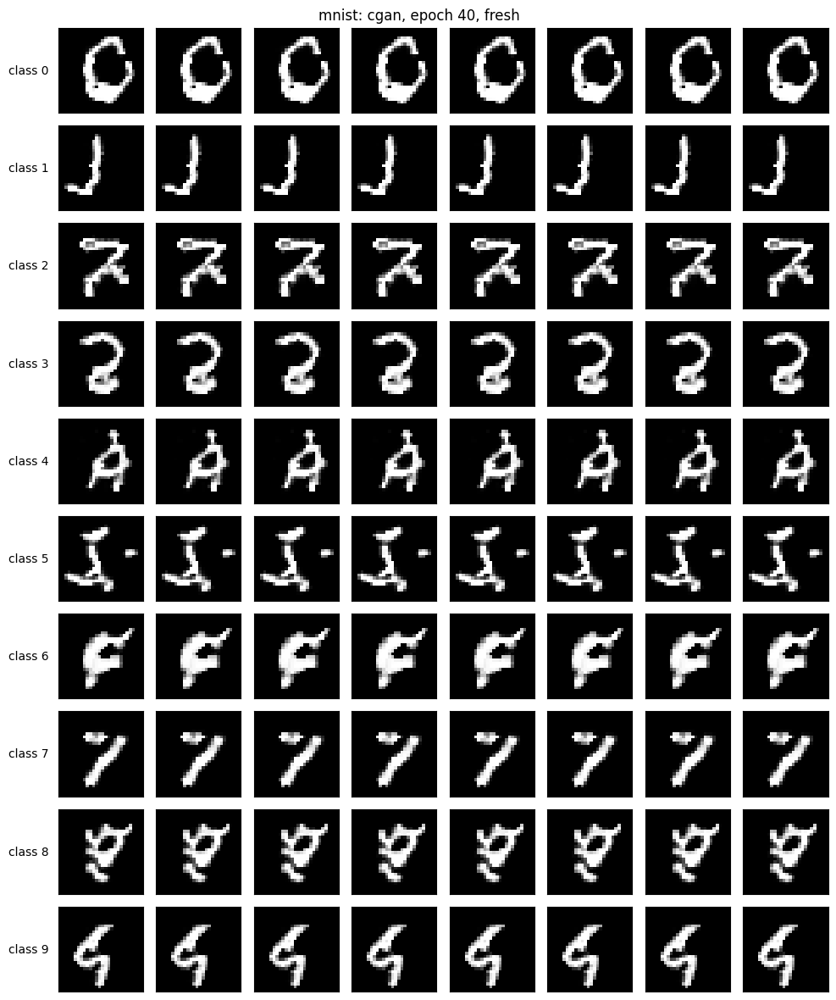

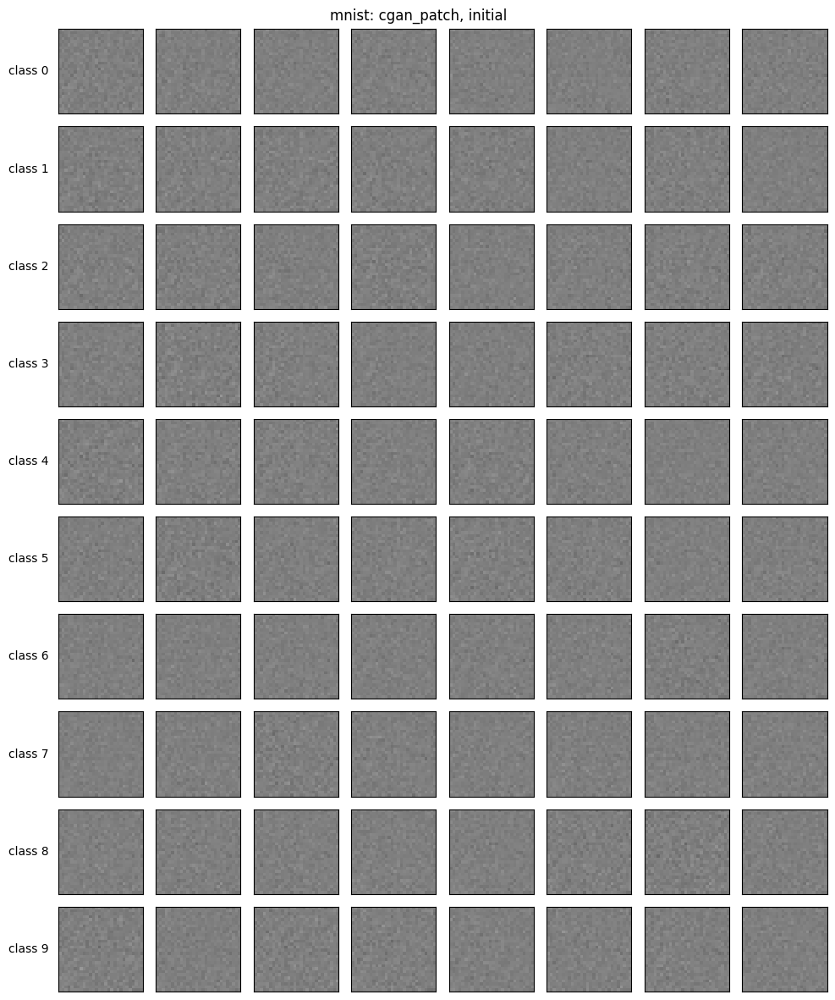

mnist cgan_patch | 1/40 | G total 0.906, adv 0.906, FM 0.00000, D 0.610


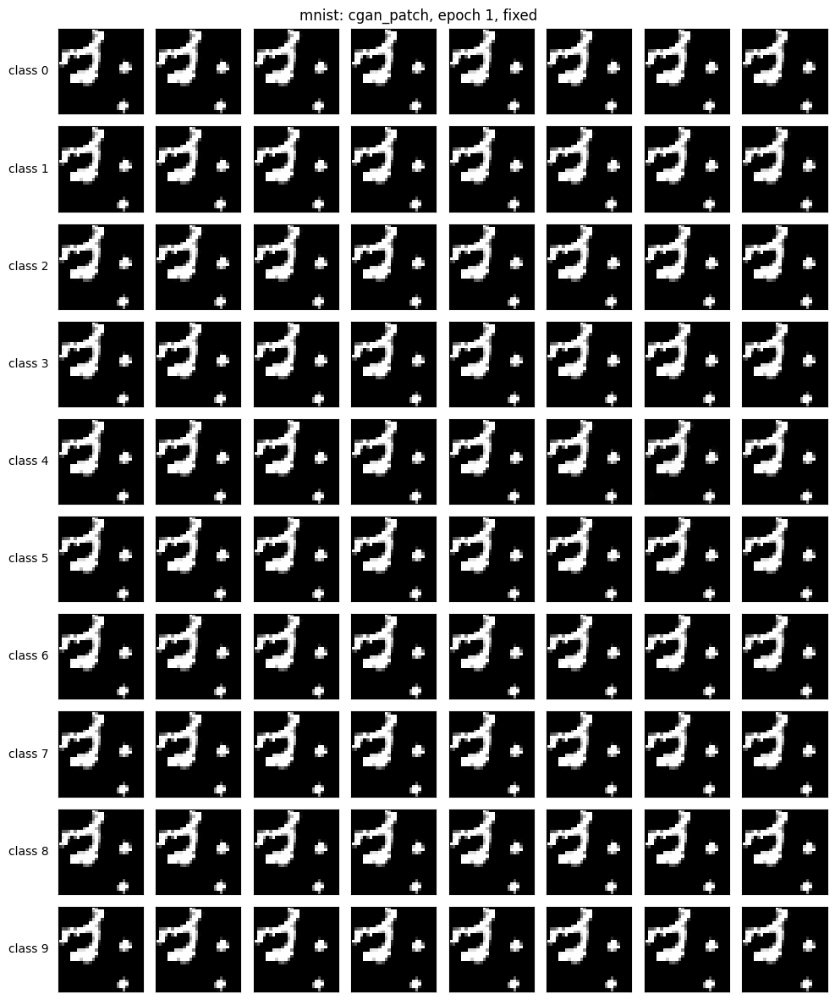

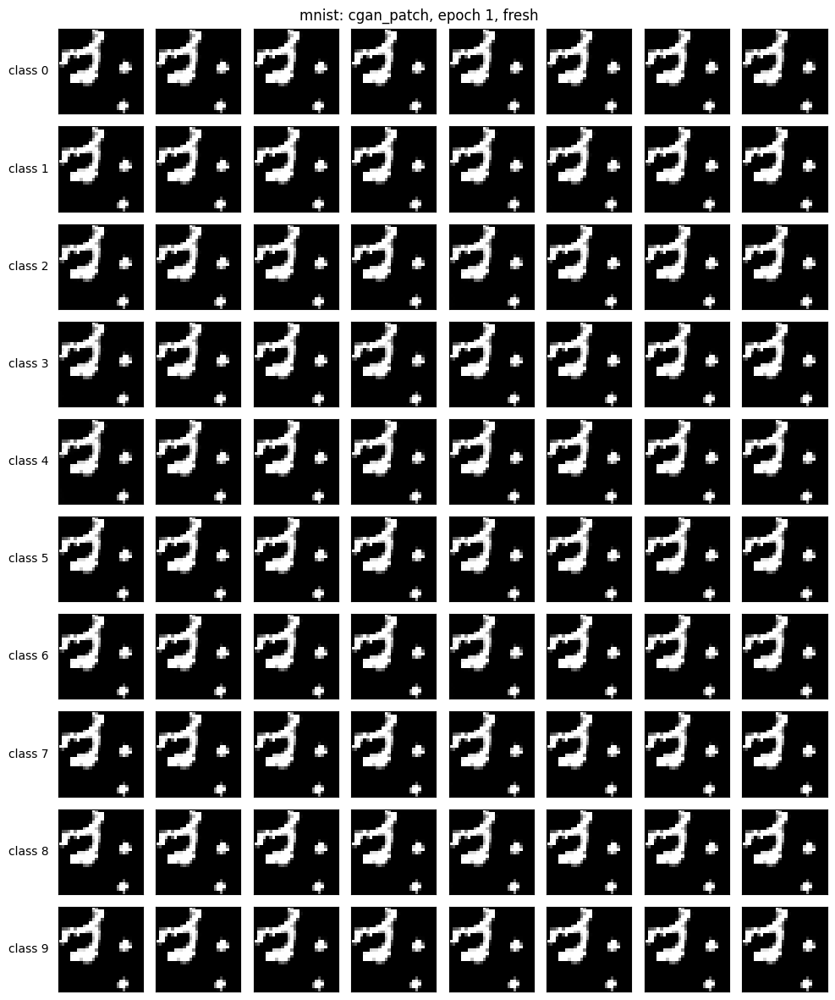

mnist cgan_patch | 2/40 | G total 0.887, adv 0.887, FM 0.00000, D 0.605
mnist cgan_patch | 3/40 | G total 0.852, adv 0.852, FM 0.00000, D 0.627
mnist cgan_patch | 4/40 | G total 0.777, adv 0.777, FM 0.00000, D 0.663
mnist cgan_patch | 5/40 | G total 0.764, adv 0.764, FM 0.00000, D 0.663


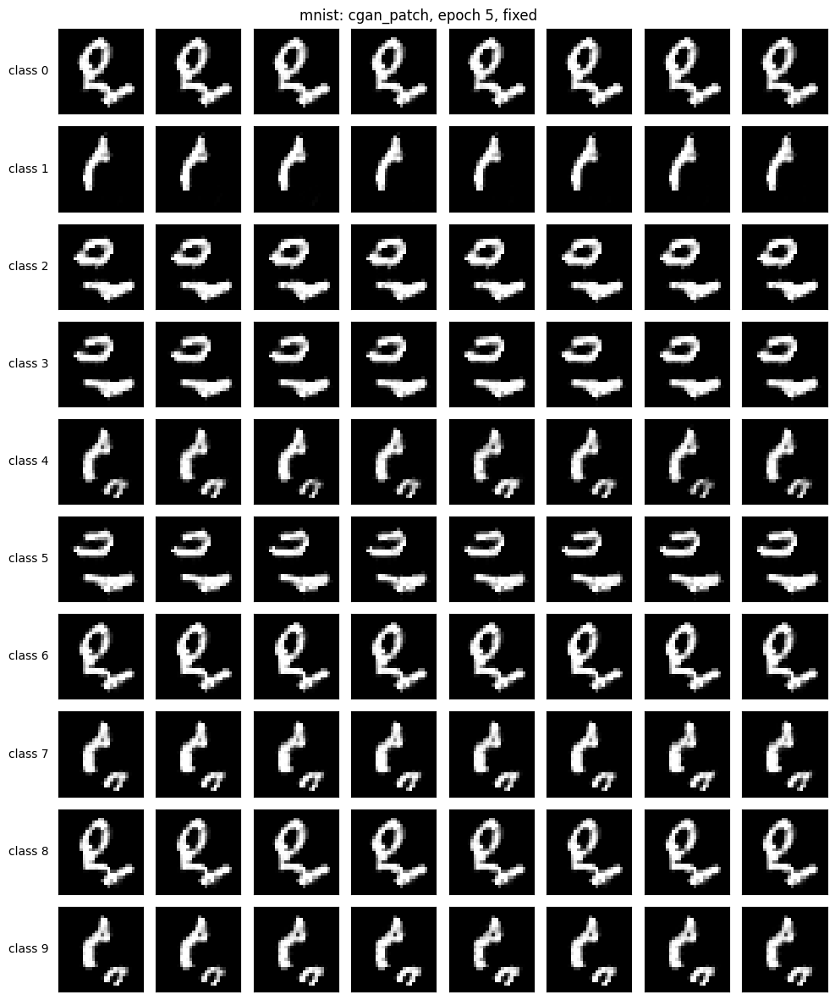

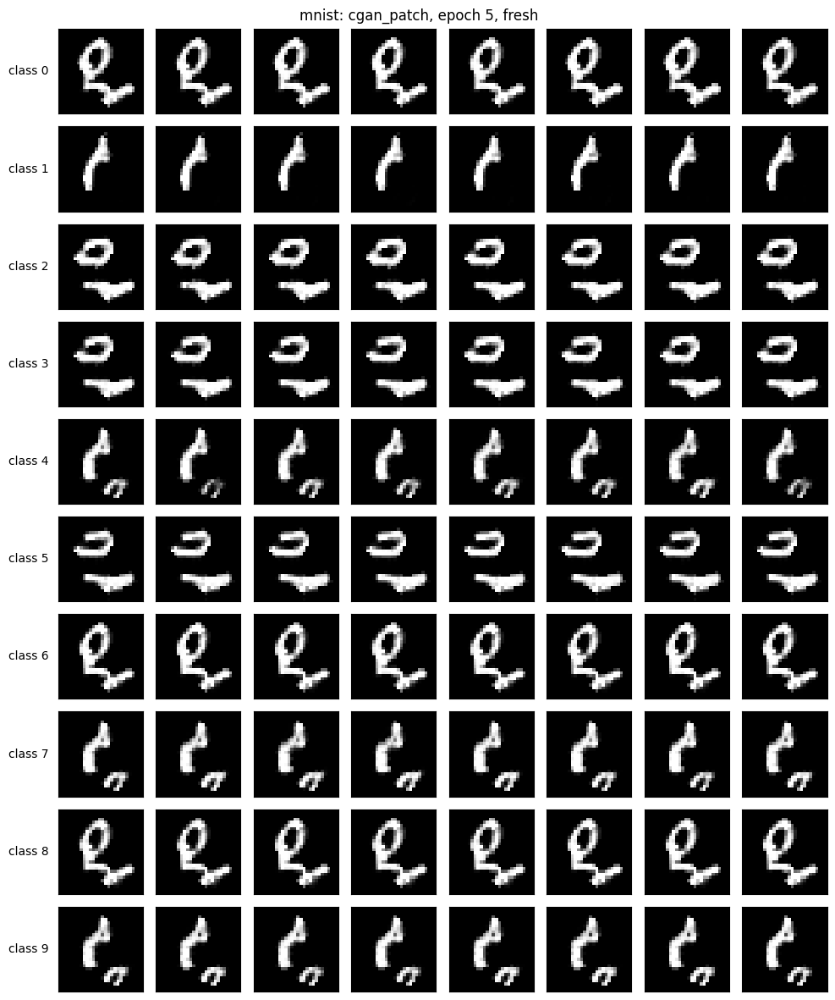

mnist cgan_patch | 6/40 | G total 0.768, adv 0.768, FM 0.00000, D 0.662
mnist cgan_patch | 7/40 | G total 0.762, adv 0.762, FM 0.00000, D 0.664
mnist cgan_patch | 8/40 | G total 0.763, adv 0.763, FM 0.00000, D 0.664
mnist cgan_patch | 9/40 | G total 0.757, adv 0.757, FM 0.00000, D 0.666
mnist cgan_patch | 10/40 | G total 0.763, adv 0.763, FM 0.00000, D 0.662


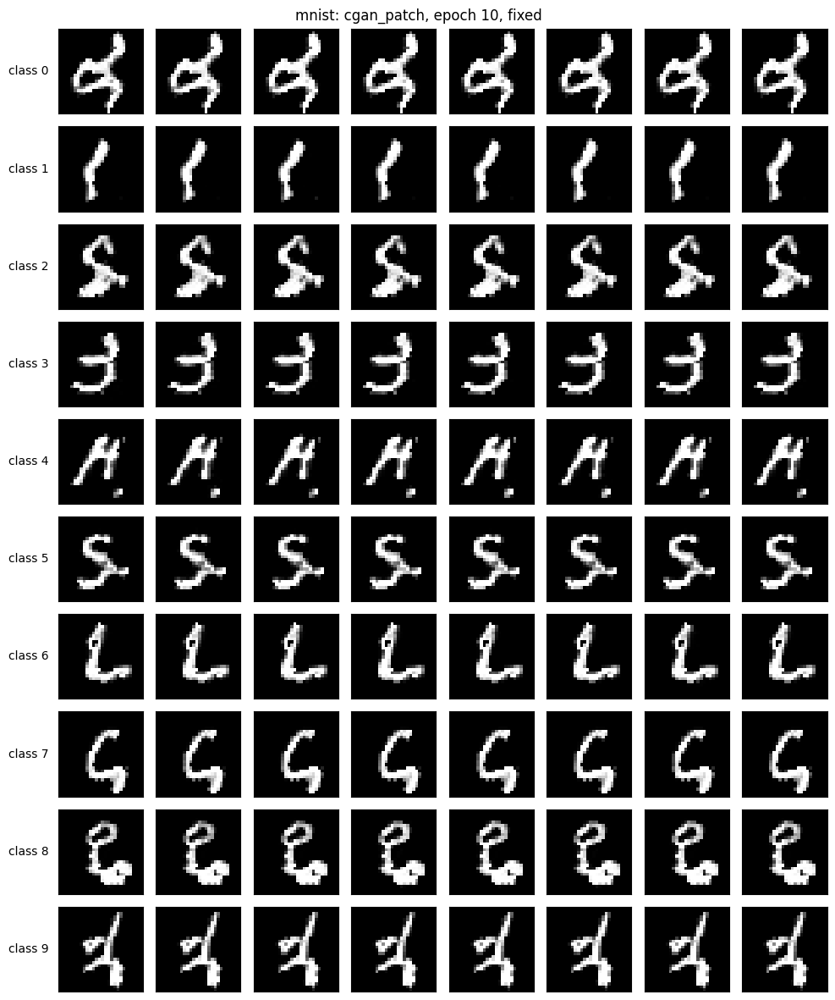

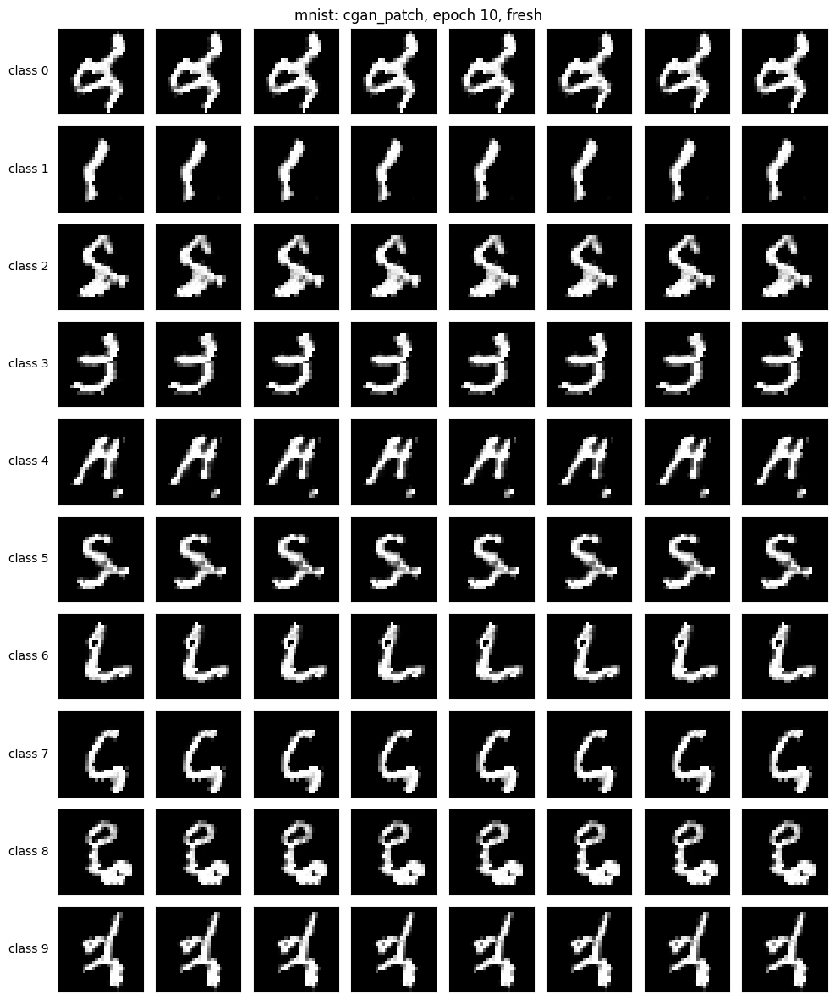

mnist cgan_patch | 11/40 | G total 0.765, adv 0.765, FM 0.00000, D 0.663
mnist cgan_patch | 12/40 | G total 0.763, adv 0.763, FM 0.00000, D 0.664
mnist cgan_patch | 13/40 | G total 0.771, adv 0.771, FM 0.00000, D 0.658
mnist cgan_patch | 14/40 | G total 0.780, adv 0.780, FM 0.00000, D 0.655
mnist cgan_patch | 15/40 | G total 0.769, adv 0.769, FM 0.00000, D 0.663


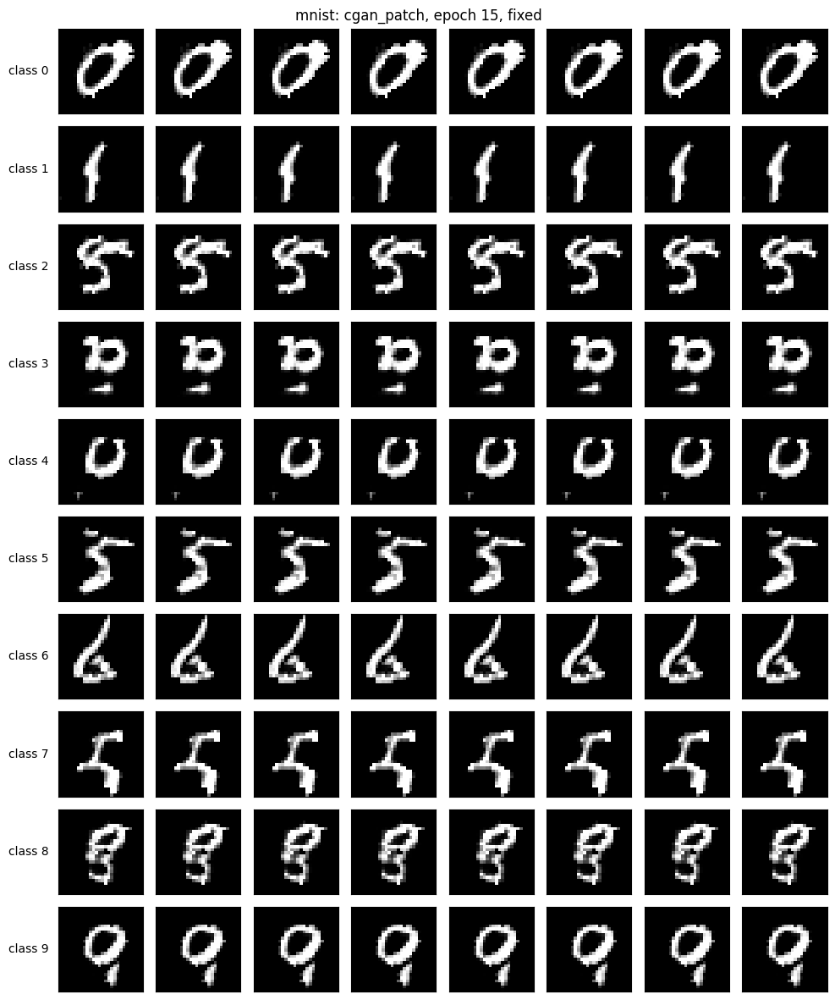

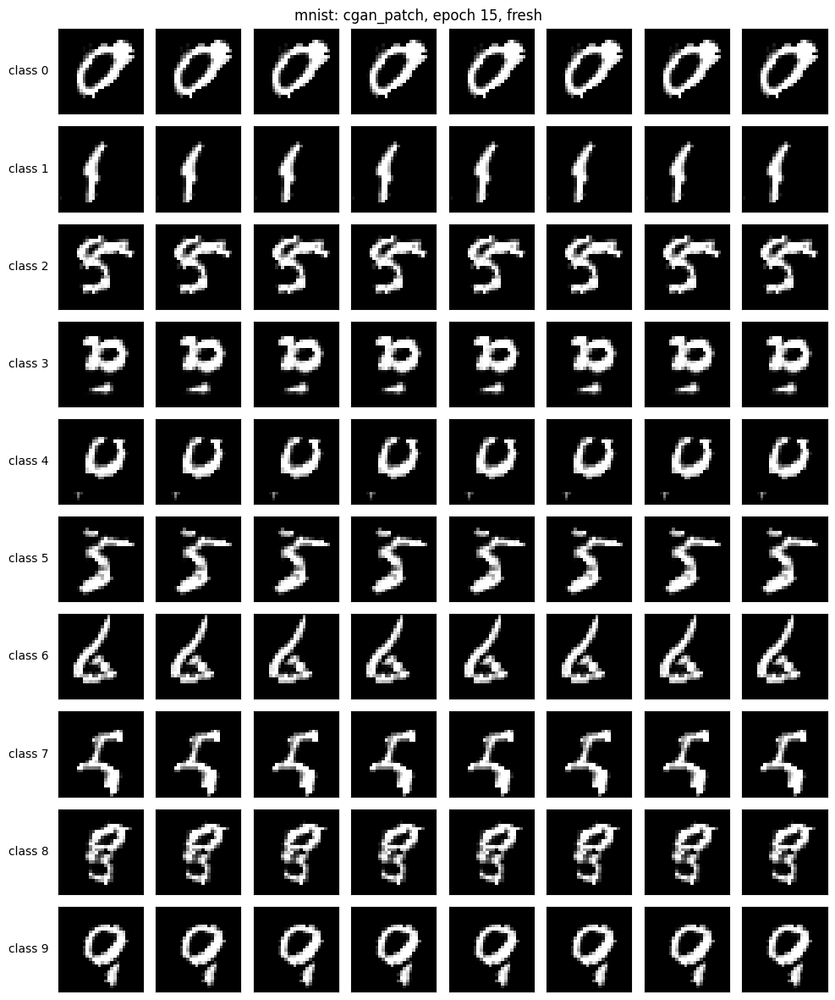

mnist cgan_patch | 16/40 | G total 0.768, adv 0.768, FM 0.00000, D 0.662
mnist cgan_patch | 17/40 | G total 0.773, adv 0.773, FM 0.00000, D 0.659
mnist cgan_patch | 18/40 | G total 0.769, adv 0.769, FM 0.00000, D 0.662
mnist cgan_patch | 19/40 | G total 0.762, adv 0.762, FM 0.00000, D 0.665
mnist cgan_patch | 20/40 | G total 0.765, adv 0.765, FM 0.00000, D 0.665


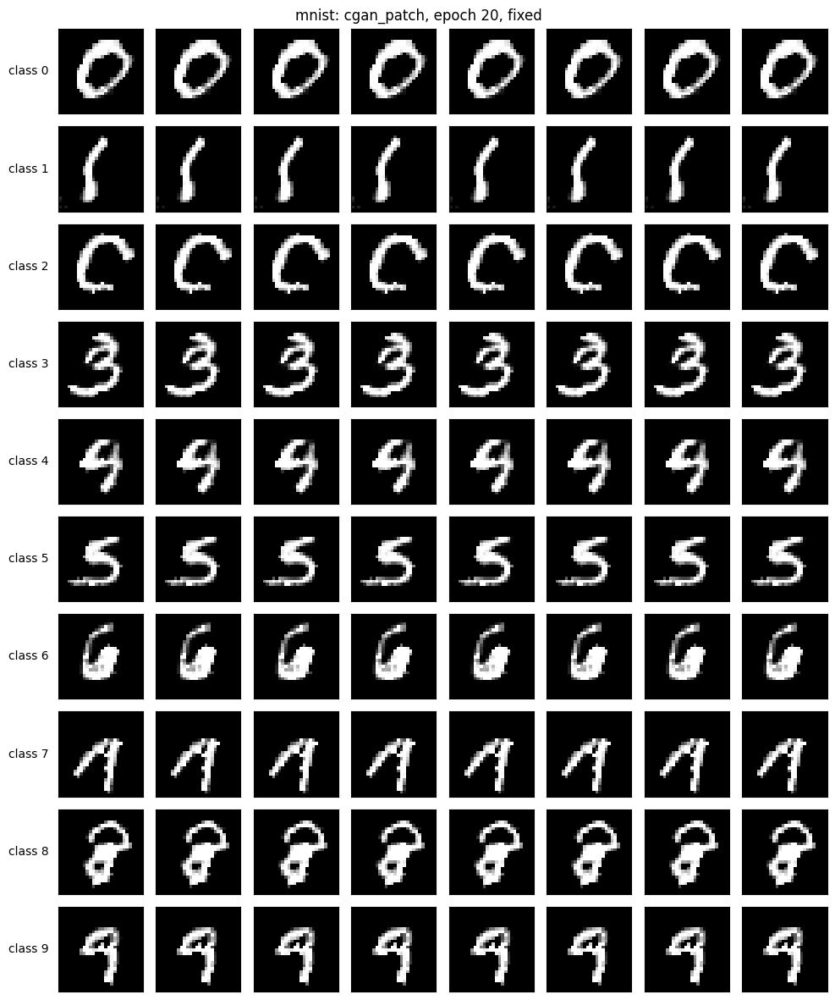

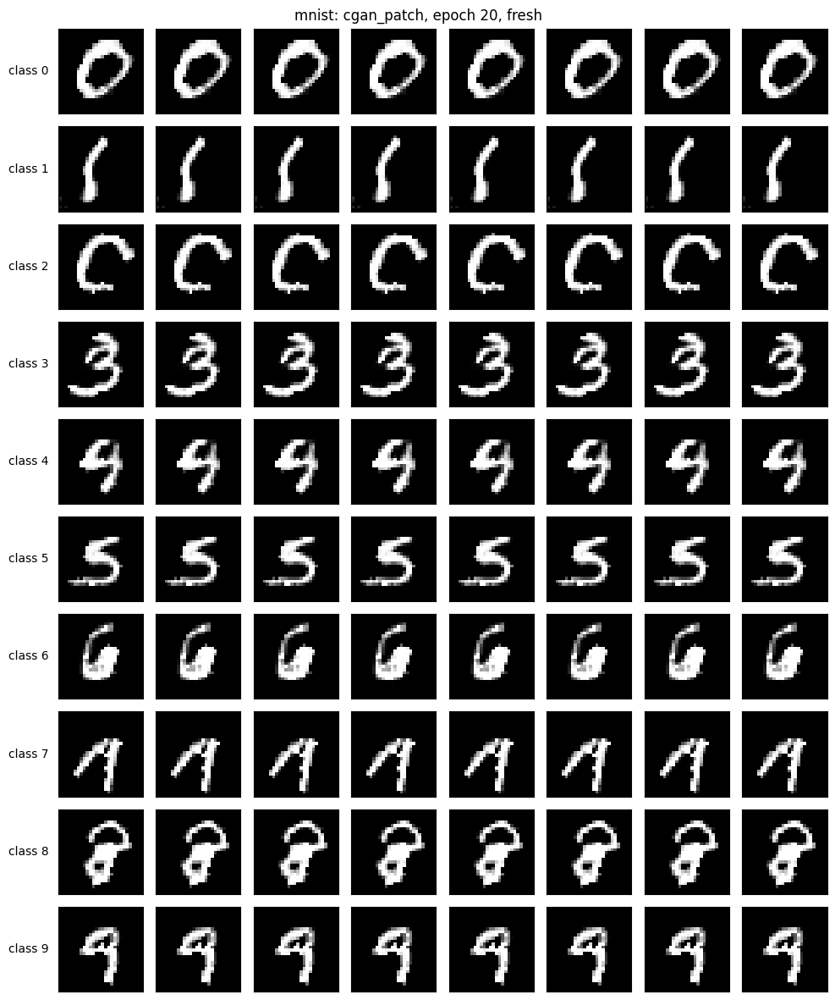

mnist cgan_patch | 21/40 | G total 0.759, adv 0.759, FM 0.00000, D 0.668
mnist cgan_patch | 22/40 | G total 0.745, adv 0.745, FM 0.00000, D 0.675
mnist cgan_patch | 23/40 | G total 0.746, adv 0.746, FM 0.00000, D 0.671
mnist cgan_patch | 24/40 | G total 0.755, adv 0.755, FM 0.00000, D 0.668
mnist cgan_patch | 25/40 | G total 0.769, adv 0.769, FM 0.00000, D 0.660


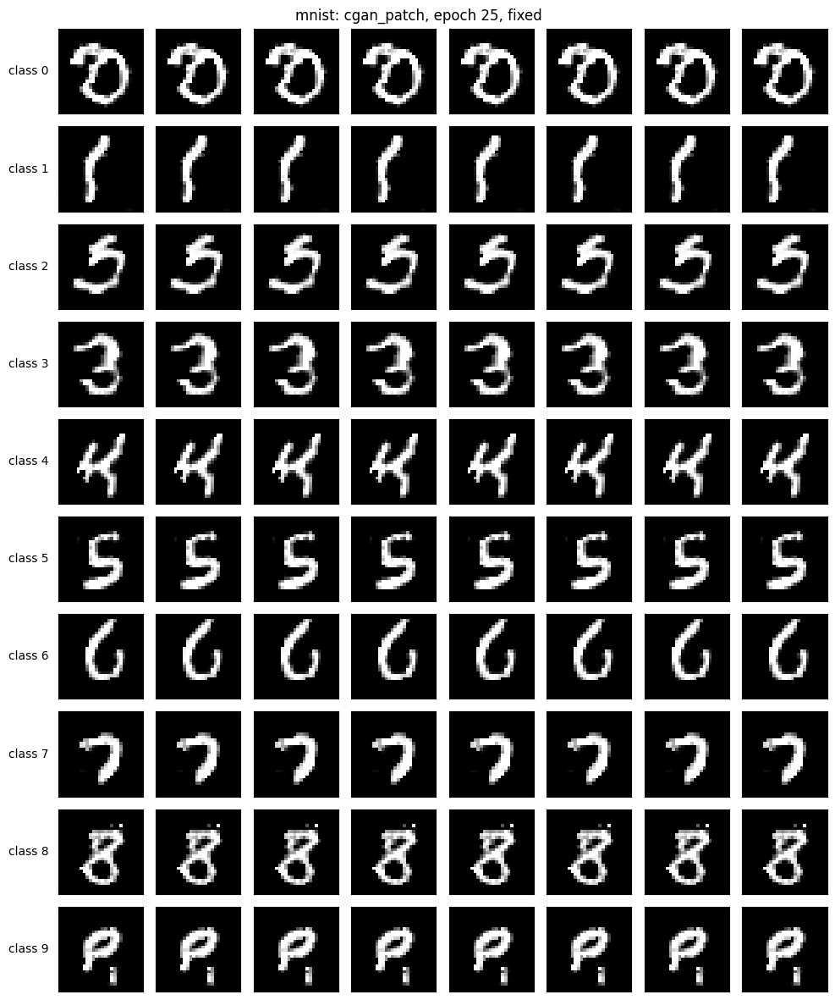

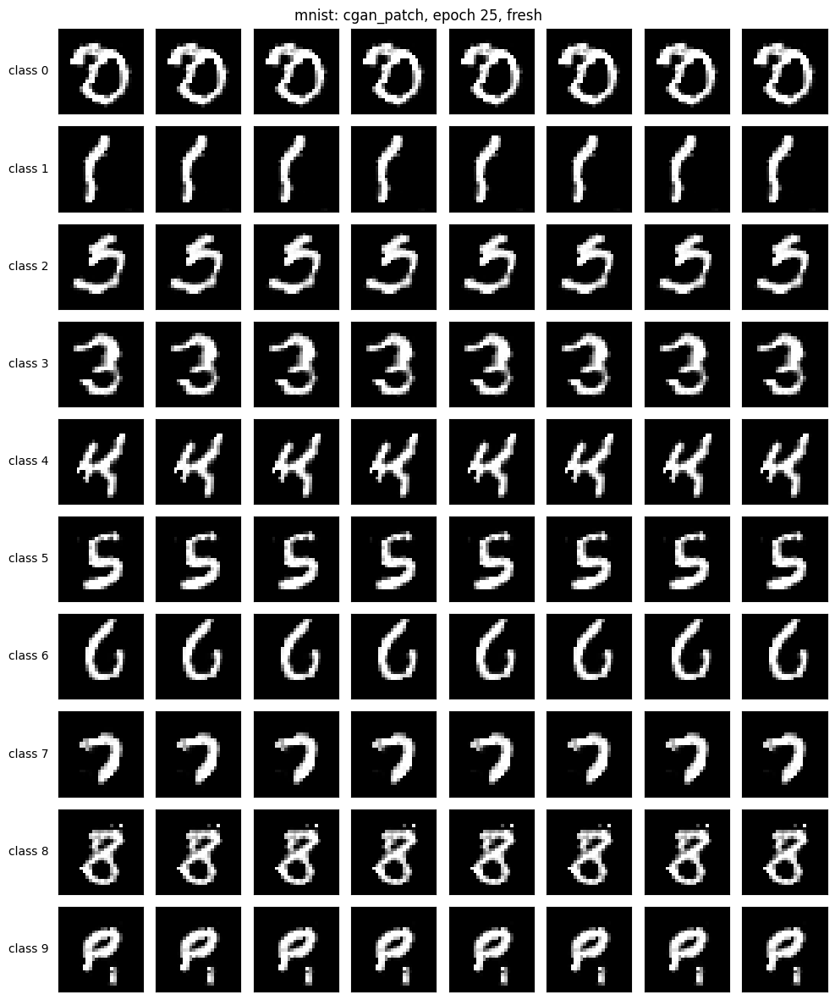

mnist cgan_patch | 26/40 | G total 0.750, adv 0.750, FM 0.00000, D 0.673
mnist cgan_patch | 27/40 | G total 0.755, adv 0.755, FM 0.00000, D 0.670
mnist cgan_patch | 28/40 | G total 0.741, adv 0.741, FM 0.00000, D 0.678
mnist cgan_patch | 29/40 | G total 0.748, adv 0.748, FM 0.00000, D 0.671
mnist cgan_patch | 30/40 | G total 0.760, adv 0.760, FM 0.00000, D 0.666


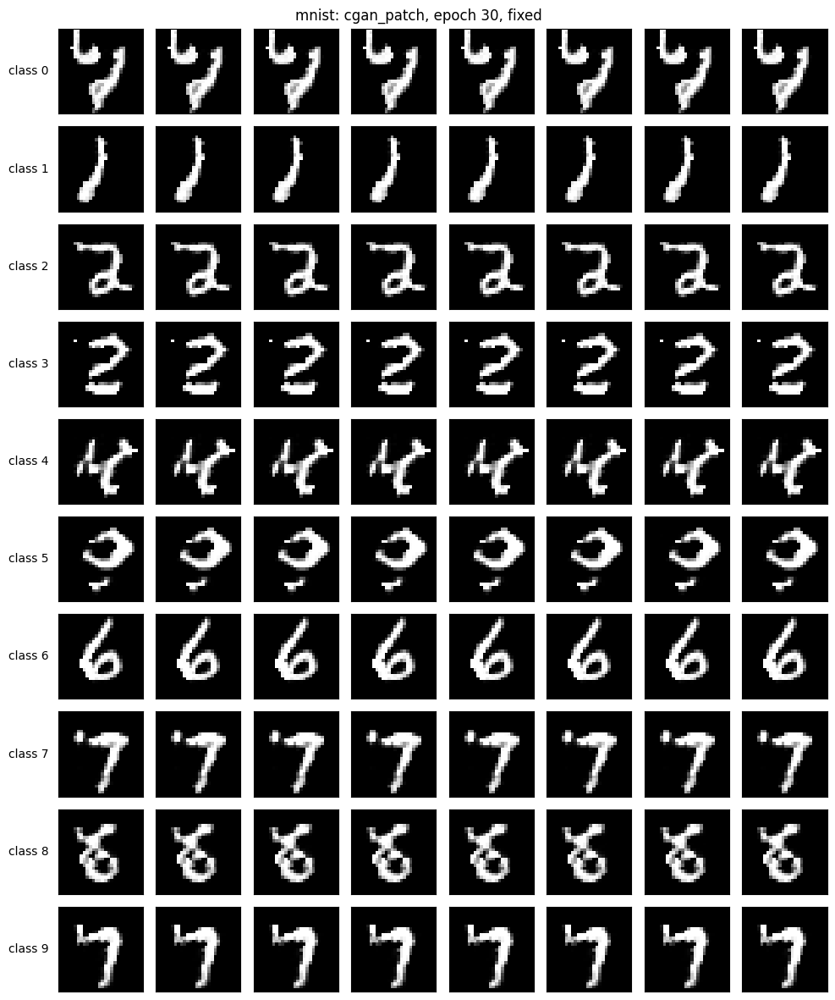

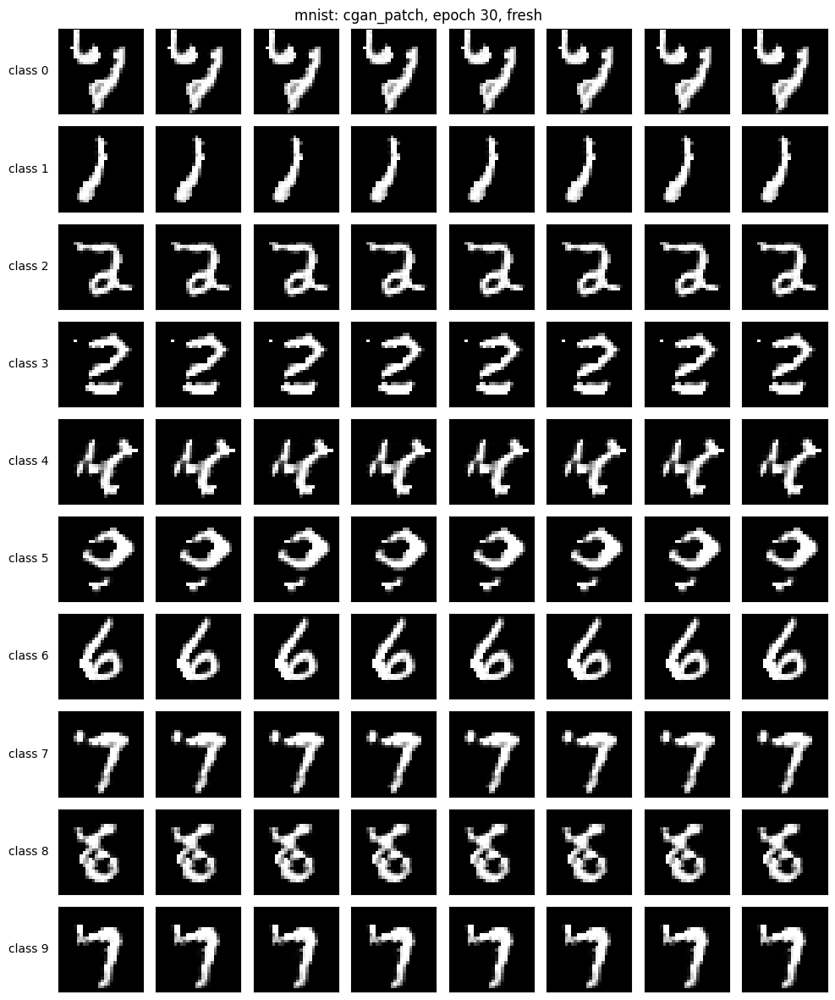

mnist cgan_patch | 31/40 | G total 0.758, adv 0.758, FM 0.00000, D 0.668
mnist cgan_patch | 32/40 | G total 0.756, adv 0.756, FM 0.00000, D 0.670
mnist cgan_patch | 33/40 | G total 0.747, adv 0.747, FM 0.00000, D 0.673
mnist cgan_patch | 34/40 | G total 0.749, adv 0.749, FM 0.00000, D 0.674
mnist cgan_patch | 35/40 | G total 0.739, adv 0.739, FM 0.00000, D 0.677


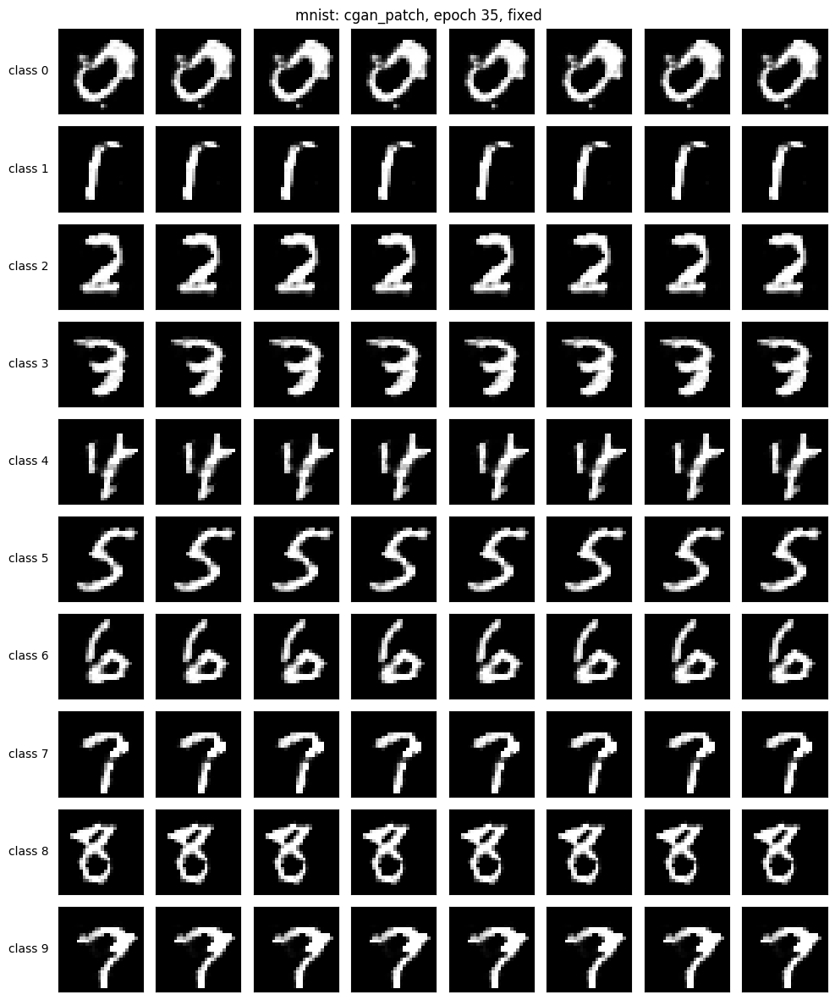

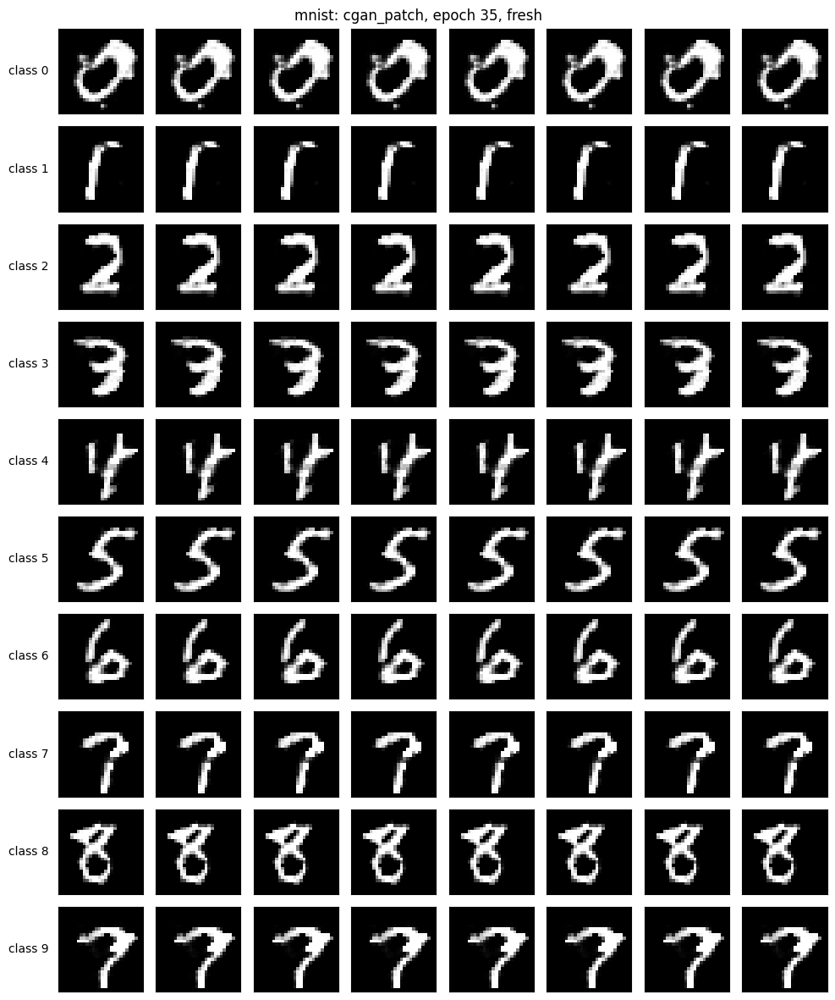

mnist cgan_patch | 36/40 | G total 0.746, adv 0.746, FM 0.00000, D 0.673
mnist cgan_patch | 37/40 | G total 0.757, adv 0.757, FM 0.00000, D 0.669
mnist cgan_patch | 38/40 | G total 0.752, adv 0.752, FM 0.00000, D 0.671
mnist cgan_patch | 39/40 | G total 0.761, adv 0.761, FM 0.00000, D 0.666
mnist cgan_patch | 40/40 | G total 0.754, adv 0.754, FM 0.00000, D 0.669


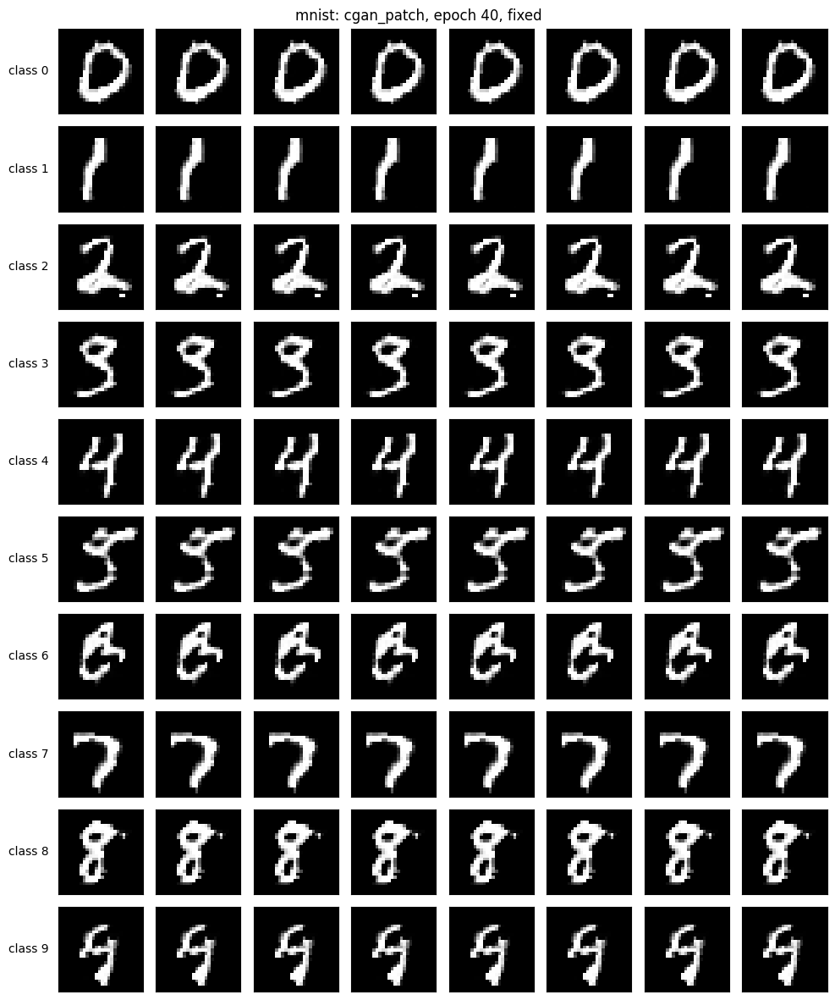

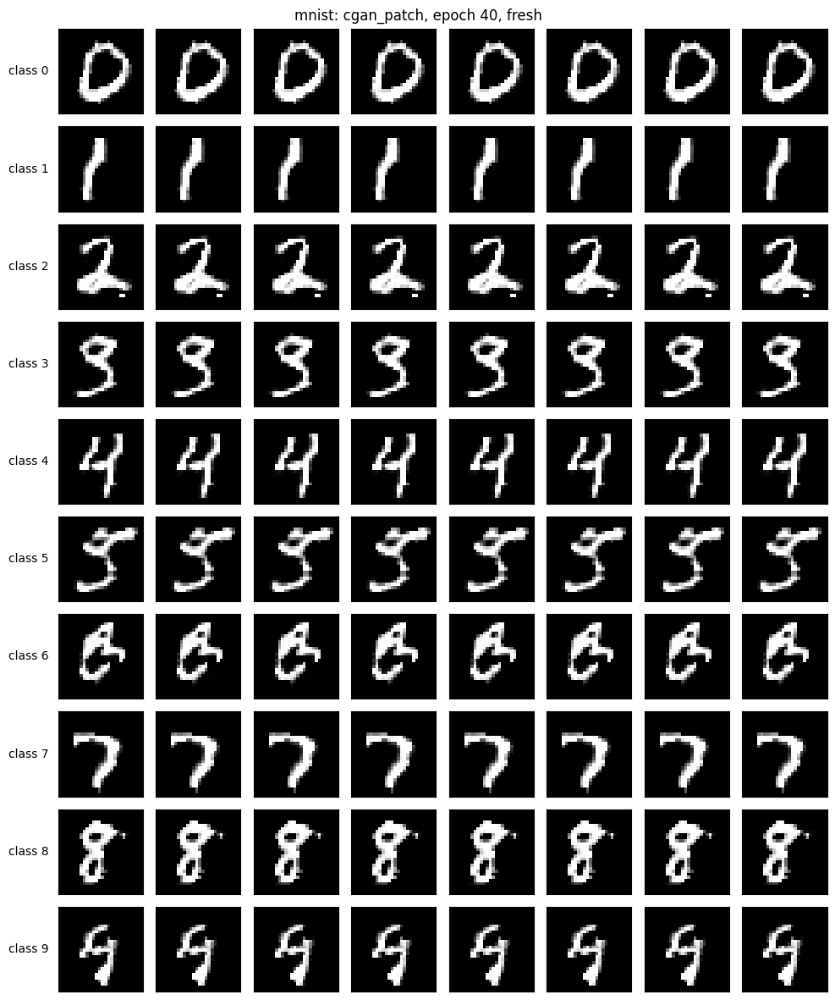

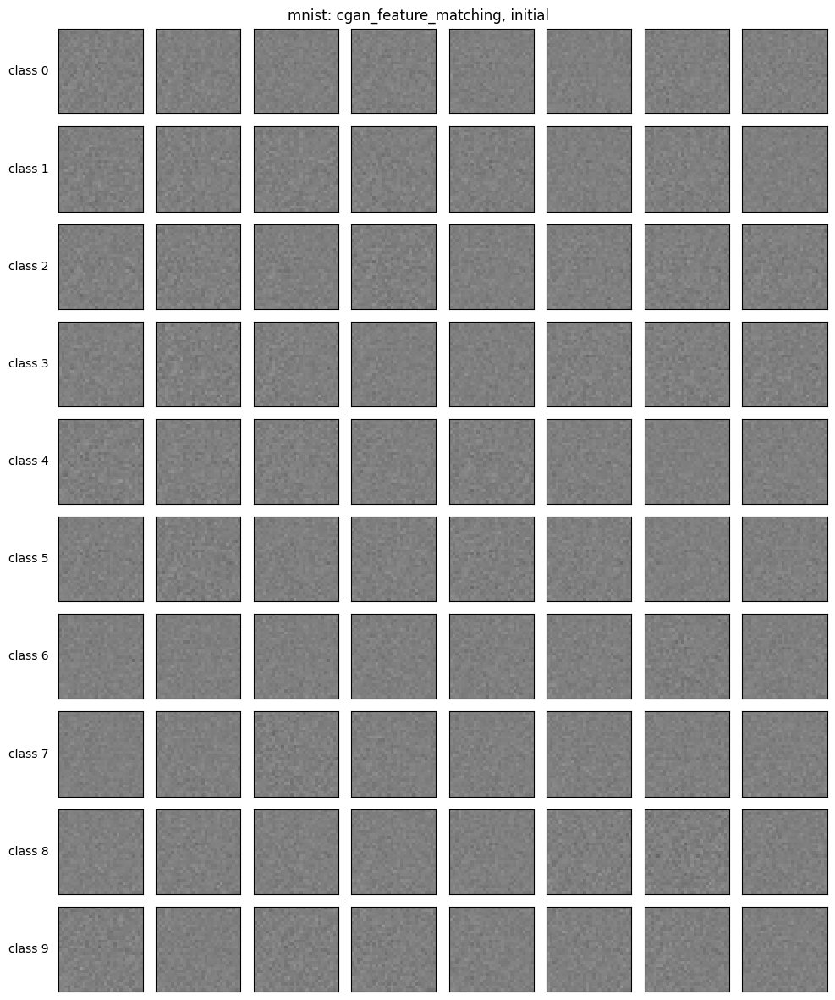

mnist cgan_feature_matching | 1/40 | G total 1.215, adv 1.089, FM 0.01259, D 0.563


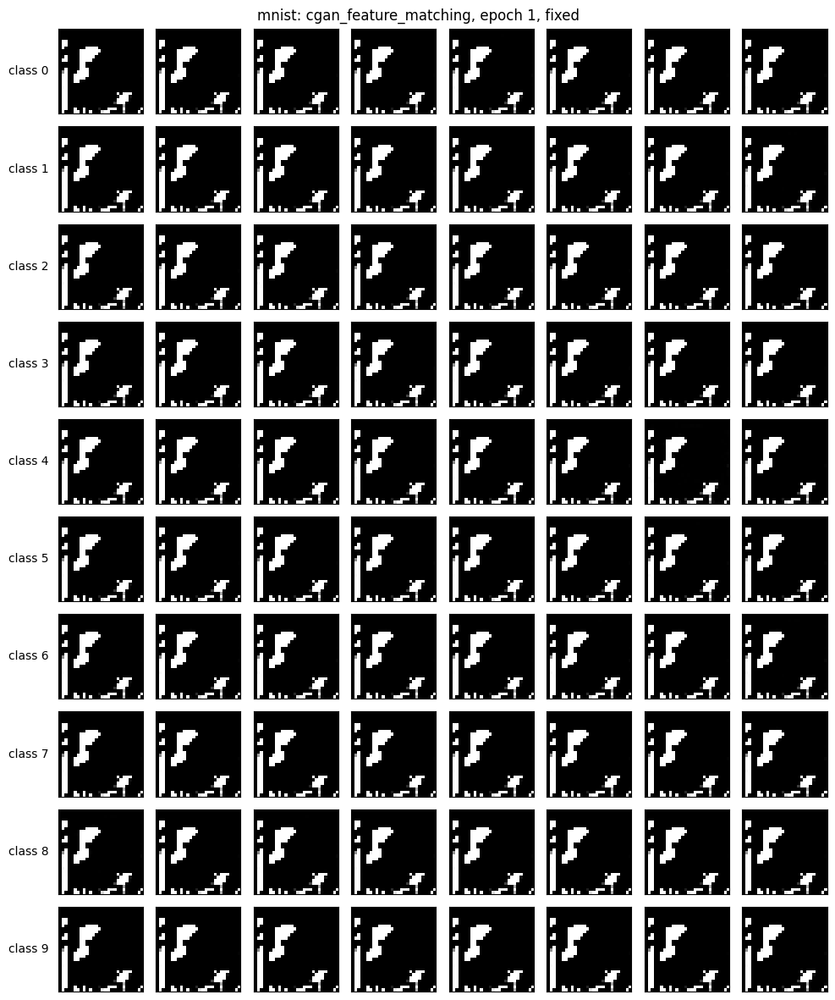

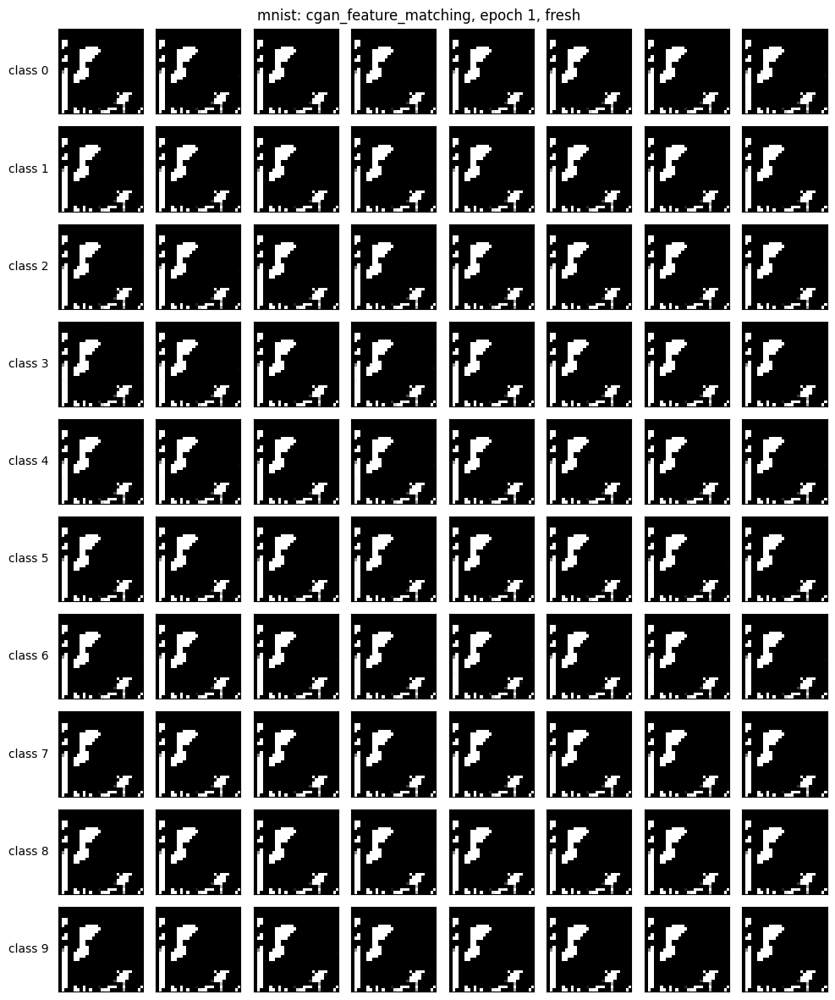

mnist cgan_feature_matching | 2/40 | G total 1.296, adv 1.217, FM 0.00790, D 0.479
mnist cgan_feature_matching | 3/40 | G total 0.760, adv 0.743, FM 0.00166, D 0.678
mnist cgan_feature_matching | 4/40 | G total 0.840, adv 0.826, FM 0.00132, D 0.622
mnist cgan_feature_matching | 5/40 | G total 0.811, adv 0.794, FM 0.00176, D 0.646


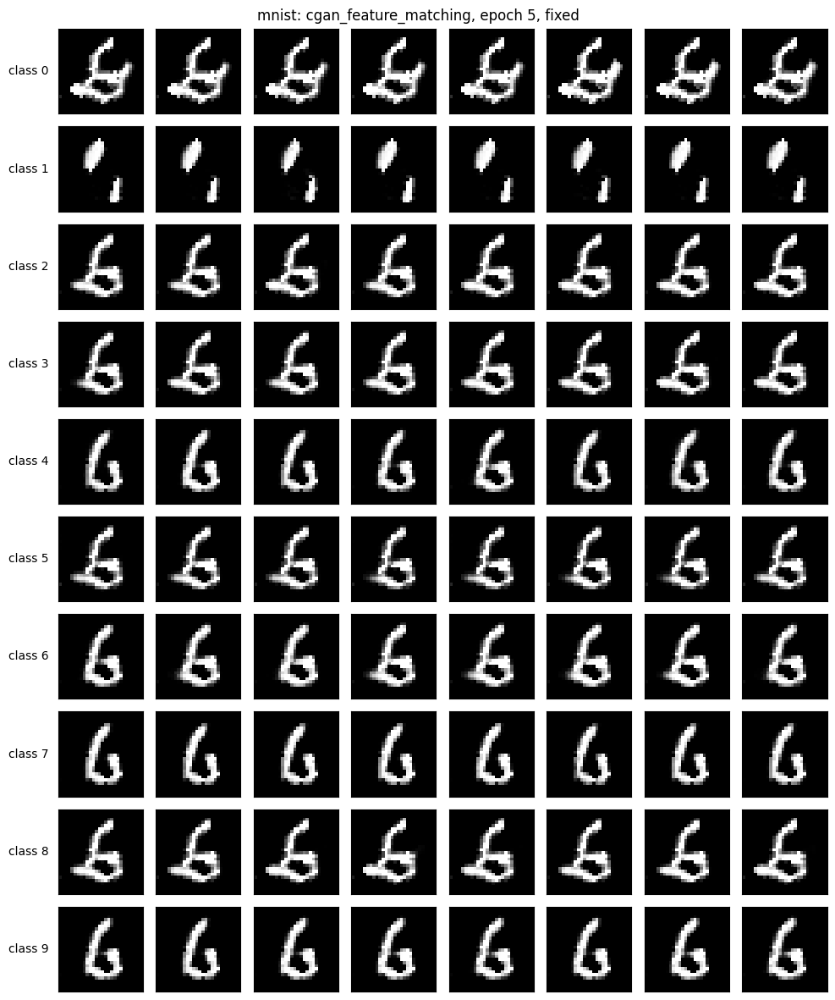

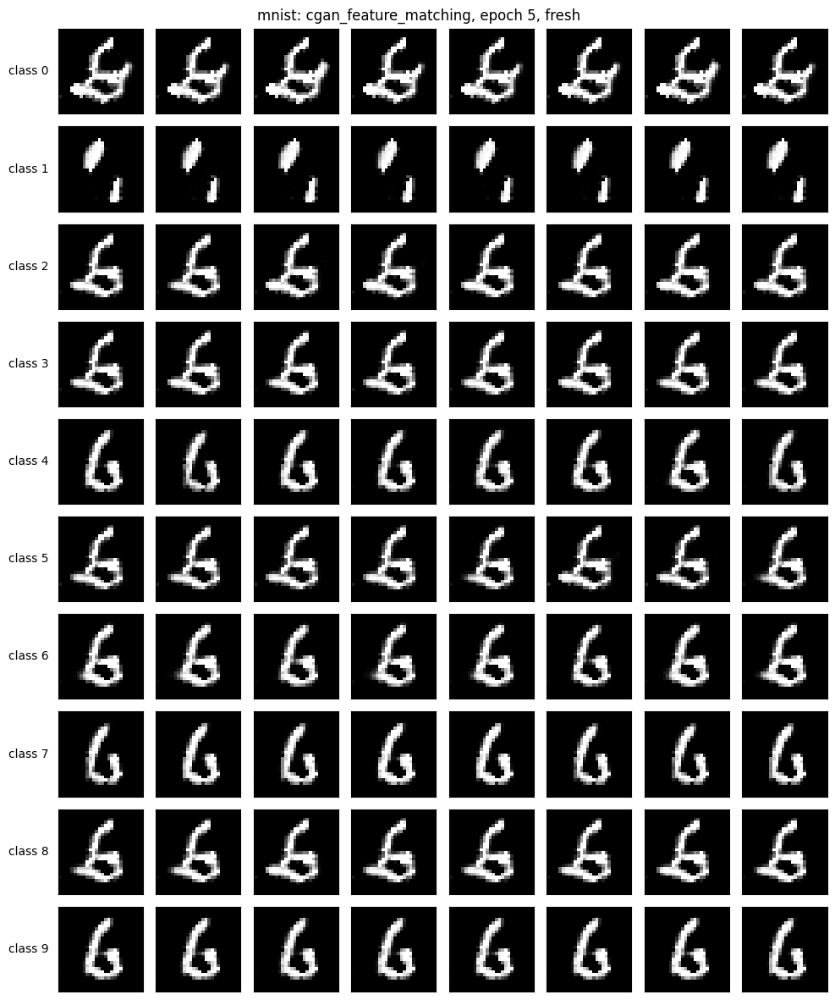

mnist cgan_feature_matching | 6/40 | G total 0.766, adv 0.750, FM 0.00158, D 0.669
mnist cgan_feature_matching | 7/40 | G total 0.810, adv 0.791, FM 0.00192, D 0.644
mnist cgan_feature_matching | 8/40 | G total 0.852, adv 0.829, FM 0.00227, D 0.625
mnist cgan_feature_matching | 9/40 | G total 0.803, adv 0.781, FM 0.00222, D 0.653
mnist cgan_feature_matching | 10/40 | G total 0.793, adv 0.771, FM 0.00217, D 0.660


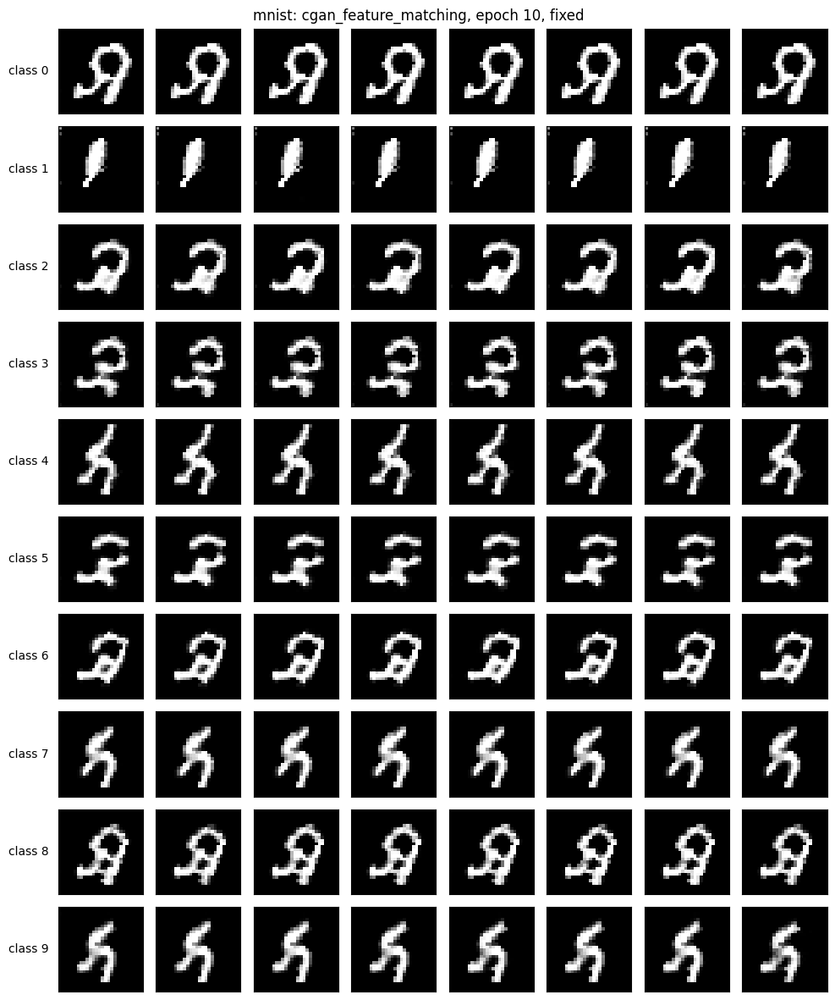

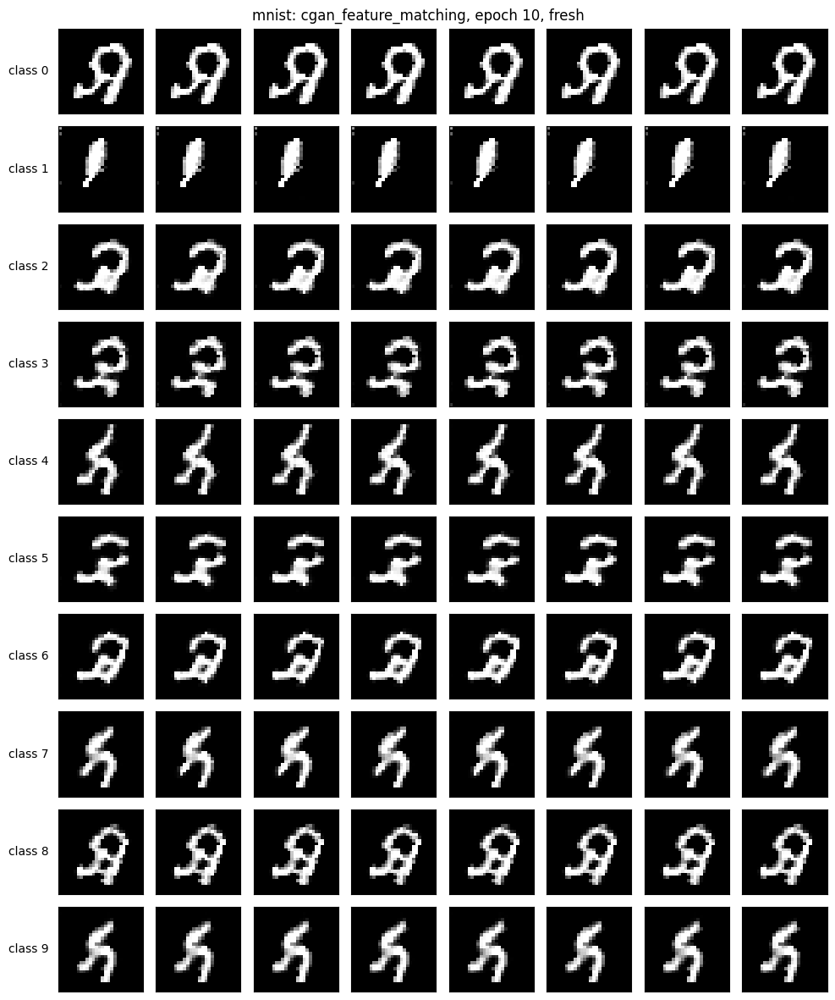

mnist cgan_feature_matching | 11/40 | G total 0.781, adv 0.758, FM 0.00228, D 0.664
mnist cgan_feature_matching | 12/40 | G total 0.795, adv 0.771, FM 0.00245, D 0.654
mnist cgan_feature_matching | 13/40 | G total 0.808, adv 0.784, FM 0.00241, D 0.650
mnist cgan_feature_matching | 14/40 | G total 0.816, adv 0.790, FM 0.00260, D 0.643
mnist cgan_feature_matching | 15/40 | G total 0.822, adv 0.795, FM 0.00269, D 0.640


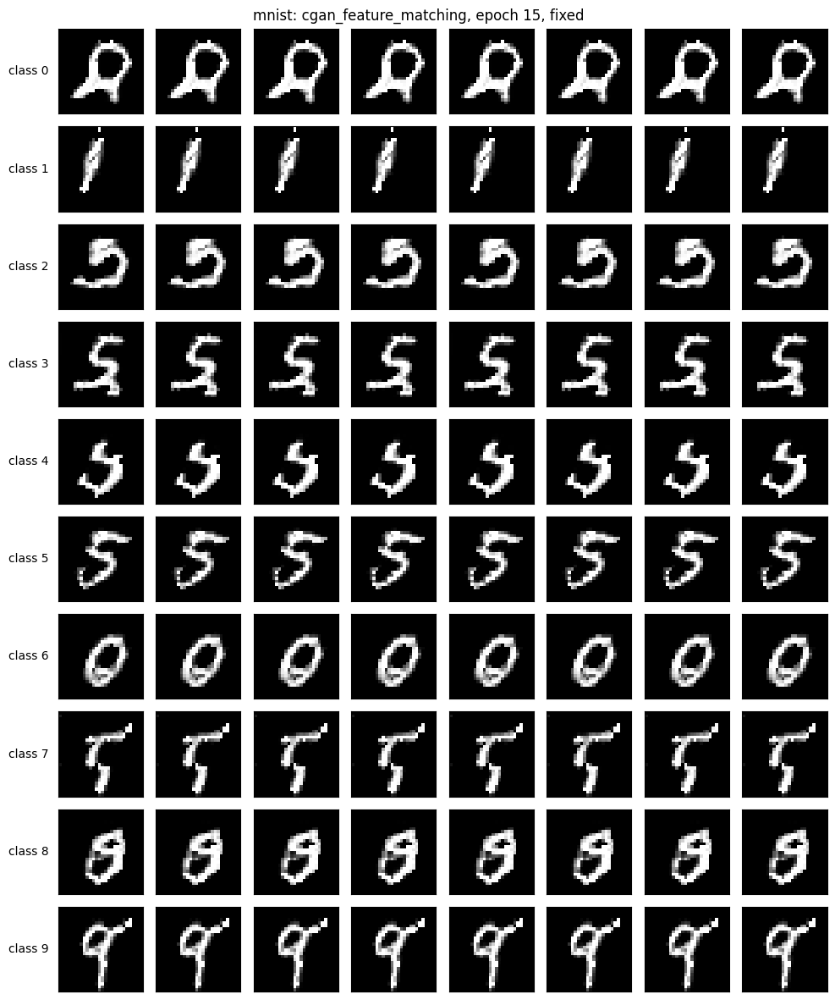

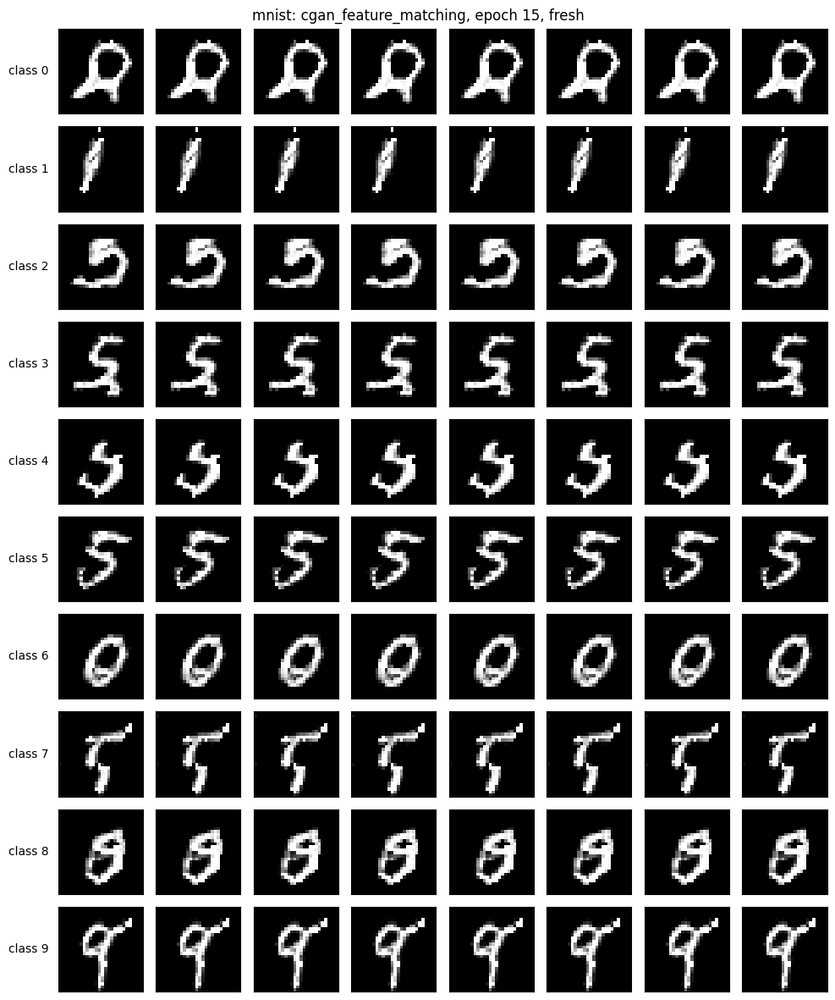

mnist cgan_feature_matching | 16/40 | G total 0.811, adv 0.786, FM 0.00254, D 0.647
mnist cgan_feature_matching | 17/40 | G total 0.808, adv 0.781, FM 0.00269, D 0.650
mnist cgan_feature_matching | 18/40 | G total 0.814, adv 0.787, FM 0.00269, D 0.646
mnist cgan_feature_matching | 19/40 | G total 0.816, adv 0.790, FM 0.00265, D 0.644
mnist cgan_feature_matching | 20/40 | G total 0.816, adv 0.788, FM 0.00274, D 0.647


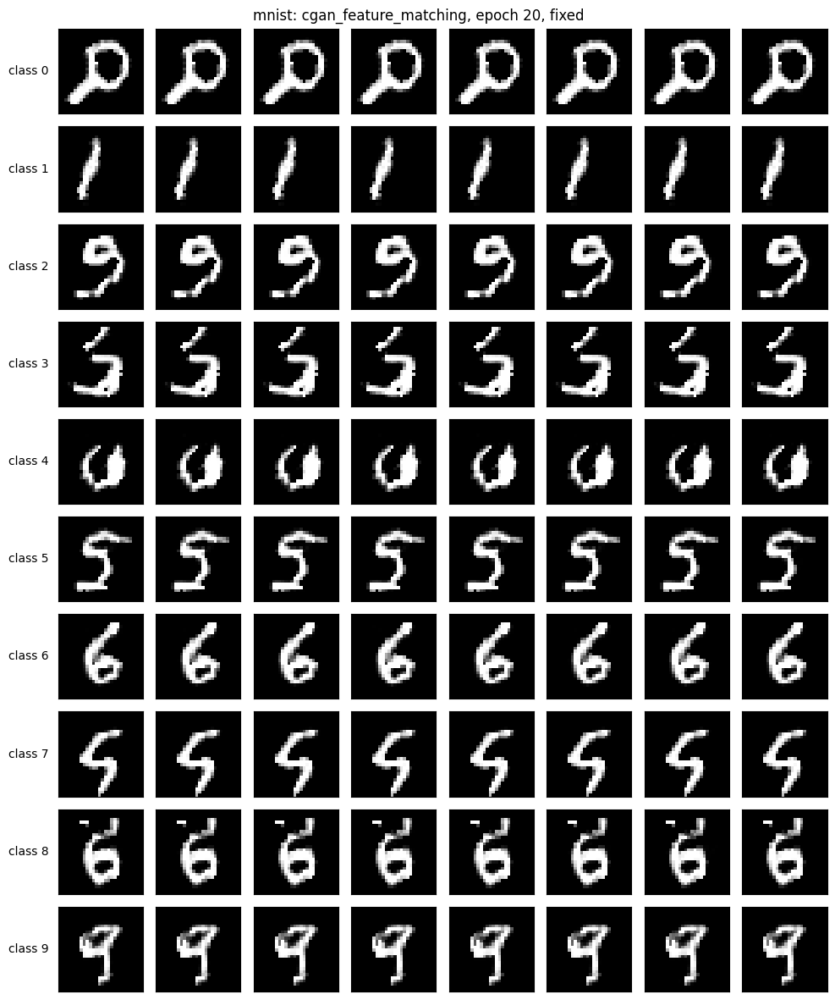

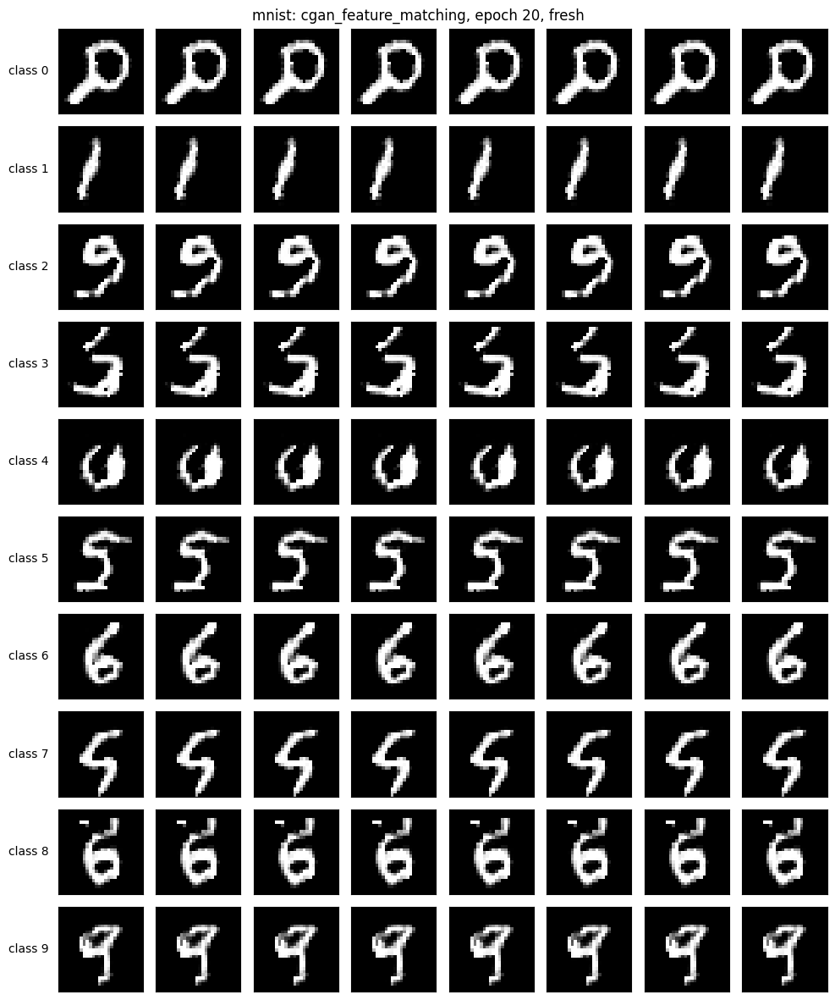

mnist cgan_feature_matching | 21/40 | G total 0.831, adv 0.801, FM 0.00298, D 0.640
mnist cgan_feature_matching | 22/40 | G total 0.838, adv 0.806, FM 0.00320, D 0.635
mnist cgan_feature_matching | 23/40 | G total 0.852, adv 0.817, FM 0.00346, D 0.632
mnist cgan_feature_matching | 24/40 | G total 0.863, adv 0.826, FM 0.00376, D 0.628
mnist cgan_feature_matching | 25/40 | G total 0.854, adv 0.817, FM 0.00376, D 0.639


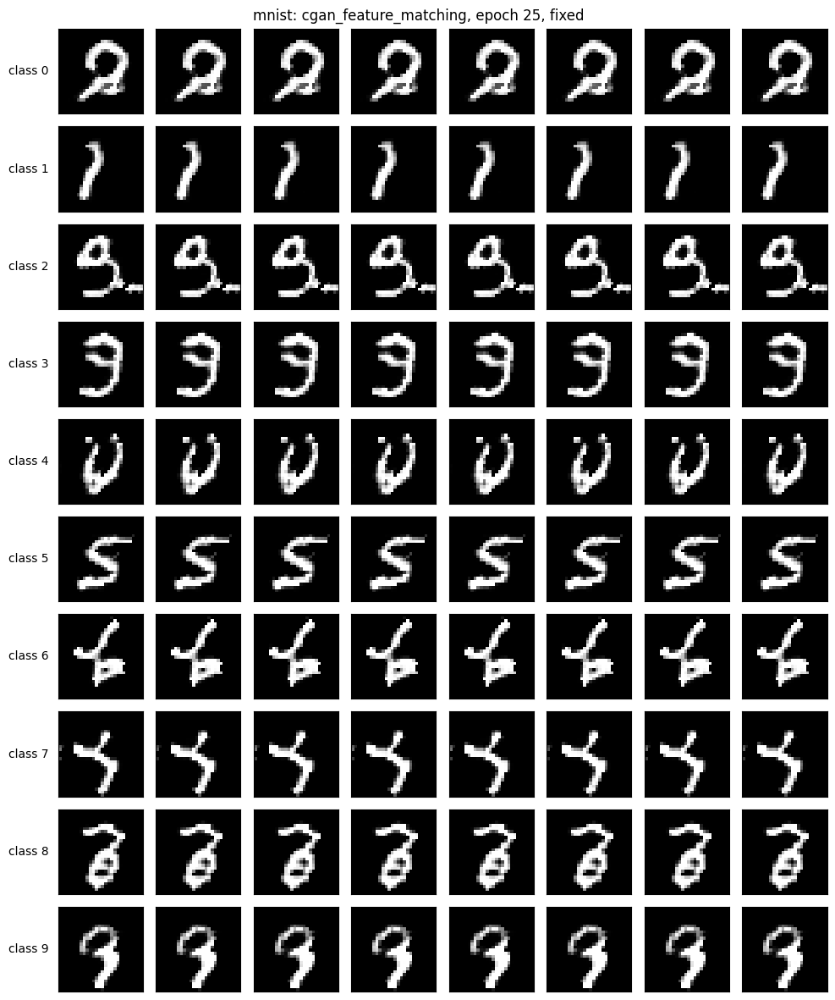

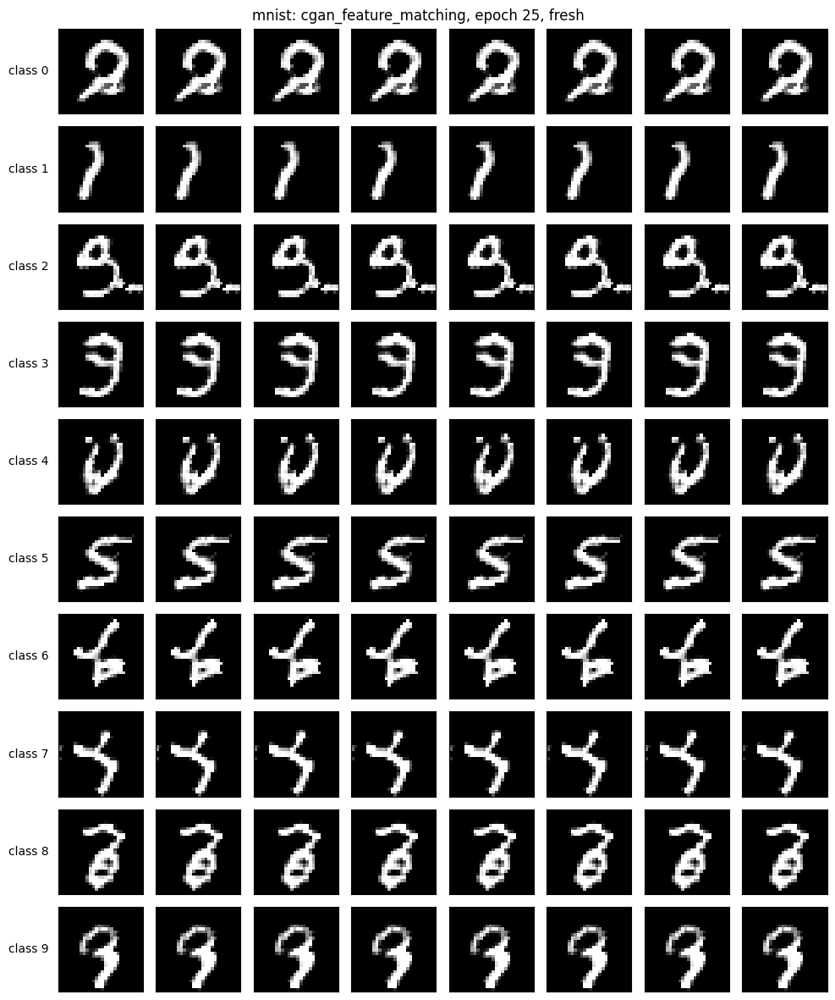

mnist cgan_feature_matching | 26/40 | G total 0.868, adv 0.825, FM 0.00424, D 0.633
mnist cgan_feature_matching | 27/40 | G total 0.837, adv 0.793, FM 0.00435, D 0.651
mnist cgan_feature_matching | 28/40 | G total 0.820, adv 0.780, FM 0.00398, D 0.652
mnist cgan_feature_matching | 29/40 | G total 0.851, adv 0.809, FM 0.00424, D 0.635
mnist cgan_feature_matching | 30/40 | G total 0.896, adv 0.840, FM 0.00557, D 0.618


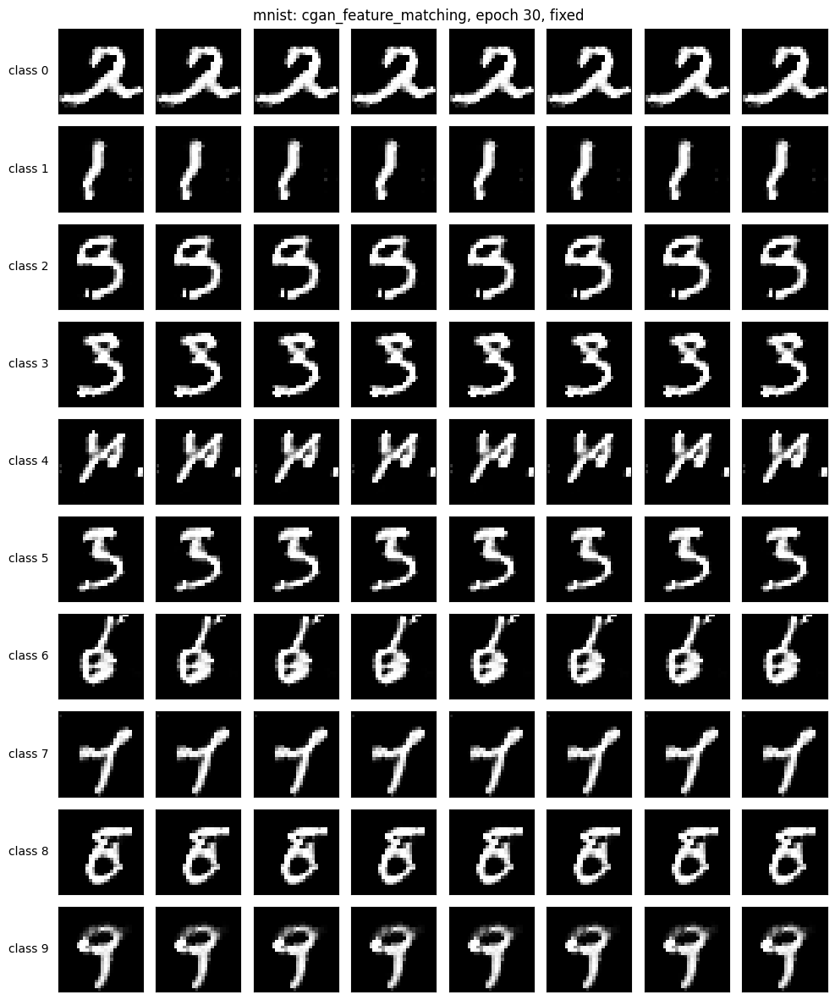

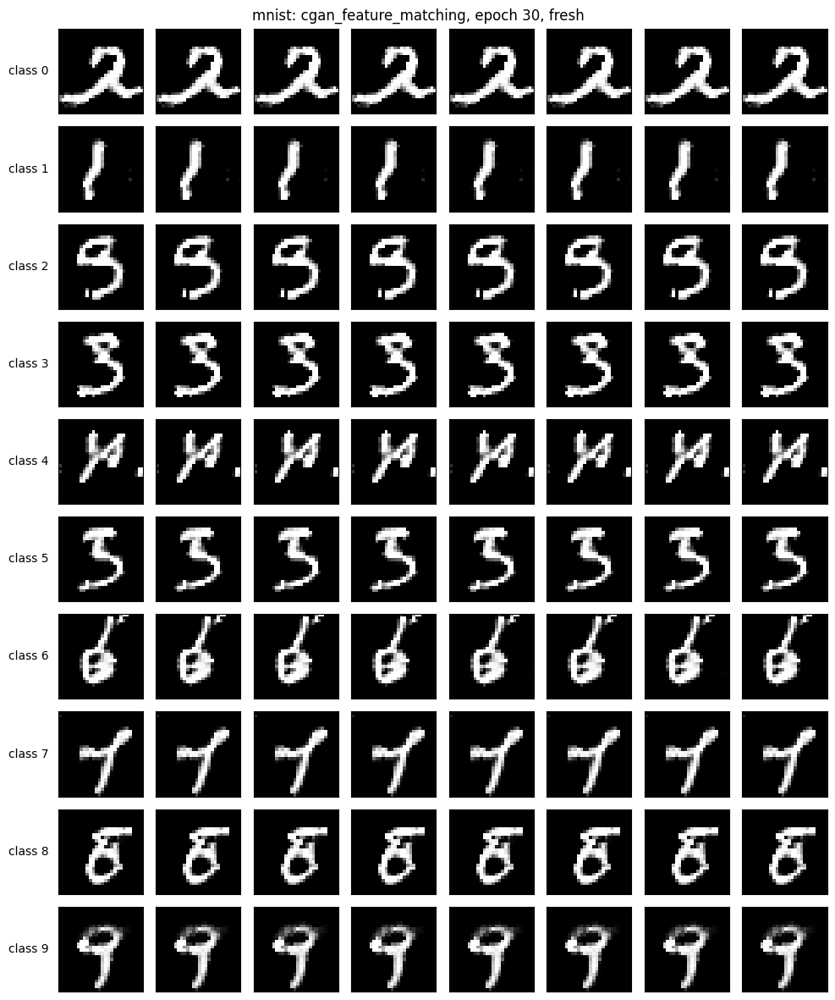

mnist cgan_feature_matching | 31/40 | G total 0.891, adv 0.835, FM 0.00566, D 0.631
mnist cgan_feature_matching | 32/40 | G total 0.886, adv 0.824, FM 0.00630, D 0.641
mnist cgan_feature_matching | 33/40 | G total 0.926, adv 0.857, FM 0.00684, D 0.611
mnist cgan_feature_matching | 34/40 | G total 0.959, adv 0.880, FM 0.00793, D 0.601
mnist cgan_feature_matching | 35/40 | G total 0.962, adv 0.881, FM 0.00808, D 0.616


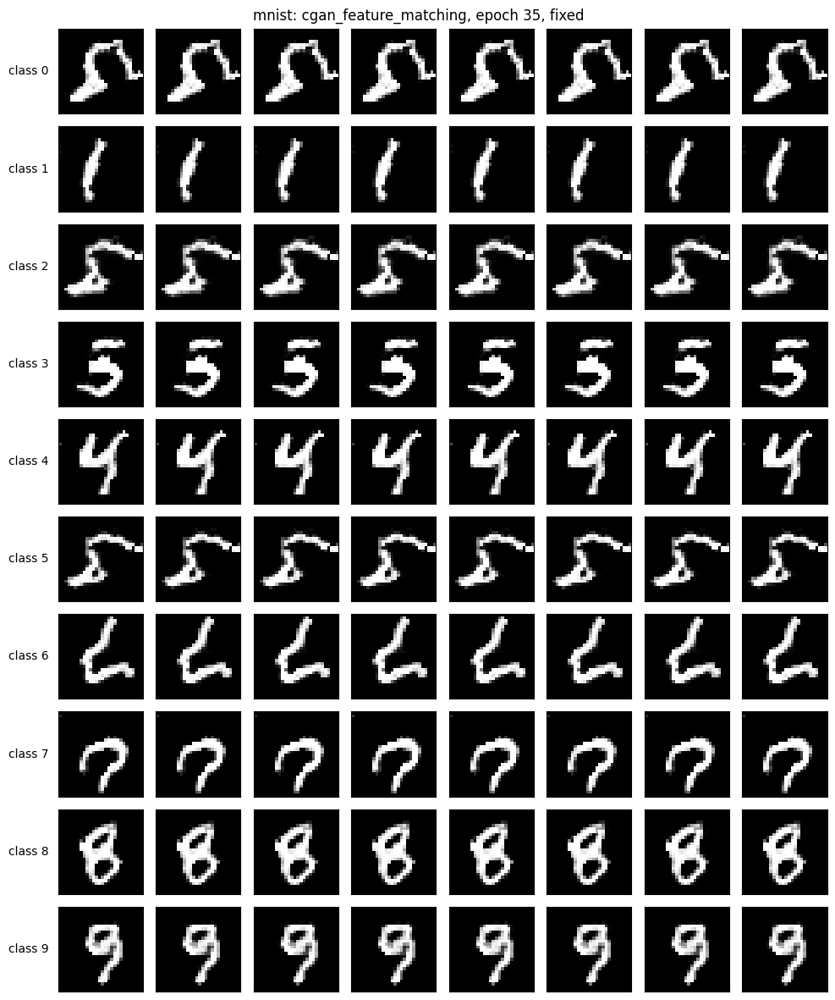

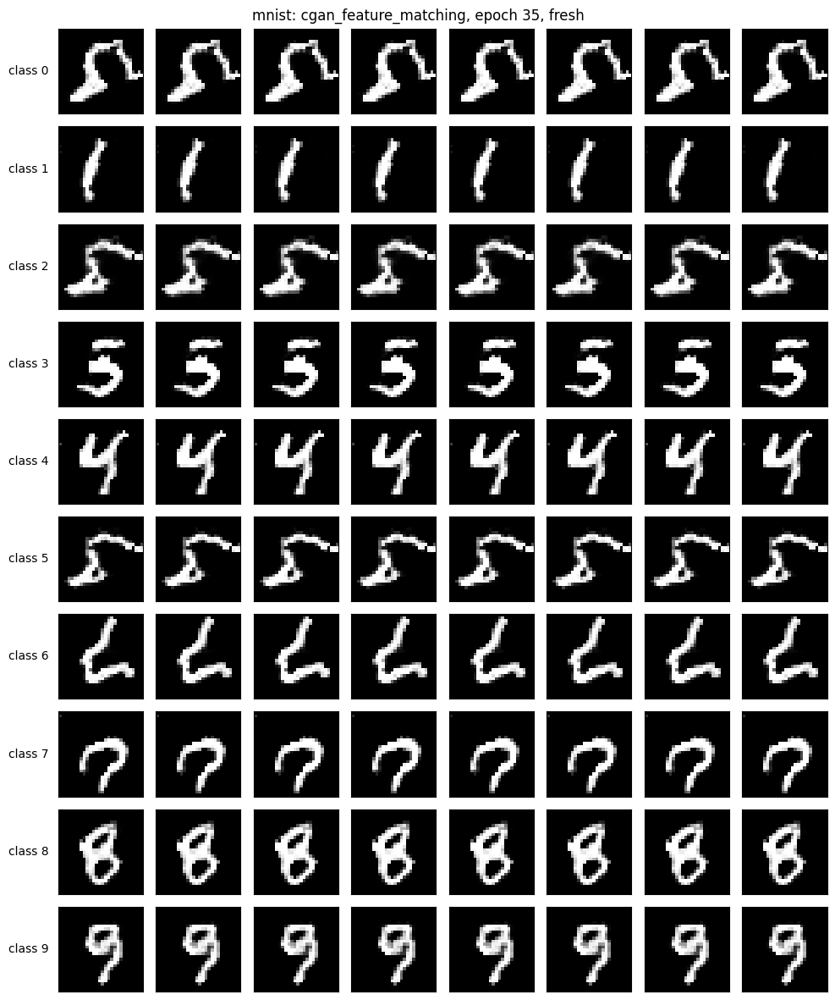

mnist cgan_feature_matching | 36/40 | G total 0.895, adv 0.816, FM 0.00790, D 0.655
mnist cgan_feature_matching | 37/40 | G total 0.901, adv 0.815, FM 0.00860, D 0.637
mnist cgan_feature_matching | 38/40 | G total 0.913, adv 0.834, FM 0.00792, D 0.625
mnist cgan_feature_matching | 39/40 | G total 0.913, adv 0.820, FM 0.00934, D 0.639
mnist cgan_feature_matching | 40/40 | G total 0.894, adv 0.805, FM 0.00890, D 0.642


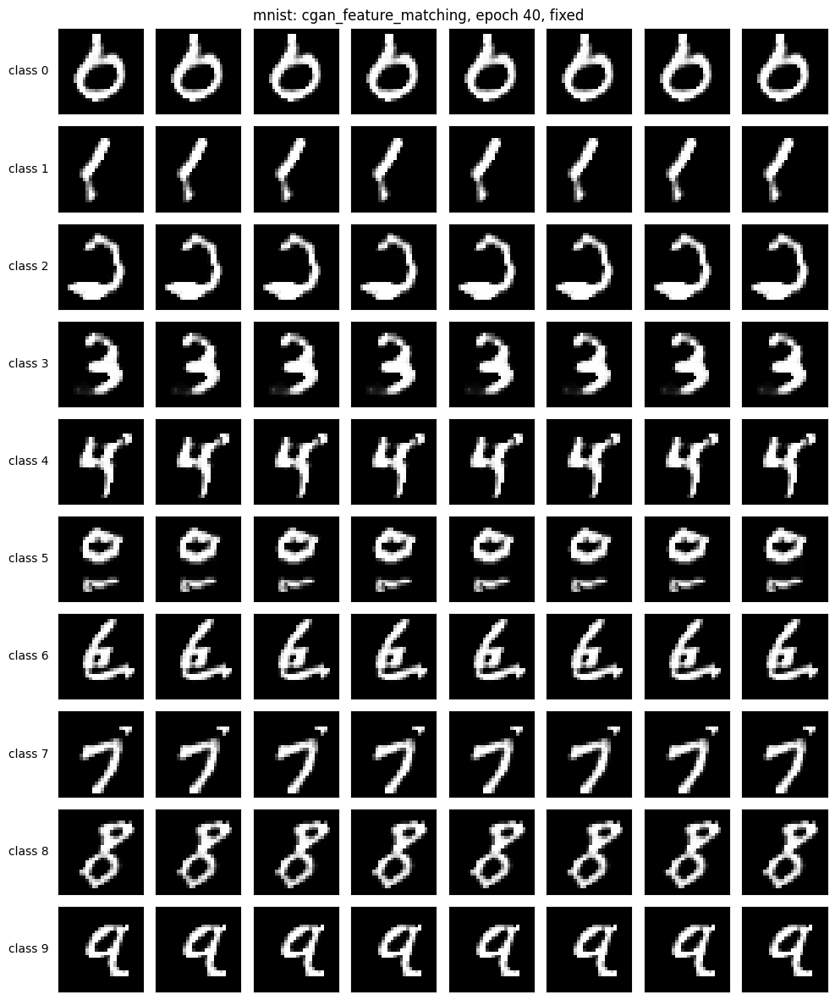

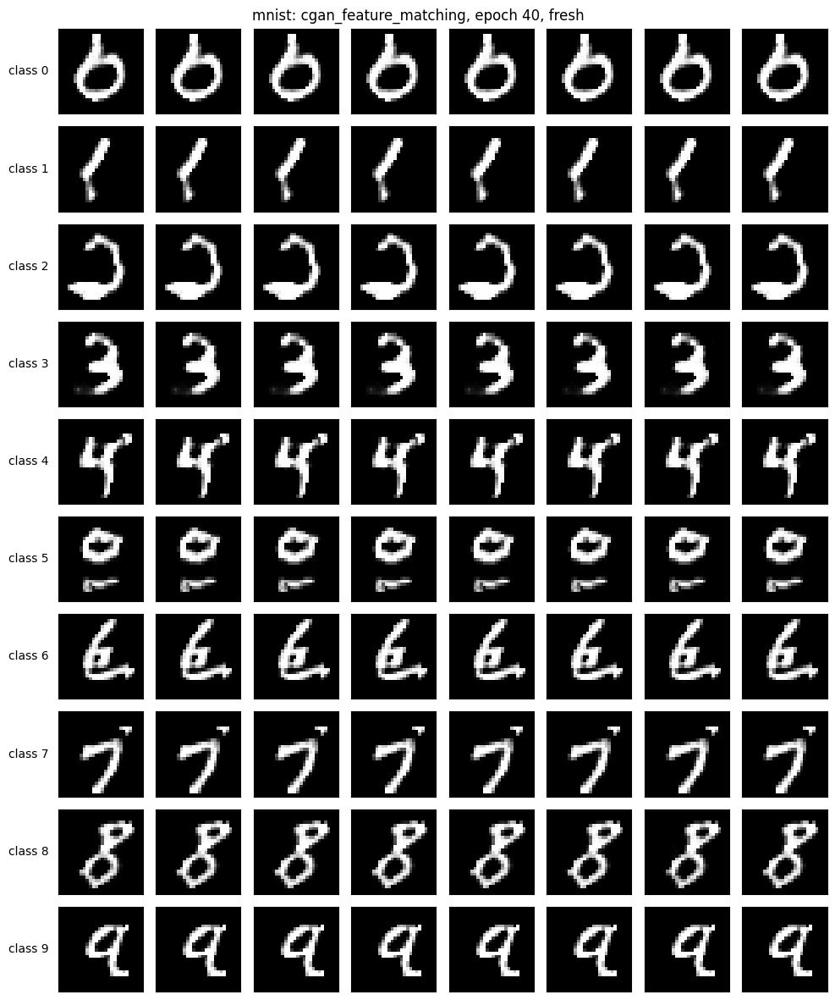

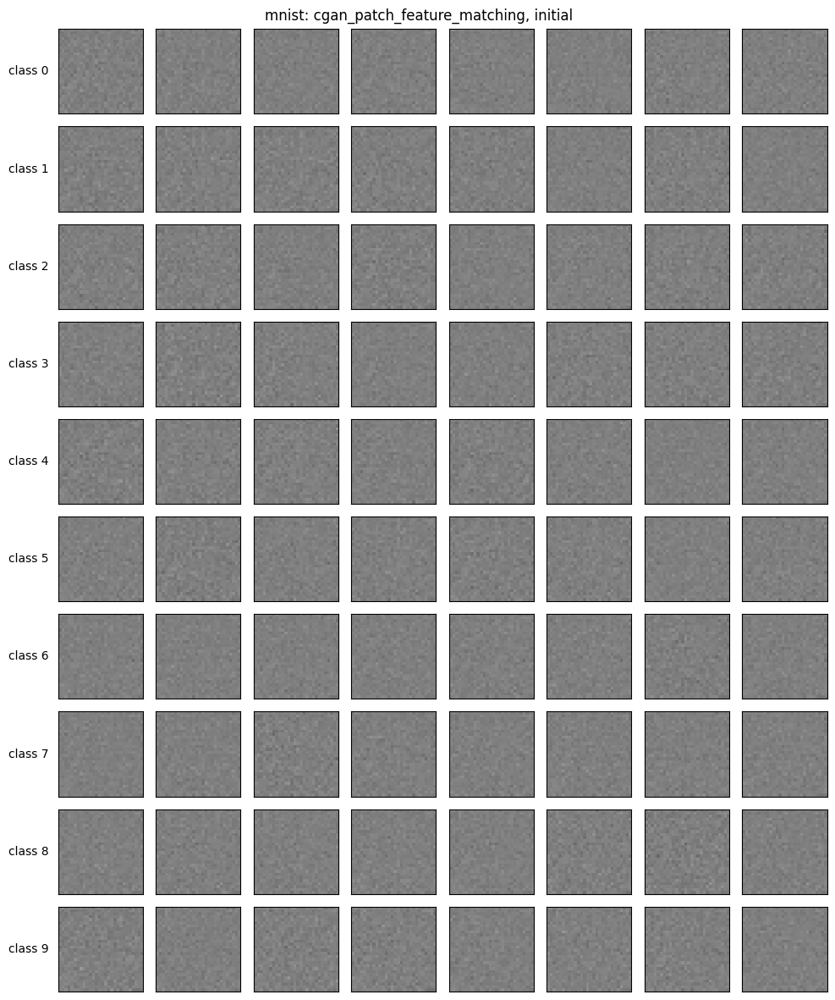

mnist cgan_patch_feature_matching | 1/40 | G total 0.870, adv 0.844, FM 0.00253, D 0.632


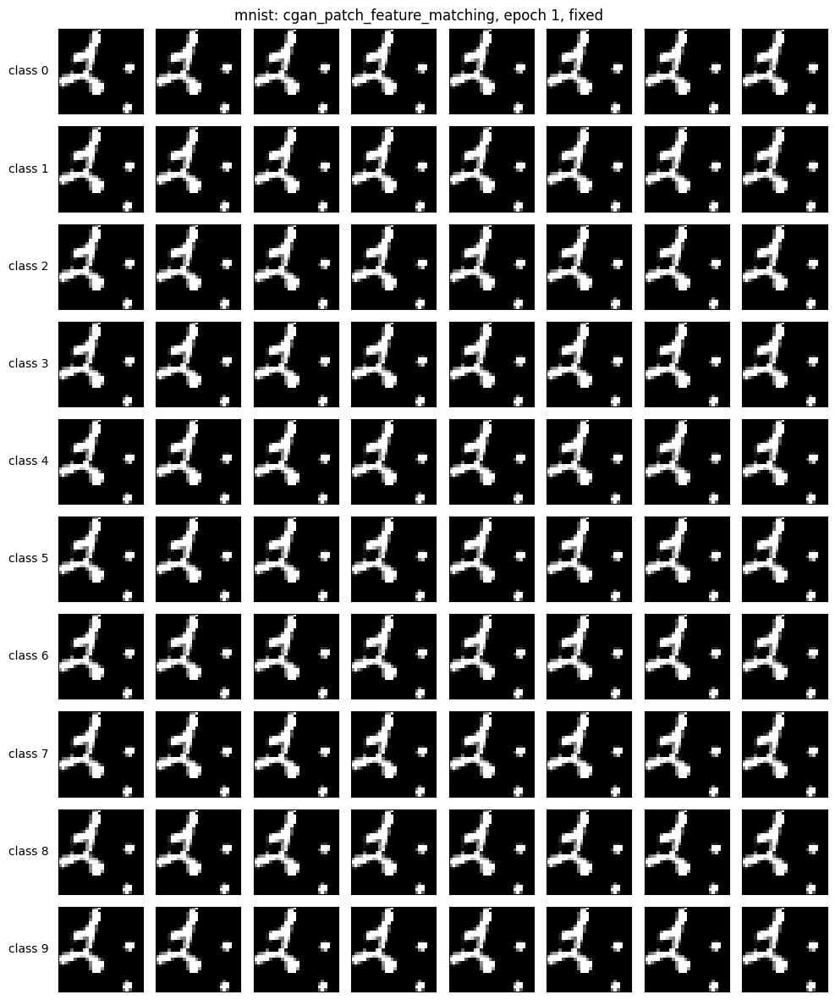

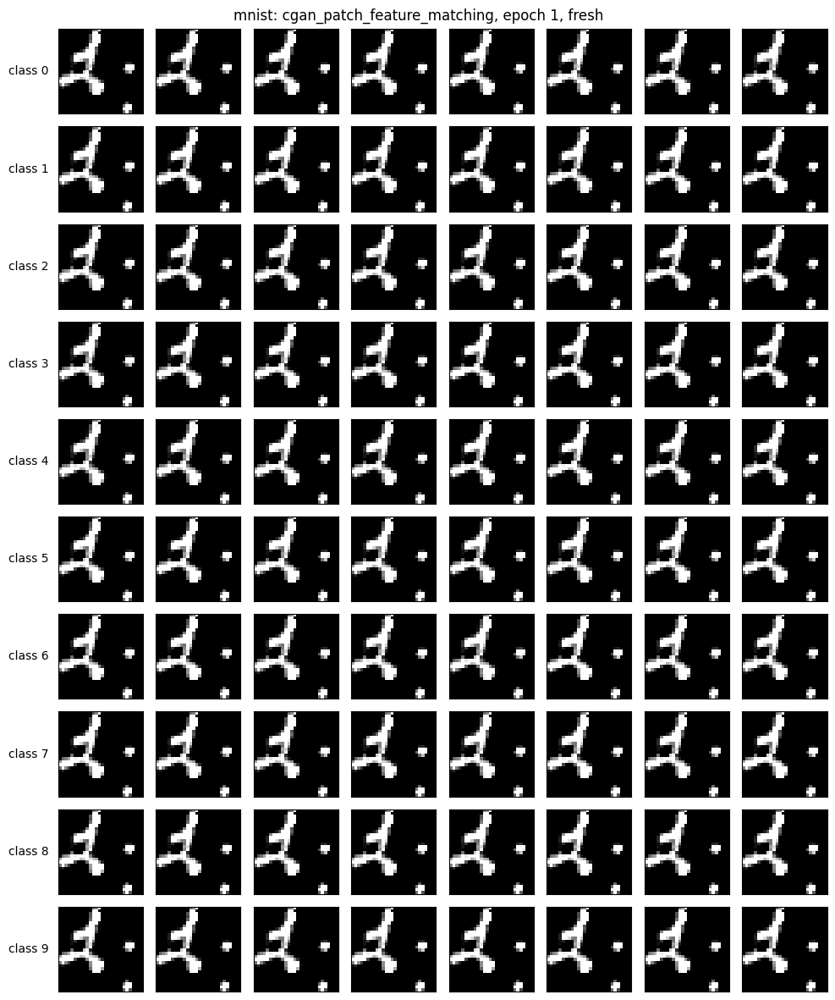

mnist cgan_patch_feature_matching | 2/40 | G total 0.862, adv 0.845, FM 0.00171, D 0.626
mnist cgan_patch_feature_matching | 3/40 | G total 0.792, adv 0.780, FM 0.00117, D 0.655
mnist cgan_patch_feature_matching | 4/40 | G total 0.789, adv 0.782, FM 0.00063, D 0.655
mnist cgan_patch_feature_matching | 5/40 | G total 0.795, adv 0.787, FM 0.00075, D 0.656


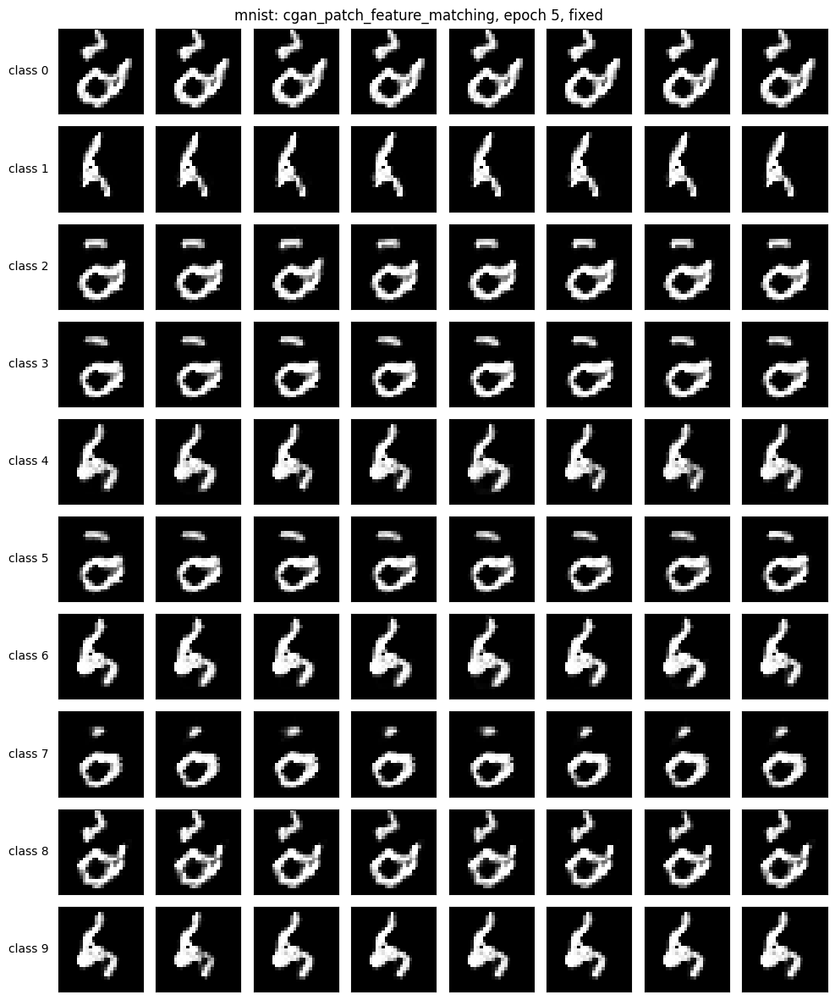

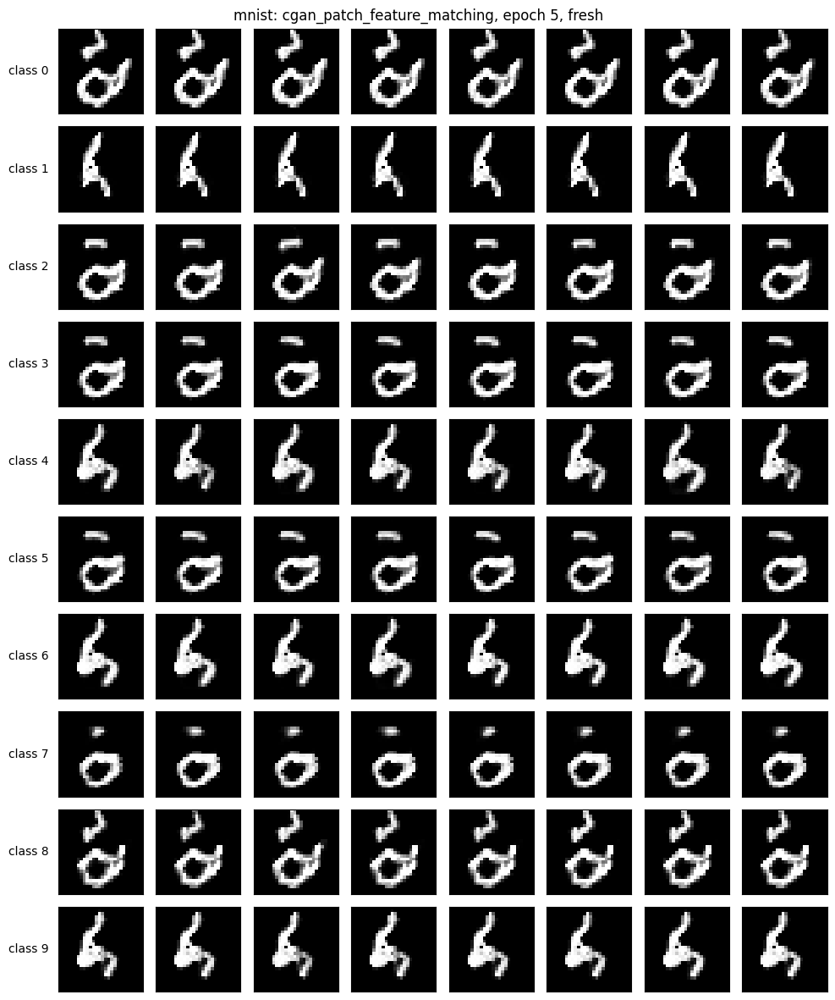

mnist cgan_patch_feature_matching | 6/40 | G total 0.789, adv 0.780, FM 0.00087, D 0.655
mnist cgan_patch_feature_matching | 7/40 | G total 0.802, adv 0.791, FM 0.00112, D 0.650
mnist cgan_patch_feature_matching | 8/40 | G total 0.803, adv 0.791, FM 0.00118, D 0.653
mnist cgan_patch_feature_matching | 9/40 | G total 0.798, adv 0.787, FM 0.00114, D 0.653
mnist cgan_patch_feature_matching | 10/40 | G total 0.807, adv 0.796, FM 0.00115, D 0.648


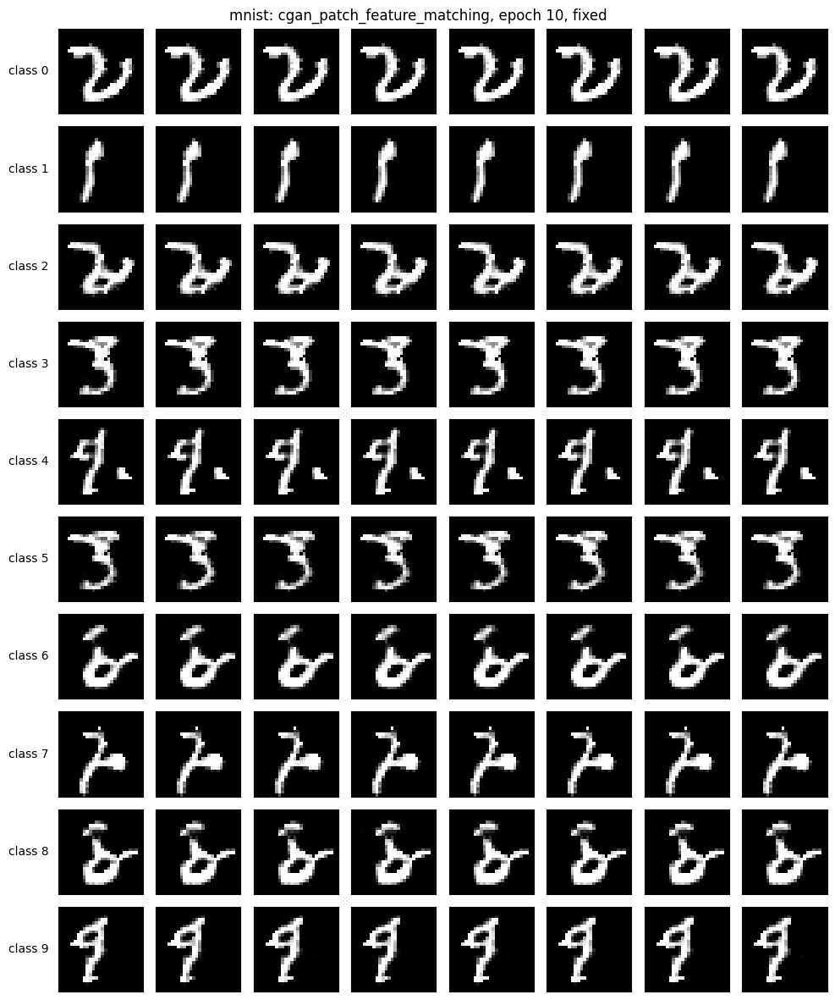

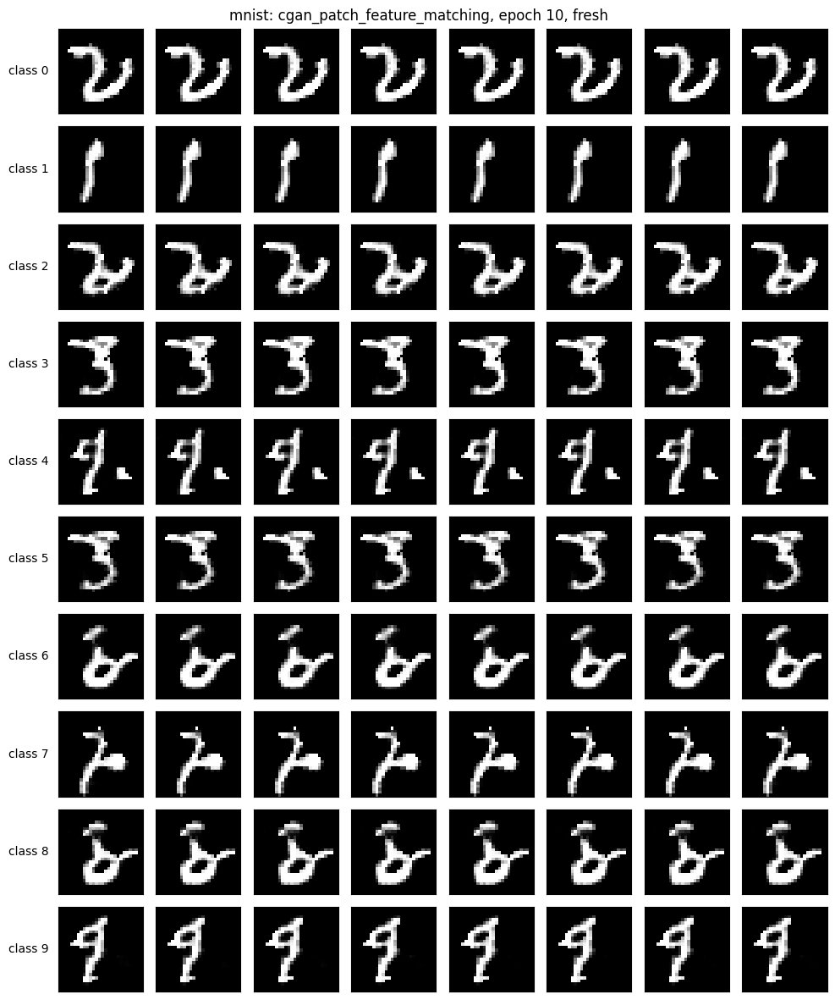

mnist cgan_patch_feature_matching | 11/40 | G total 0.803, adv 0.793, FM 0.00101, D 0.651
mnist cgan_patch_feature_matching | 12/40 | G total 0.798, adv 0.788, FM 0.00099, D 0.654
mnist cgan_patch_feature_matching | 13/40 | G total 0.808, adv 0.797, FM 0.00114, D 0.650
mnist cgan_patch_feature_matching | 14/40 | G total 0.797, adv 0.786, FM 0.00111, D 0.654
mnist cgan_patch_feature_matching | 15/40 | G total 0.804, adv 0.794, FM 0.00105, D 0.651


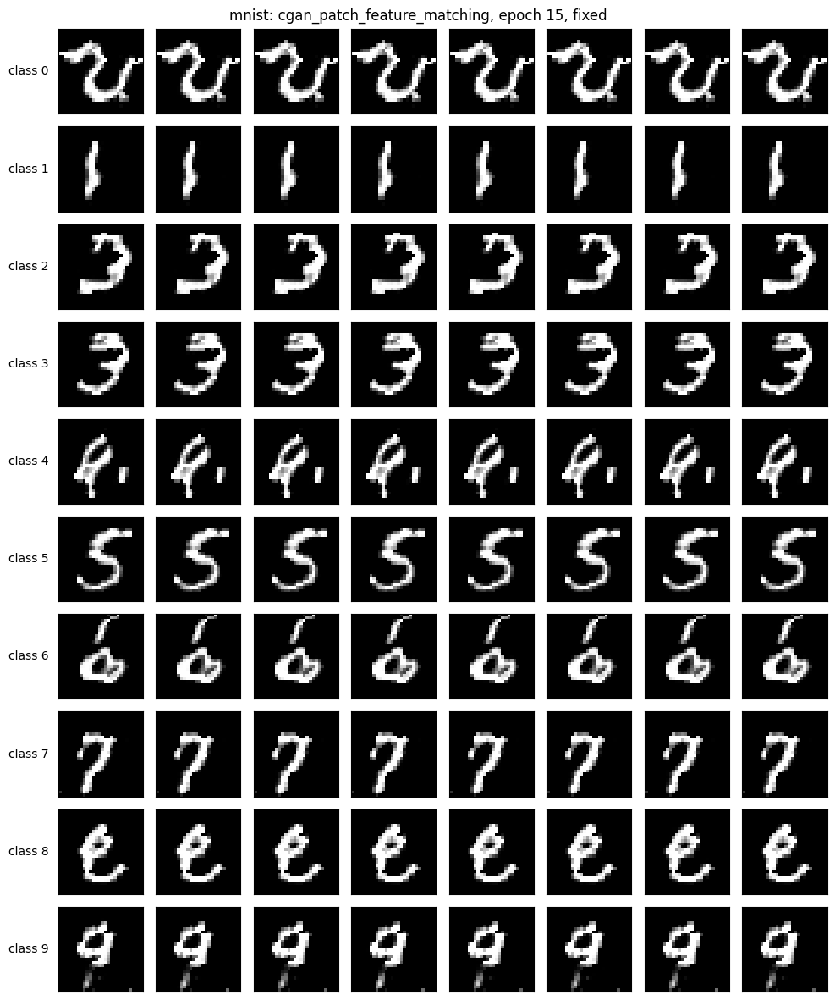

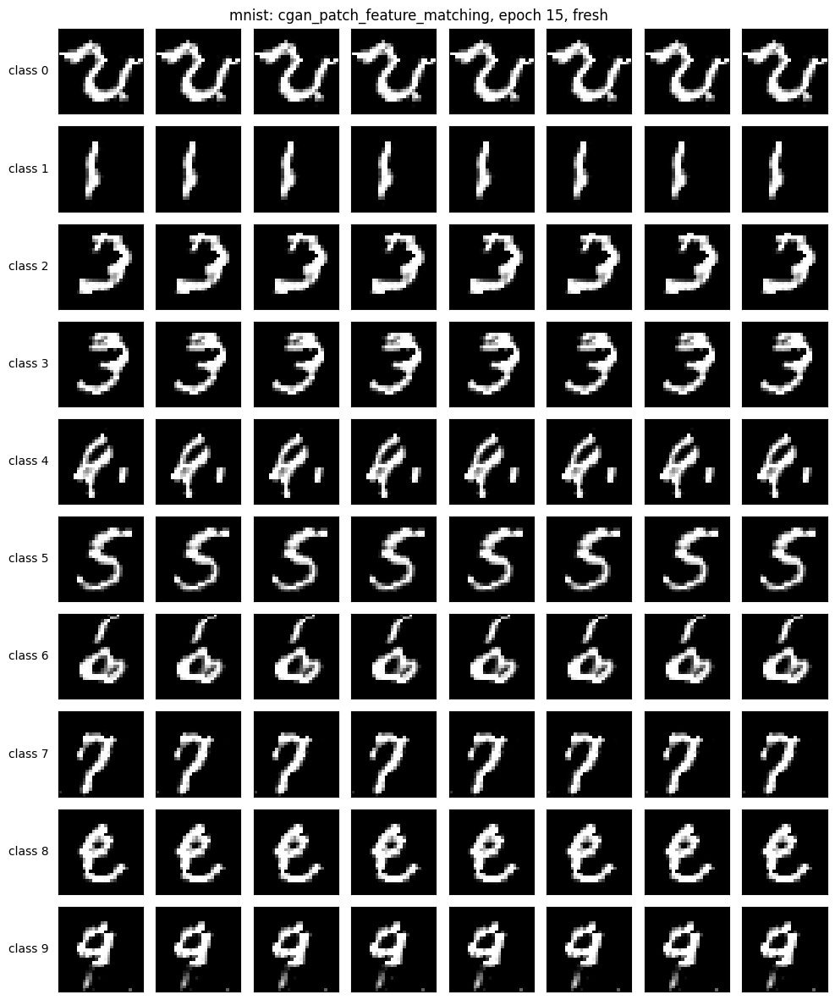

mnist cgan_patch_feature_matching | 16/40 | G total 0.816, adv 0.805, FM 0.00103, D 0.643
mnist cgan_patch_feature_matching | 17/40 | G total 0.811, adv 0.800, FM 0.00111, D 0.646
mnist cgan_patch_feature_matching | 18/40 | G total 0.828, adv 0.817, FM 0.00110, D 0.639
mnist cgan_patch_feature_matching | 19/40 | G total 0.819, adv 0.809, FM 0.00104, D 0.643
mnist cgan_patch_feature_matching | 20/40 | G total 0.815, adv 0.805, FM 0.00108, D 0.648


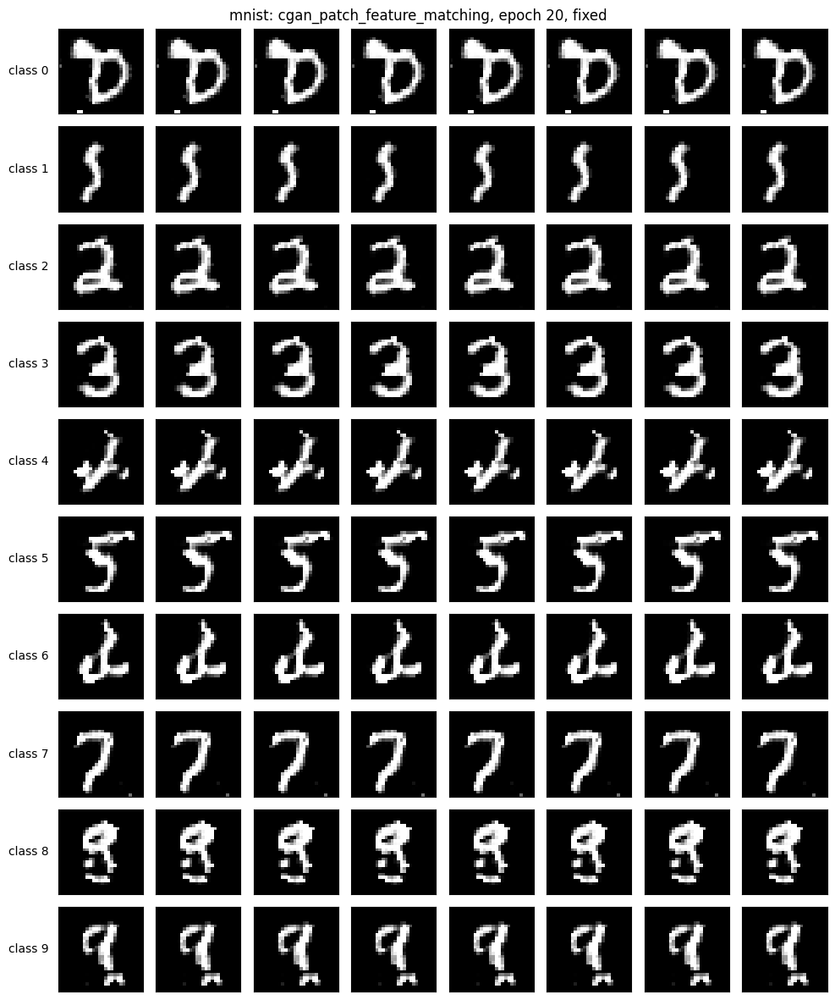

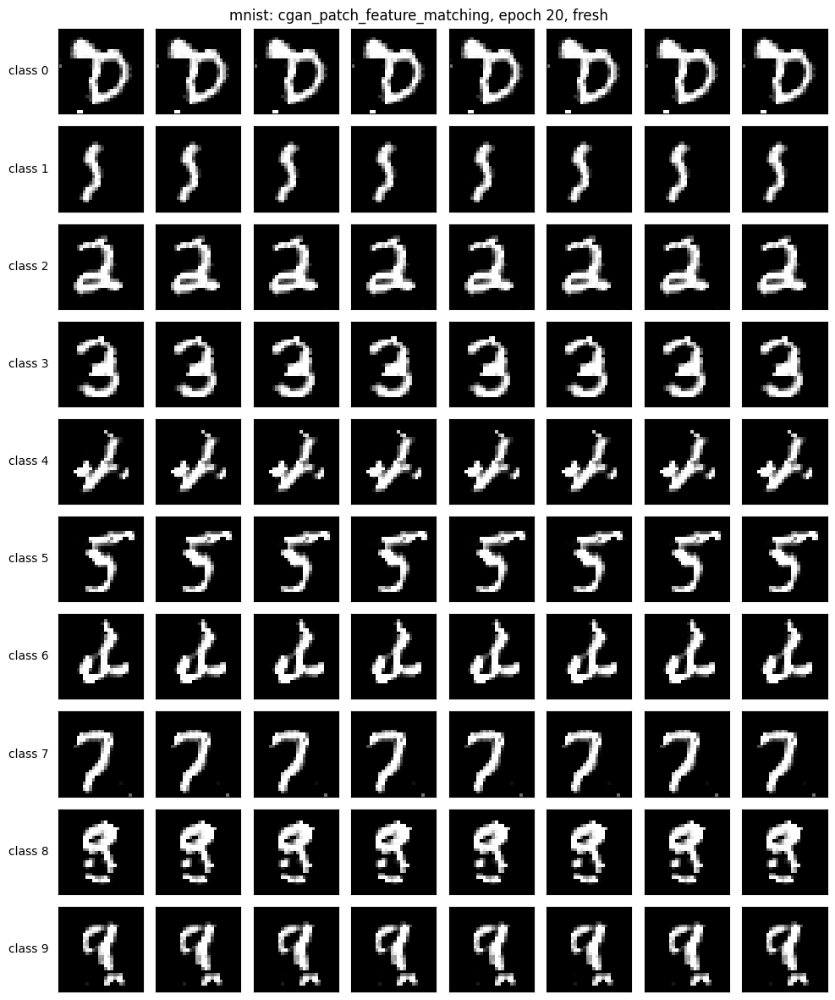

mnist cgan_patch_feature_matching | 21/40 | G total 0.792, adv 0.781, FM 0.00114, D 0.660
mnist cgan_patch_feature_matching | 22/40 | G total 0.788, adv 0.778, FM 0.00098, D 0.658
mnist cgan_patch_feature_matching | 23/40 | G total 0.790, adv 0.780, FM 0.00099, D 0.658
mnist cgan_patch_feature_matching | 24/40 | G total 0.789, adv 0.779, FM 0.00100, D 0.659
mnist cgan_patch_feature_matching | 25/40 | G total 0.781, adv 0.771, FM 0.00093, D 0.662


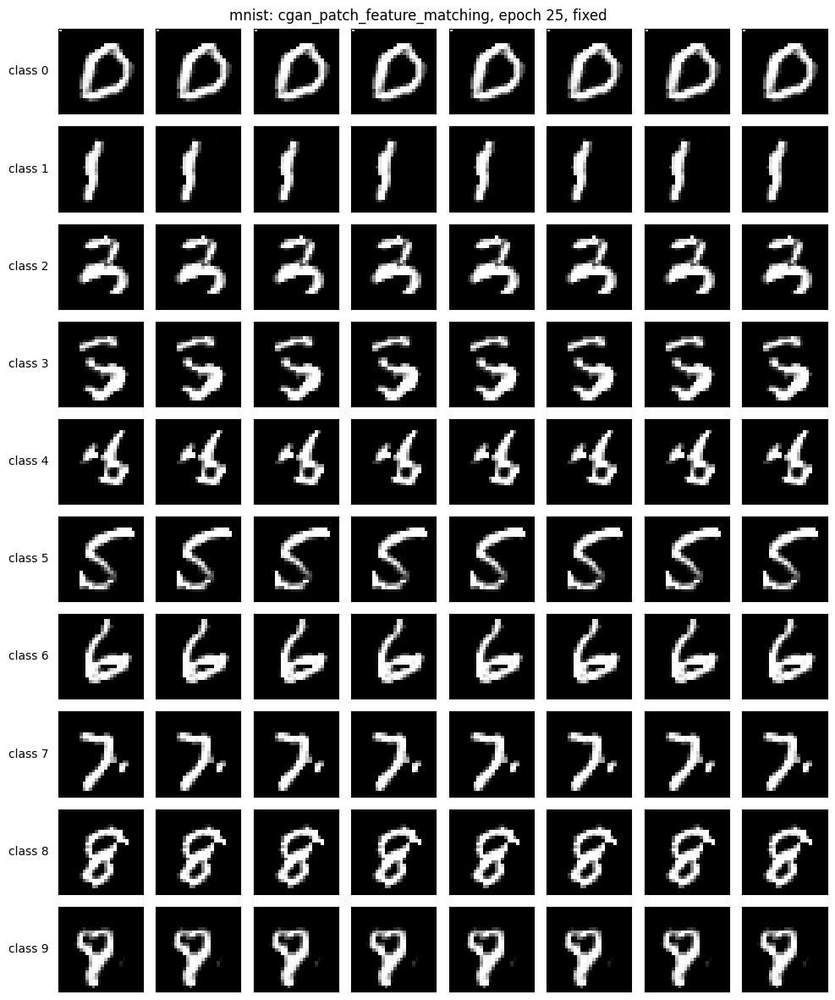

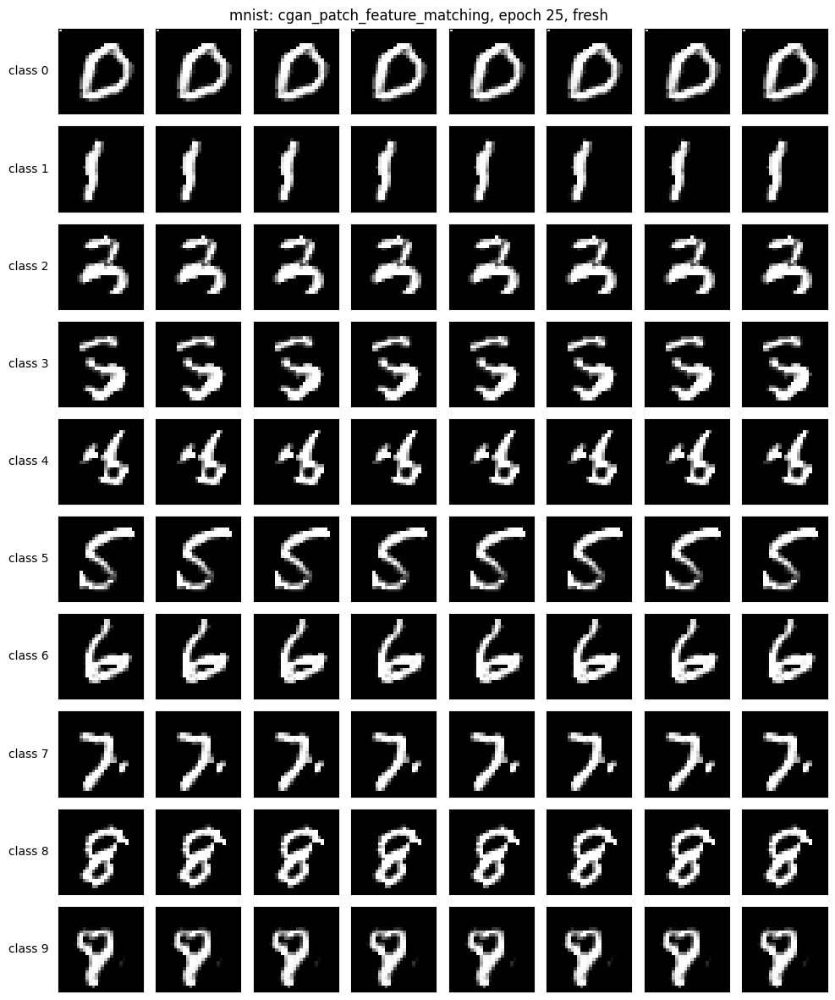

mnist cgan_patch_feature_matching | 26/40 | G total 0.779, adv 0.769, FM 0.00102, D 0.665
mnist cgan_patch_feature_matching | 27/40 | G total 0.769, adv 0.760, FM 0.00095, D 0.668
mnist cgan_patch_feature_matching | 28/40 | G total 0.774, adv 0.764, FM 0.00097, D 0.665
mnist cgan_patch_feature_matching | 29/40 | G total 0.770, adv 0.760, FM 0.00090, D 0.668
mnist cgan_patch_feature_matching | 30/40 | G total 0.780, adv 0.771, FM 0.00083, D 0.664


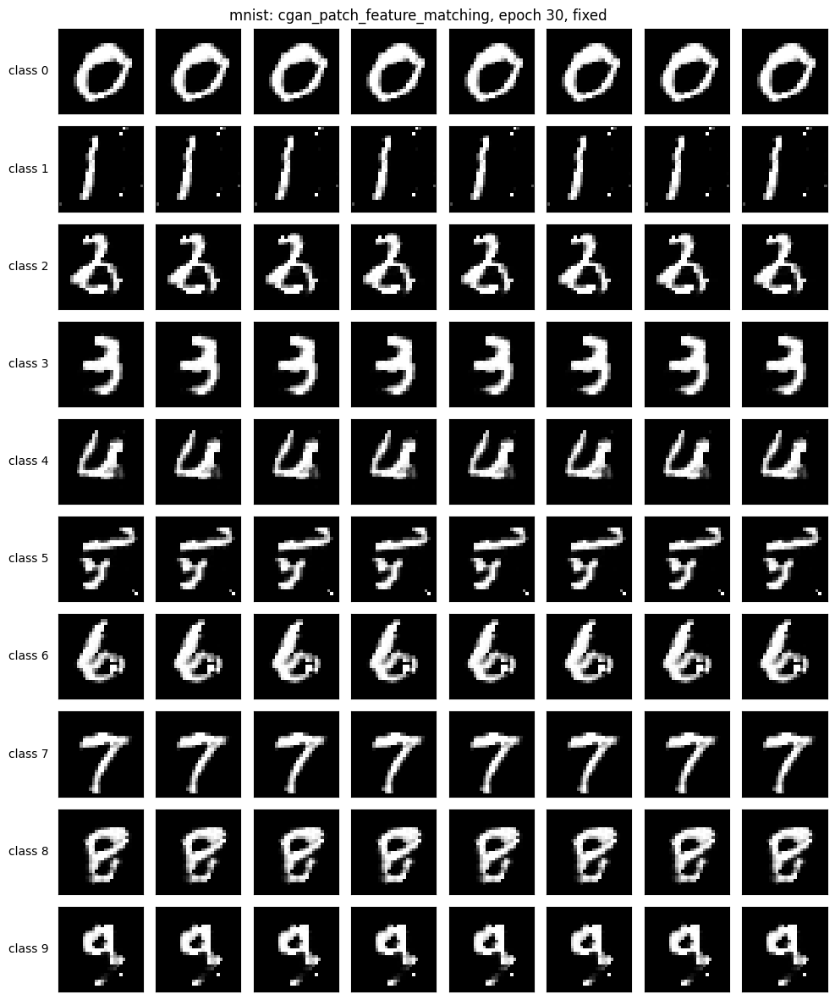

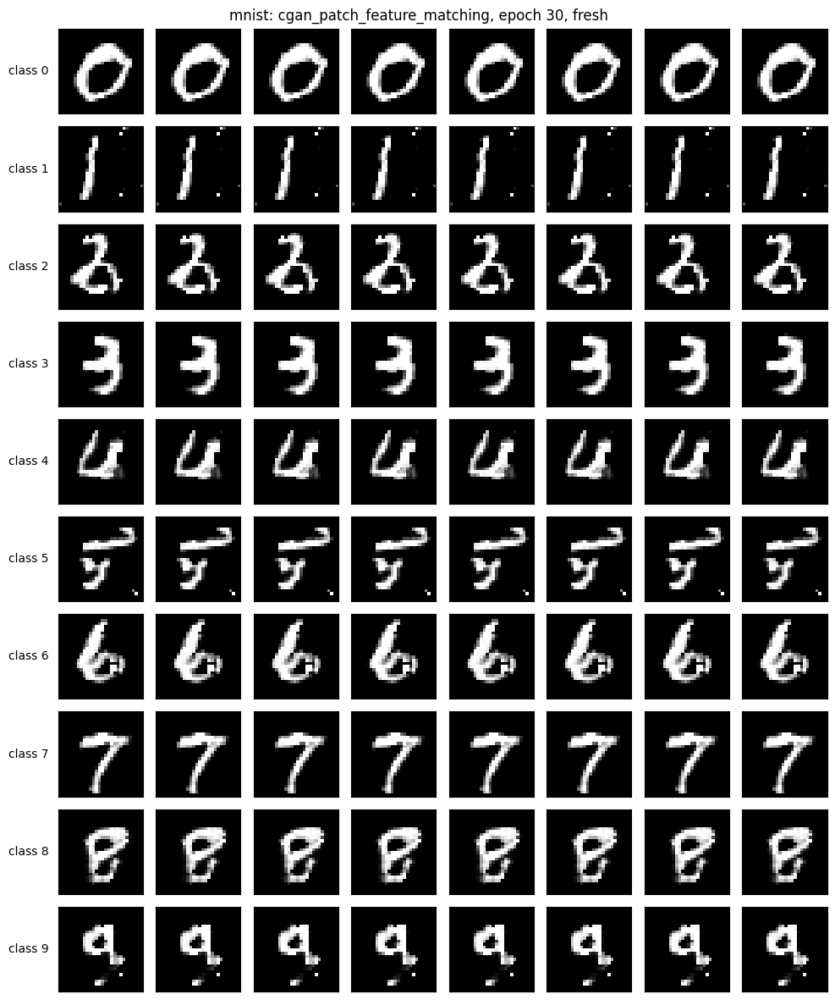

mnist cgan_patch_feature_matching | 31/40 | G total 0.763, adv 0.756, FM 0.00072, D 0.671
mnist cgan_patch_feature_matching | 32/40 | G total 0.762, adv 0.755, FM 0.00075, D 0.670
mnist cgan_patch_feature_matching | 33/40 | G total 0.772, adv 0.765, FM 0.00069, D 0.663
mnist cgan_patch_feature_matching | 34/40 | G total 0.760, adv 0.753, FM 0.00065, D 0.671
mnist cgan_patch_feature_matching | 35/40 | G total 0.759, adv 0.753, FM 0.00058, D 0.669


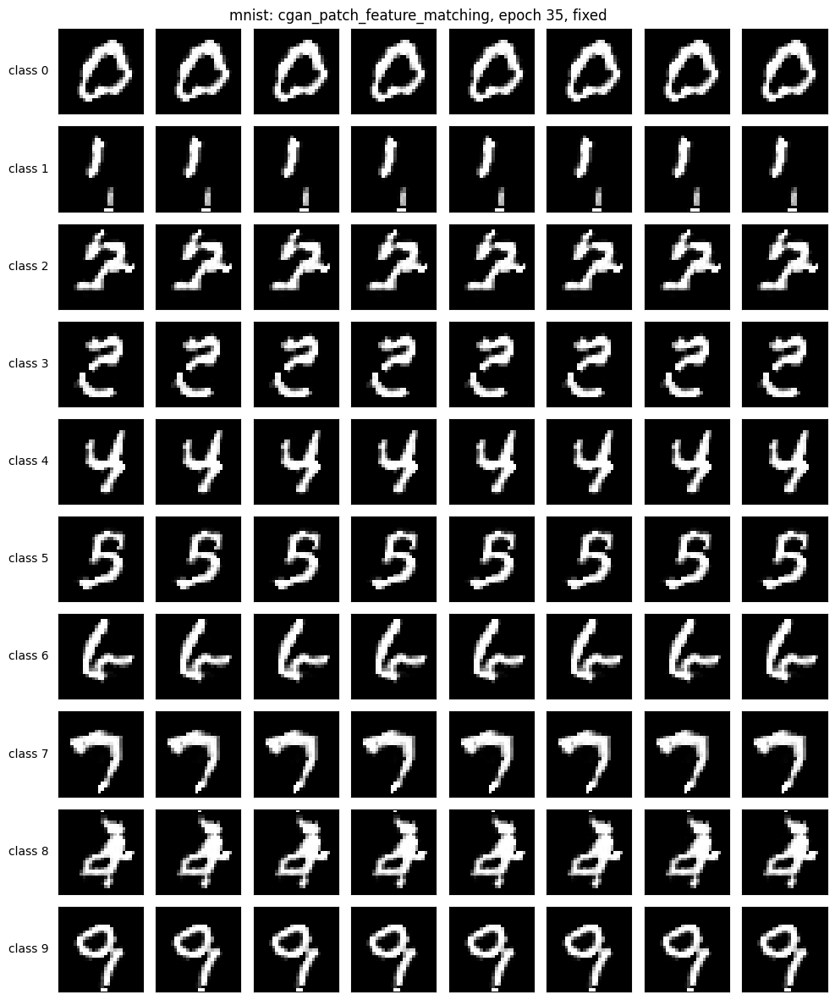

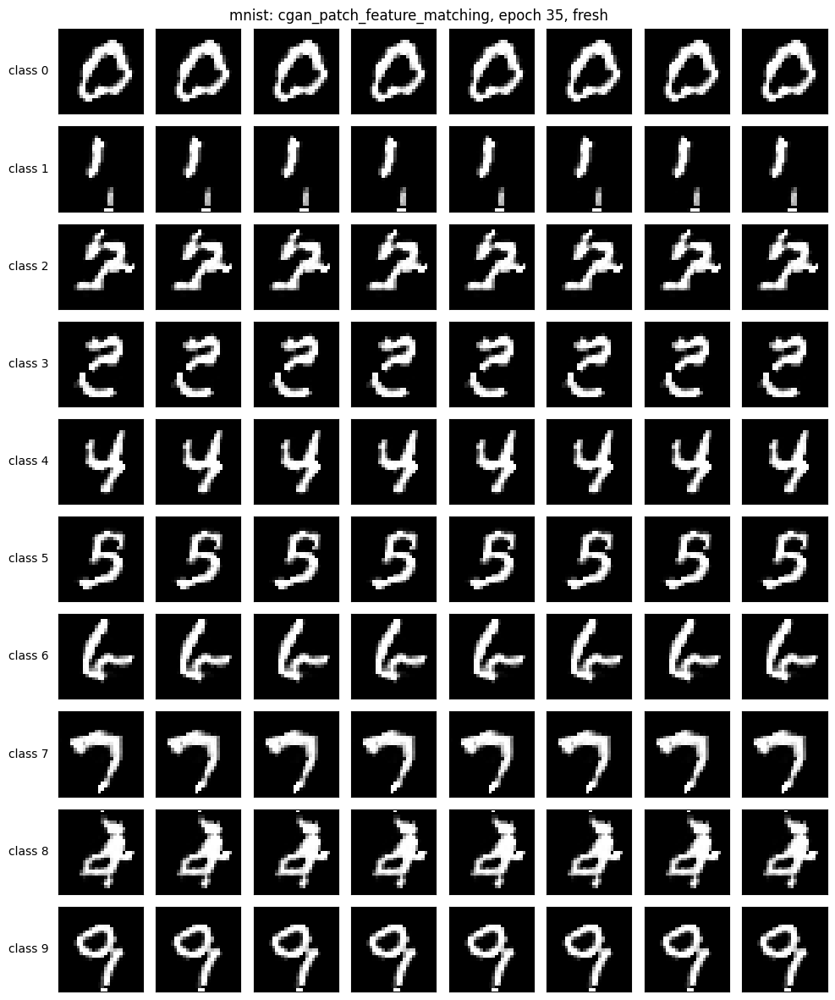

mnist cgan_patch_feature_matching | 36/40 | G total 0.783, adv 0.776, FM 0.00071, D 0.659
mnist cgan_patch_feature_matching | 37/40 | G total 0.783, adv 0.774, FM 0.00082, D 0.662
mnist cgan_patch_feature_matching | 38/40 | G total 0.770, adv 0.763, FM 0.00065, D 0.665
mnist cgan_patch_feature_matching | 39/40 | G total 0.775, adv 0.766, FM 0.00084, D 0.667
mnist cgan_patch_feature_matching | 40/40 | G total 0.765, adv 0.756, FM 0.00084, D 0.670


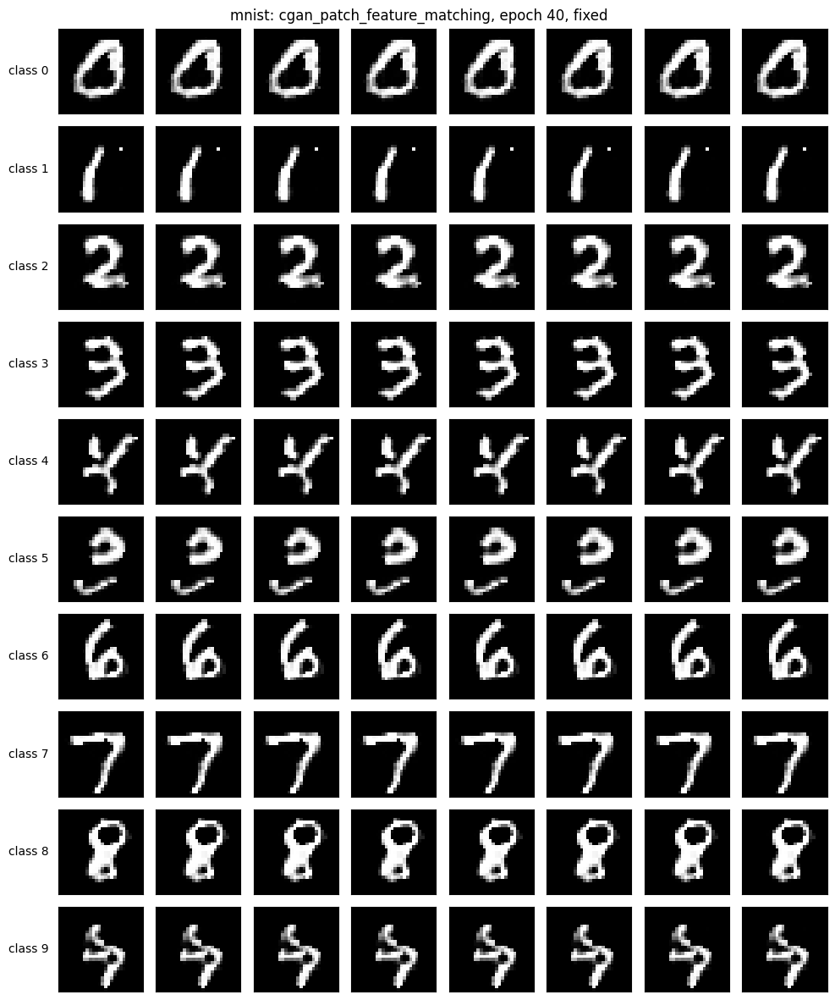

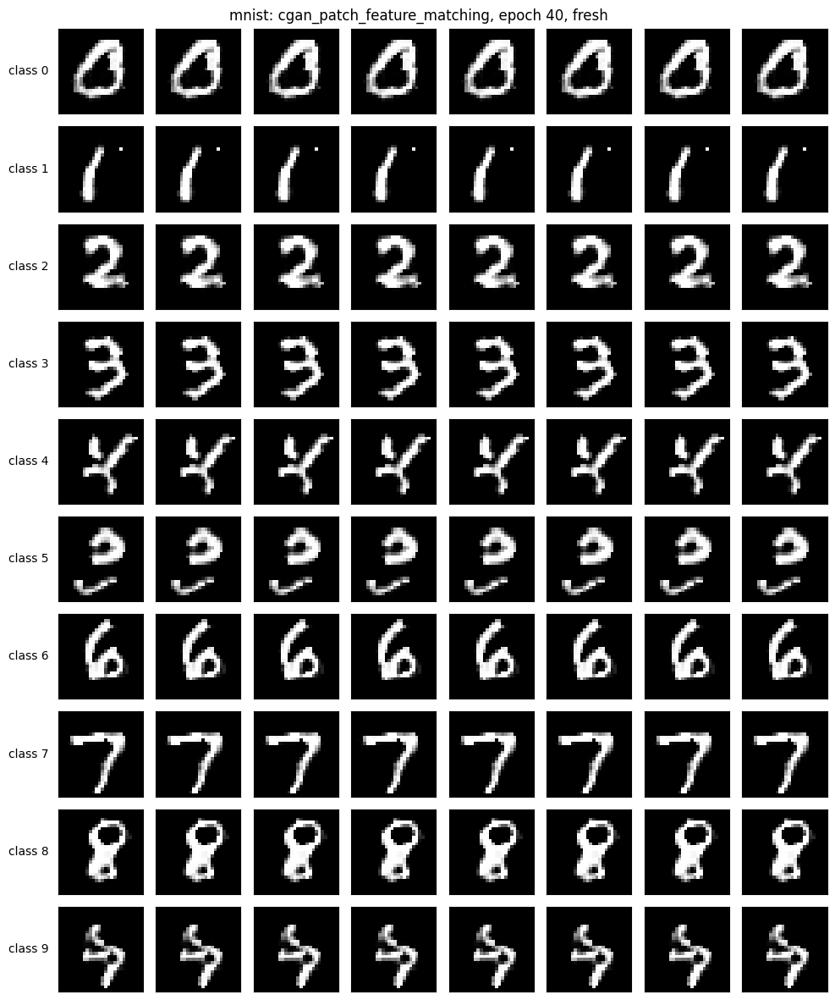

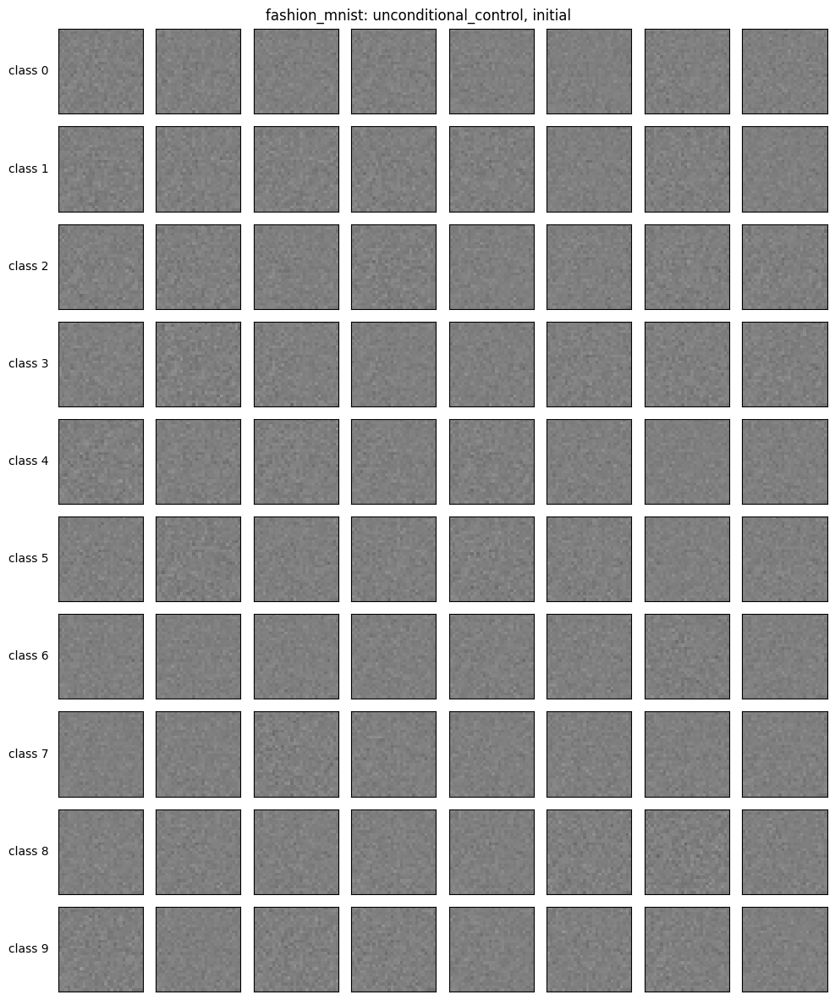

fashion_mnist unconditional_control | 1/40 | G total 0.781, adv 0.781, FM 0.00000, D 0.666


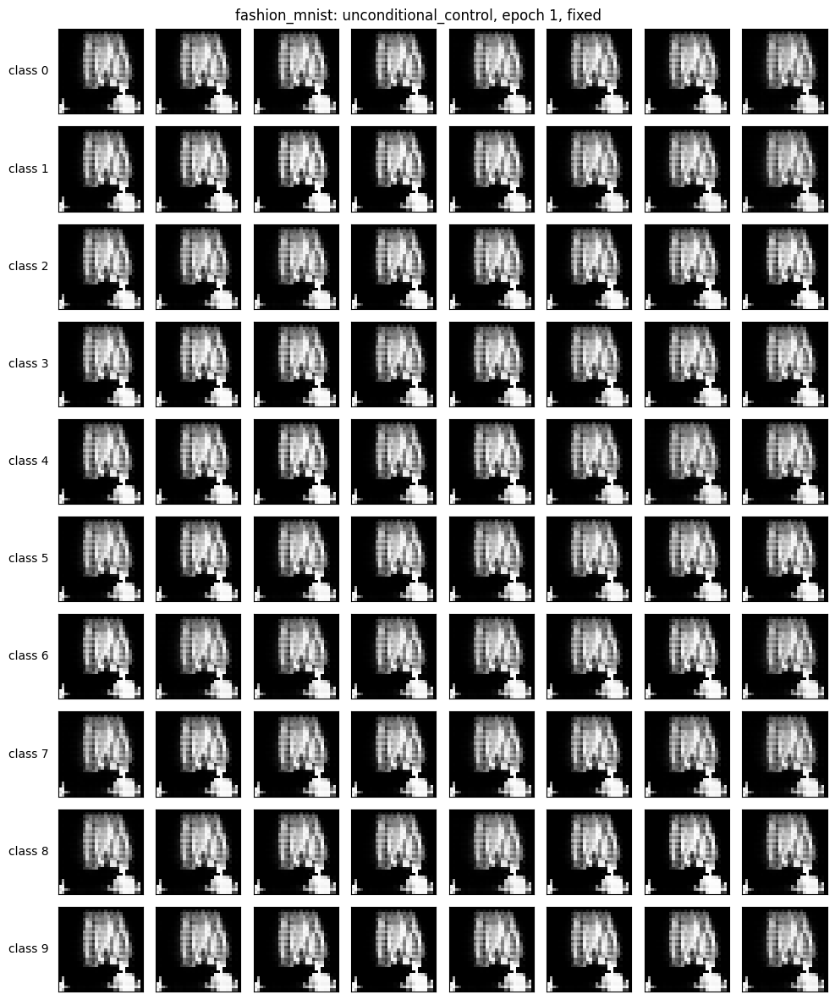

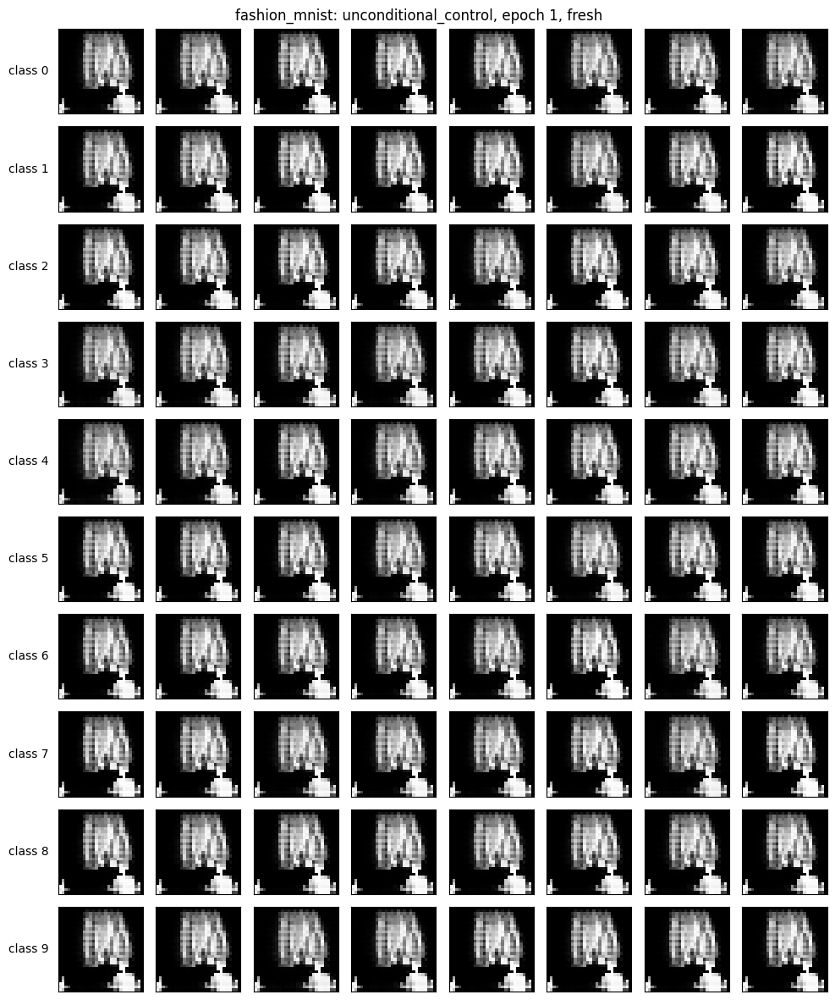

fashion_mnist unconditional_control | 2/40 | G total 0.737, adv 0.737, FM 0.00000, D 0.675
fashion_mnist unconditional_control | 3/40 | G total 0.755, adv 0.755, FM 0.00000, D 0.674
fashion_mnist unconditional_control | 4/40 | G total 0.779, adv 0.779, FM 0.00000, D 0.662
fashion_mnist unconditional_control | 5/40 | G total 0.793, adv 0.793, FM 0.00000, D 0.659


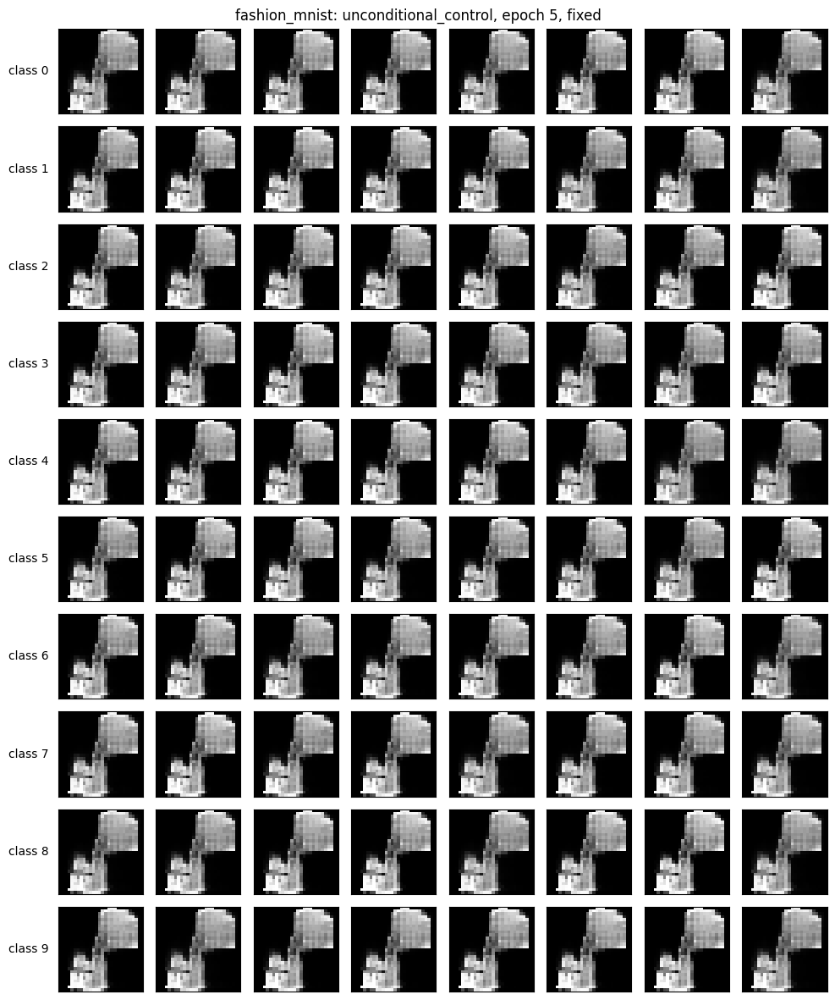

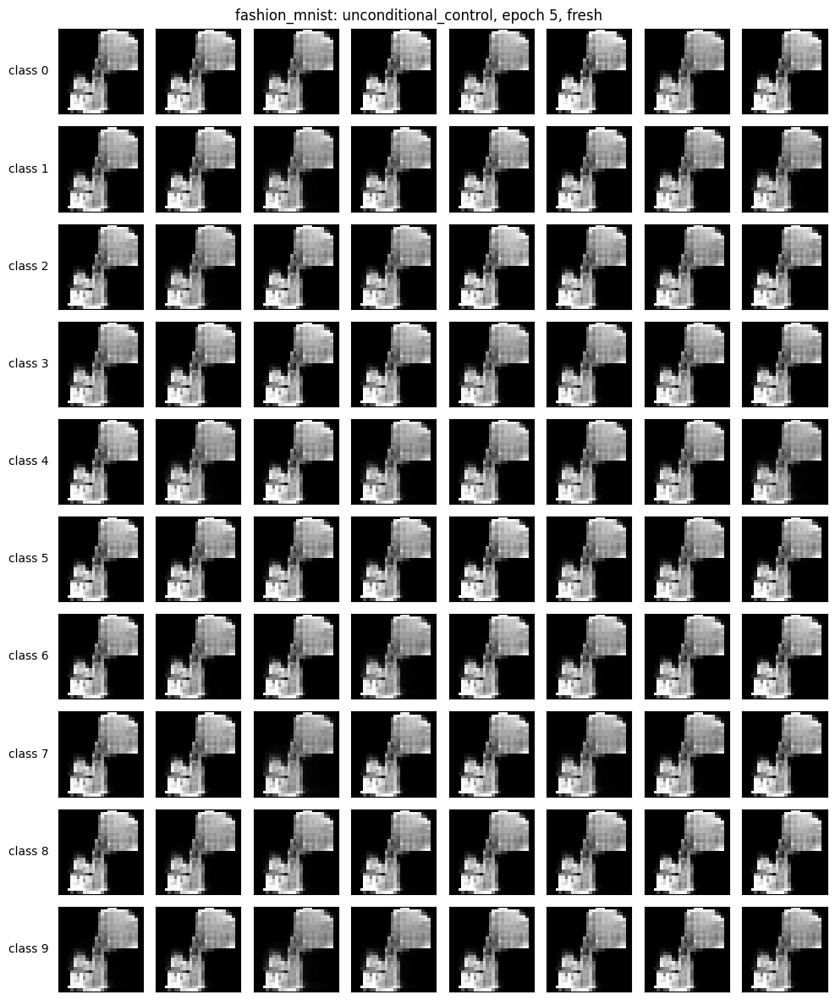

fashion_mnist unconditional_control | 6/40 | G total 0.799, adv 0.799, FM 0.00000, D 0.656
fashion_mnist unconditional_control | 7/40 | G total 0.871, adv 0.871, FM 0.00000, D 0.613
fashion_mnist unconditional_control | 8/40 | G total 0.905, adv 0.905, FM 0.00000, D 0.621
fashion_mnist unconditional_control | 9/40 | G total 0.804, adv 0.804, FM 0.00000, D 0.654
fashion_mnist unconditional_control | 10/40 | G total 0.794, adv 0.794, FM 0.00000, D 0.636


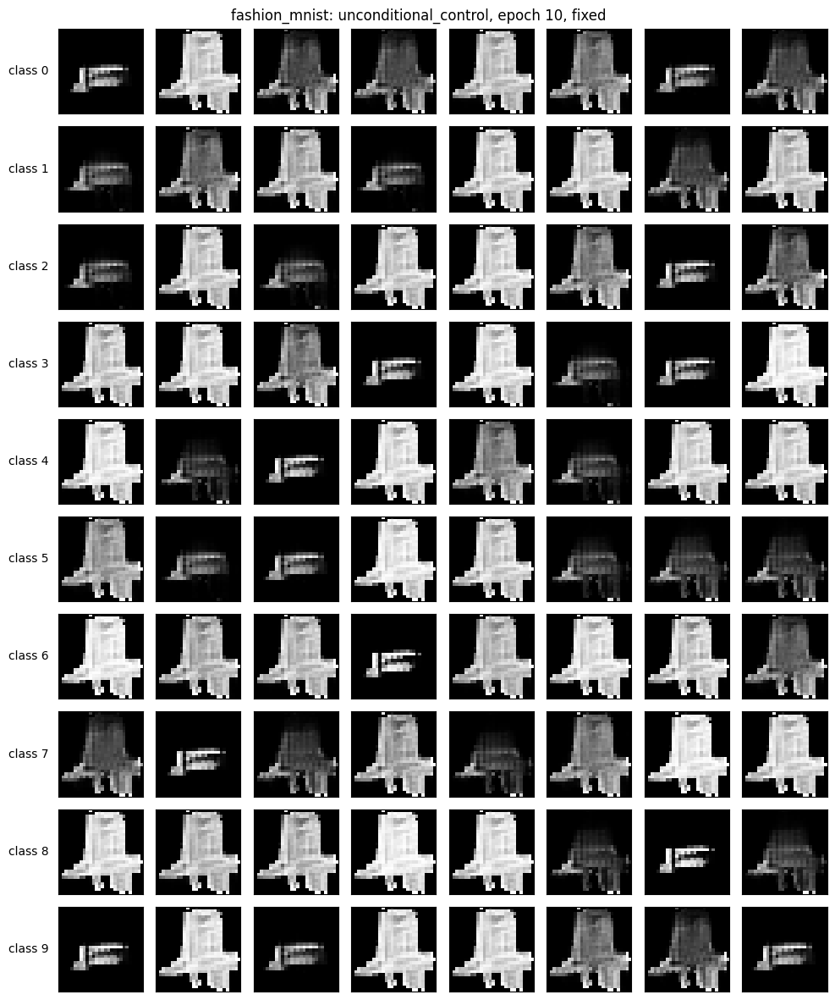

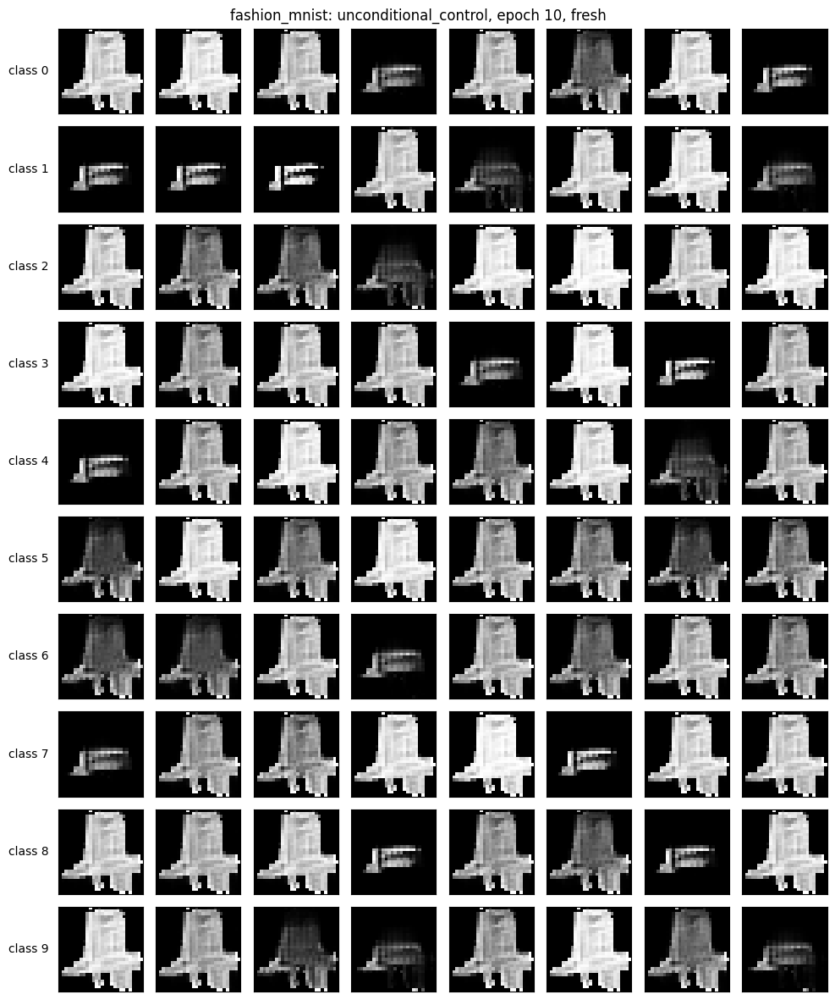

fashion_mnist unconditional_control | 11/40 | G total 0.737, adv 0.737, FM 0.00000, D 0.673
fashion_mnist unconditional_control | 12/40 | G total 0.765, adv 0.765, FM 0.00000, D 0.656
fashion_mnist unconditional_control | 13/40 | G total 0.806, adv 0.806, FM 0.00000, D 0.642
fashion_mnist unconditional_control | 14/40 | G total 0.778, adv 0.778, FM 0.00000, D 0.655
fashion_mnist unconditional_control | 15/40 | G total 0.740, adv 0.740, FM 0.00000, D 0.681


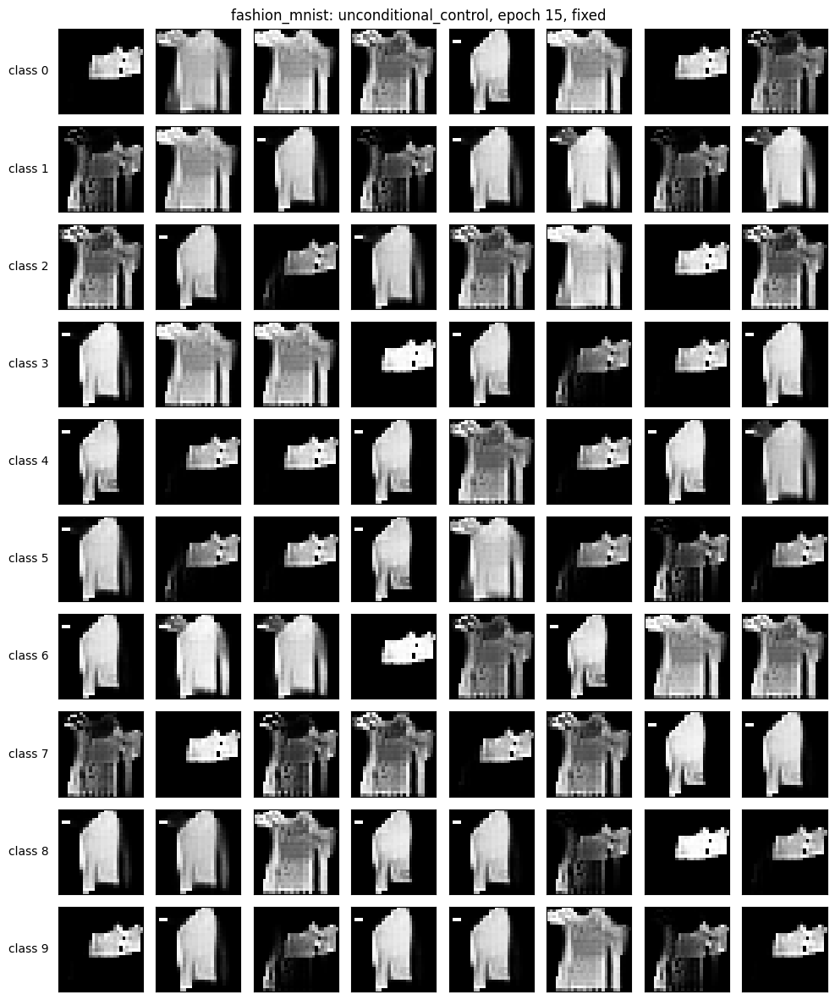

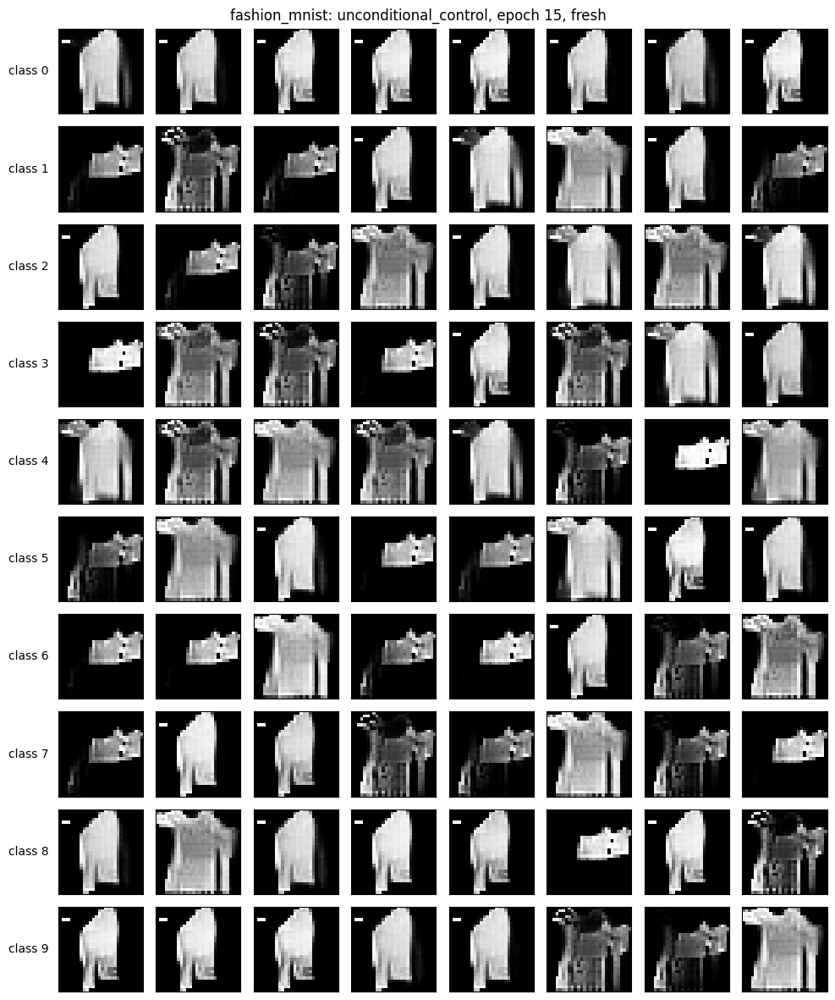

fashion_mnist unconditional_control | 16/40 | G total 0.736, adv 0.736, FM 0.00000, D 0.676
fashion_mnist unconditional_control | 17/40 | G total 0.745, adv 0.745, FM 0.00000, D 0.668
fashion_mnist unconditional_control | 18/40 | G total 0.758, adv 0.758, FM 0.00000, D 0.662
fashion_mnist unconditional_control | 19/40 | G total 0.771, adv 0.771, FM 0.00000, D 0.655
fashion_mnist unconditional_control | 20/40 | G total 0.787, adv 0.787, FM 0.00000, D 0.644


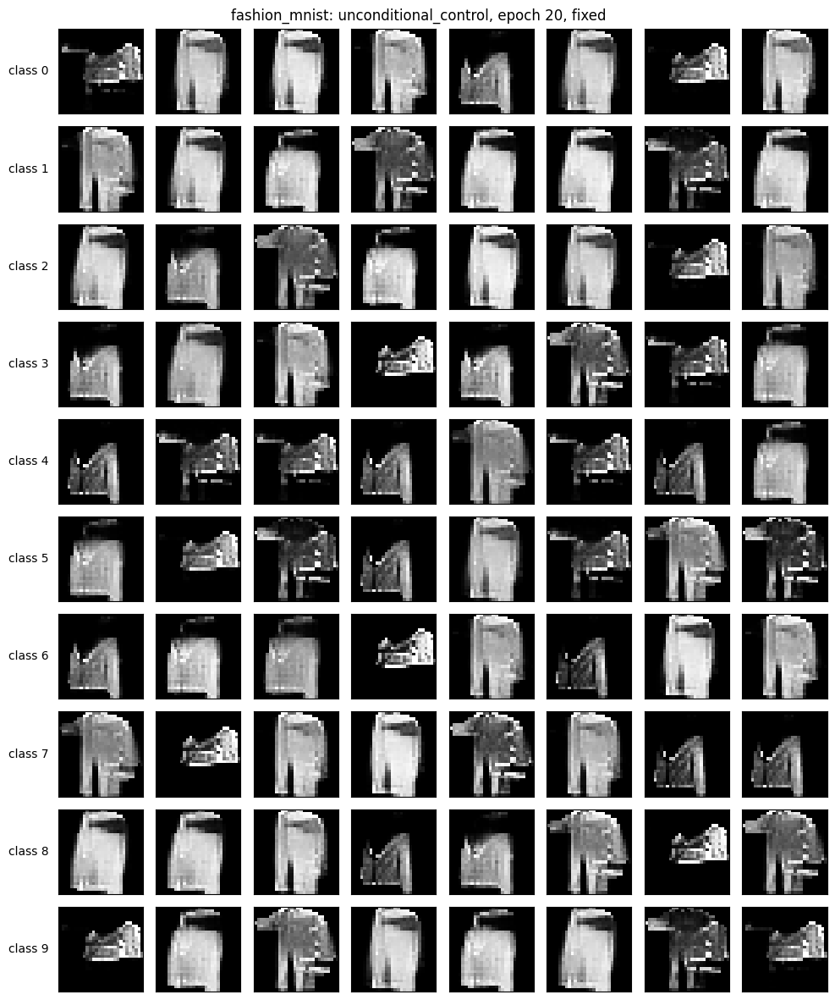

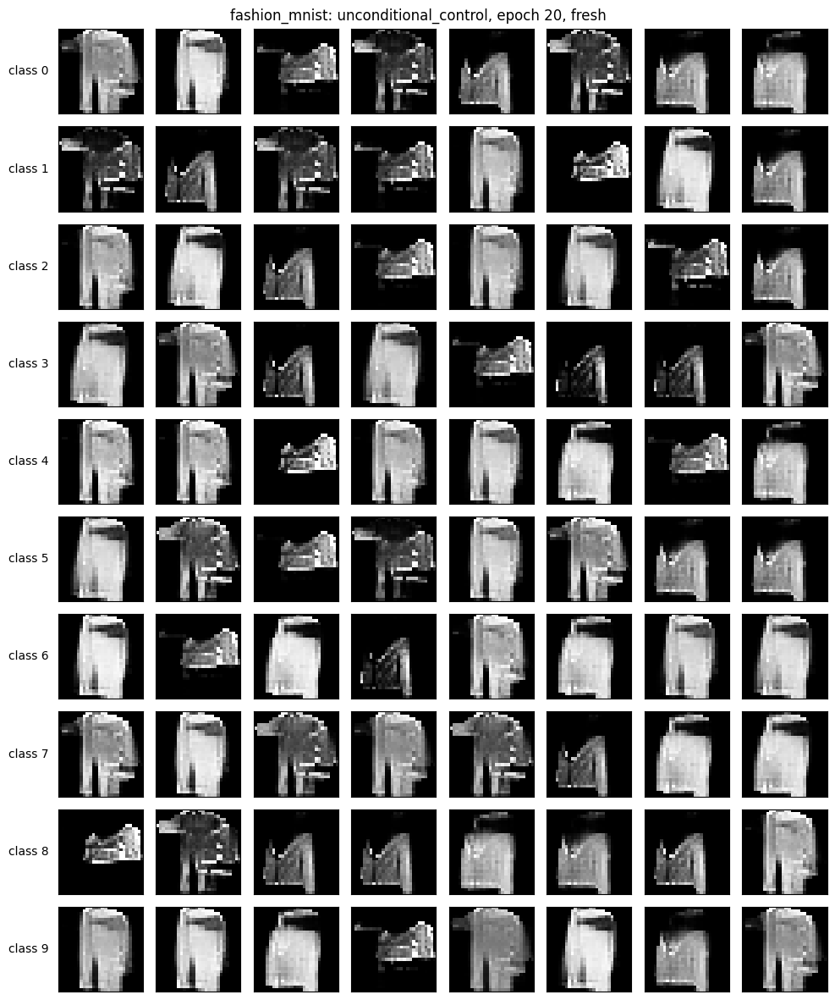

fashion_mnist unconditional_control | 21/40 | G total 0.813, adv 0.813, FM 0.00000, D 0.641
fashion_mnist unconditional_control | 22/40 | G total 0.815, adv 0.815, FM 0.00000, D 0.631
fashion_mnist unconditional_control | 23/40 | G total 0.806, adv 0.806, FM 0.00000, D 0.634
fashion_mnist unconditional_control | 24/40 | G total 0.802, adv 0.802, FM 0.00000, D 0.638
fashion_mnist unconditional_control | 25/40 | G total 0.807, adv 0.807, FM 0.00000, D 0.641


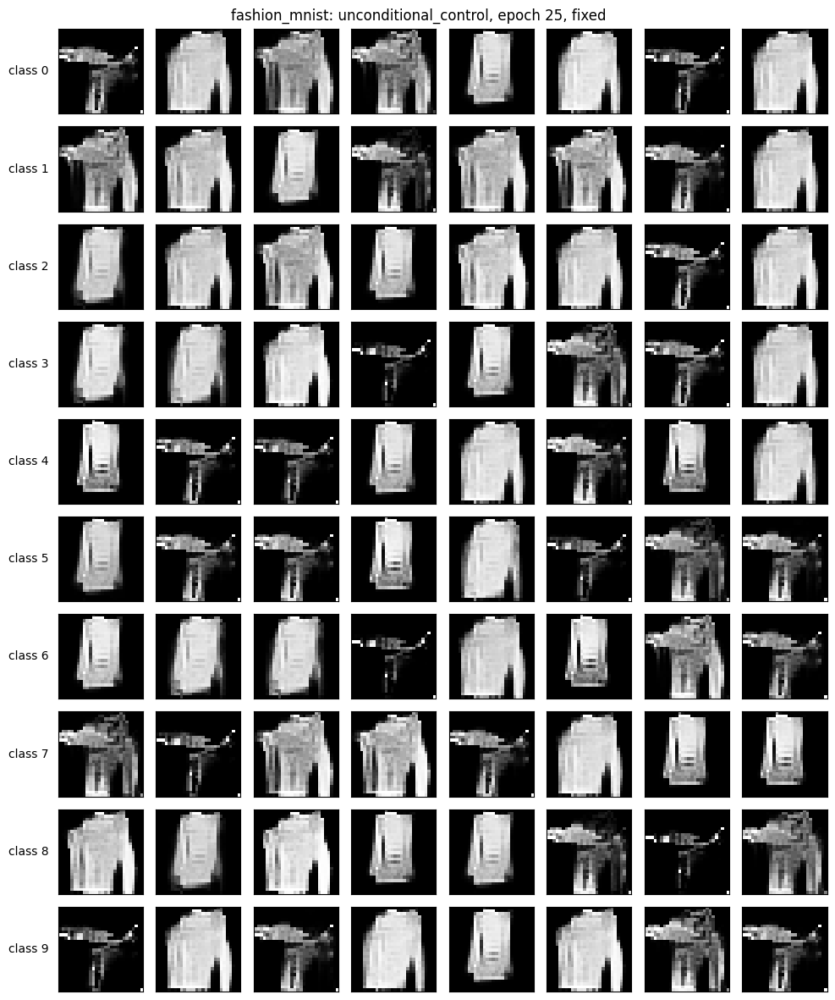

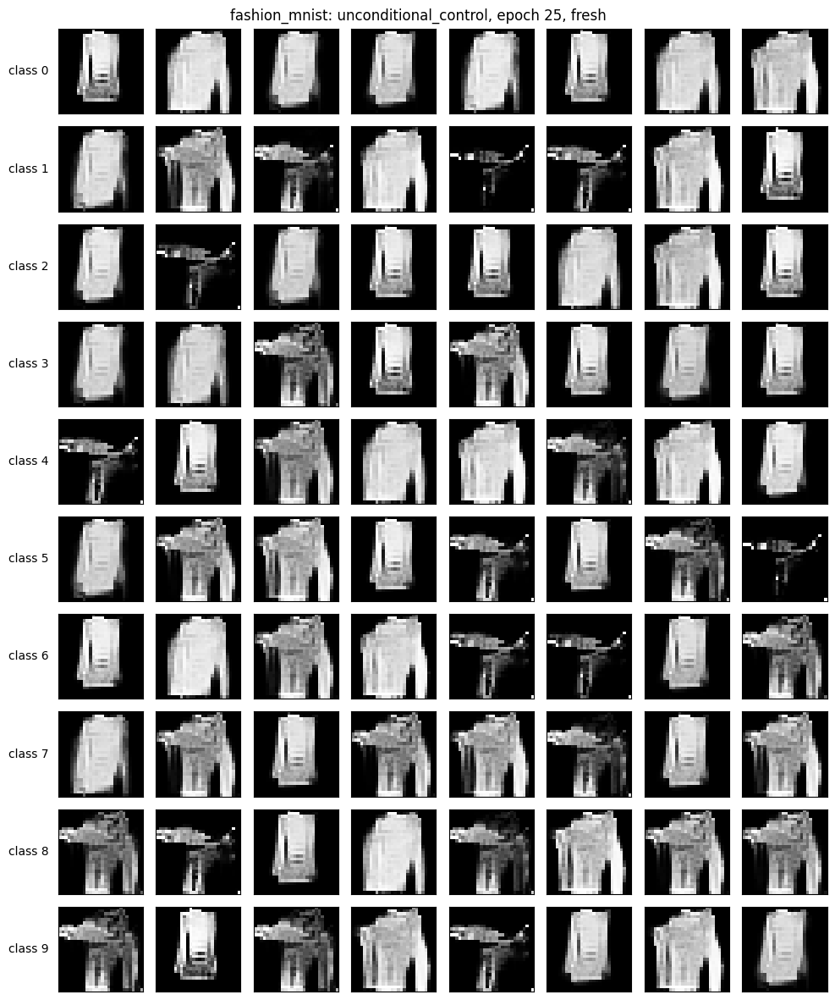

fashion_mnist unconditional_control | 26/40 | G total 0.792, adv 0.792, FM 0.00000, D 0.650
fashion_mnist unconditional_control | 27/40 | G total 0.846, adv 0.846, FM 0.00000, D 0.622
fashion_mnist unconditional_control | 28/40 | G total 0.751, adv 0.751, FM 0.00000, D 0.686
fashion_mnist unconditional_control | 29/40 | G total 0.762, adv 0.762, FM 0.00000, D 0.667
fashion_mnist unconditional_control | 30/40 | G total 0.760, adv 0.760, FM 0.00000, D 0.665


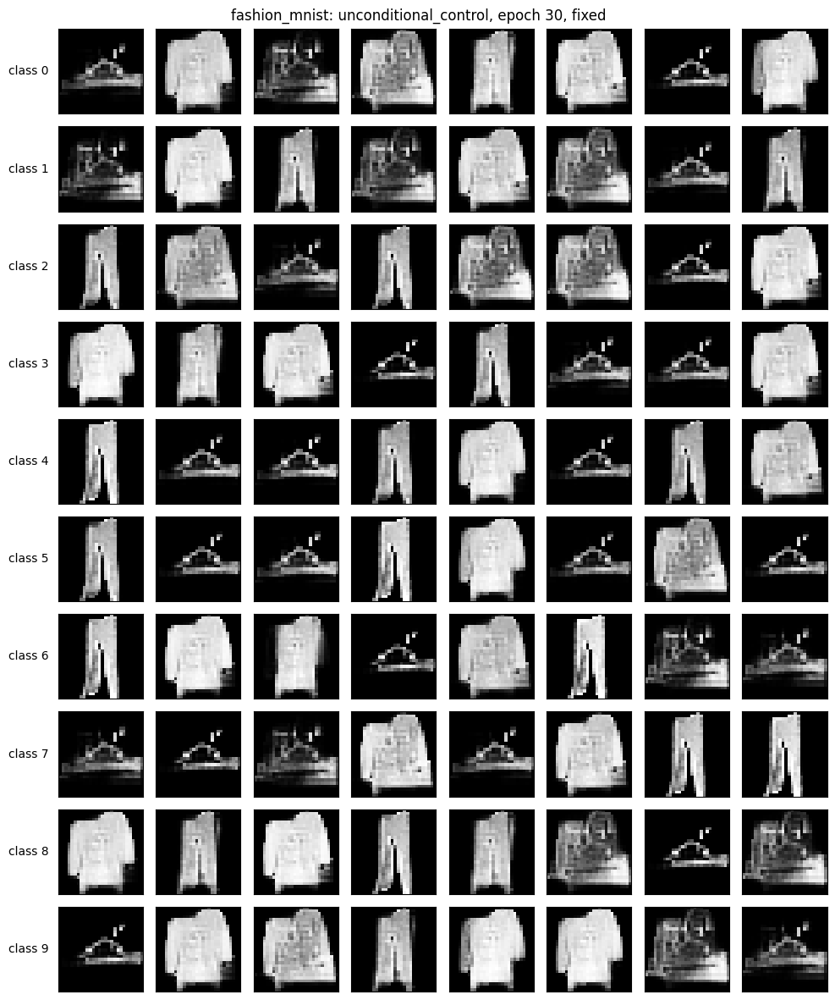

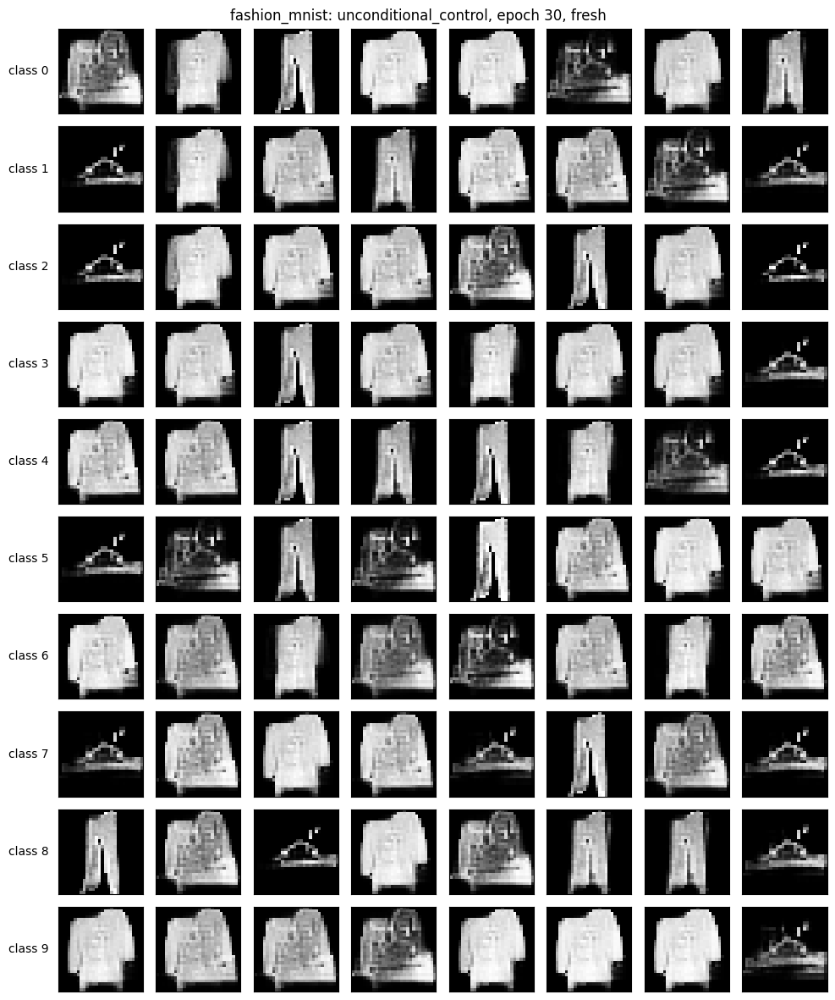

fashion_mnist unconditional_control | 31/40 | G total 0.792, adv 0.792, FM 0.00000, D 0.654
fashion_mnist unconditional_control | 32/40 | G total 0.787, adv 0.787, FM 0.00000, D 0.649
fashion_mnist unconditional_control | 33/40 | G total 0.764, adv 0.764, FM 0.00000, D 0.666
fashion_mnist unconditional_control | 34/40 | G total 0.767, adv 0.767, FM 0.00000, D 0.686
fashion_mnist unconditional_control | 35/40 | G total 0.740, adv 0.740, FM 0.00000, D 0.673


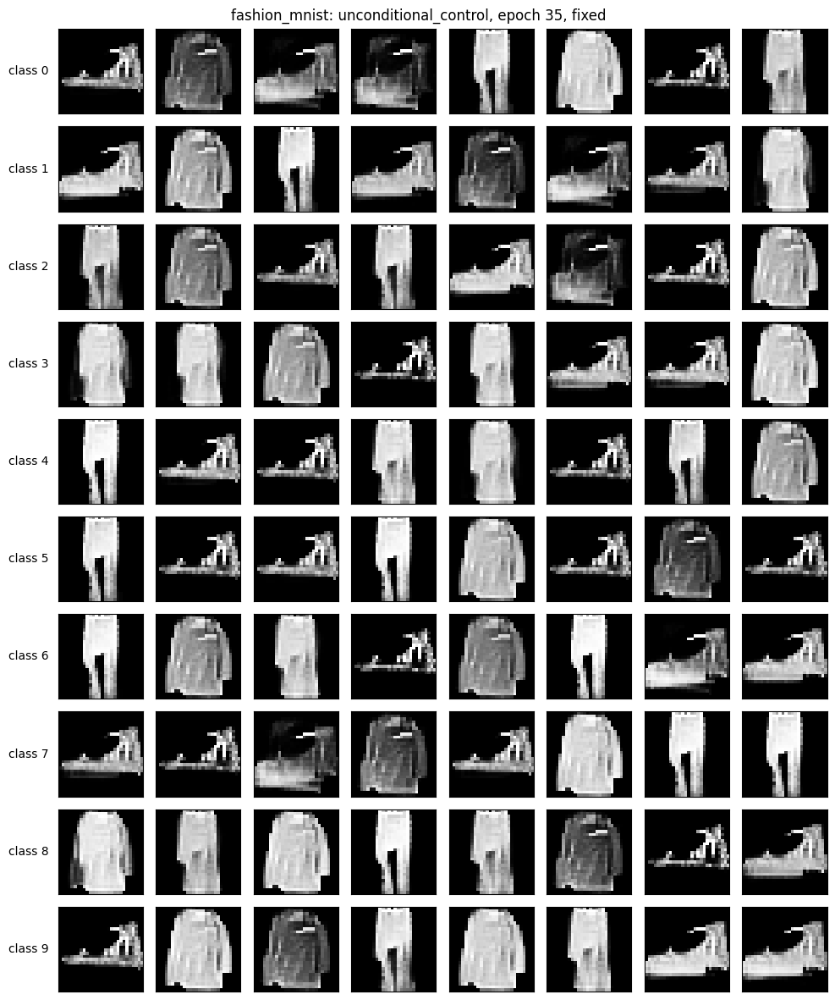

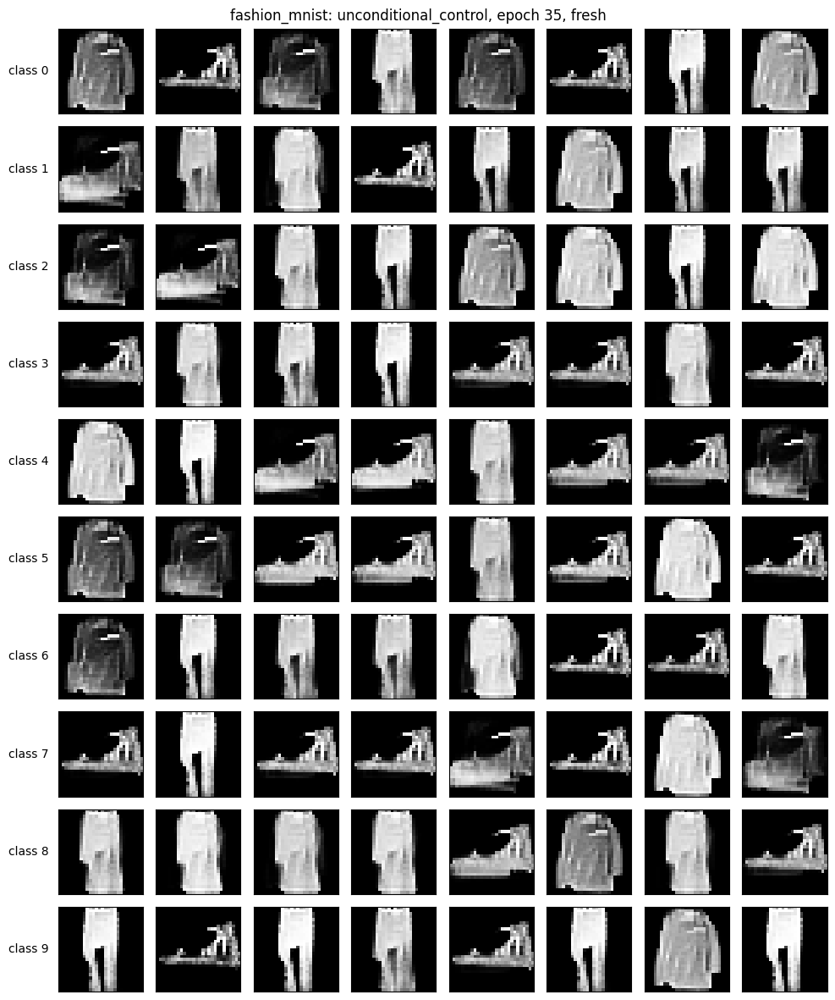

fashion_mnist unconditional_control | 36/40 | G total 0.753, adv 0.753, FM 0.00000, D 0.665
fashion_mnist unconditional_control | 37/40 | G total 0.767, adv 0.767, FM 0.00000, D 0.662
fashion_mnist unconditional_control | 38/40 | G total 0.751, adv 0.751, FM 0.00000, D 0.671
fashion_mnist unconditional_control | 39/40 | G total 0.742, adv 0.742, FM 0.00000, D 0.680
fashion_mnist unconditional_control | 40/40 | G total 0.759, adv 0.759, FM 0.00000, D 0.667


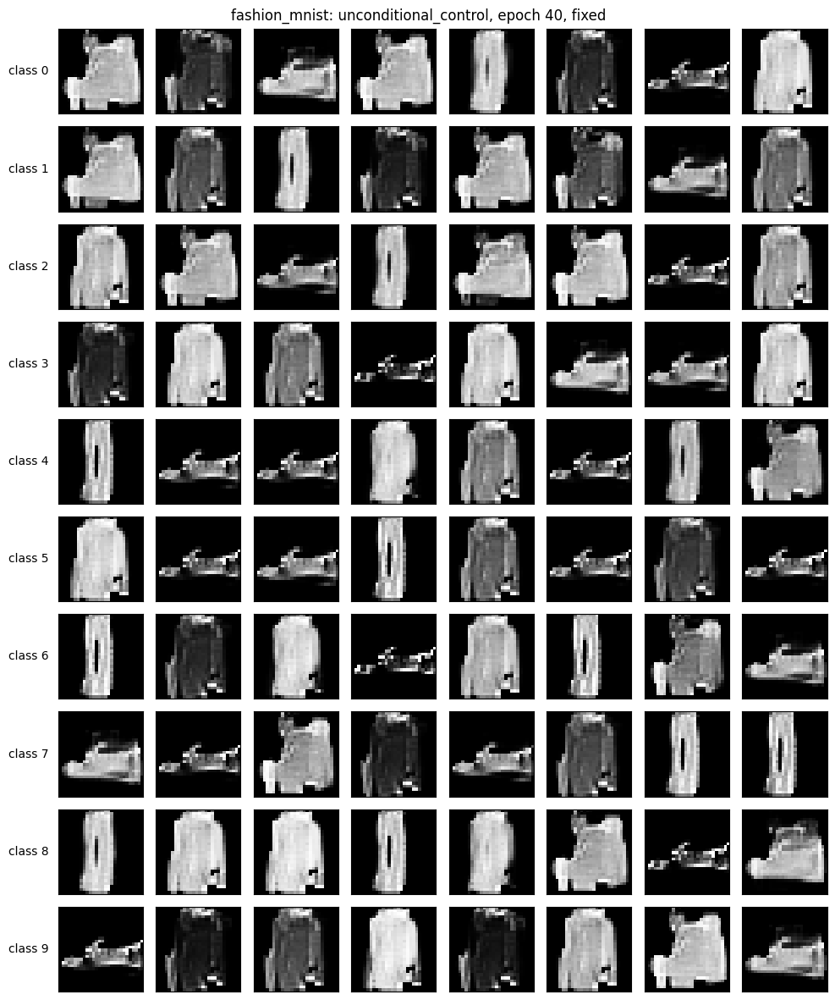

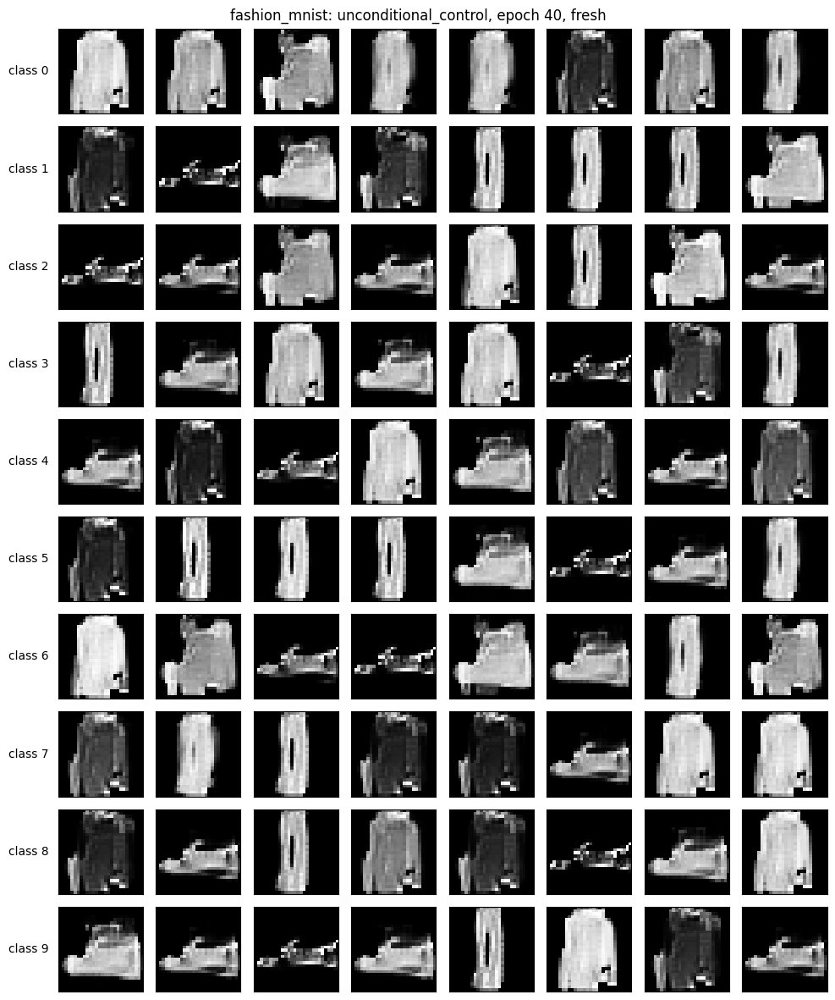

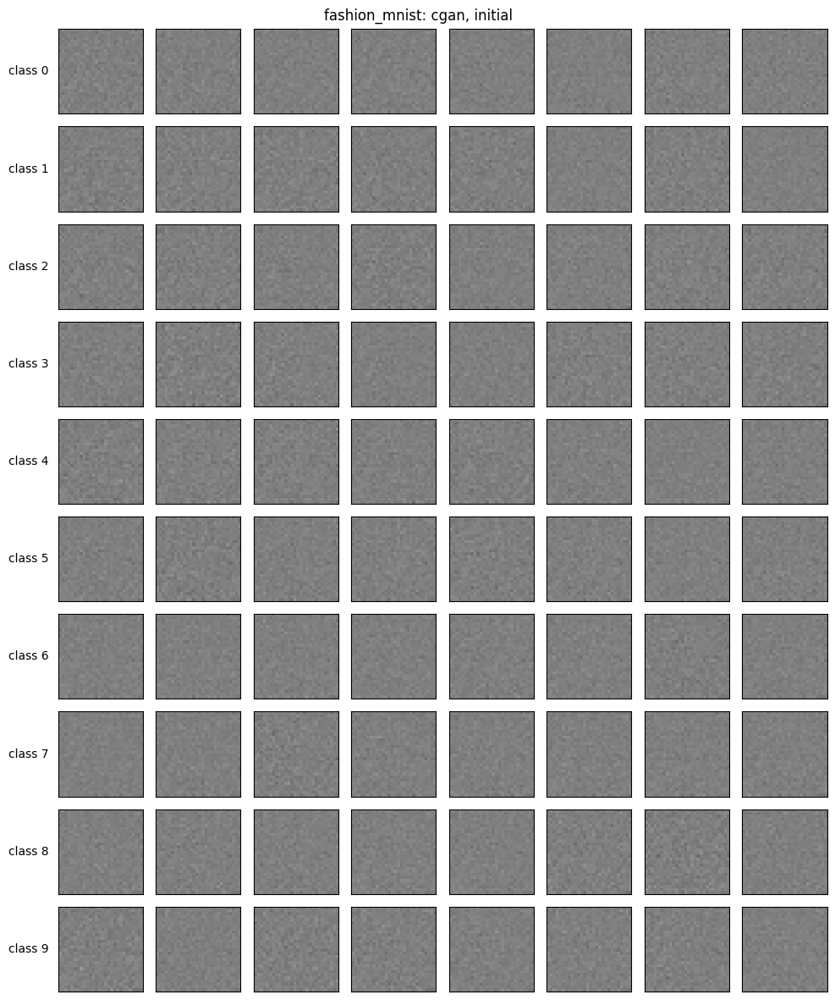

fashion_mnist cgan | 1/40 | G total 0.917, adv 0.917, FM 0.00000, D 0.628


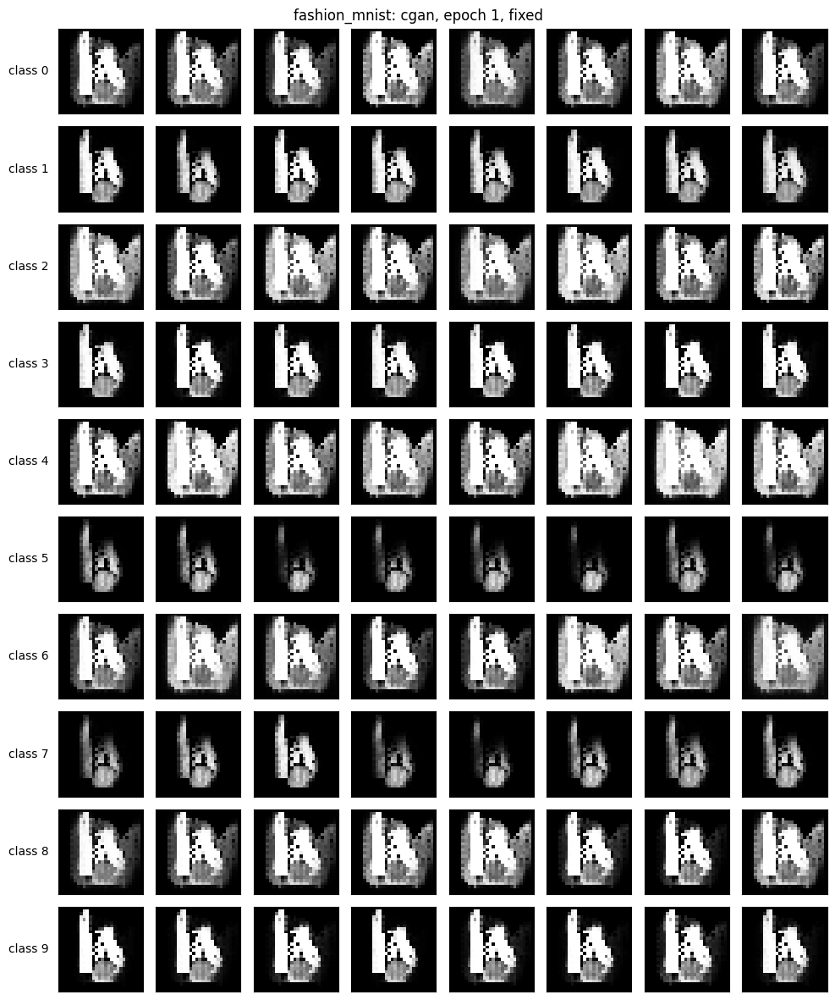

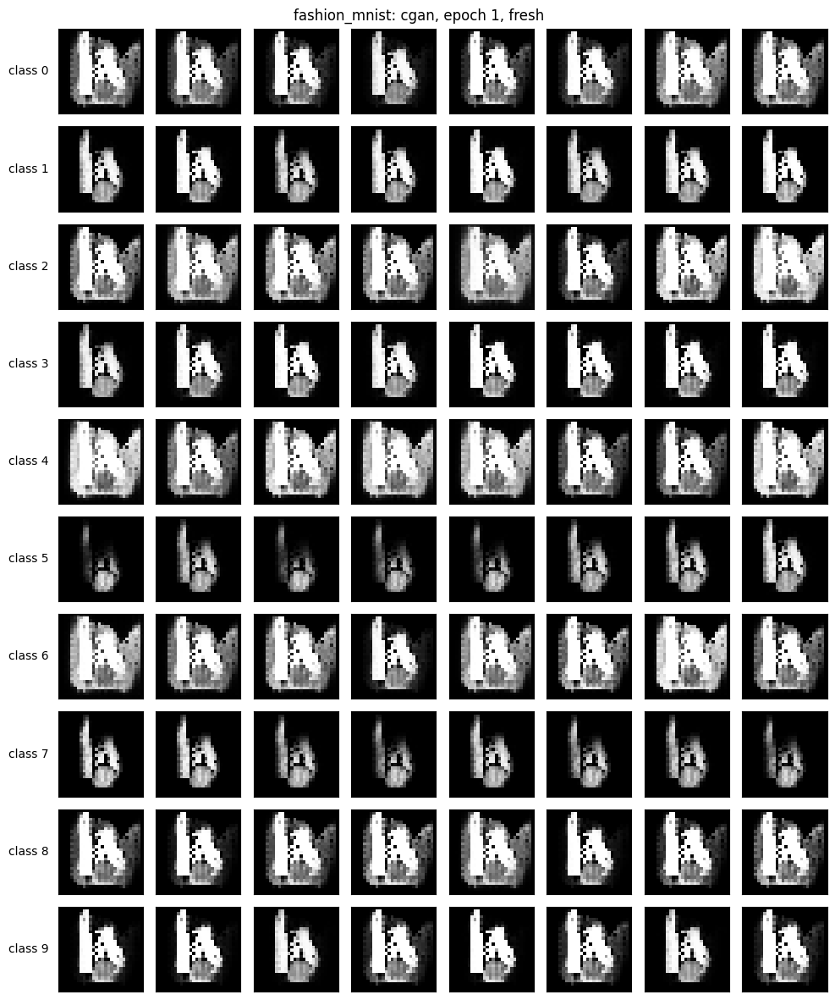

fashion_mnist cgan | 2/40 | G total 0.766, adv 0.766, FM 0.00000, D 0.664
fashion_mnist cgan | 3/40 | G total 0.797, adv 0.797, FM 0.00000, D 0.638
fashion_mnist cgan | 4/40 | G total 0.749, adv 0.749, FM 0.00000, D 0.679
fashion_mnist cgan | 5/40 | G total 0.719, adv 0.719, FM 0.00000, D 0.682


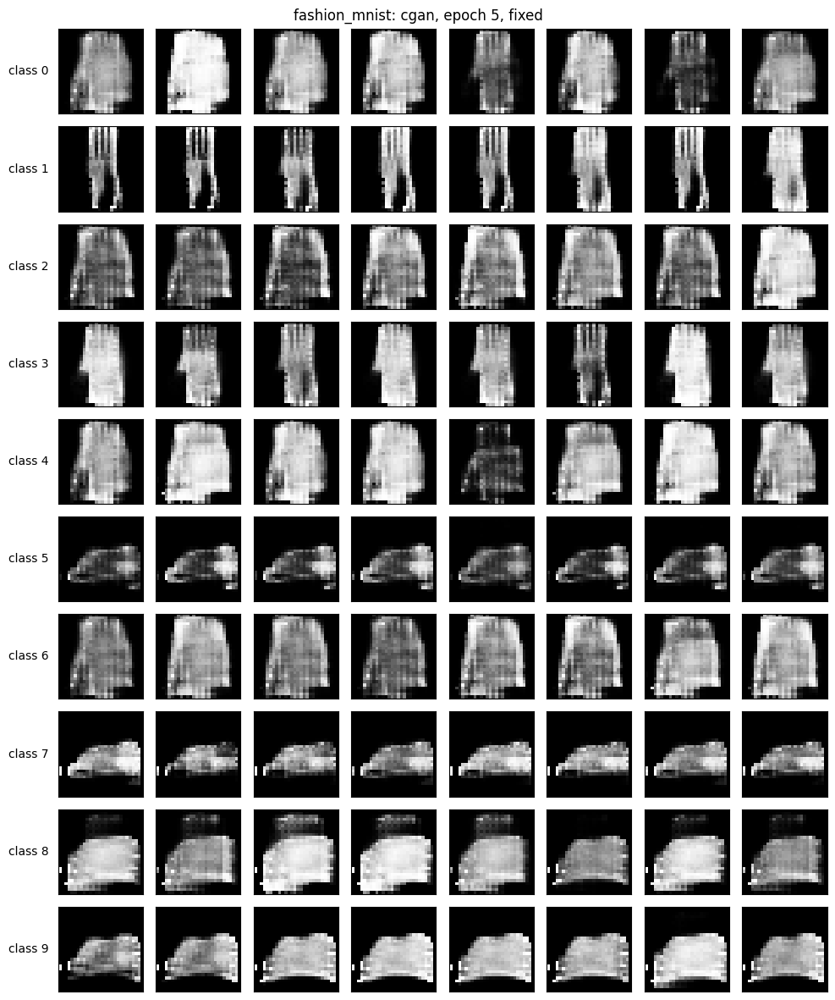

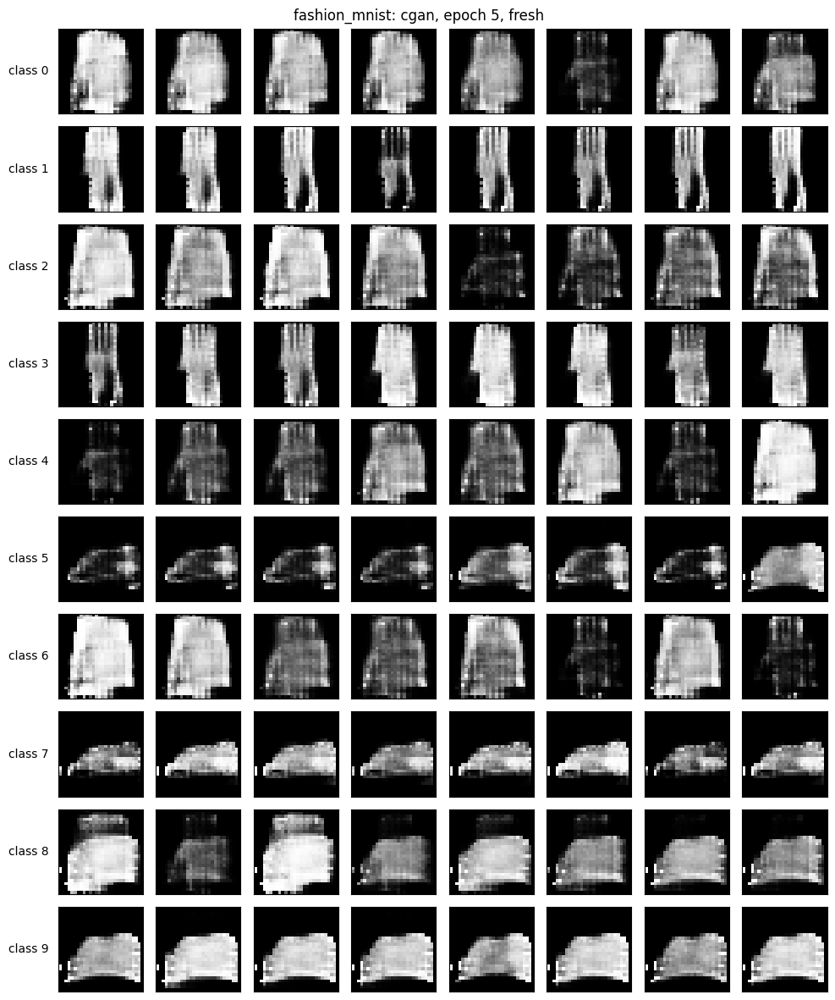

fashion_mnist cgan | 6/40 | G total 0.724, adv 0.724, FM 0.00000, D 0.679
fashion_mnist cgan | 7/40 | G total 0.734, adv 0.734, FM 0.00000, D 0.680
fashion_mnist cgan | 8/40 | G total 0.729, adv 0.729, FM 0.00000, D 0.678
fashion_mnist cgan | 9/40 | G total 0.727, adv 0.727, FM 0.00000, D 0.679
fashion_mnist cgan | 10/40 | G total 0.719, adv 0.719, FM 0.00000, D 0.684


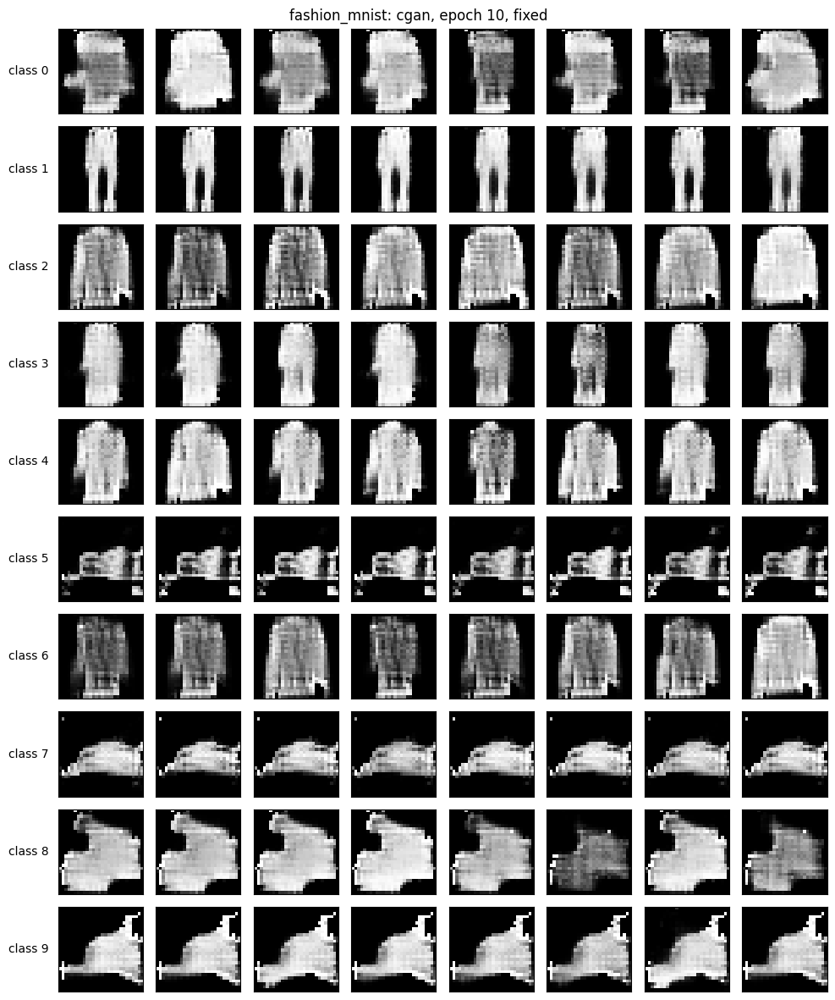

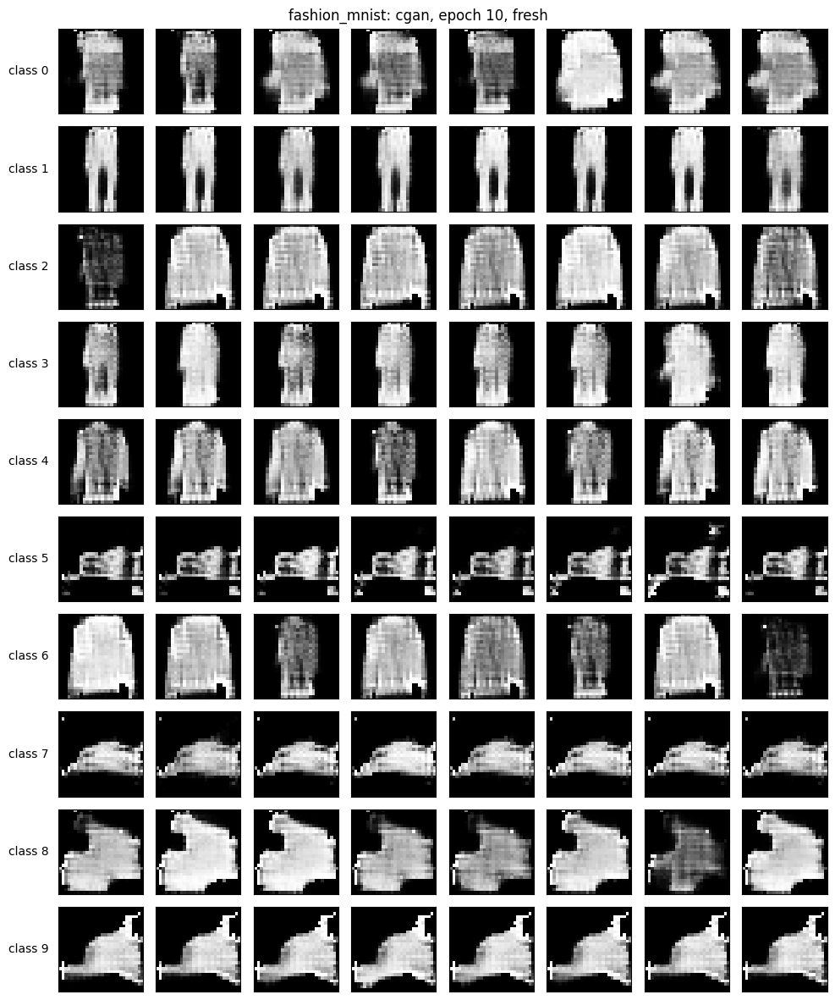

fashion_mnist cgan | 11/40 | G total 0.714, adv 0.714, FM 0.00000, D 0.687
fashion_mnist cgan | 12/40 | G total 0.702, adv 0.702, FM 0.00000, D 0.692
fashion_mnist cgan | 13/40 | G total 0.708, adv 0.708, FM 0.00000, D 0.691
fashion_mnist cgan | 14/40 | G total 0.706, adv 0.706, FM 0.00000, D 0.691
fashion_mnist cgan | 15/40 | G total 0.703, adv 0.703, FM 0.00000, D 0.691


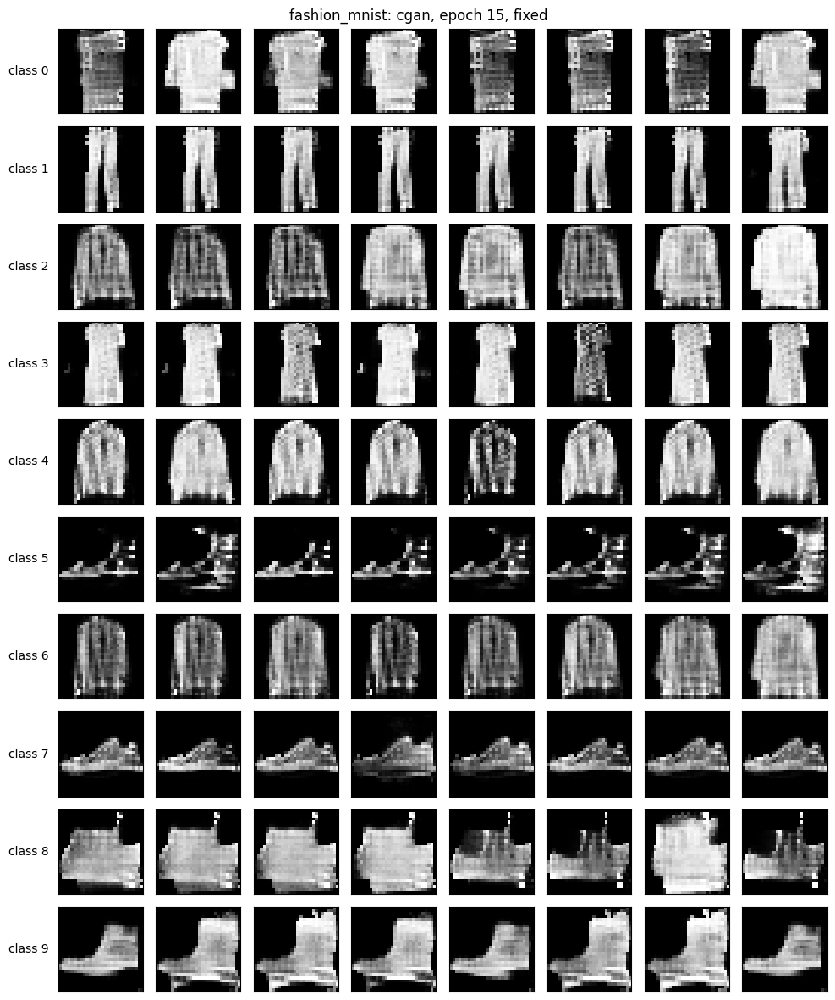

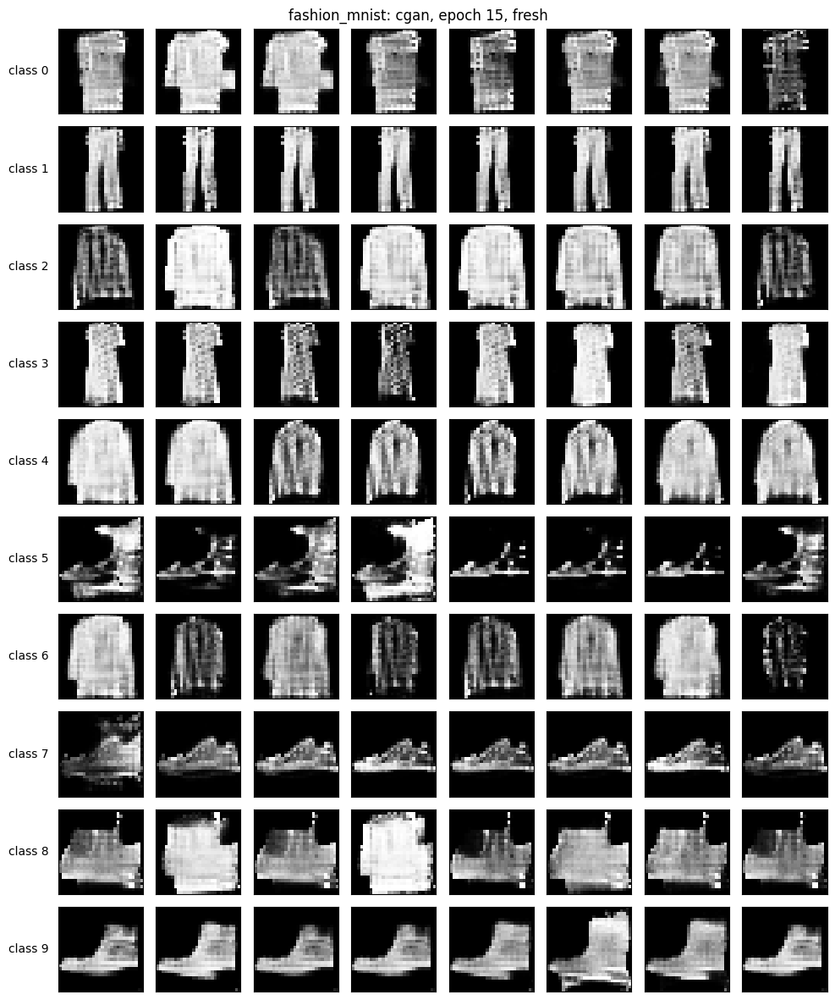

fashion_mnist cgan | 16/40 | G total 0.704, adv 0.704, FM 0.00000, D 0.691
fashion_mnist cgan | 17/40 | G total 0.705, adv 0.705, FM 0.00000, D 0.691
fashion_mnist cgan | 18/40 | G total 0.705, adv 0.705, FM 0.00000, D 0.691
fashion_mnist cgan | 19/40 | G total 0.706, adv 0.706, FM 0.00000, D 0.690
fashion_mnist cgan | 20/40 | G total 0.704, adv 0.704, FM 0.00000, D 0.690


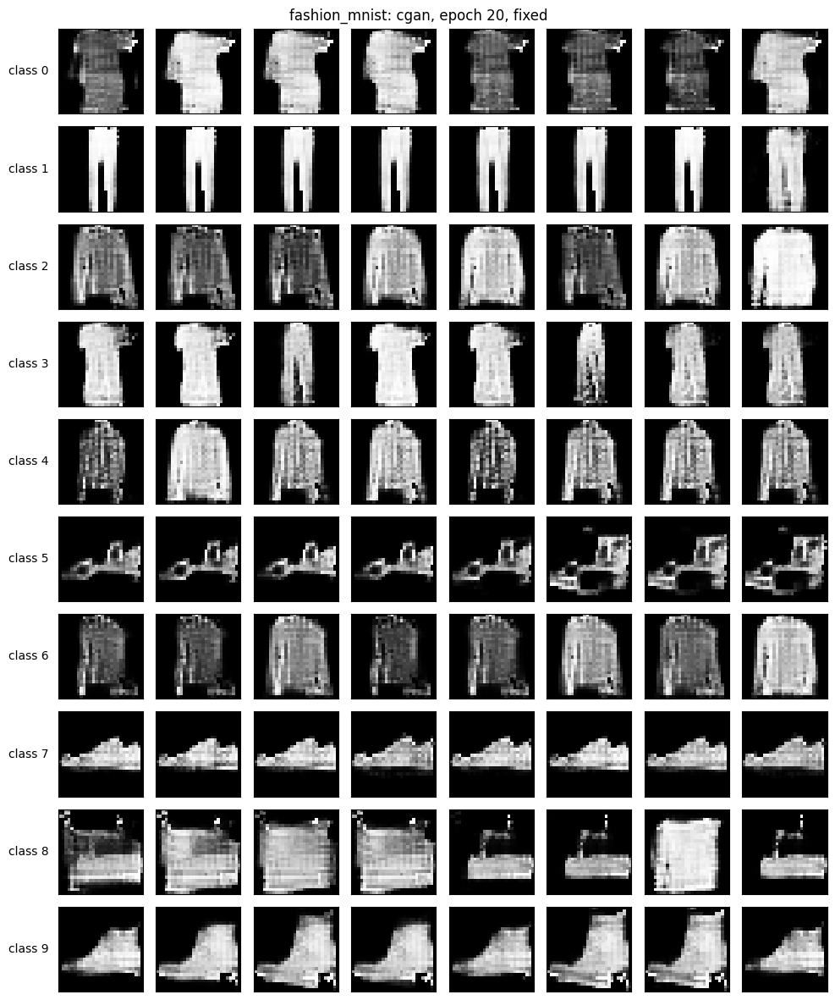

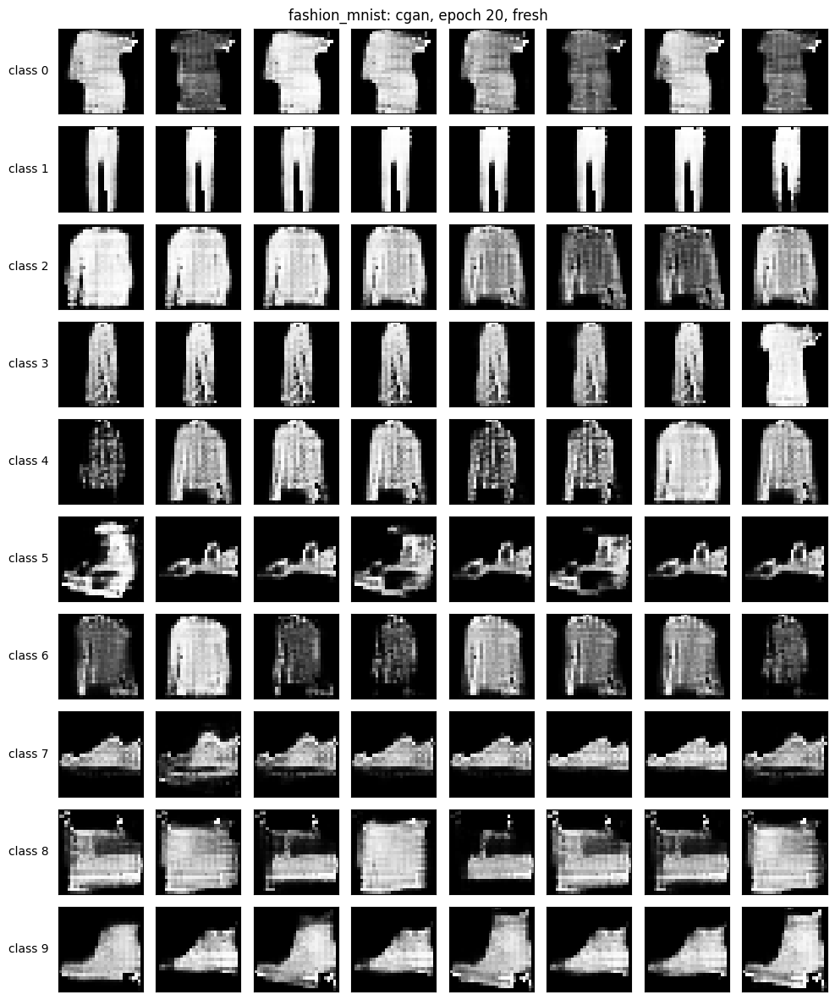

fashion_mnist cgan | 21/40 | G total 0.707, adv 0.707, FM 0.00000, D 0.691
fashion_mnist cgan | 22/40 | G total 0.704, adv 0.704, FM 0.00000, D 0.690
fashion_mnist cgan | 23/40 | G total 0.704, adv 0.704, FM 0.00000, D 0.691
fashion_mnist cgan | 24/40 | G total 0.704, adv 0.704, FM 0.00000, D 0.691
fashion_mnist cgan | 25/40 | G total 0.704, adv 0.704, FM 0.00000, D 0.690


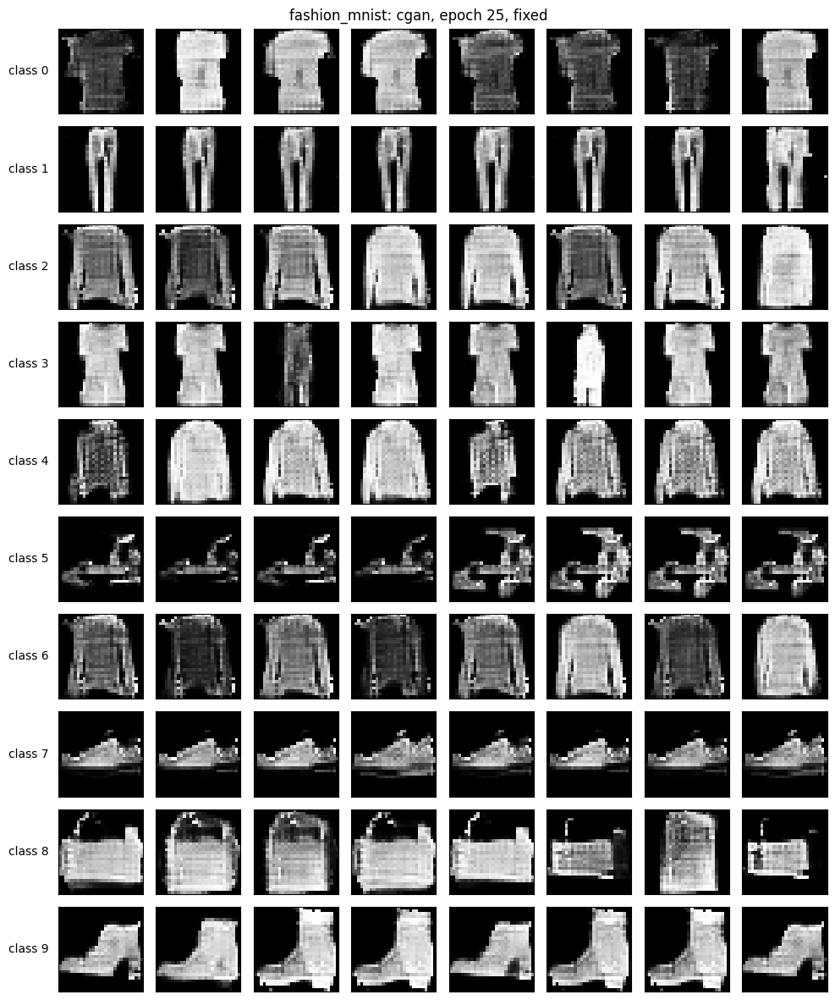

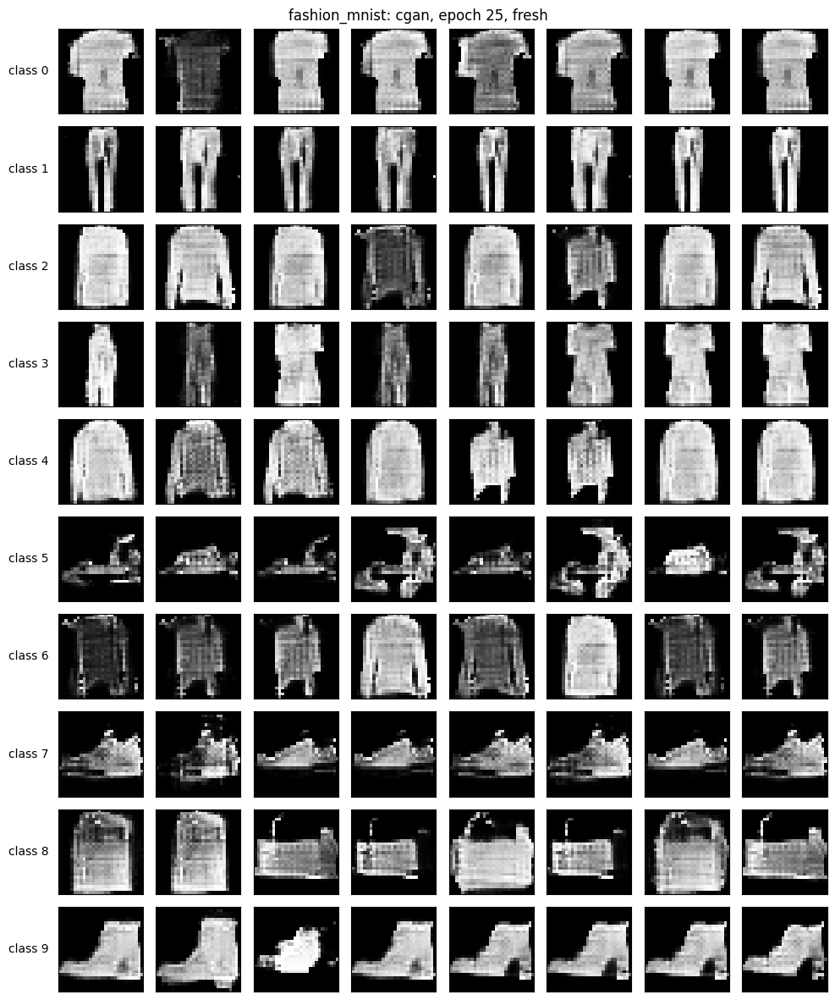

fashion_mnist cgan | 26/40 | G total 0.702, adv 0.702, FM 0.00000, D 0.691
fashion_mnist cgan | 27/40 | G total 0.701, adv 0.701, FM 0.00000, D 0.692
fashion_mnist cgan | 28/40 | G total 0.700, adv 0.700, FM 0.00000, D 0.692
fashion_mnist cgan | 29/40 | G total 0.700, adv 0.700, FM 0.00000, D 0.692
fashion_mnist cgan | 30/40 | G total 0.699, adv 0.699, FM 0.00000, D 0.692


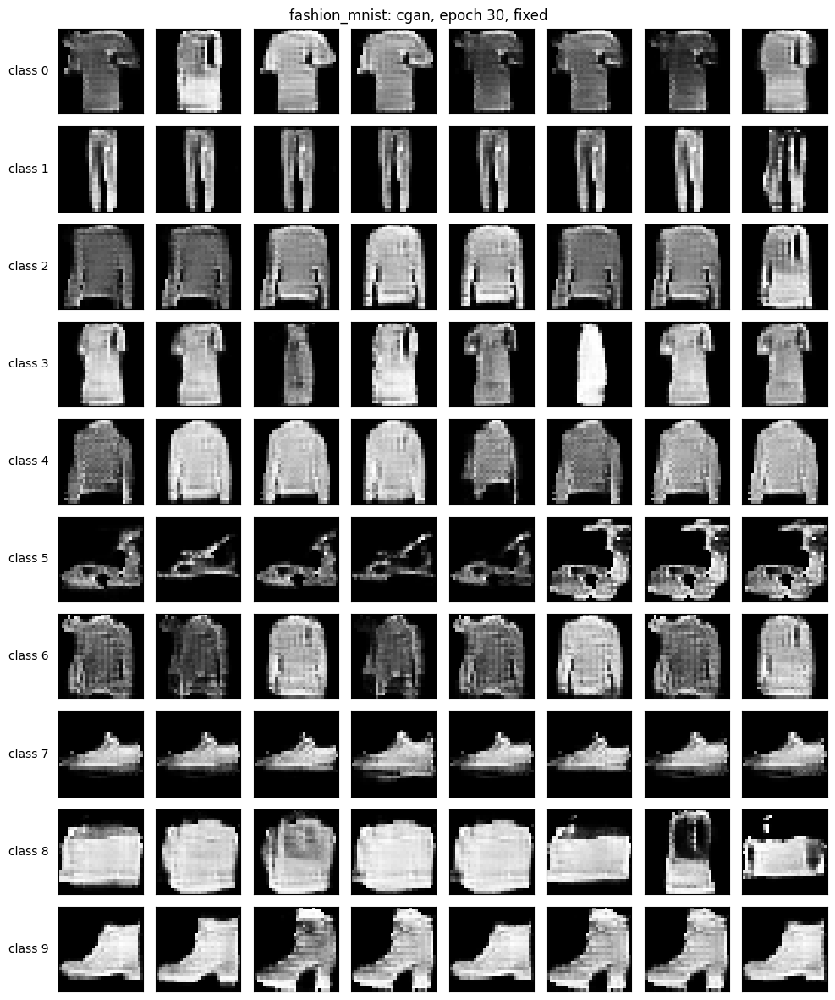

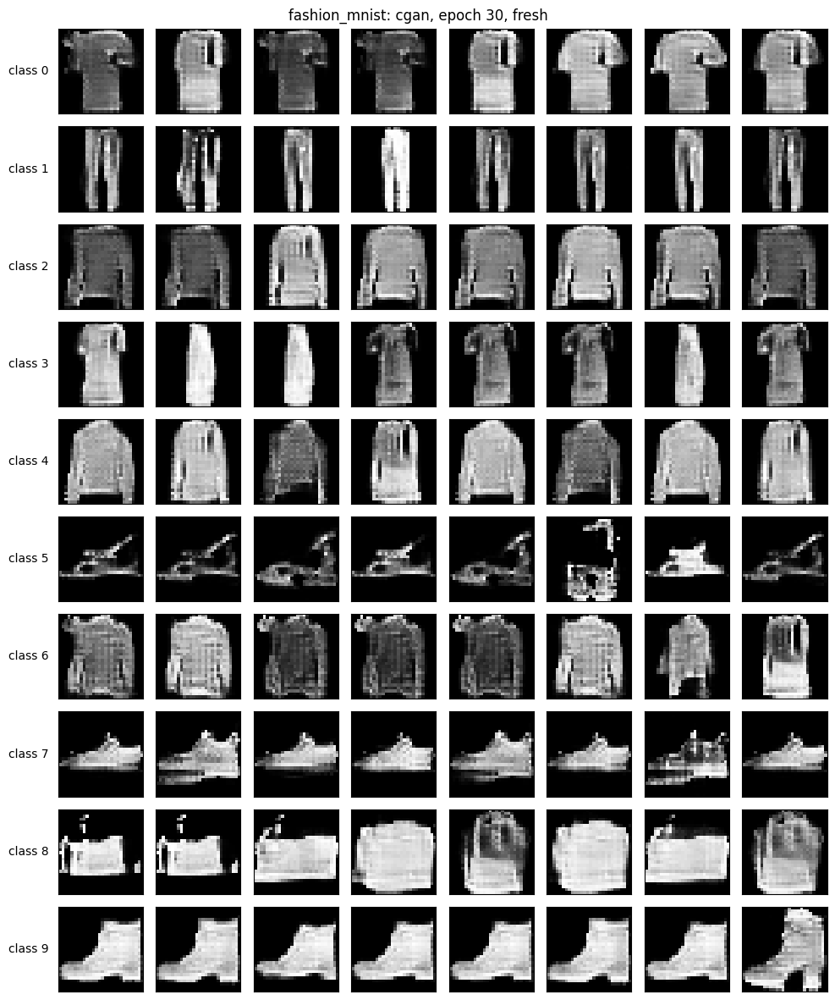

fashion_mnist cgan | 31/40 | G total 0.701, adv 0.701, FM 0.00000, D 0.692
fashion_mnist cgan | 32/40 | G total 0.700, adv 0.700, FM 0.00000, D 0.692
fashion_mnist cgan | 33/40 | G total 0.701, adv 0.701, FM 0.00000, D 0.692
fashion_mnist cgan | 34/40 | G total 0.701, adv 0.701, FM 0.00000, D 0.691
fashion_mnist cgan | 35/40 | G total 0.701, adv 0.701, FM 0.00000, D 0.691


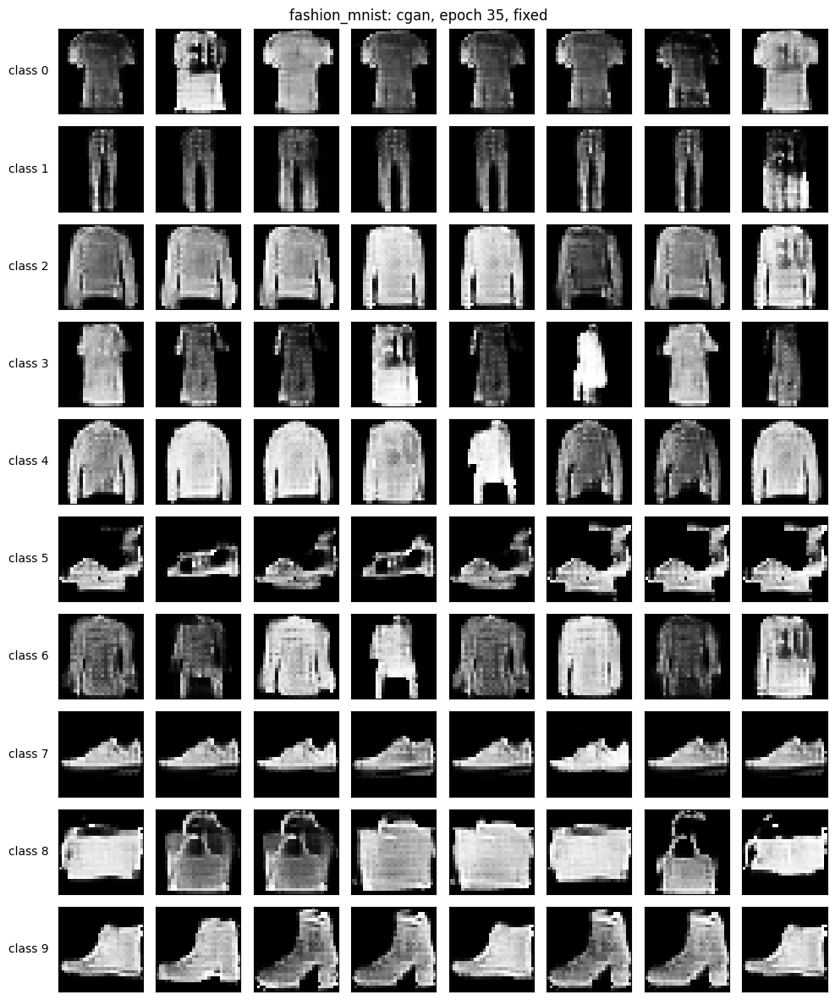

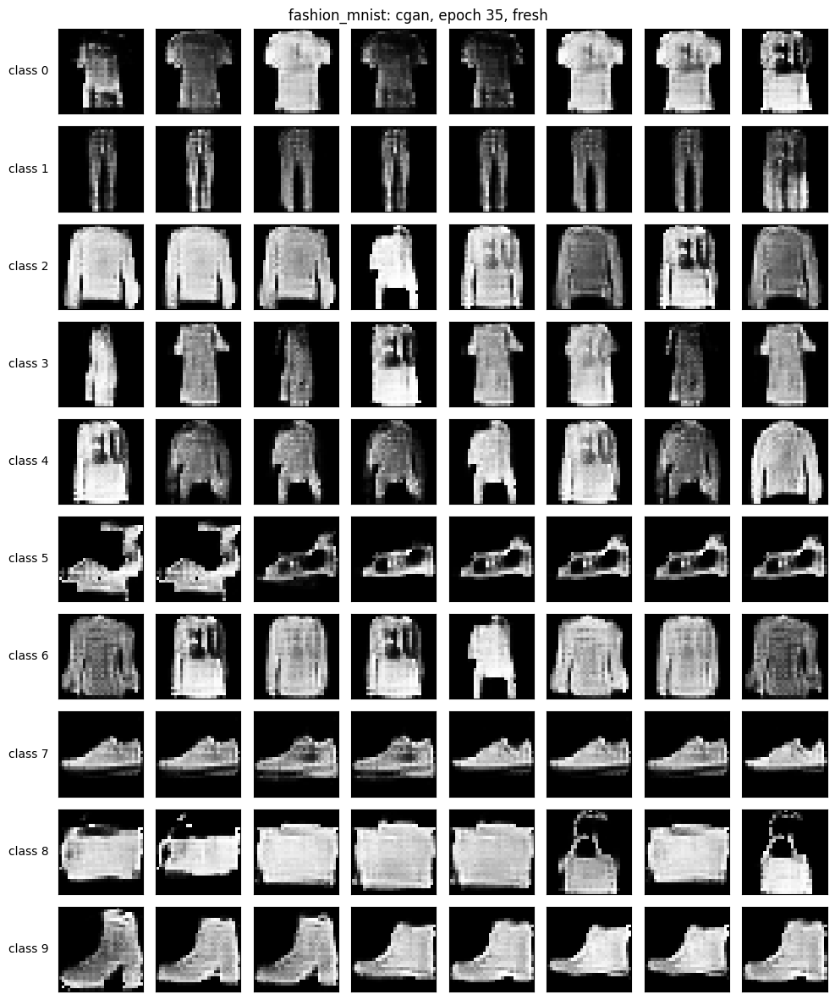

fashion_mnist cgan | 36/40 | G total 0.702, adv 0.702, FM 0.00000, D 0.691
fashion_mnist cgan | 37/40 | G total 0.701, adv 0.701, FM 0.00000, D 0.691
fashion_mnist cgan | 38/40 | G total 0.701, adv 0.701, FM 0.00000, D 0.691
fashion_mnist cgan | 39/40 | G total 0.700, adv 0.700, FM 0.00000, D 0.692
fashion_mnist cgan | 40/40 | G total 0.702, adv 0.702, FM 0.00000, D 0.691


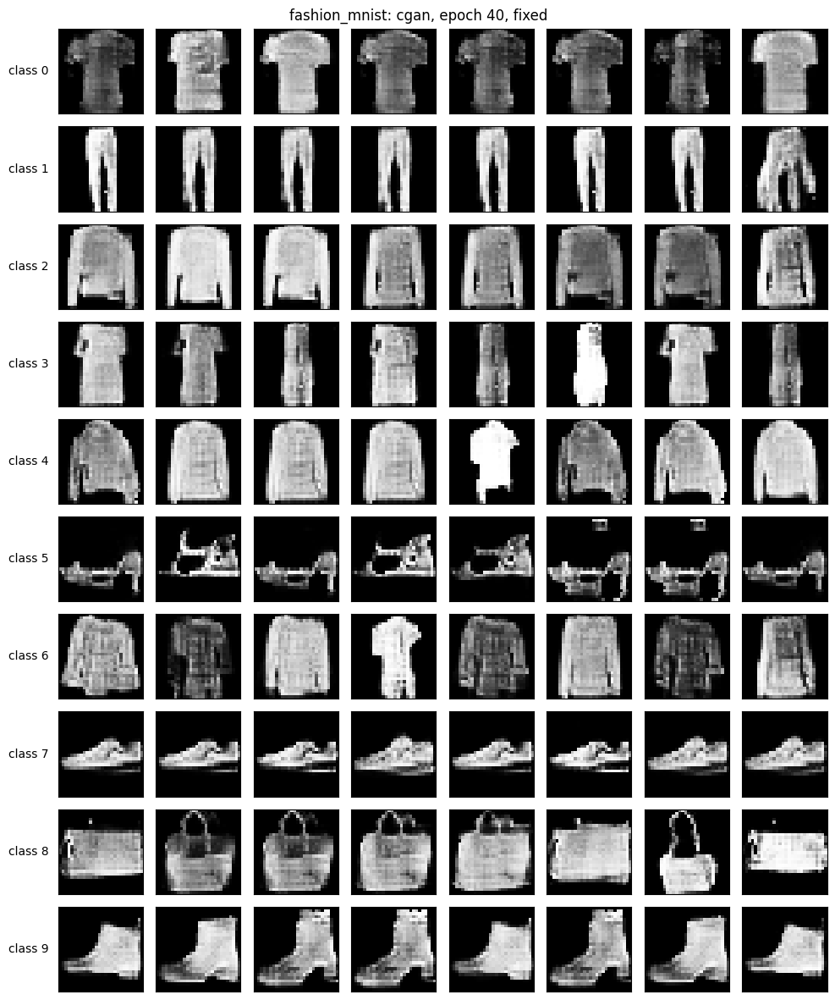

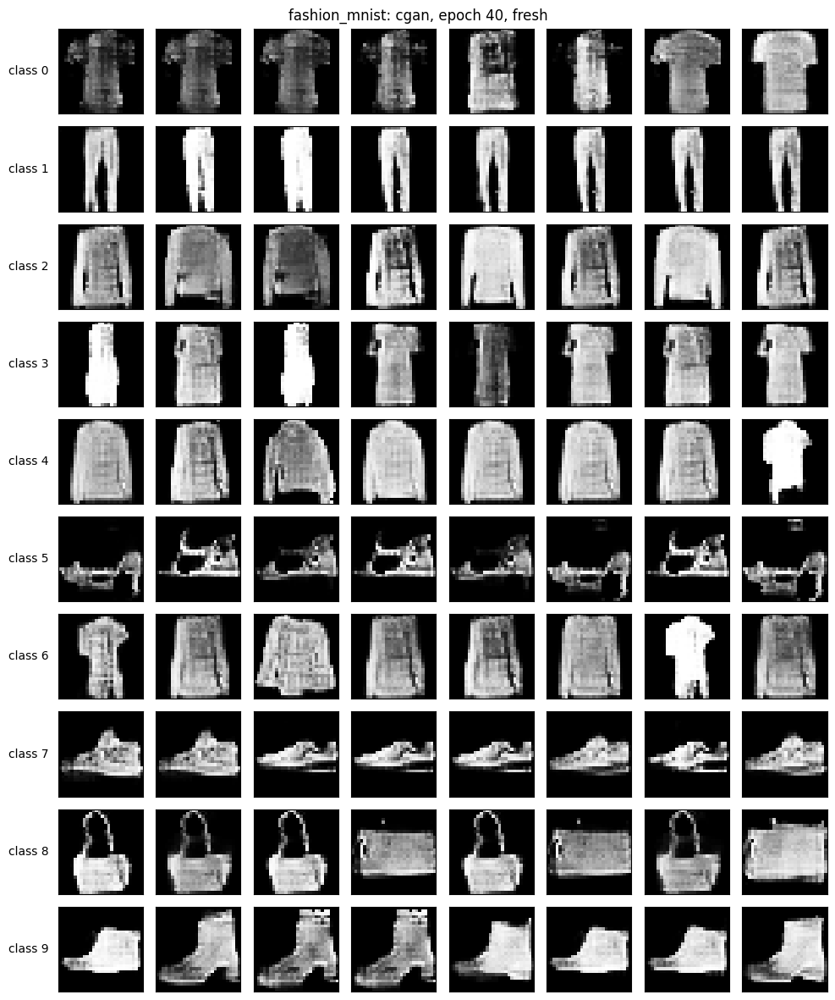

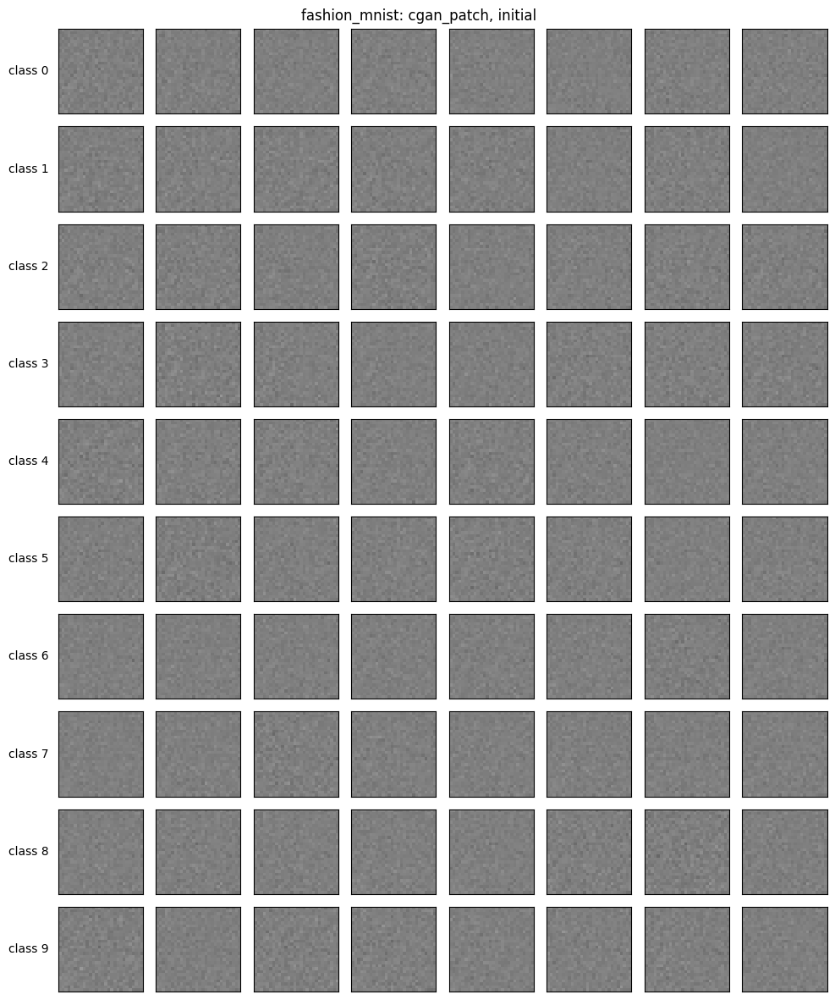

fashion_mnist cgan_patch | 1/40 | G total 0.818, adv 0.818, FM 0.00000, D 0.651


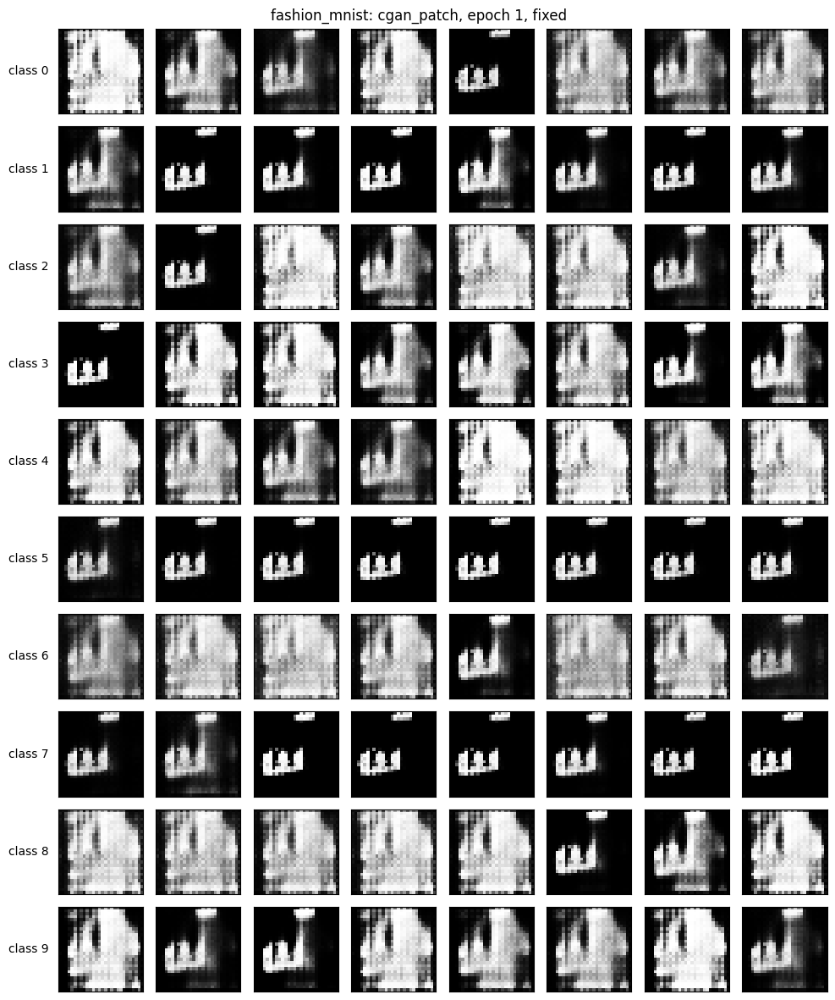

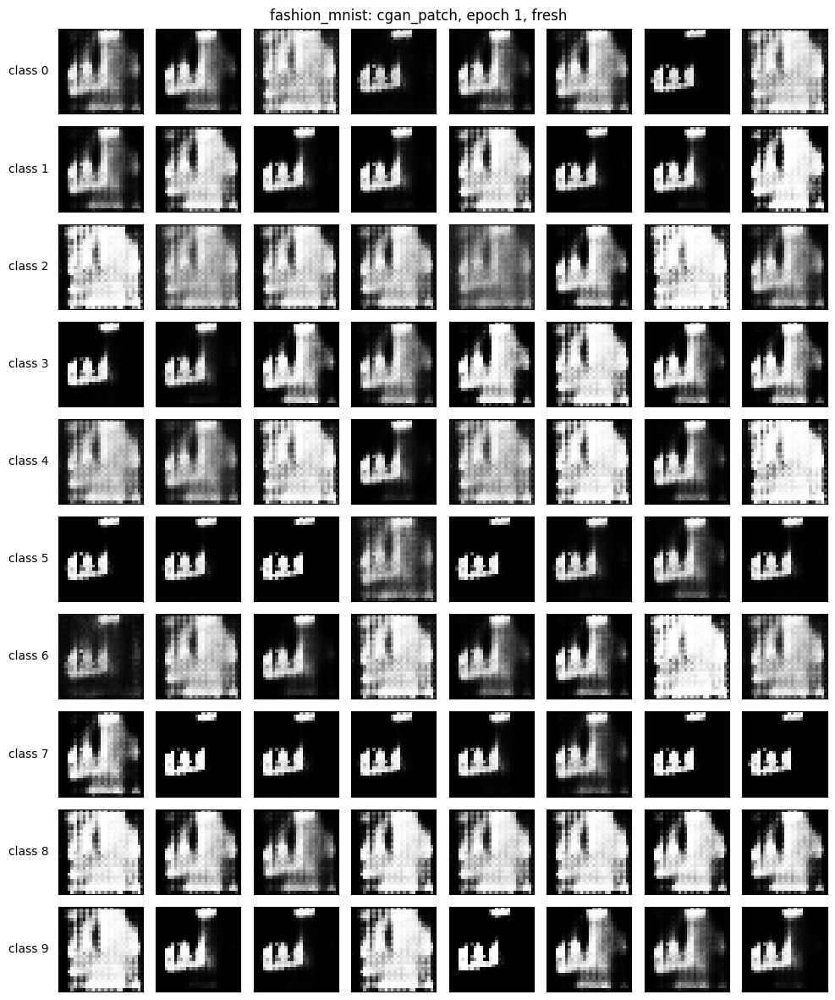

fashion_mnist cgan_patch | 2/40 | G total 0.796, adv 0.796, FM 0.00000, D 0.656
fashion_mnist cgan_patch | 3/40 | G total 0.759, adv 0.759, FM 0.00000, D 0.673
fashion_mnist cgan_patch | 4/40 | G total 0.703, adv 0.703, FM 0.00000, D 0.691
fashion_mnist cgan_patch | 5/40 | G total 0.705, adv 0.705, FM 0.00000, D 0.689


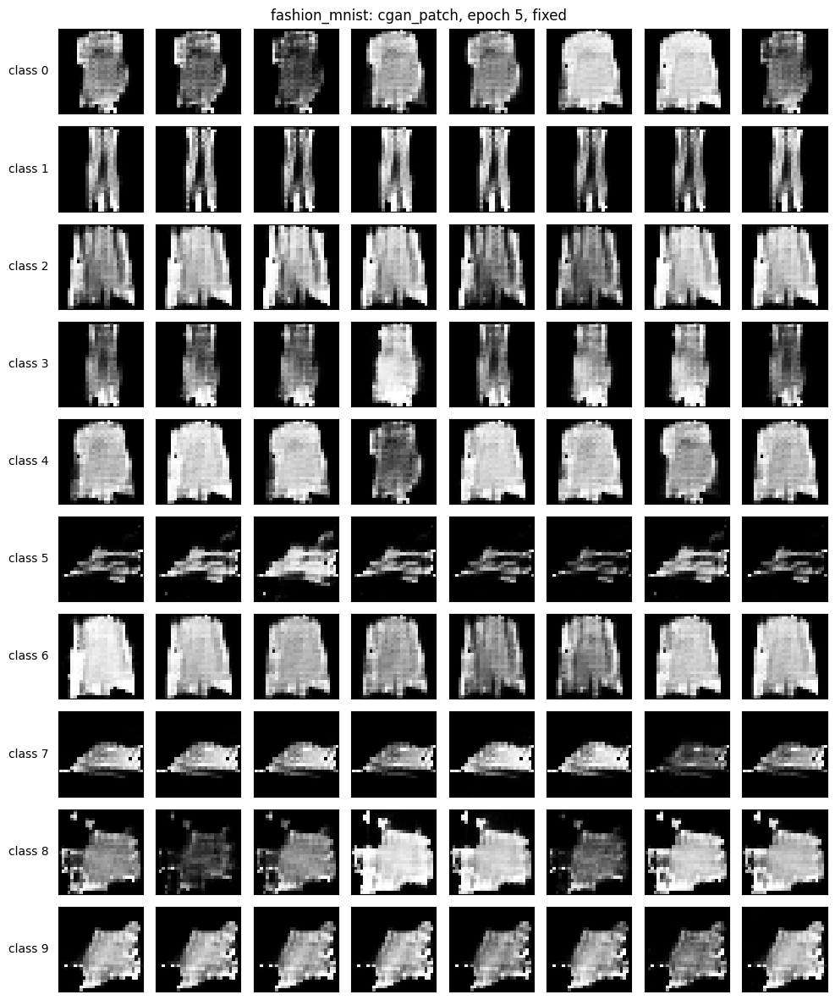

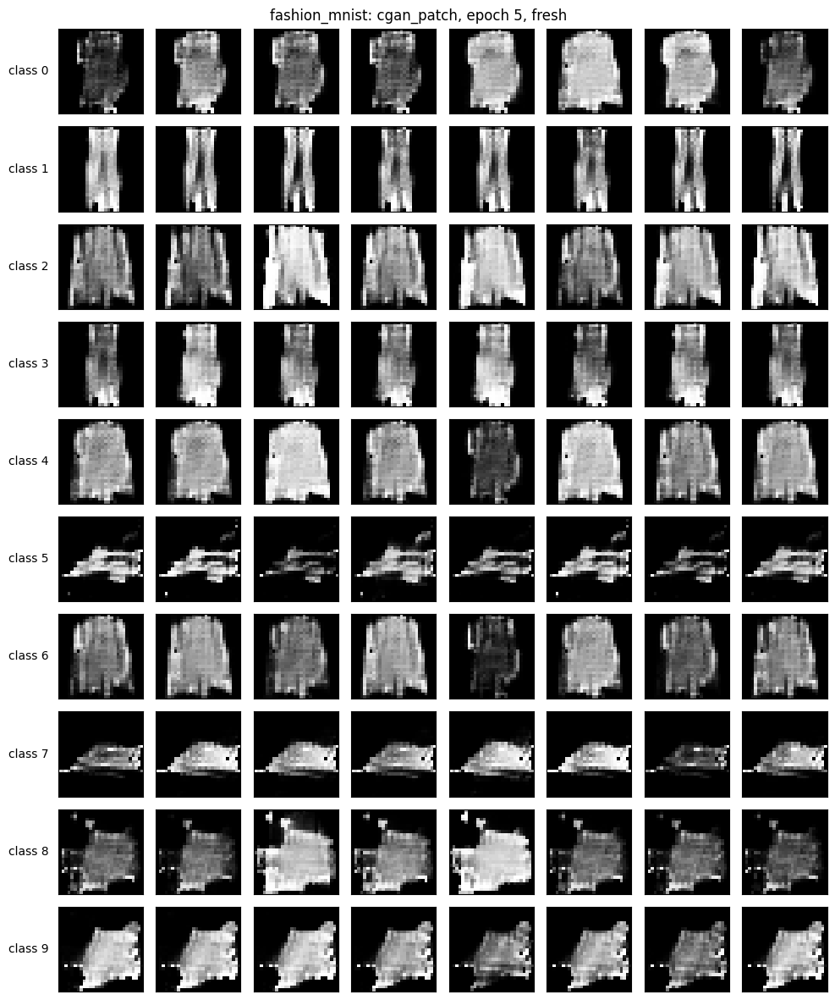

fashion_mnist cgan_patch | 6/40 | G total 0.706, adv 0.706, FM 0.00000, D 0.689
fashion_mnist cgan_patch | 7/40 | G total 0.706, adv 0.706, FM 0.00000, D 0.689
fashion_mnist cgan_patch | 8/40 | G total 0.705, adv 0.705, FM 0.00000, D 0.689
fashion_mnist cgan_patch | 9/40 | G total 0.706, adv 0.706, FM 0.00000, D 0.689
fashion_mnist cgan_patch | 10/40 | G total 0.704, adv 0.704, FM 0.00000, D 0.690


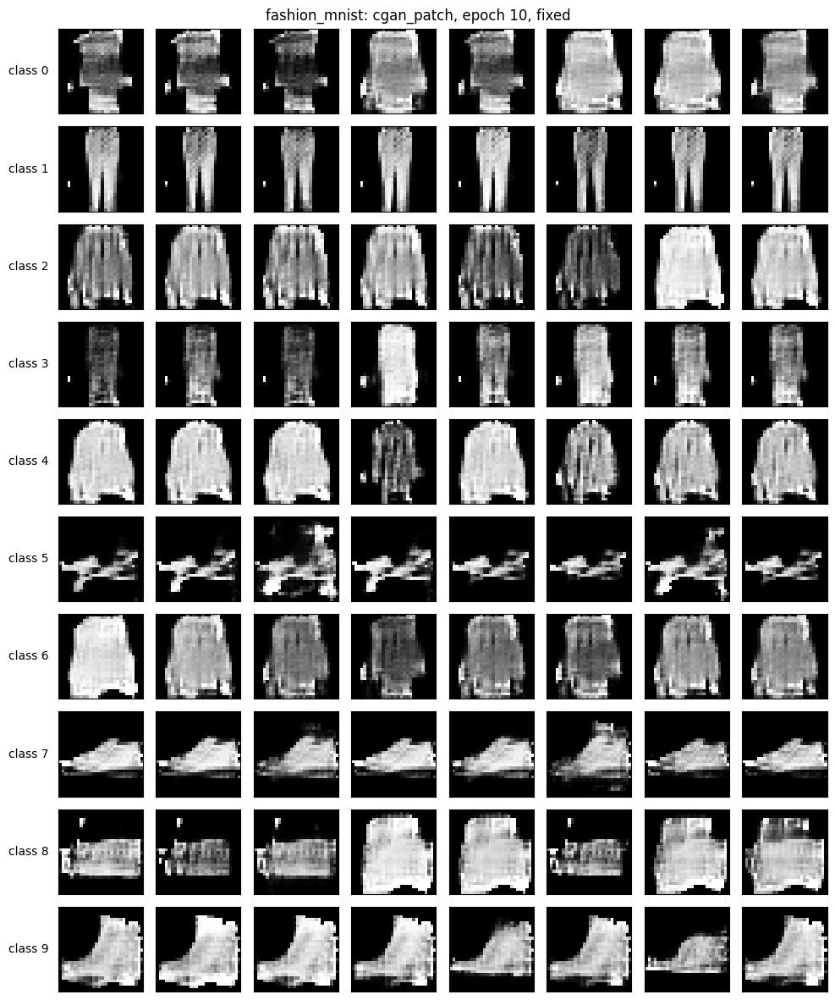

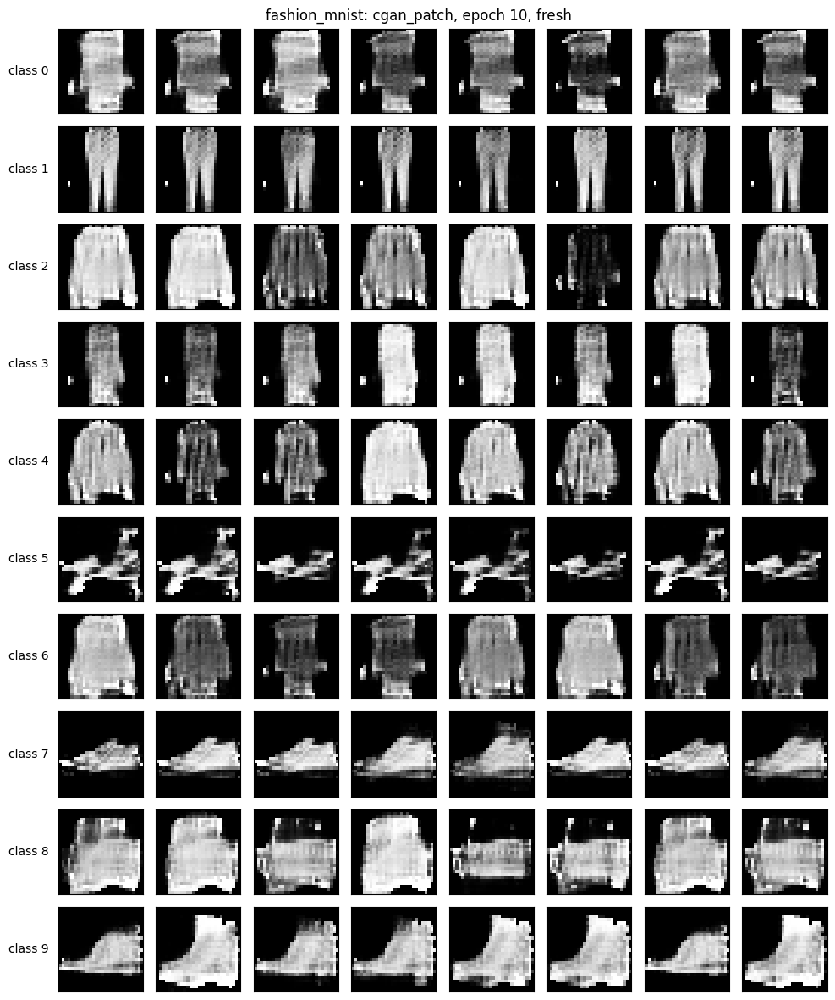

fashion_mnist cgan_patch | 11/40 | G total 0.703, adv 0.703, FM 0.00000, D 0.690
fashion_mnist cgan_patch | 12/40 | G total 0.703, adv 0.703, FM 0.00000, D 0.690
fashion_mnist cgan_patch | 13/40 | G total 0.703, adv 0.703, FM 0.00000, D 0.690
fashion_mnist cgan_patch | 14/40 | G total 0.704, adv 0.704, FM 0.00000, D 0.690
fashion_mnist cgan_patch | 15/40 | G total 0.700, adv 0.700, FM 0.00000, D 0.691


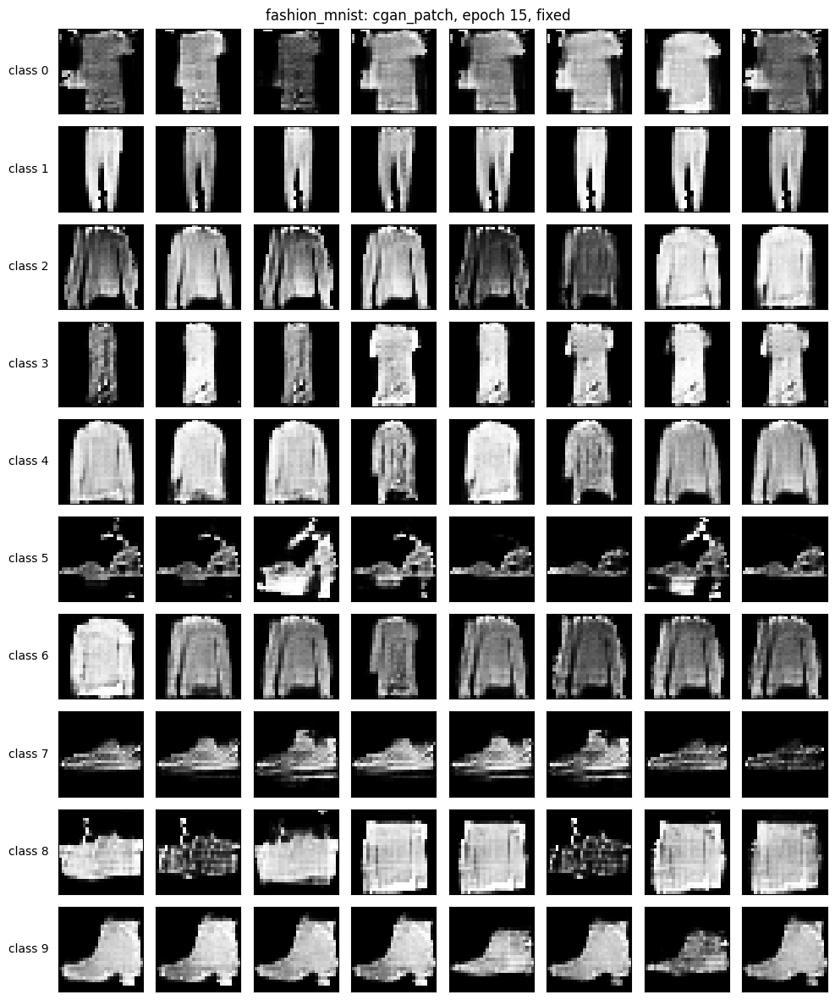

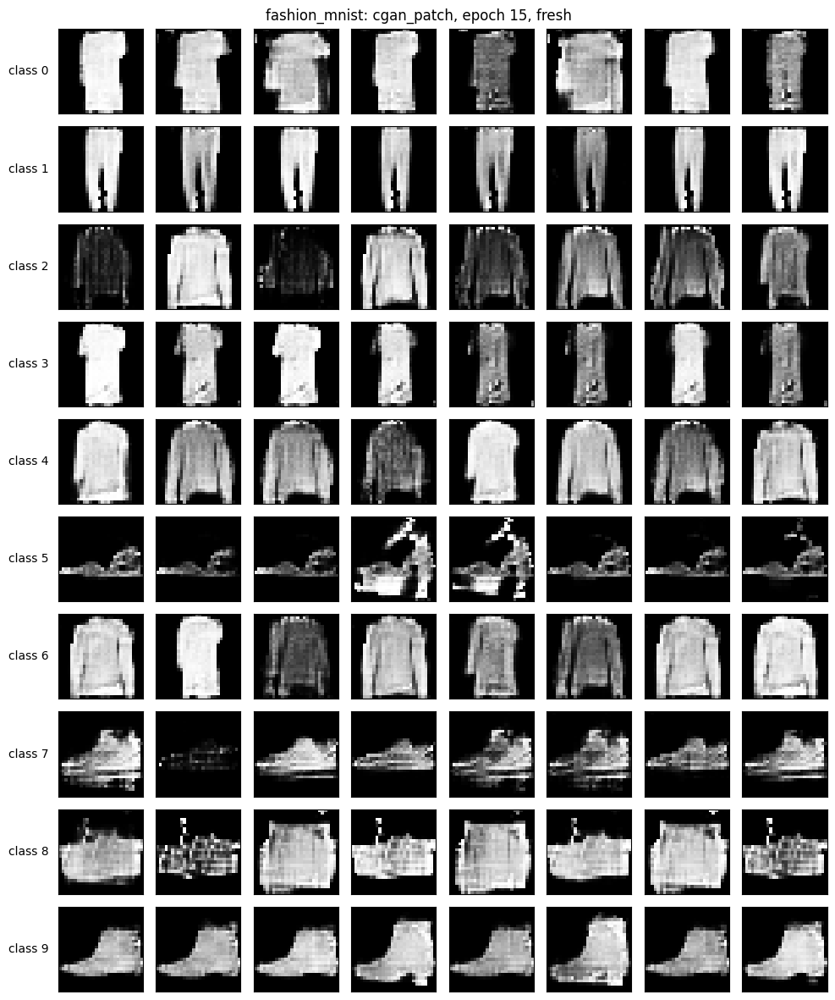

fashion_mnist cgan_patch | 16/40 | G total 0.699, adv 0.699, FM 0.00000, D 0.692
fashion_mnist cgan_patch | 17/40 | G total 0.698, adv 0.698, FM 0.00000, D 0.692
fashion_mnist cgan_patch | 18/40 | G total 0.698, adv 0.698, FM 0.00000, D 0.692
fashion_mnist cgan_patch | 19/40 | G total 0.697, adv 0.697, FM 0.00000, D 0.692
fashion_mnist cgan_patch | 20/40 | G total 0.697, adv 0.697, FM 0.00000, D 0.692


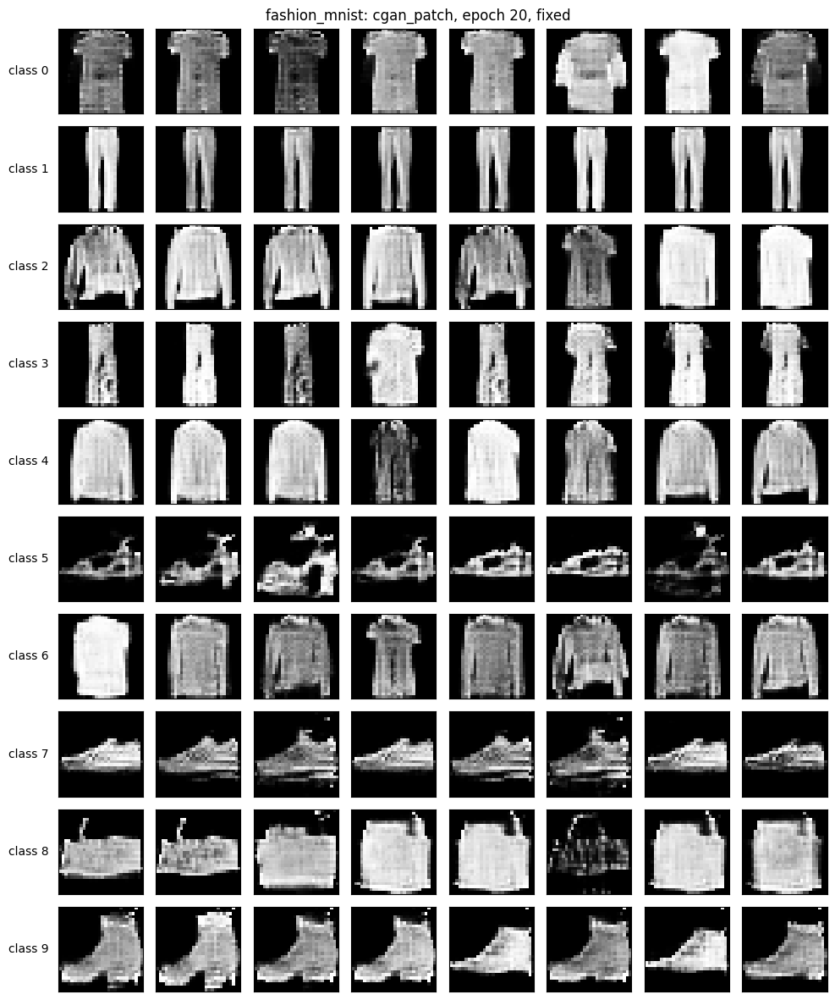

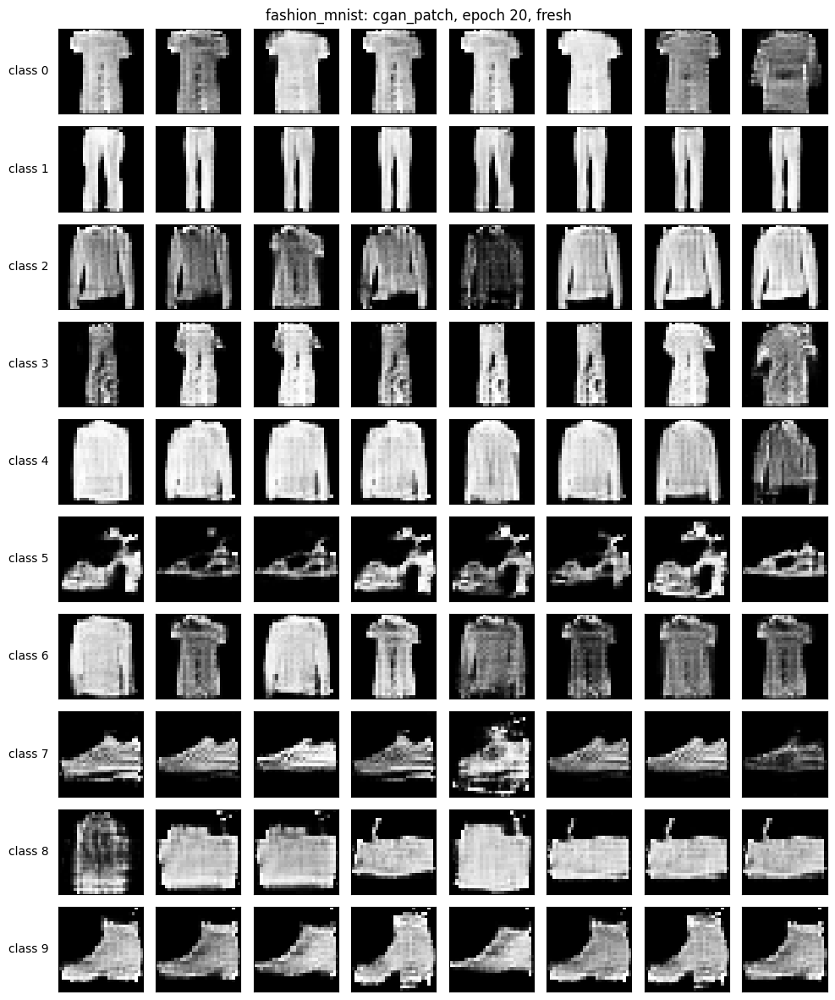

fashion_mnist cgan_patch | 21/40 | G total 0.697, adv 0.697, FM 0.00000, D 0.692
fashion_mnist cgan_patch | 22/40 | G total 0.697, adv 0.697, FM 0.00000, D 0.692
fashion_mnist cgan_patch | 23/40 | G total 0.697, adv 0.697, FM 0.00000, D 0.693
fashion_mnist cgan_patch | 24/40 | G total 0.696, adv 0.696, FM 0.00000, D 0.693
fashion_mnist cgan_patch | 25/40 | G total 0.696, adv 0.696, FM 0.00000, D 0.693


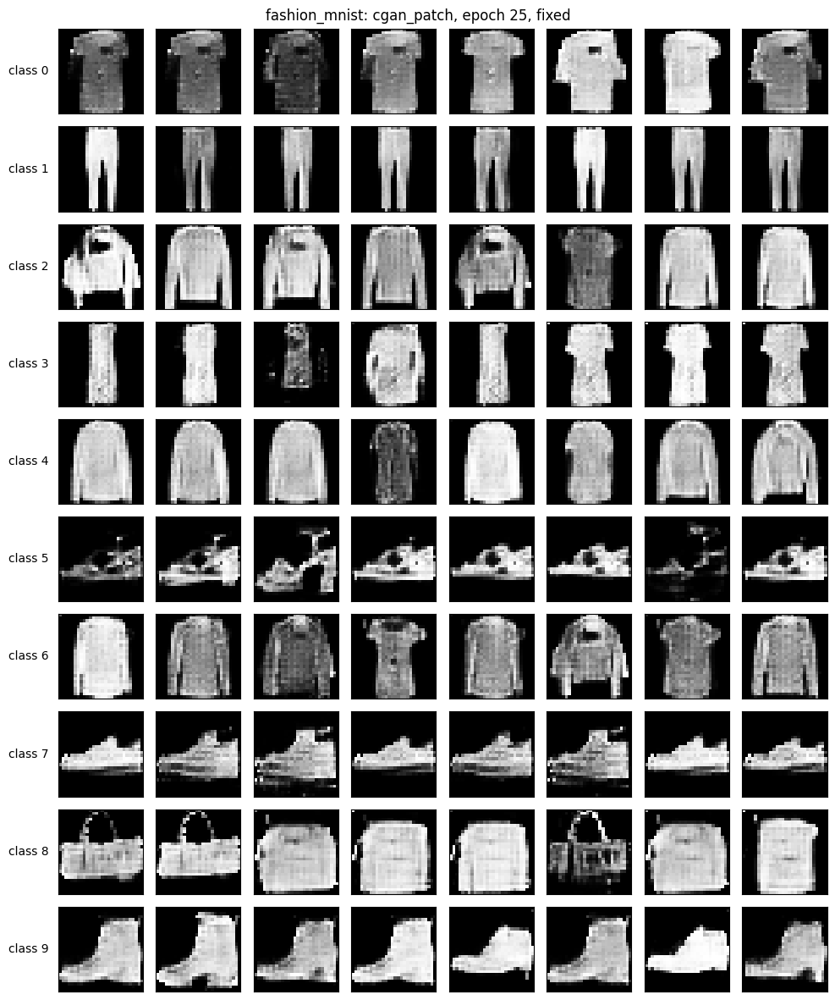

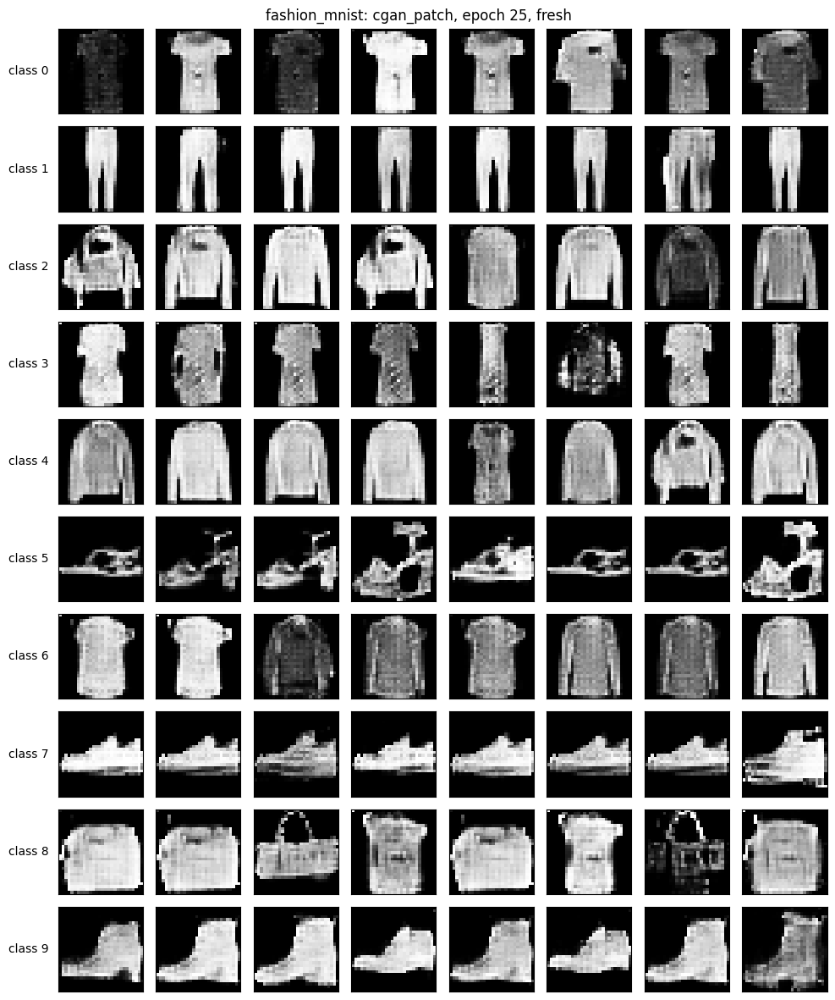

fashion_mnist cgan_patch | 26/40 | G total 0.696, adv 0.696, FM 0.00000, D 0.693
fashion_mnist cgan_patch | 27/40 | G total 0.696, adv 0.696, FM 0.00000, D 0.693
fashion_mnist cgan_patch | 28/40 | G total 0.695, adv 0.695, FM 0.00000, D 0.693
fashion_mnist cgan_patch | 29/40 | G total 0.696, adv 0.696, FM 0.00000, D 0.693
fashion_mnist cgan_patch | 30/40 | G total 0.696, adv 0.696, FM 0.00000, D 0.693


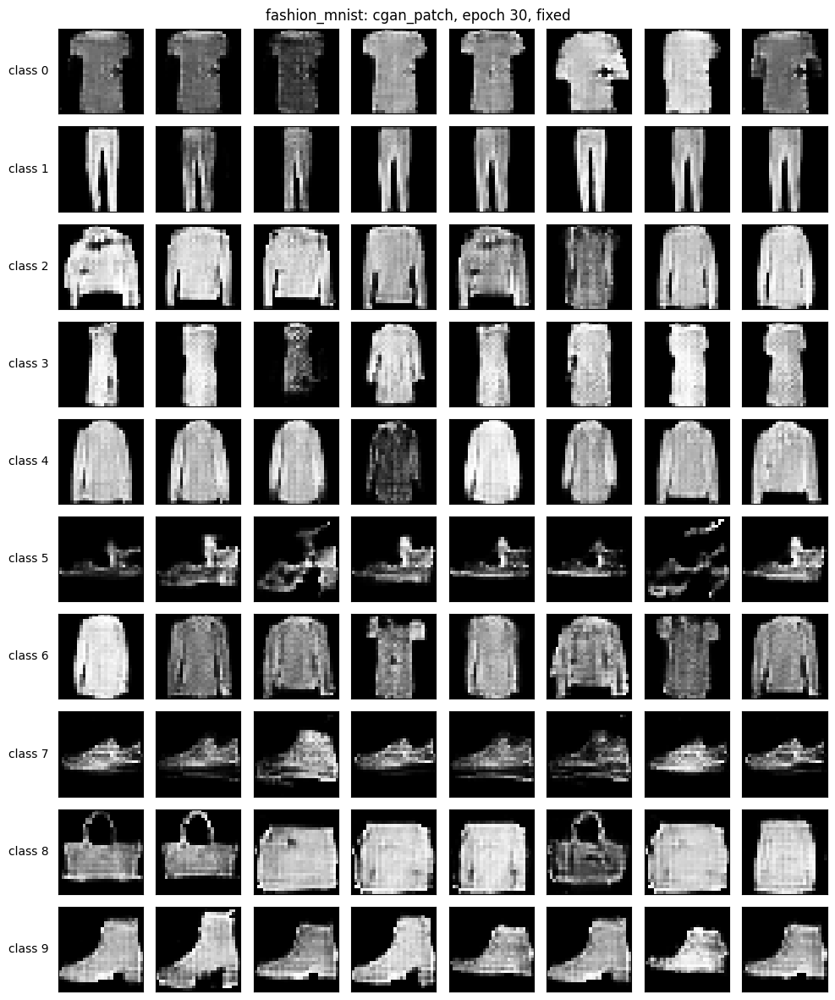

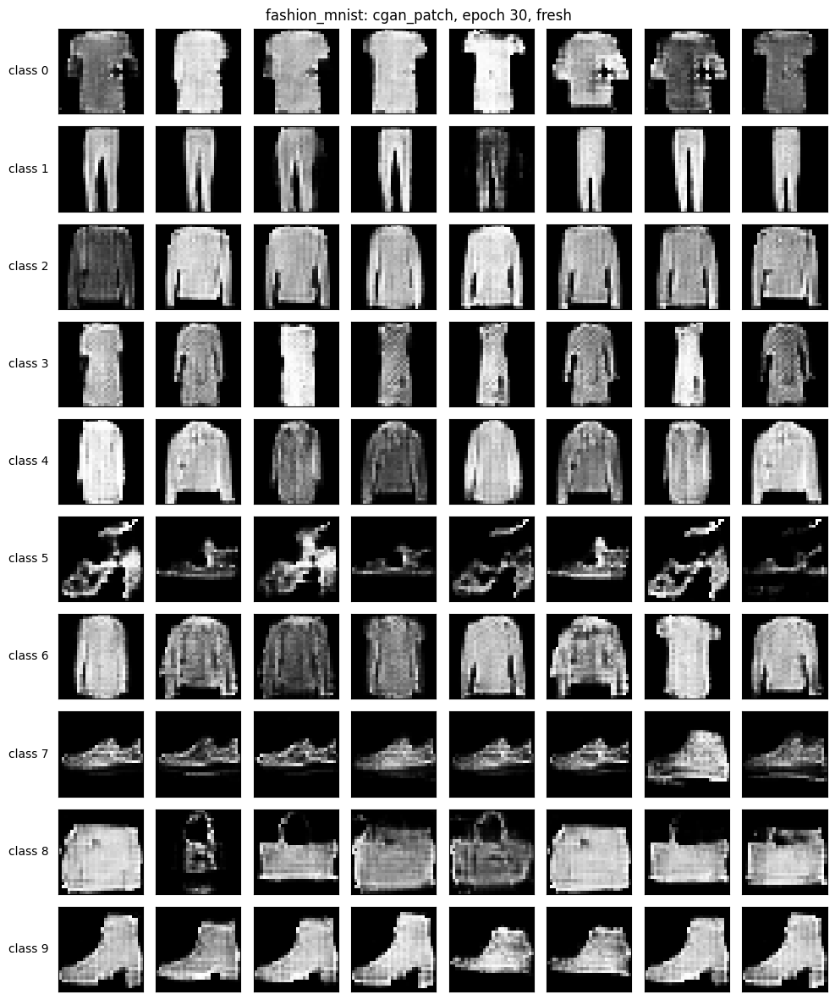

fashion_mnist cgan_patch | 31/40 | G total 0.696, adv 0.696, FM 0.00000, D 0.693
fashion_mnist cgan_patch | 32/40 | G total 0.696, adv 0.696, FM 0.00000, D 0.692
fashion_mnist cgan_patch | 33/40 | G total 0.696, adv 0.696, FM 0.00000, D 0.692
fashion_mnist cgan_patch | 34/40 | G total 0.696, adv 0.696, FM 0.00000, D 0.693
fashion_mnist cgan_patch | 35/40 | G total 0.696, adv 0.696, FM 0.00000, D 0.692


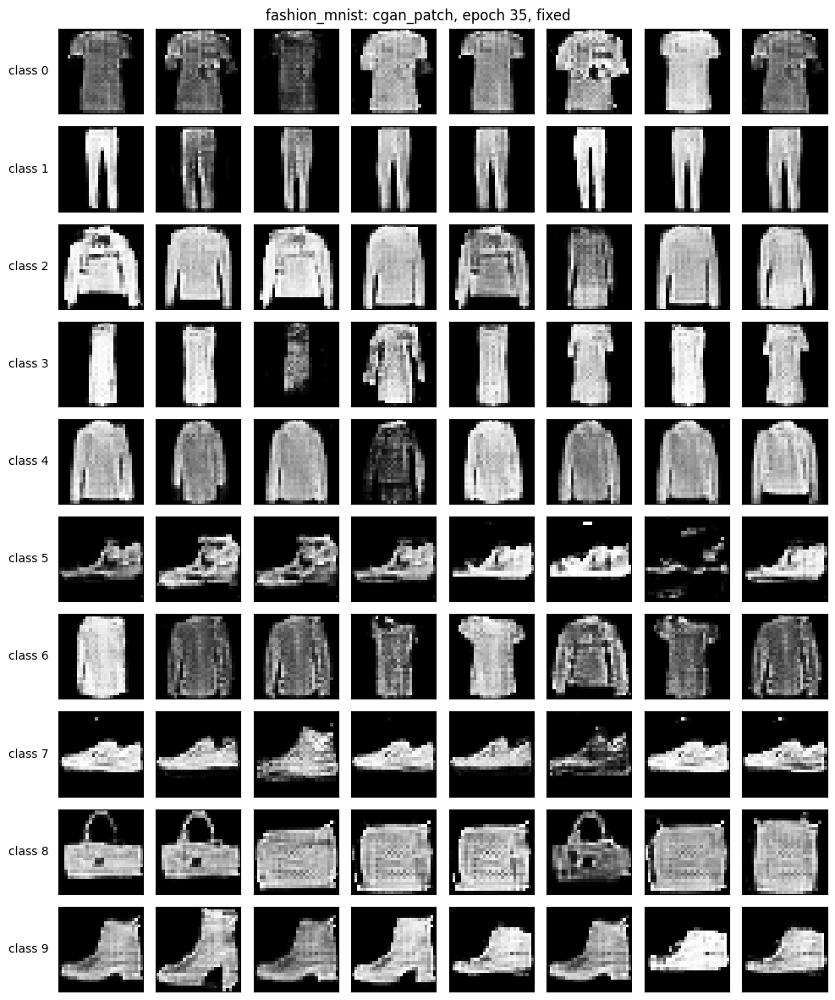

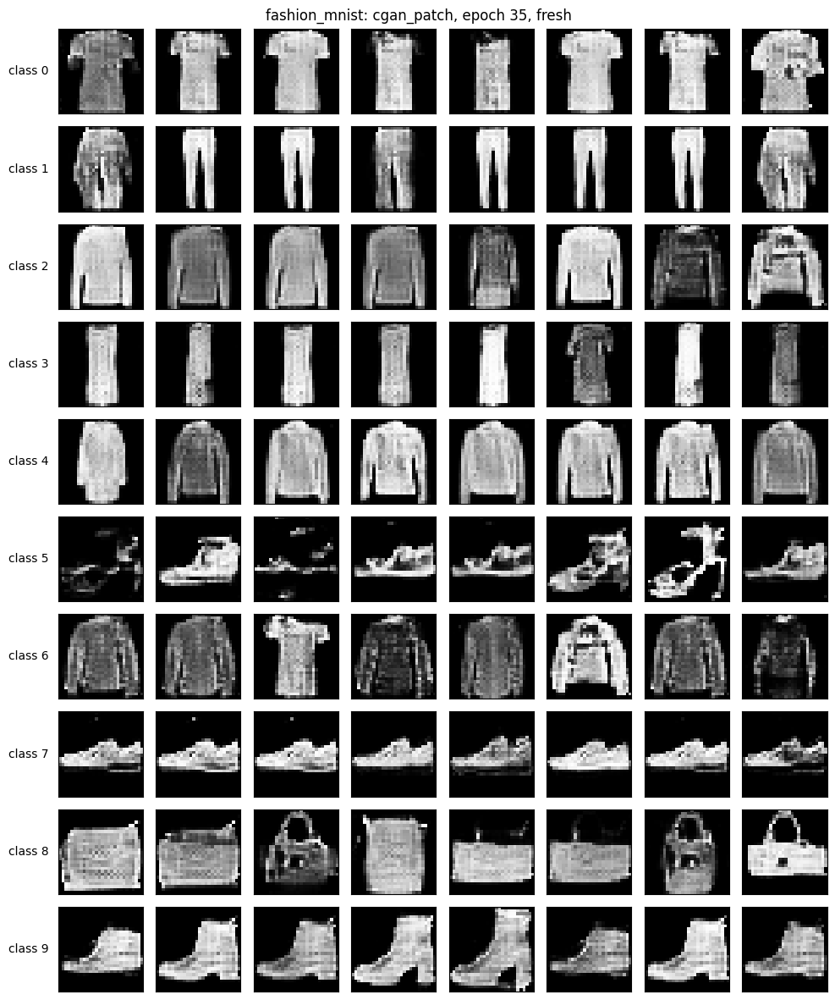

fashion_mnist cgan_patch | 36/40 | G total 0.696, adv 0.696, FM 0.00000, D 0.693
fashion_mnist cgan_patch | 37/40 | G total 0.696, adv 0.696, FM 0.00000, D 0.692
fashion_mnist cgan_patch | 38/40 | G total 0.696, adv 0.696, FM 0.00000, D 0.692
fashion_mnist cgan_patch | 39/40 | G total 0.696, adv 0.696, FM 0.00000, D 0.692
fashion_mnist cgan_patch | 40/40 | G total 0.696, adv 0.696, FM 0.00000, D 0.692


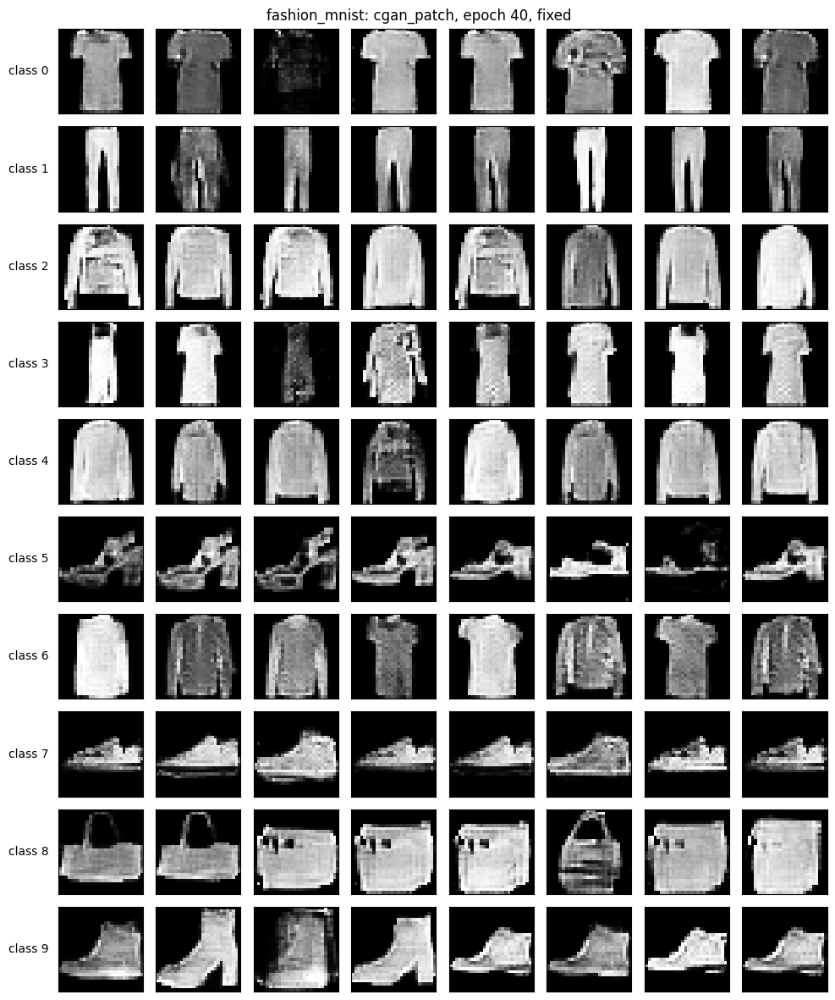

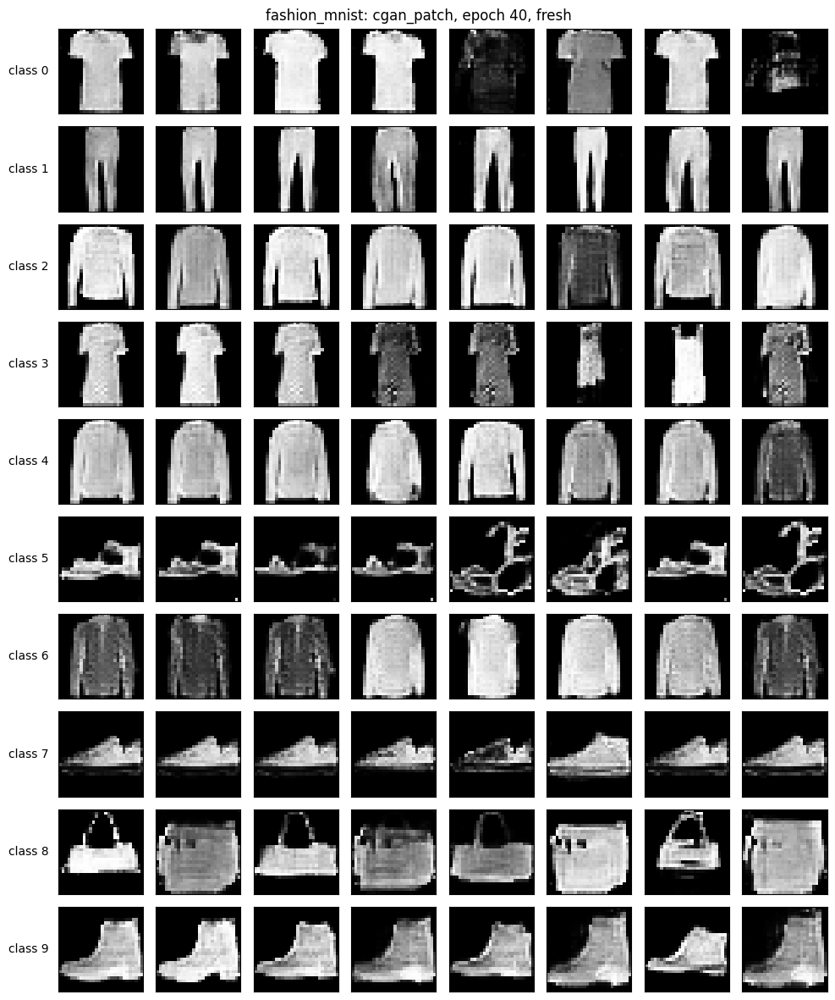

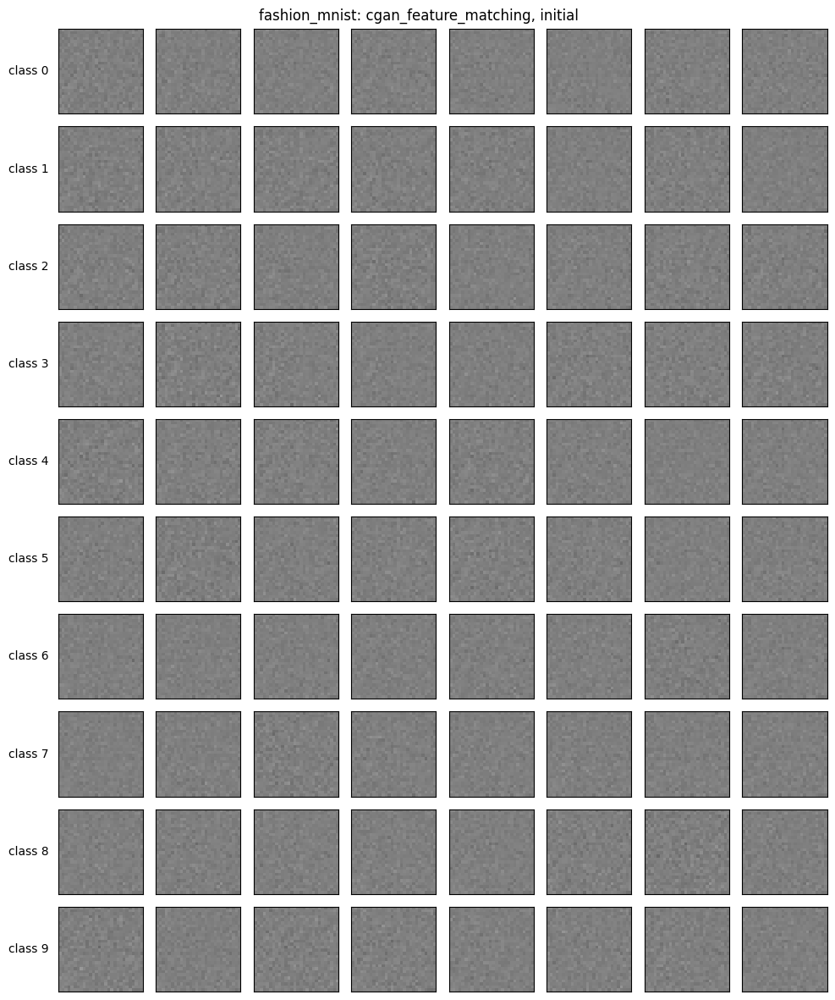

fashion_mnist cgan_feature_matching | 1/40 | G total 0.929, adv 0.880, FM 0.00490, D 0.640


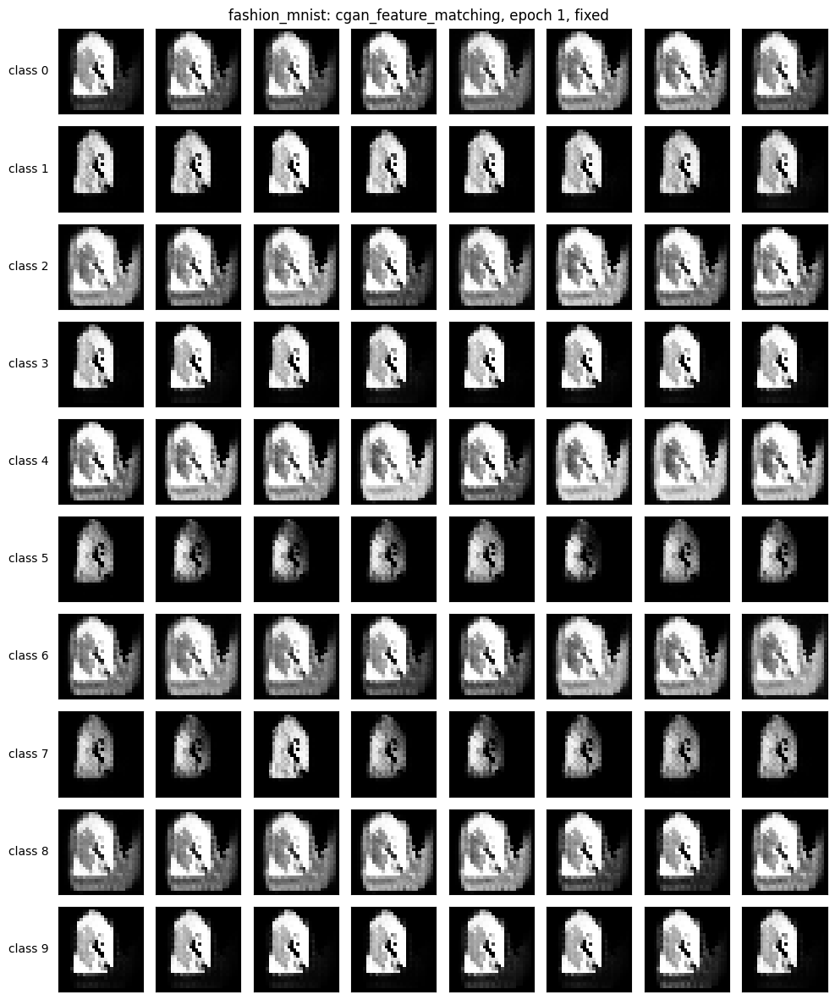

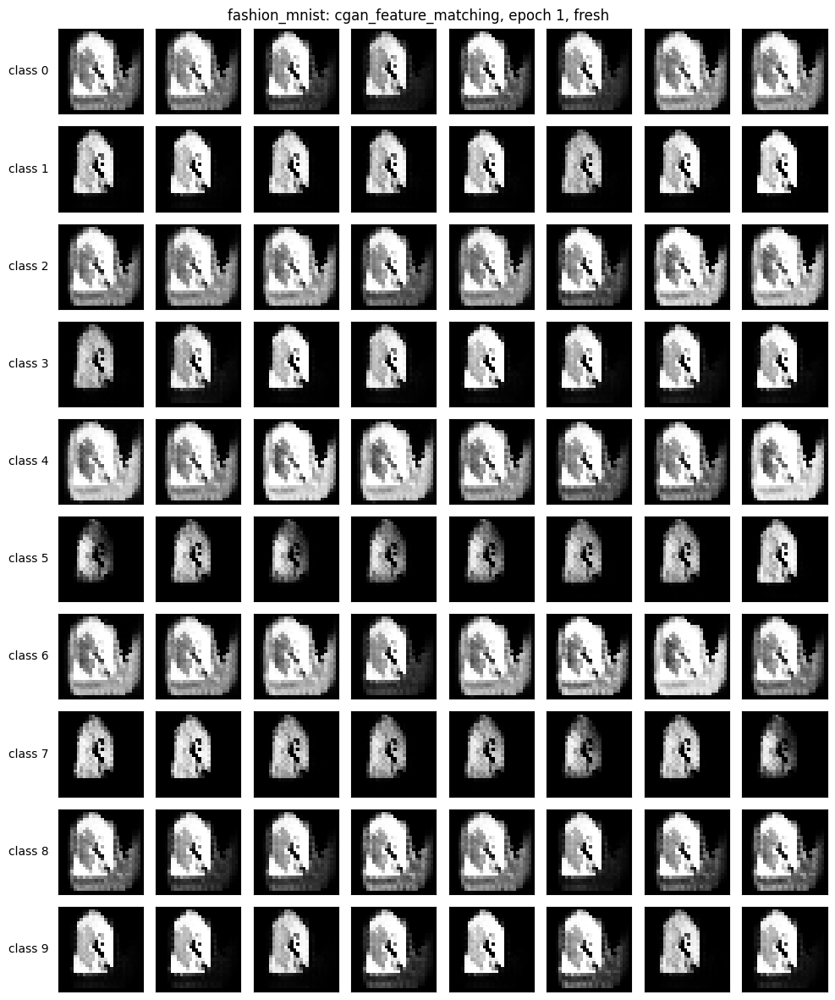

fashion_mnist cgan_feature_matching | 2/40 | G total 0.777, adv 0.767, FM 0.00097, D 0.650
fashion_mnist cgan_feature_matching | 3/40 | G total 0.837, adv 0.820, FM 0.00169, D 0.633
fashion_mnist cgan_feature_matching | 4/40 | G total 0.791, adv 0.775, FM 0.00160, D 0.661
fashion_mnist cgan_feature_matching | 5/40 | G total 0.725, adv 0.714, FM 0.00113, D 0.689


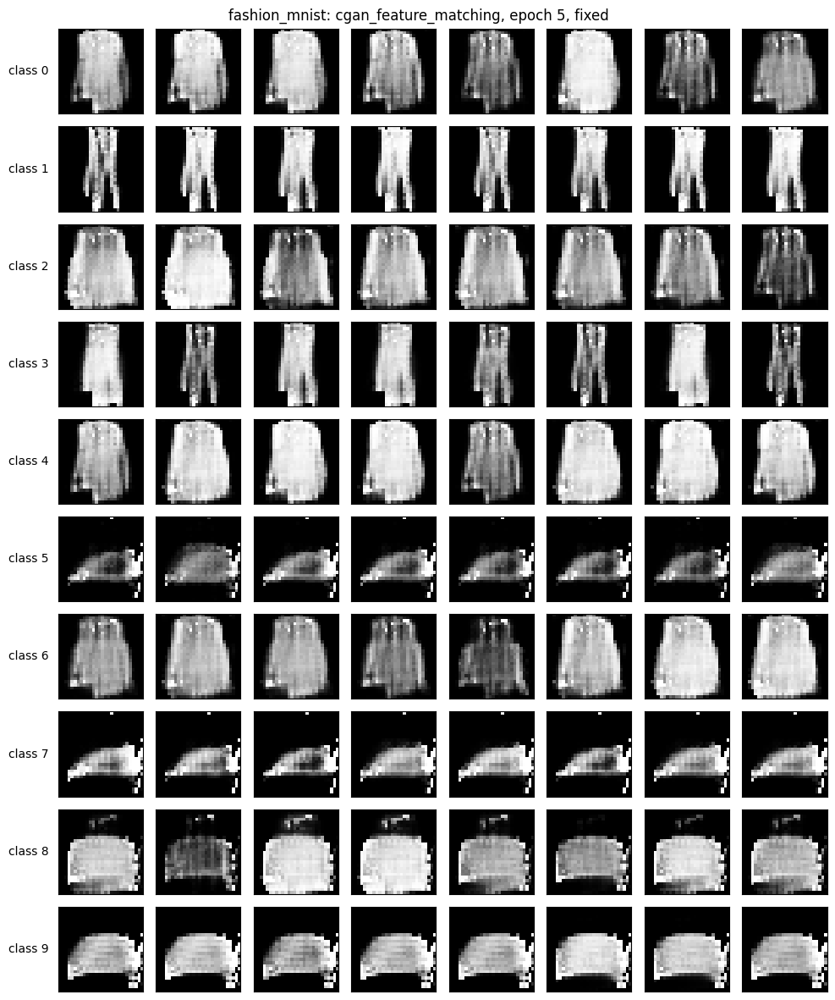

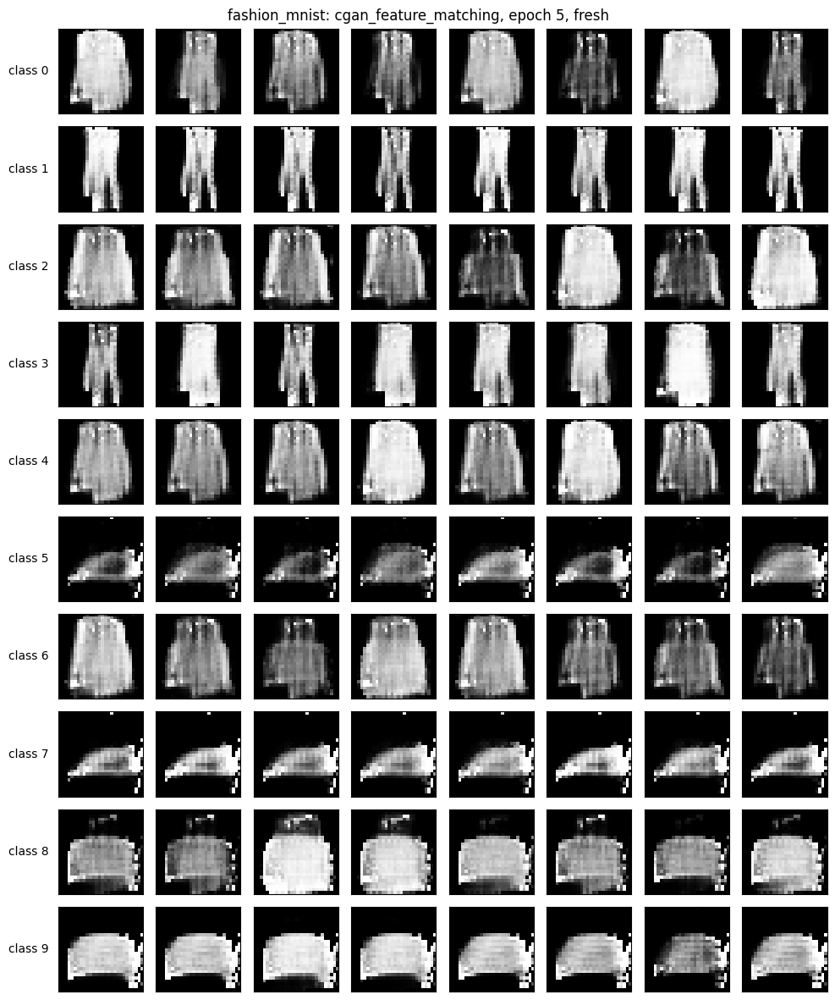

fashion_mnist cgan_feature_matching | 6/40 | G total 0.738, adv 0.727, FM 0.00113, D 0.679
fashion_mnist cgan_feature_matching | 7/40 | G total 0.743, adv 0.730, FM 0.00128, D 0.678
fashion_mnist cgan_feature_matching | 8/40 | G total 0.741, adv 0.730, FM 0.00116, D 0.678
fashion_mnist cgan_feature_matching | 9/40 | G total 0.739, adv 0.727, FM 0.00122, D 0.680
fashion_mnist cgan_feature_matching | 10/40 | G total 0.736, adv 0.723, FM 0.00122, D 0.681


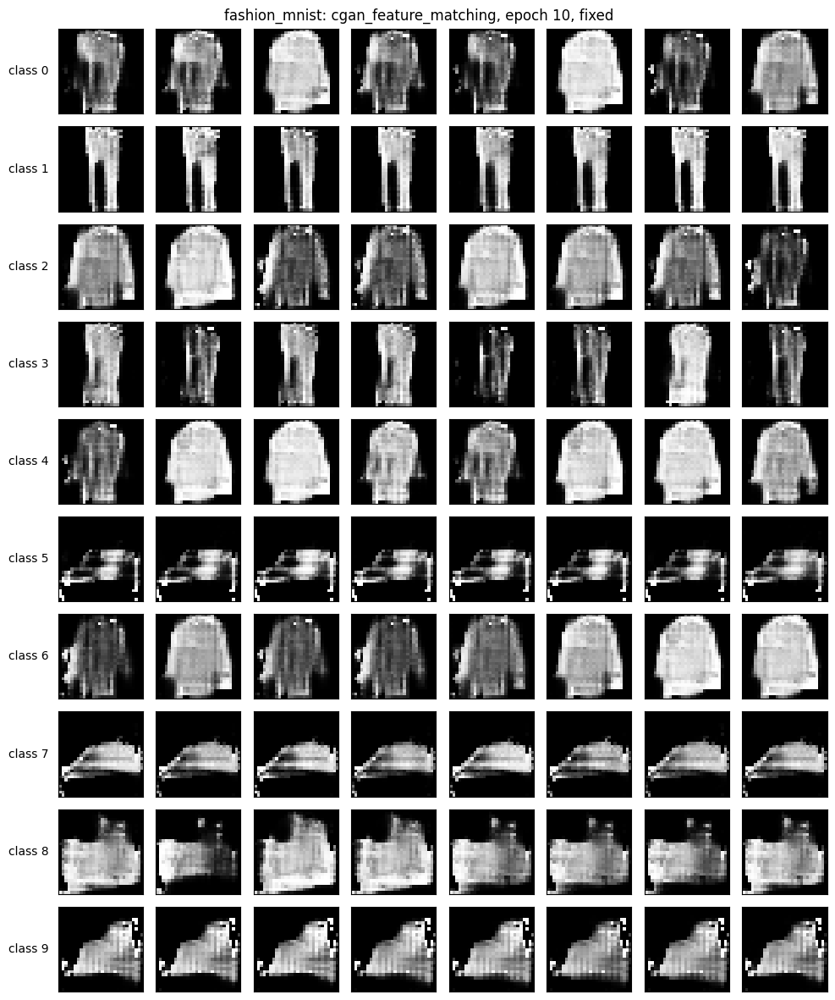

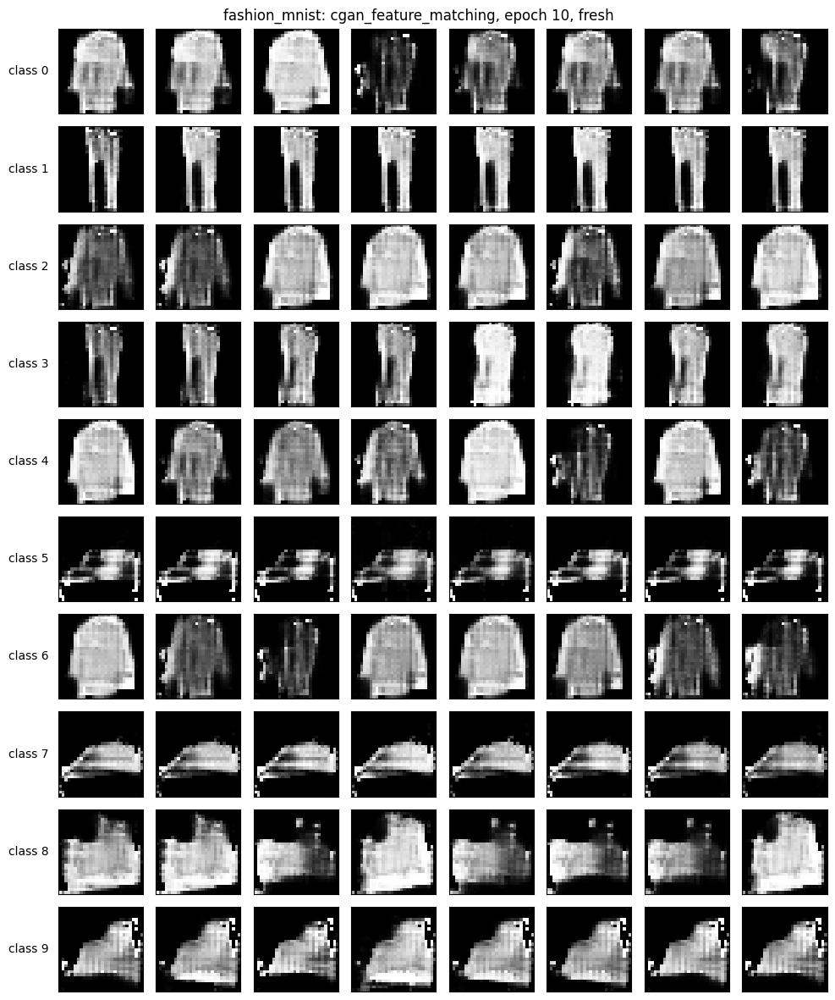

fashion_mnist cgan_feature_matching | 11/40 | G total 0.722, adv 0.711, FM 0.00116, D 0.689
fashion_mnist cgan_feature_matching | 12/40 | G total 0.720, adv 0.709, FM 0.00109, D 0.688
fashion_mnist cgan_feature_matching | 13/40 | G total 0.723, adv 0.712, FM 0.00106, D 0.687
fashion_mnist cgan_feature_matching | 14/40 | G total 0.722, adv 0.711, FM 0.00117, D 0.688
fashion_mnist cgan_feature_matching | 15/40 | G total 0.720, adv 0.707, FM 0.00125, D 0.691


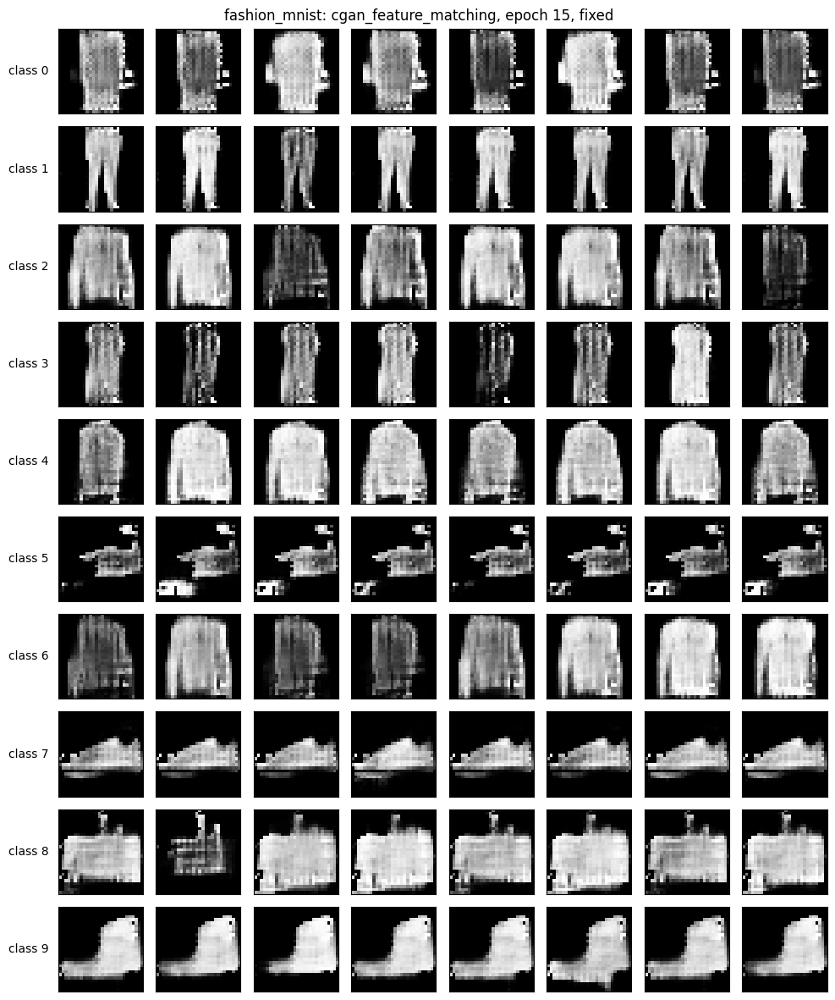

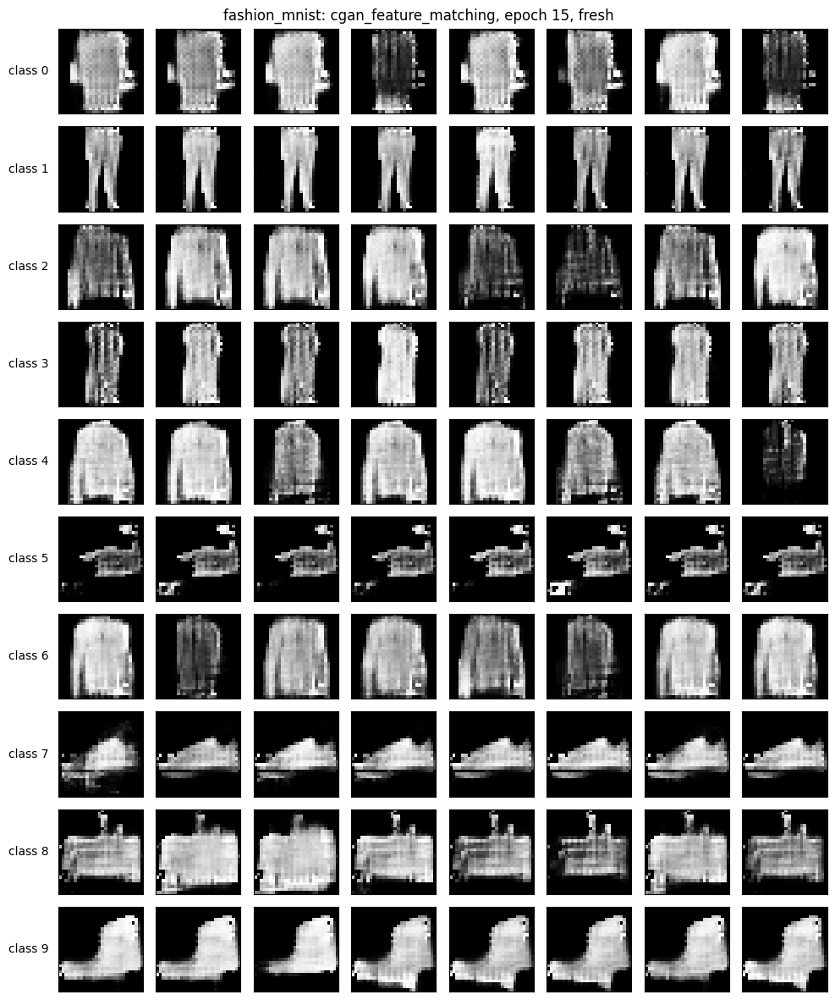

fashion_mnist cgan_feature_matching | 16/40 | G total 0.717, adv 0.706, FM 0.00110, D 0.689
fashion_mnist cgan_feature_matching | 17/40 | G total 0.715, adv 0.705, FM 0.00109, D 0.690
fashion_mnist cgan_feature_matching | 18/40 | G total 0.715, adv 0.705, FM 0.00096, D 0.690
fashion_mnist cgan_feature_matching | 19/40 | G total 0.716, adv 0.707, FM 0.00086, D 0.690
fashion_mnist cgan_feature_matching | 20/40 | G total 0.713, adv 0.705, FM 0.00079, D 0.690


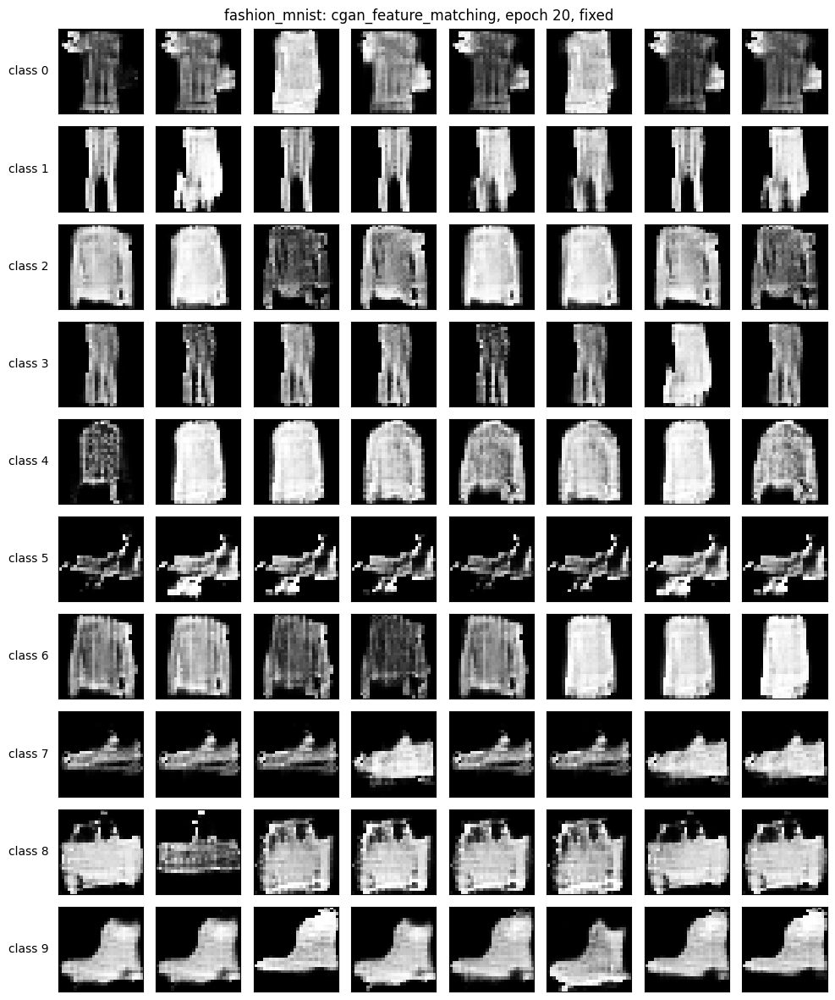

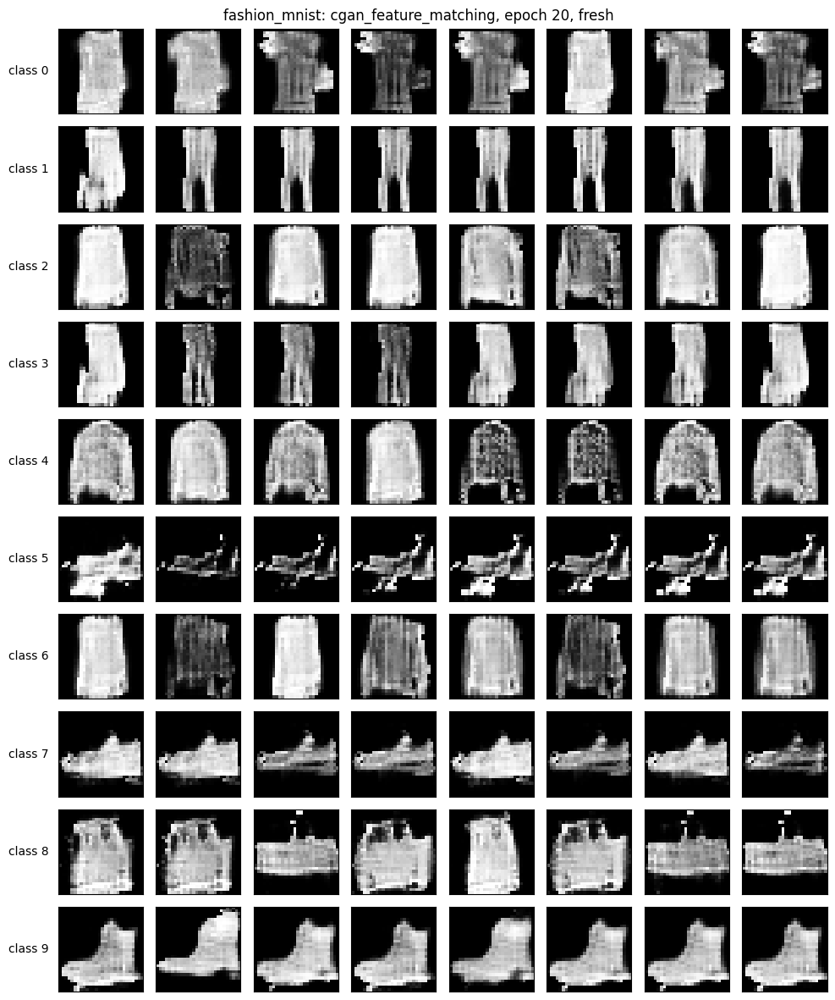

fashion_mnist cgan_feature_matching | 21/40 | G total 0.711, adv 0.703, FM 0.00078, D 0.690
fashion_mnist cgan_feature_matching | 22/40 | G total 0.710, adv 0.702, FM 0.00075, D 0.691
fashion_mnist cgan_feature_matching | 23/40 | G total 0.709, adv 0.702, FM 0.00077, D 0.691
fashion_mnist cgan_feature_matching | 24/40 | G total 0.710, adv 0.703, FM 0.00072, D 0.692
fashion_mnist cgan_feature_matching | 25/40 | G total 0.709, adv 0.702, FM 0.00068, D 0.692


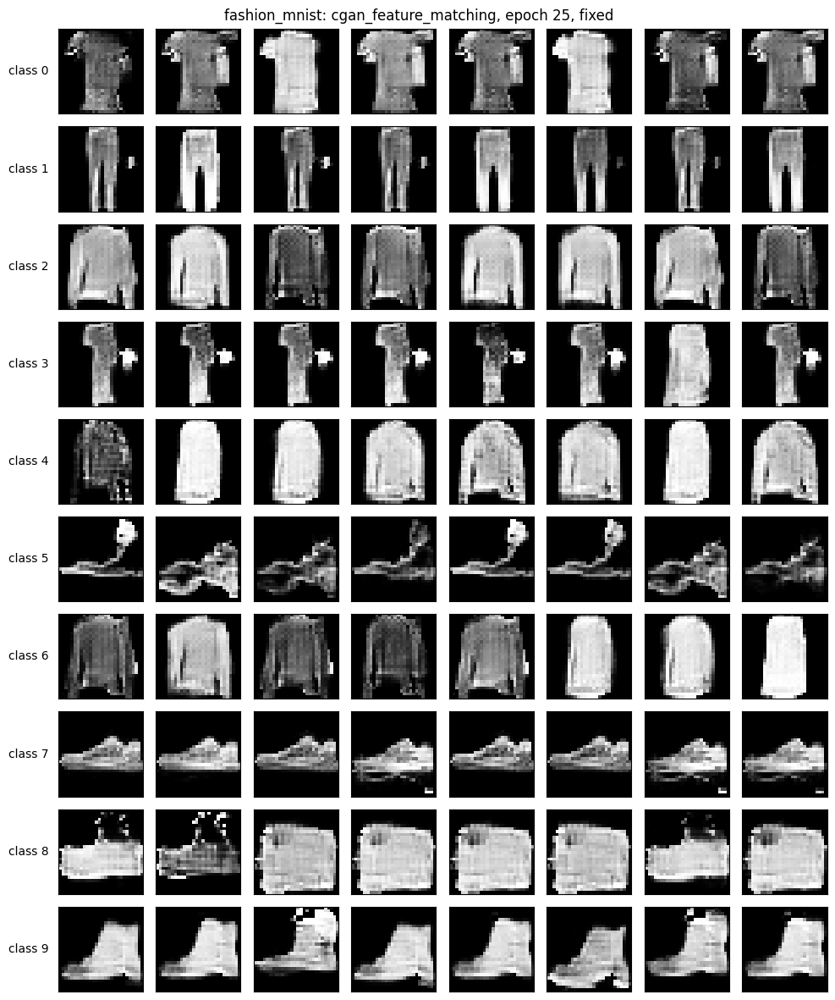

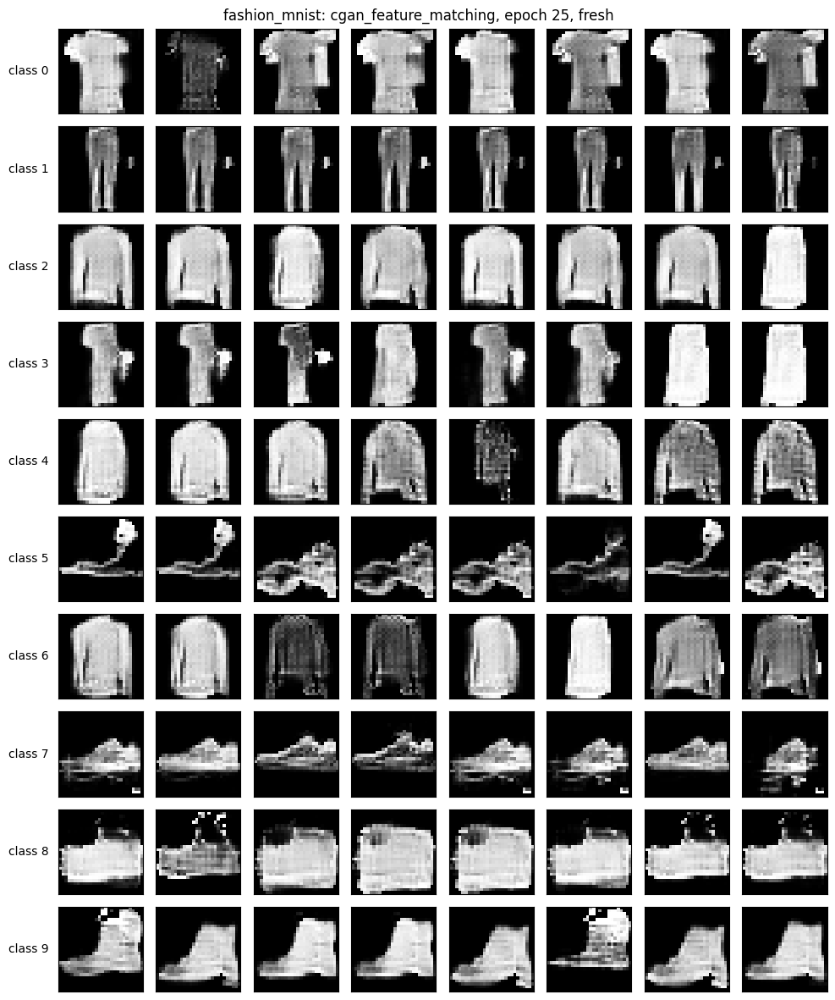

fashion_mnist cgan_feature_matching | 26/40 | G total 0.707, adv 0.701, FM 0.00061, D 0.691
fashion_mnist cgan_feature_matching | 27/40 | G total 0.708, adv 0.702, FM 0.00059, D 0.691
fashion_mnist cgan_feature_matching | 28/40 | G total 0.708, adv 0.702, FM 0.00060, D 0.691
fashion_mnist cgan_feature_matching | 29/40 | G total 0.707, adv 0.702, FM 0.00054, D 0.691
fashion_mnist cgan_feature_matching | 30/40 | G total 0.707, adv 0.702, FM 0.00053, D 0.691


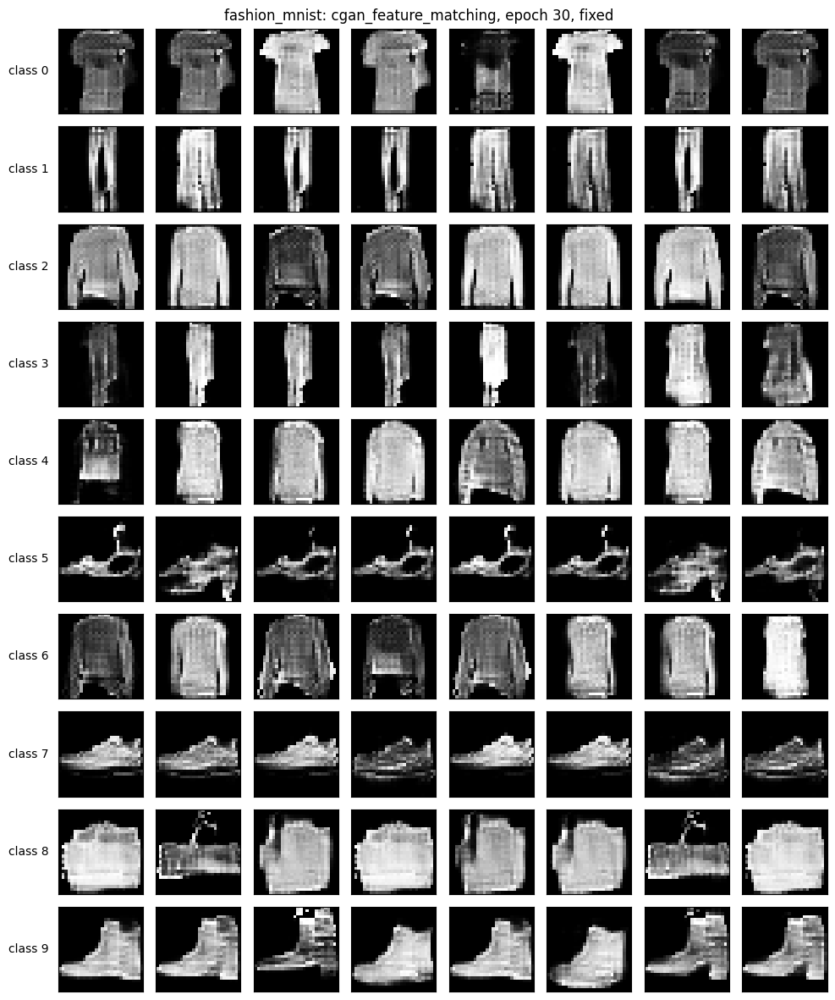

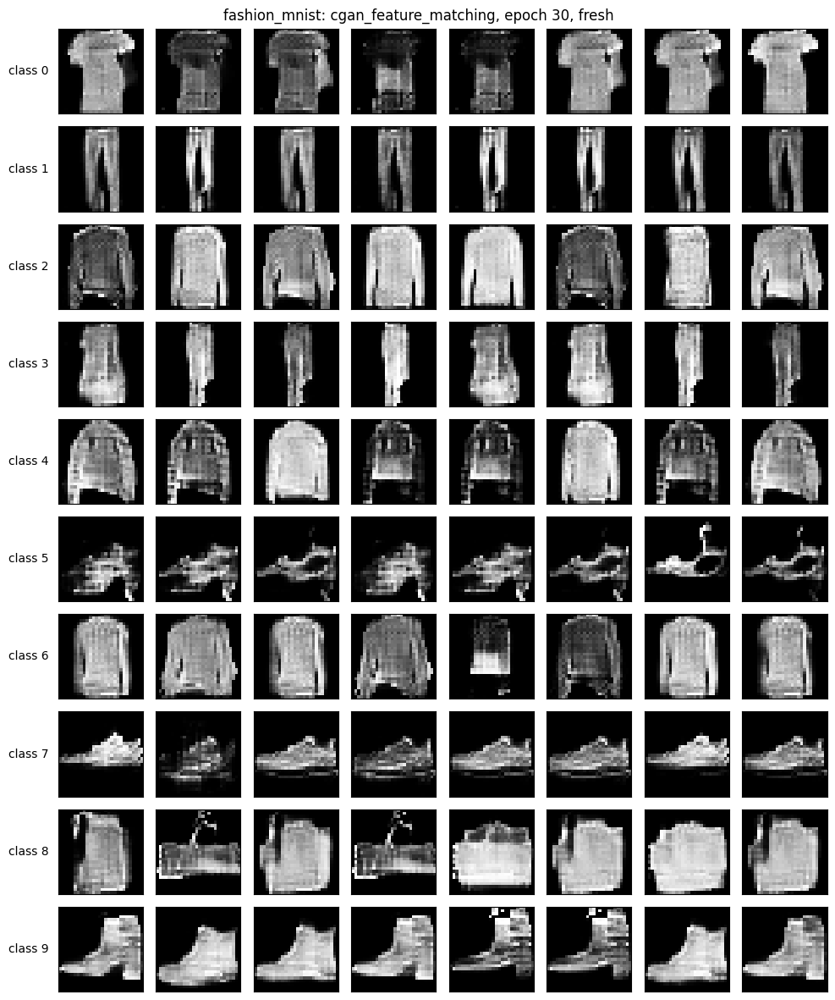

fashion_mnist cgan_feature_matching | 31/40 | G total 0.706, adv 0.701, FM 0.00051, D 0.691
fashion_mnist cgan_feature_matching | 32/40 | G total 0.706, adv 0.701, FM 0.00054, D 0.691
fashion_mnist cgan_feature_matching | 33/40 | G total 0.707, adv 0.702, FM 0.00051, D 0.691
fashion_mnist cgan_feature_matching | 34/40 | G total 0.706, adv 0.701, FM 0.00050, D 0.691
fashion_mnist cgan_feature_matching | 35/40 | G total 0.705, adv 0.701, FM 0.00043, D 0.691


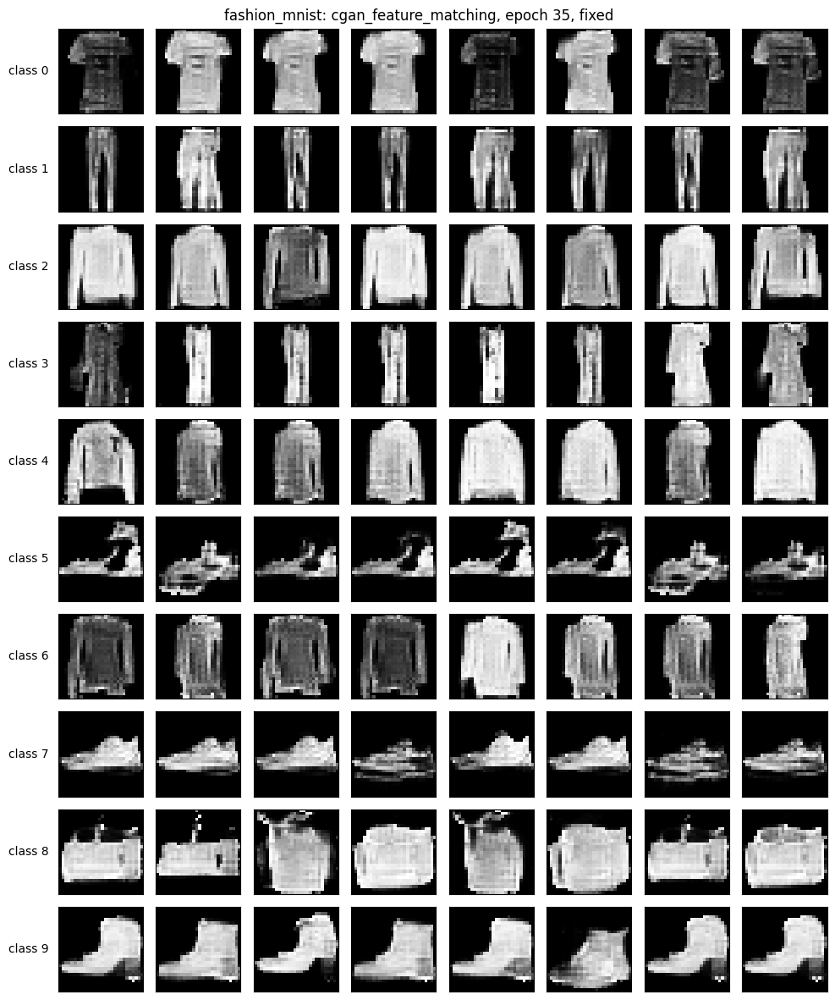

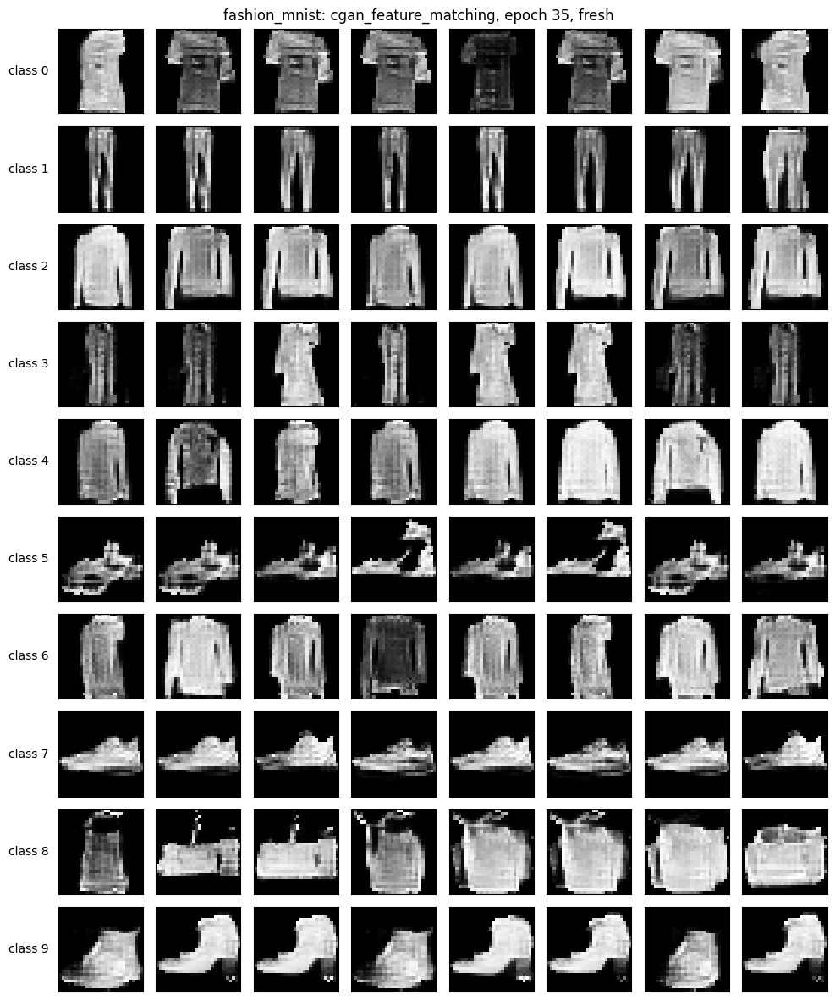

fashion_mnist cgan_feature_matching | 36/40 | G total 0.706, adv 0.701, FM 0.00043, D 0.691
fashion_mnist cgan_feature_matching | 37/40 | G total 0.706, adv 0.702, FM 0.00044, D 0.691
fashion_mnist cgan_feature_matching | 38/40 | G total 0.705, adv 0.700, FM 0.00041, D 0.691
fashion_mnist cgan_feature_matching | 39/40 | G total 0.705, adv 0.701, FM 0.00041, D 0.691
fashion_mnist cgan_feature_matching | 40/40 | G total 0.706, adv 0.702, FM 0.00043, D 0.691


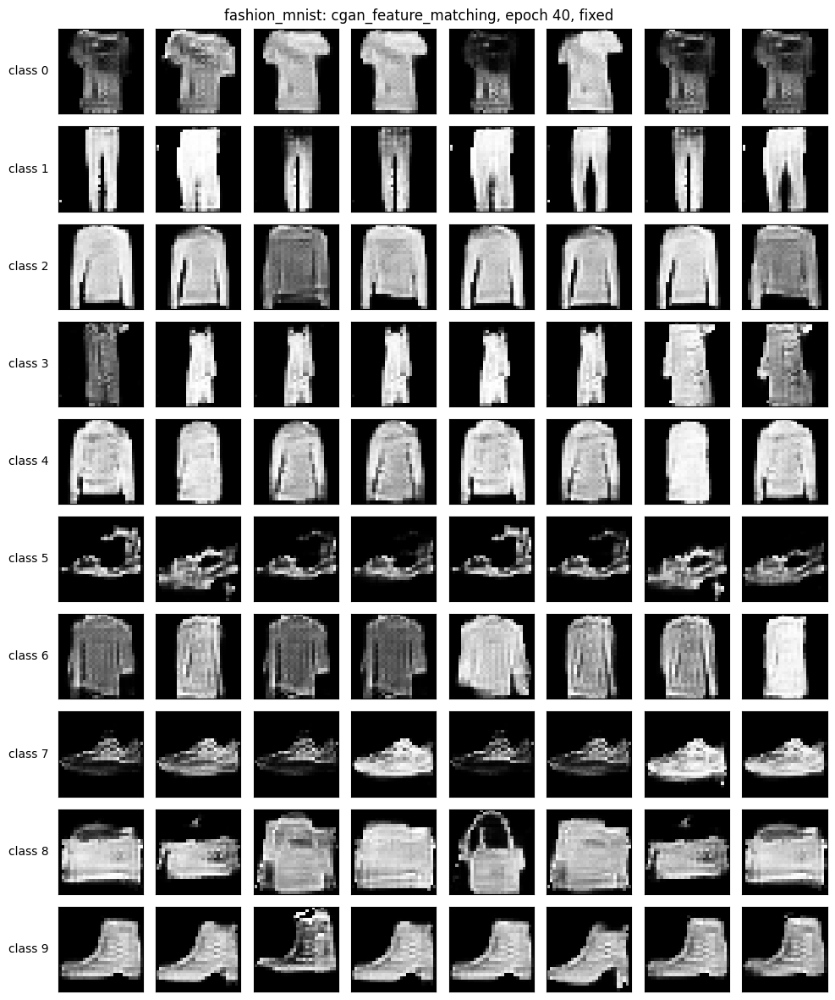

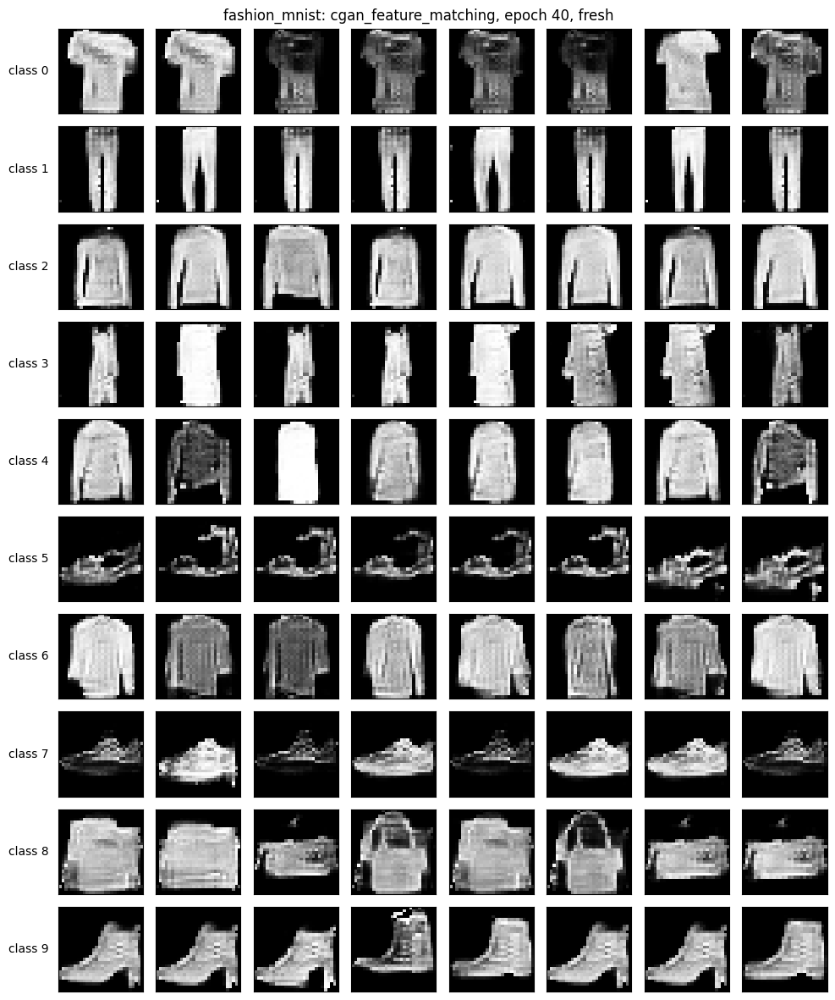

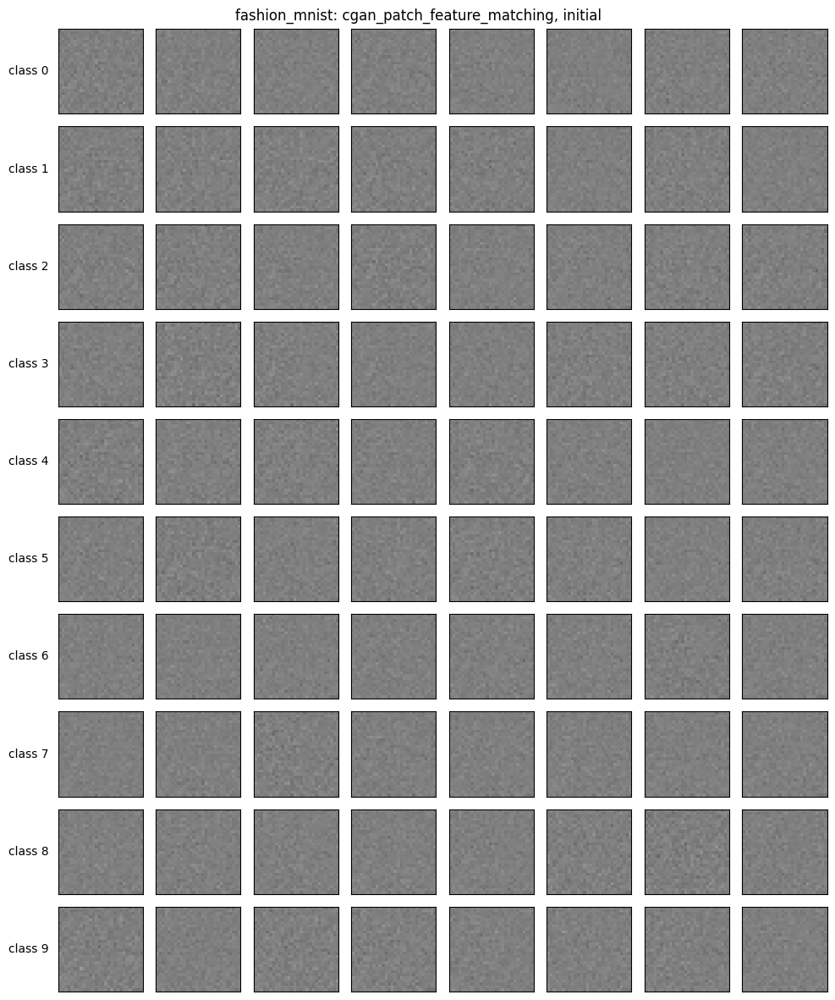

fashion_mnist cgan_patch_feature_matching | 1/40 | G total 0.862, adv 0.831, FM 0.00312, D 0.646


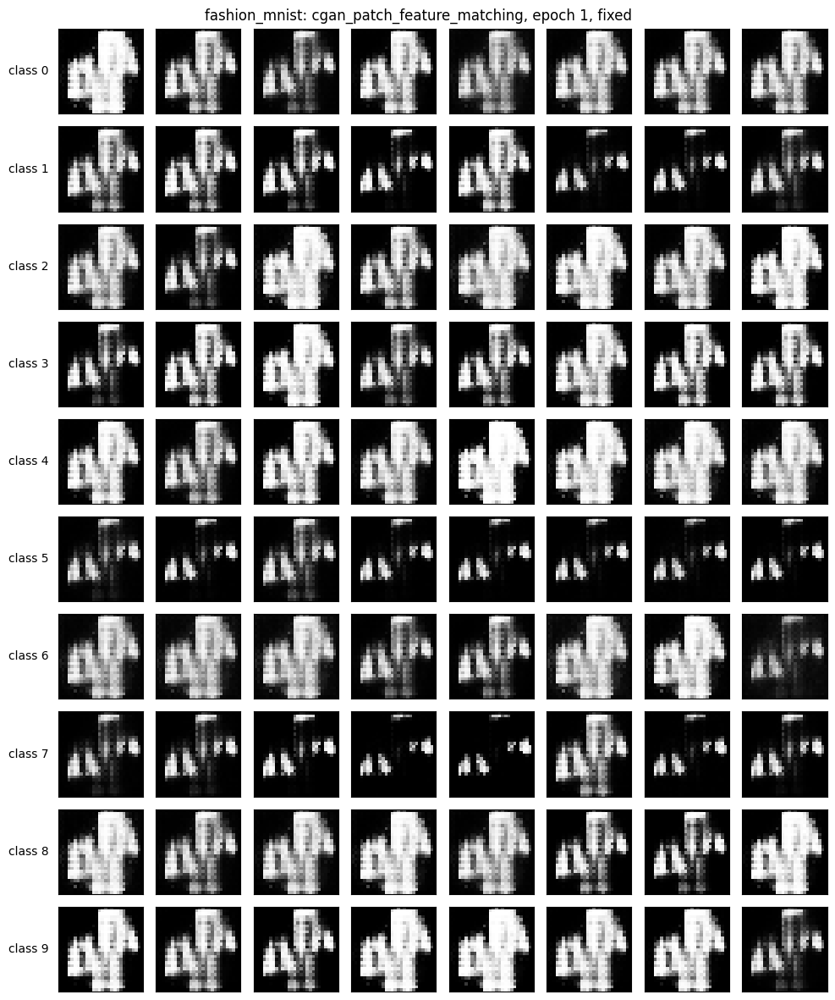

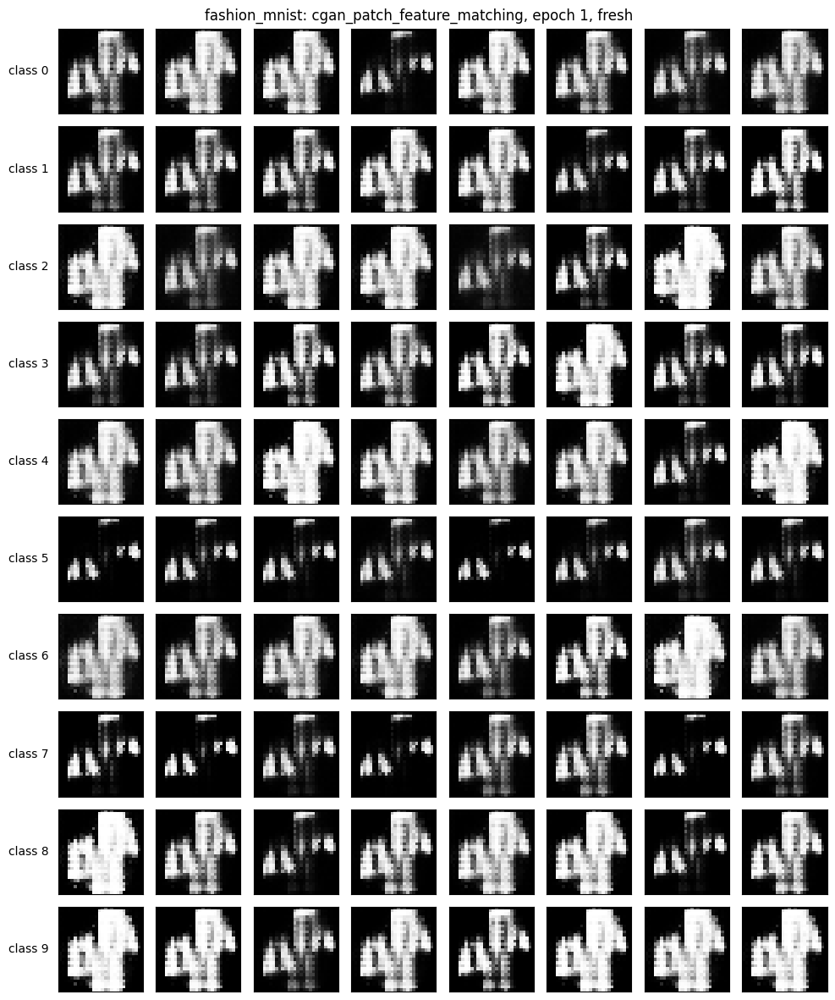

fashion_mnist cgan_patch_feature_matching | 2/40 | G total 0.789, adv 0.775, FM 0.00141, D 0.663
fashion_mnist cgan_patch_feature_matching | 3/40 | G total 0.753, adv 0.741, FM 0.00119, D 0.676
fashion_mnist cgan_patch_feature_matching | 4/40 | G total 0.742, adv 0.732, FM 0.00103, D 0.679
fashion_mnist cgan_patch_feature_matching | 5/40 | G total 0.726, adv 0.717, FM 0.00086, D 0.684


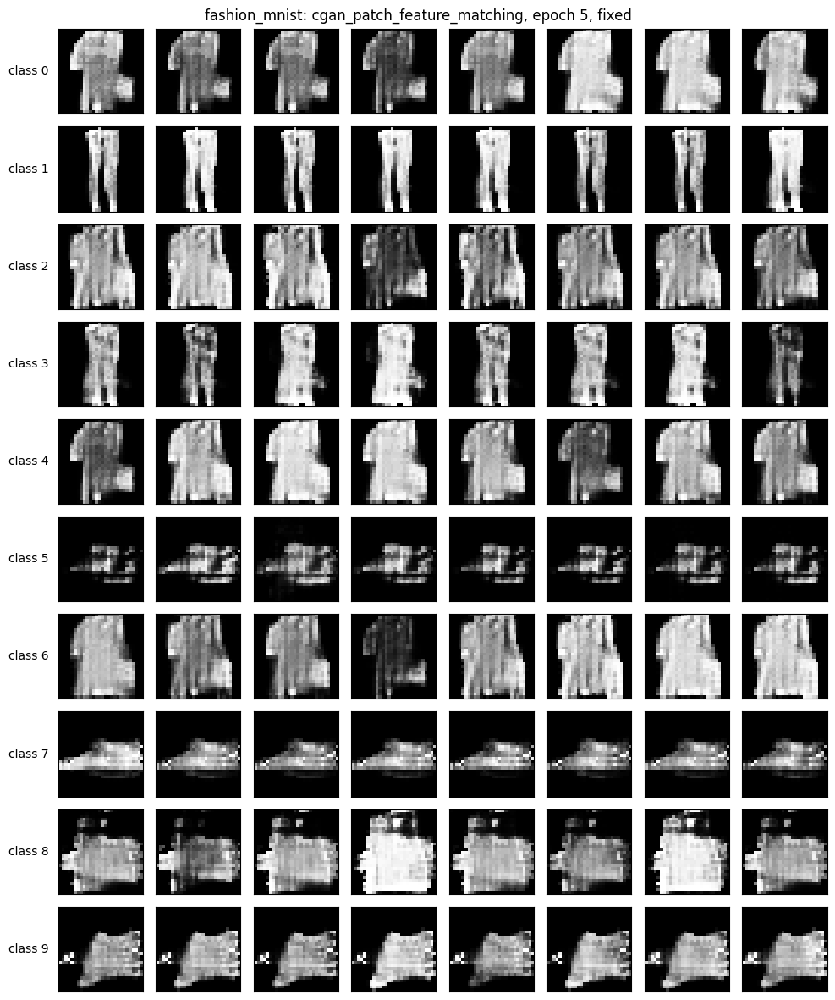

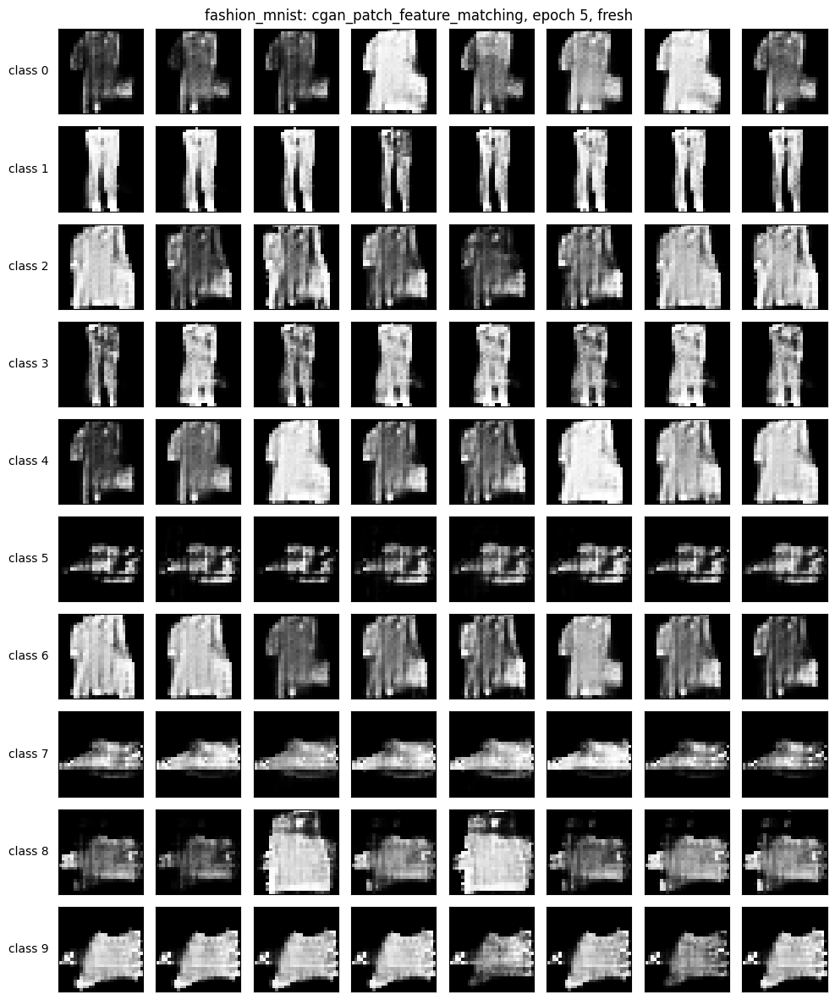

fashion_mnist cgan_patch_feature_matching | 6/40 | G total 0.718, adv 0.711, FM 0.00071, D 0.688
fashion_mnist cgan_patch_feature_matching | 7/40 | G total 0.717, adv 0.711, FM 0.00063, D 0.687
fashion_mnist cgan_patch_feature_matching | 8/40 | G total 0.716, adv 0.711, FM 0.00054, D 0.687
fashion_mnist cgan_patch_feature_matching | 9/40 | G total 0.715, adv 0.710, FM 0.00053, D 0.688
fashion_mnist cgan_patch_feature_matching | 10/40 | G total 0.715, adv 0.710, FM 0.00048, D 0.687


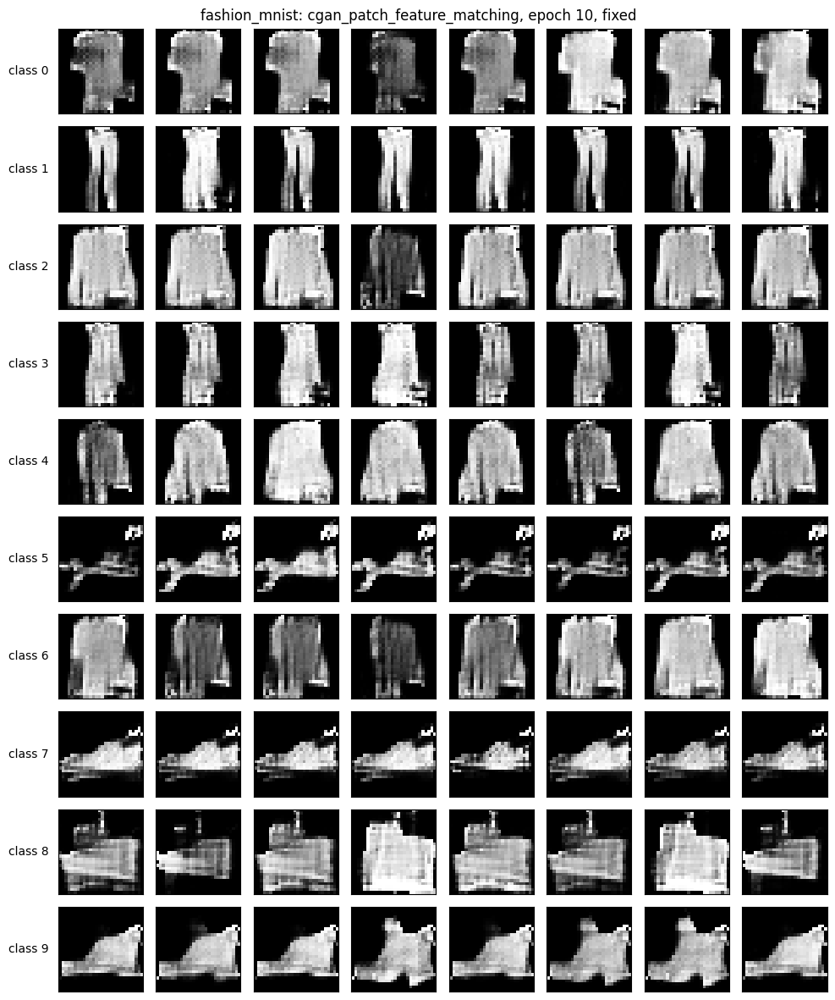

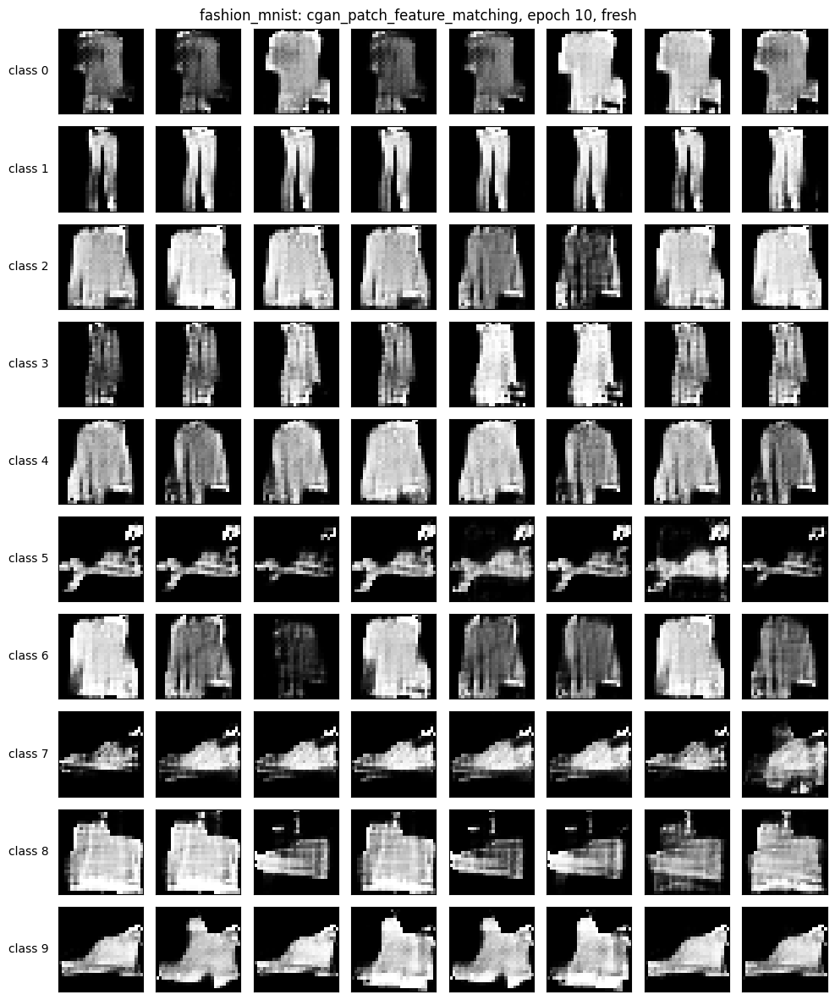

fashion_mnist cgan_patch_feature_matching | 11/40 | G total 0.714, adv 0.709, FM 0.00044, D 0.687
fashion_mnist cgan_patch_feature_matching | 12/40 | G total 0.715, adv 0.710, FM 0.00046, D 0.687
fashion_mnist cgan_patch_feature_matching | 13/40 | G total 0.709, adv 0.705, FM 0.00041, D 0.689
fashion_mnist cgan_patch_feature_matching | 14/40 | G total 0.708, adv 0.705, FM 0.00033, D 0.689
fashion_mnist cgan_patch_feature_matching | 15/40 | G total 0.709, adv 0.705, FM 0.00036, D 0.689


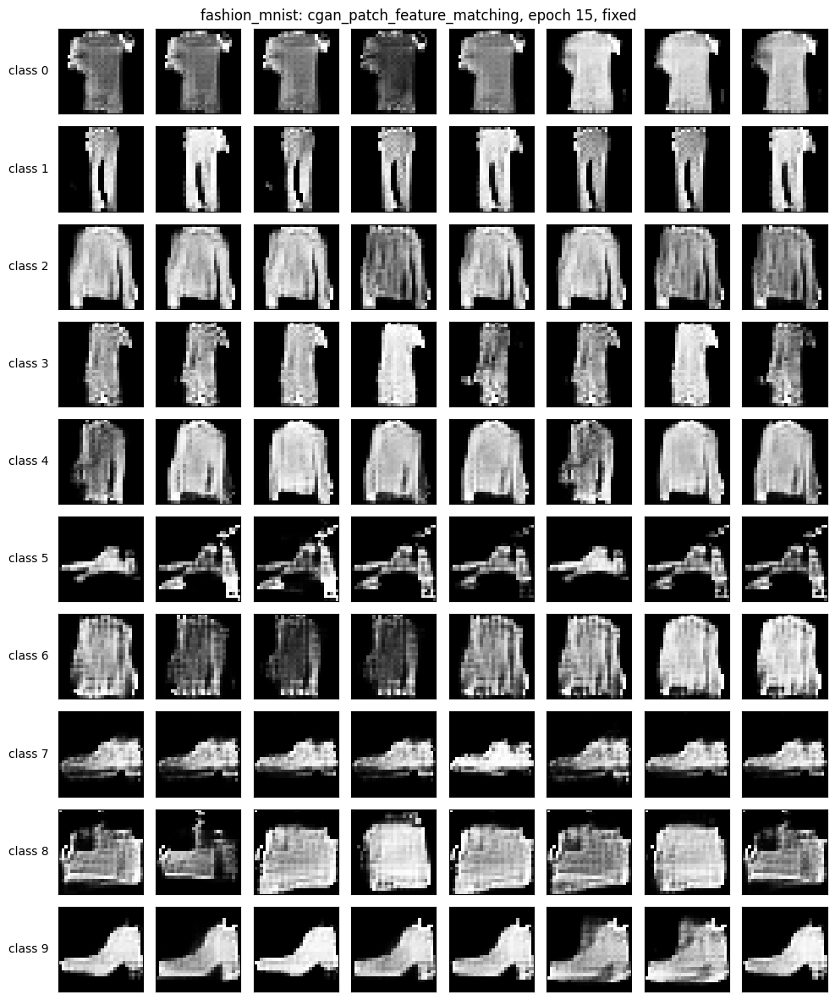

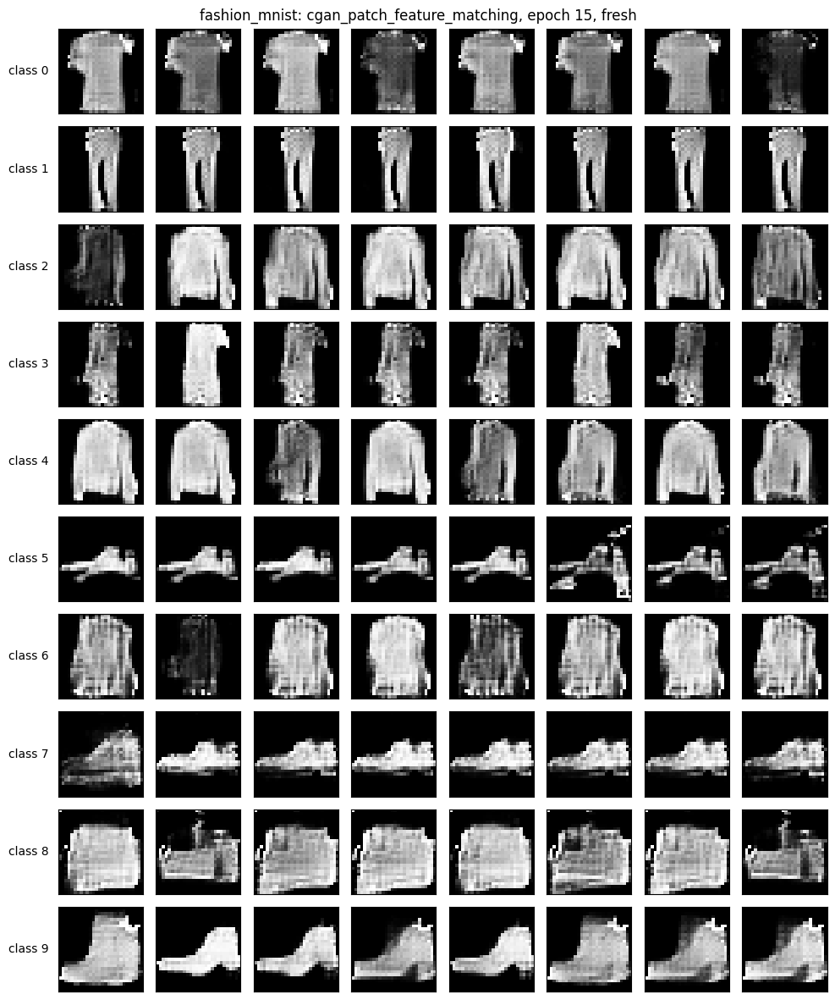

fashion_mnist cgan_patch_feature_matching | 16/40 | G total 0.707, adv 0.704, FM 0.00031, D 0.690
fashion_mnist cgan_patch_feature_matching | 17/40 | G total 0.707, adv 0.704, FM 0.00030, D 0.690
fashion_mnist cgan_patch_feature_matching | 18/40 | G total 0.706, adv 0.703, FM 0.00028, D 0.690
fashion_mnist cgan_patch_feature_matching | 19/40 | G total 0.706, adv 0.704, FM 0.00024, D 0.690
fashion_mnist cgan_patch_feature_matching | 20/40 | G total 0.704, adv 0.702, FM 0.00022, D 0.691


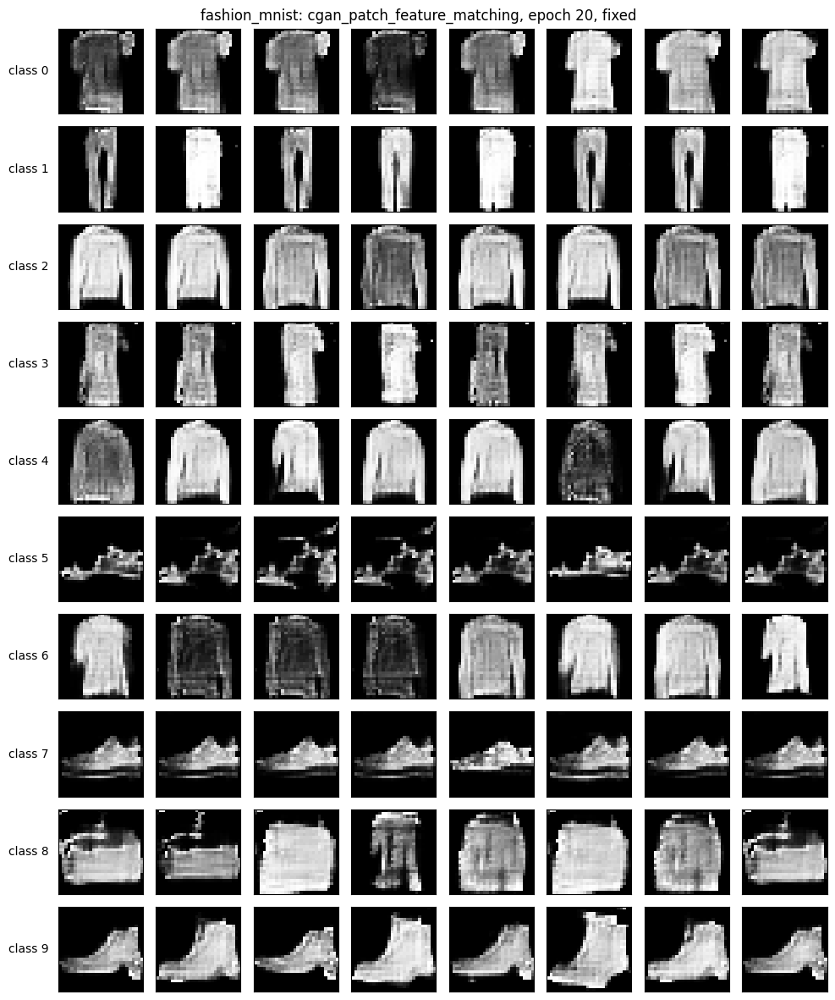

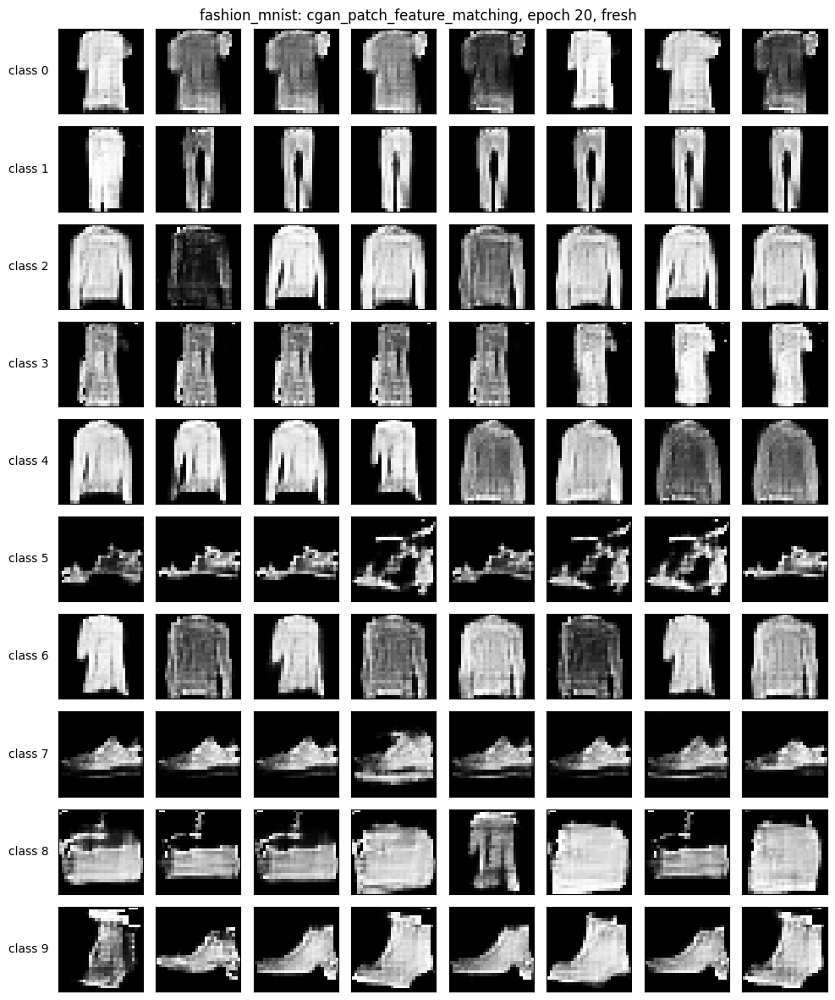

fashion_mnist cgan_patch_feature_matching | 21/40 | G total 0.703, adv 0.701, FM 0.00020, D 0.691
fashion_mnist cgan_patch_feature_matching | 22/40 | G total 0.703, adv 0.701, FM 0.00021, D 0.691
fashion_mnist cgan_patch_feature_matching | 23/40 | G total 0.704, adv 0.702, FM 0.00020, D 0.691
fashion_mnist cgan_patch_feature_matching | 24/40 | G total 0.702, adv 0.701, FM 0.00018, D 0.691
fashion_mnist cgan_patch_feature_matching | 25/40 | G total 0.703, adv 0.701, FM 0.00017, D 0.691


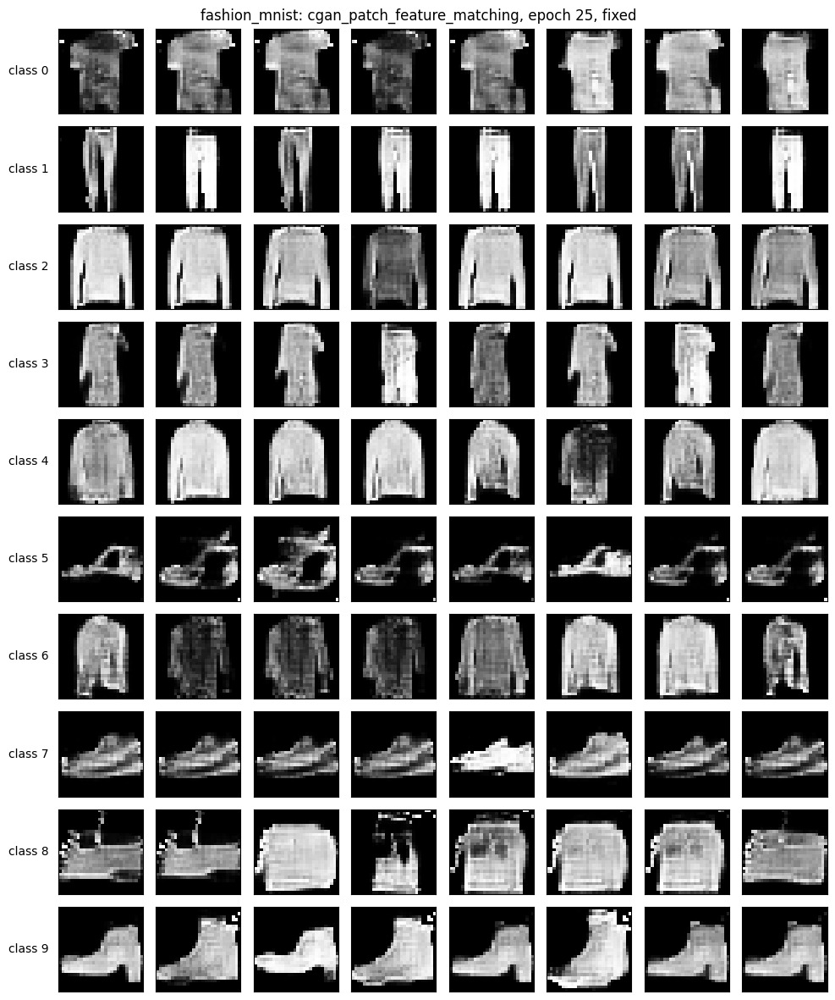

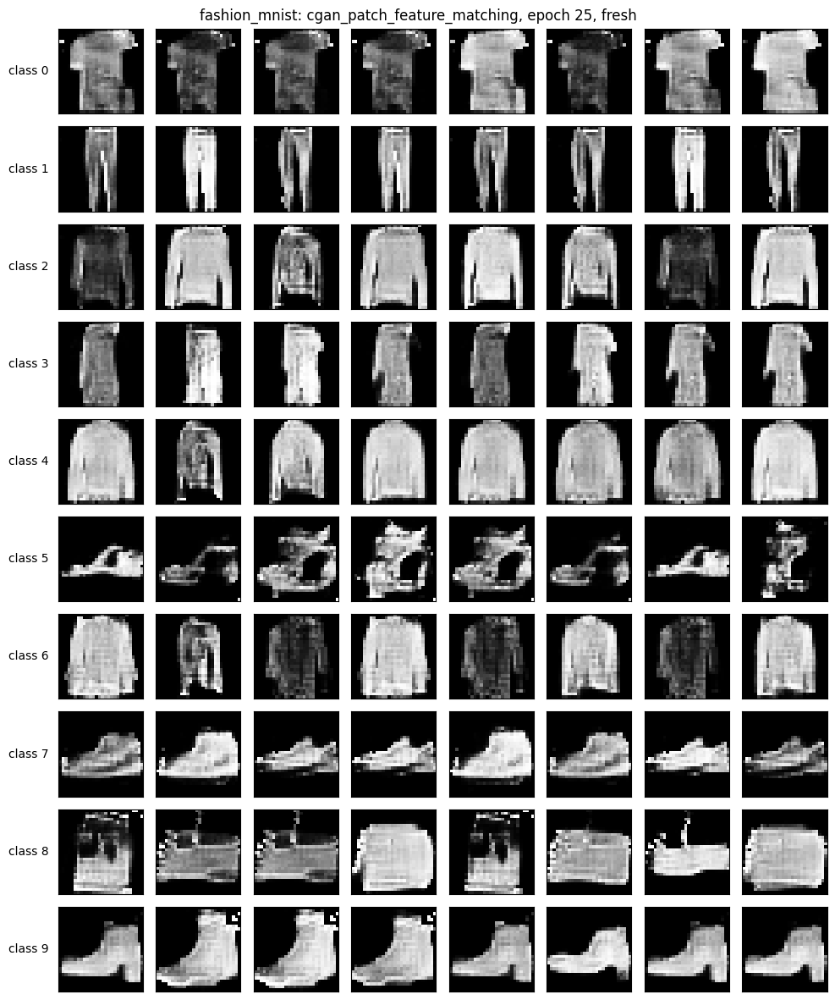

fashion_mnist cgan_patch_feature_matching | 26/40 | G total 0.703, adv 0.702, FM 0.00017, D 0.690
fashion_mnist cgan_patch_feature_matching | 27/40 | G total 0.703, adv 0.702, FM 0.00018, D 0.690
fashion_mnist cgan_patch_feature_matching | 28/40 | G total 0.703, adv 0.701, FM 0.00017, D 0.690
fashion_mnist cgan_patch_feature_matching | 29/40 | G total 0.704, adv 0.702, FM 0.00018, D 0.690
fashion_mnist cgan_patch_feature_matching | 30/40 | G total 0.702, adv 0.701, FM 0.00016, D 0.691


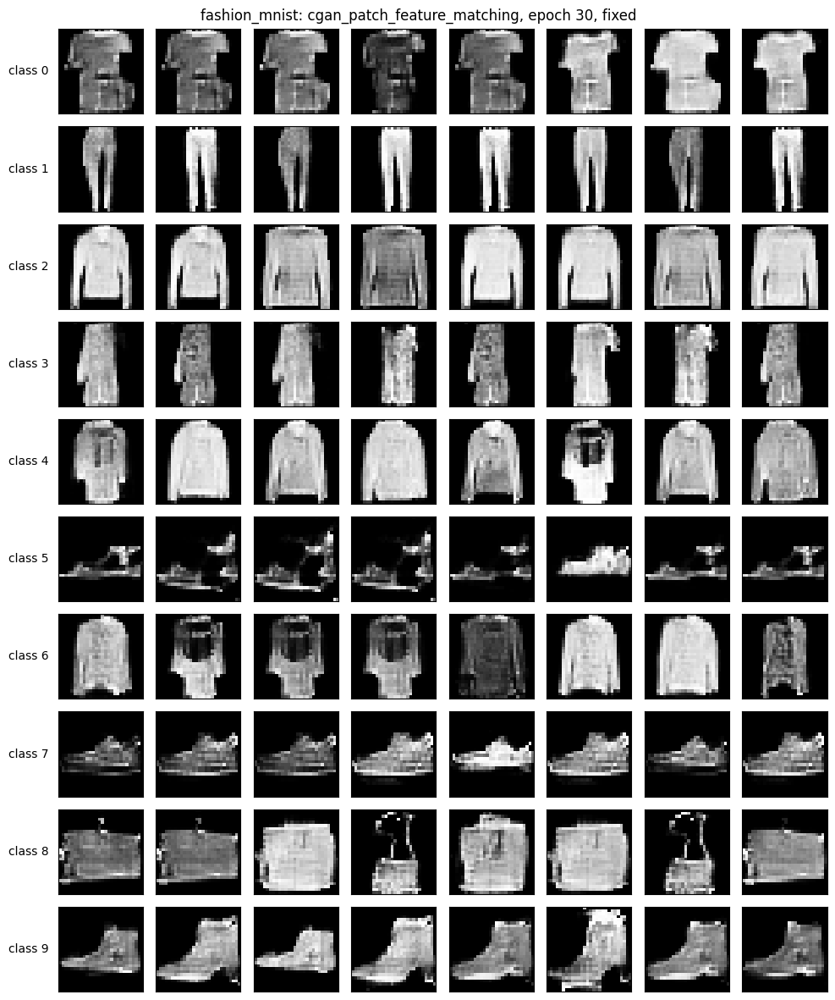

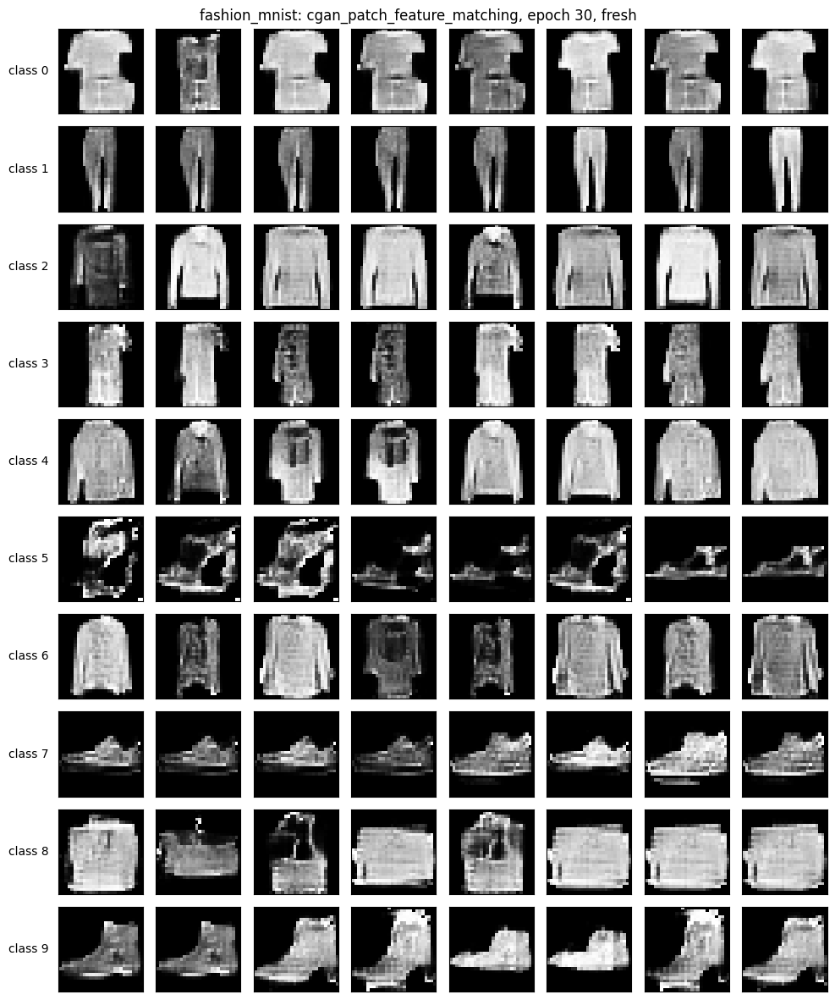

fashion_mnist cgan_patch_feature_matching | 31/40 | G total 0.703, adv 0.701, FM 0.00015, D 0.691
fashion_mnist cgan_patch_feature_matching | 32/40 | G total 0.702, adv 0.700, FM 0.00014, D 0.691
fashion_mnist cgan_patch_feature_matching | 33/40 | G total 0.701, adv 0.700, FM 0.00014, D 0.691
fashion_mnist cgan_patch_feature_matching | 34/40 | G total 0.702, adv 0.700, FM 0.00014, D 0.691
fashion_mnist cgan_patch_feature_matching | 35/40 | G total 0.701, adv 0.700, FM 0.00012, D 0.691


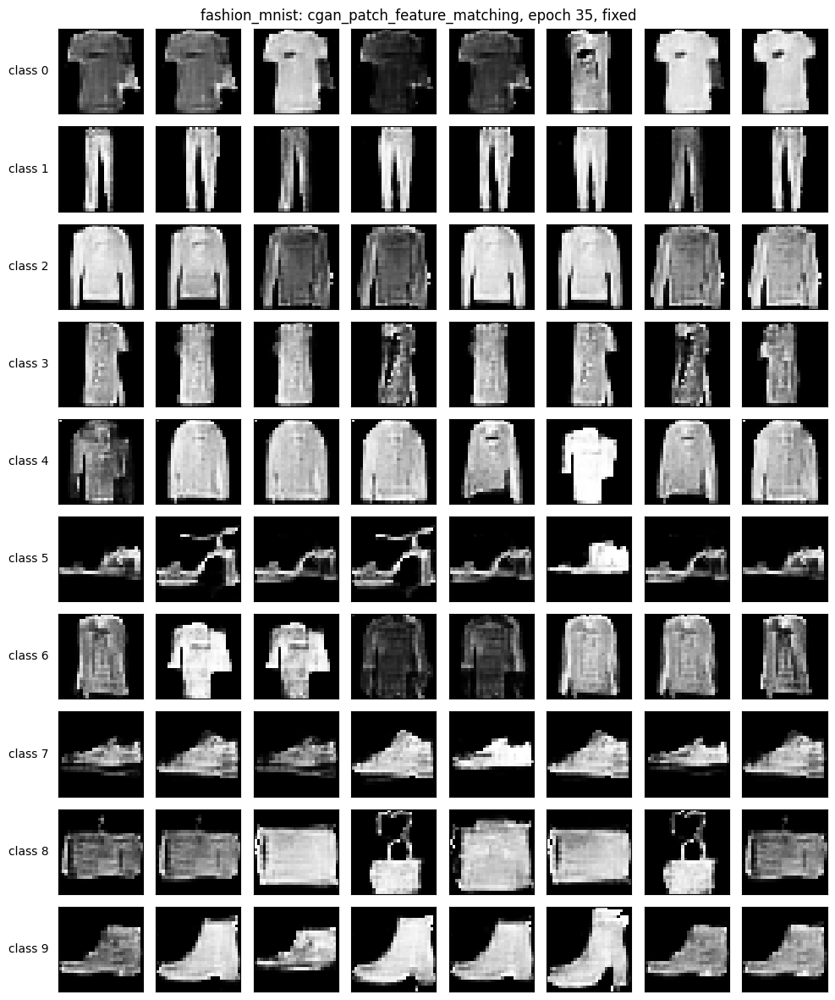

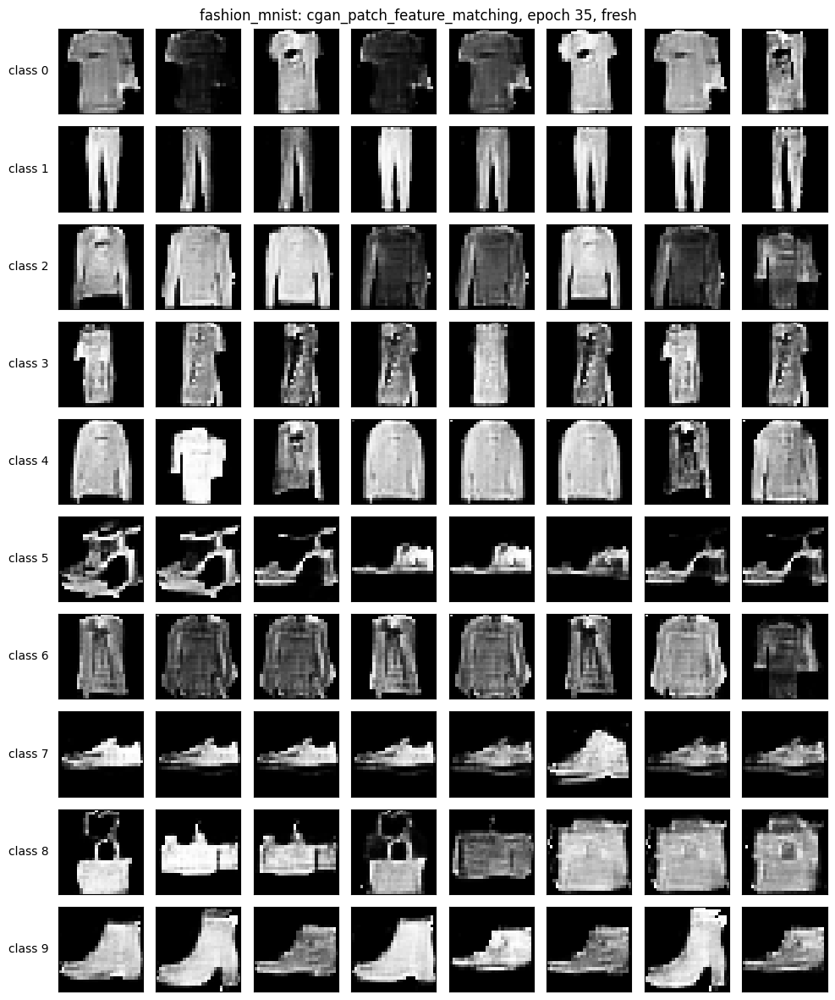

fashion_mnist cgan_patch_feature_matching | 36/40 | G total 0.701, adv 0.700, FM 0.00012, D 0.691
fashion_mnist cgan_patch_feature_matching | 37/40 | G total 0.701, adv 0.700, FM 0.00012, D 0.691
fashion_mnist cgan_patch_feature_matching | 38/40 | G total 0.701, adv 0.699, FM 0.00012, D 0.691
fashion_mnist cgan_patch_feature_matching | 39/40 | G total 0.701, adv 0.700, FM 0.00012, D 0.691
fashion_mnist cgan_patch_feature_matching | 40/40 | G total 0.701, adv 0.700, FM 0.00011, D 0.691


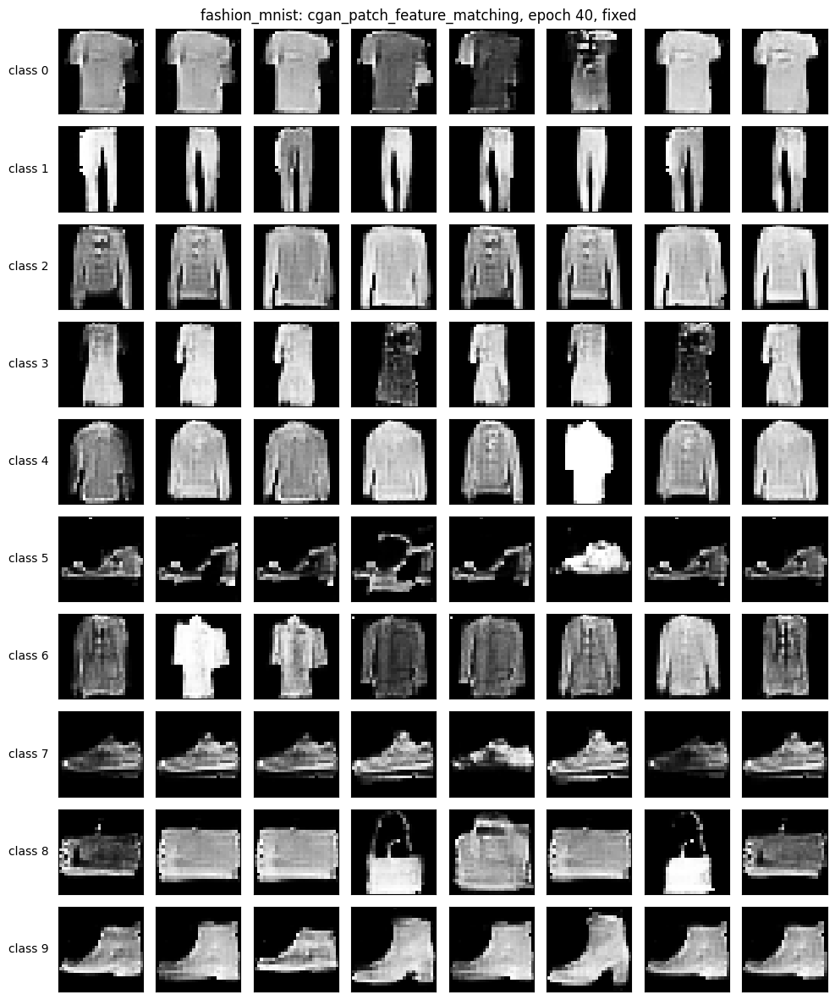

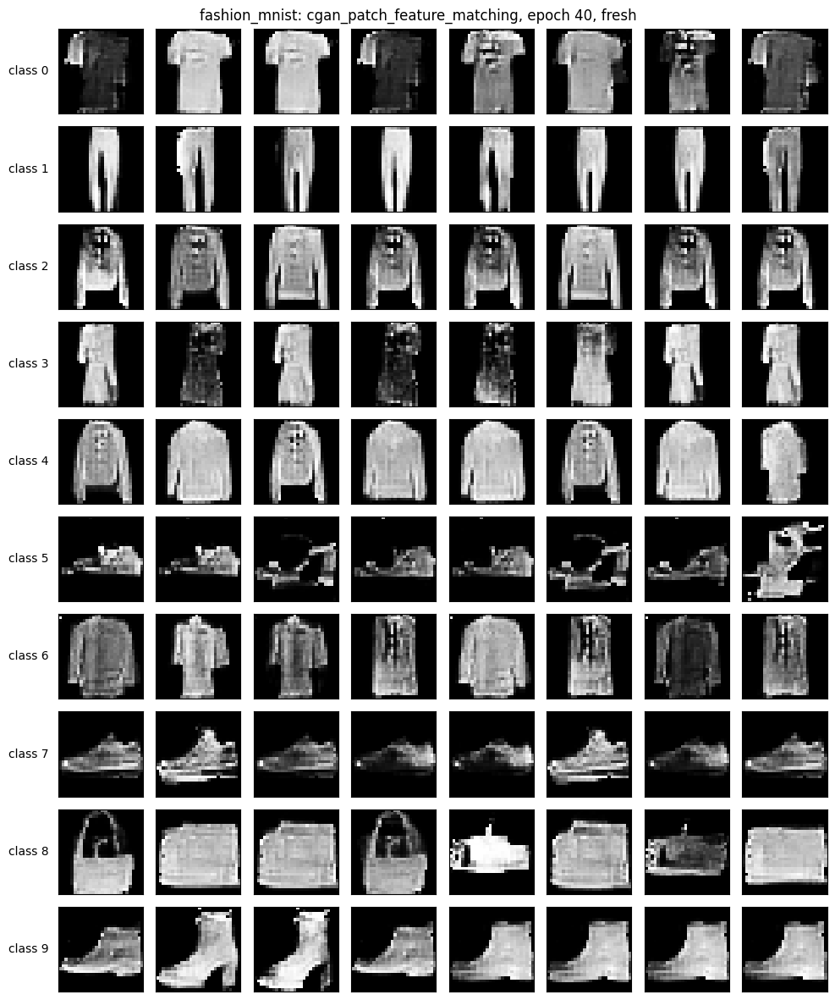

In [13]:
def train_conditional(dataset,spec):
    seed_all()
    train,val=training_loaders(dataset)
    generator=ConditionalGenerator(spec['conditional']).to(DEVICE)
    discriminator=ConditionalDiscriminator(spec['conditional'],spec['patch']).to(DEVICE)
    seed_all()
    opt_g=torch.optim.Adam(generator.parameters(),lr=CG_LR,betas=ADAM_BETAS)
    opt_d=torch.optim.Adam(discriminator.parameters(),lr=CG_LR,betas=ADAM_BETAS)
    folder=CG_RESULTS/dataset/spec['name']
    folder.mkdir(parents=True,exist_ok=True)
    epochs=2 if SMOKE_TEST else CG_EPOCHS
    config=dict(dataset=dataset,**spec,epochs=epochs,seed=SEED,noise_dim=CG_NOISE_DIM,
                classes=CG_CLASSES,batch_size=BATCH_SIZE,learning_rate=CG_LR,adam_betas=ADAM_BETAS,
                train_size=len(train.dataset),validation_size=len(val.dataset),
                generator_parameters=sum(p.numel() for p in generator.parameters()),
                discriminator_parameters=sum(p.numel() for p in discriminator.parameters()),
                patch_map='14x14',patch_receptive_field='14x14',smoke_test=SMOKE_TEST)
    (folder/'config.json').write_text(json.dumps(config,indent=2))
    show_class_grid(generate_conditional(generator),f'{dataset}: {spec["name"]}, initial',folder/'fixed_epoch_000.png')
    history=[]
    for epoch in range(1,epochs+1):
        started=time.perf_counter()
        generator.train()
        discriminator.train()
        totals=dict(g_total=0.,g_adversarial=0.,feature_matching=0.,d_loss=0.,
                    d_real_probability=0.,d_fake_probability=0.)
        count=0
        for gray,labels in train:
            real=gray.to(DEVICE)*2-1
            values=conditional_step(real,labels.to(DEVICE),generator,discriminator,opt_g,opt_d,spec['fm_weight'])
            for key,value in values.items(): totals[key]+=value*len(real)
            count+=len(real)
        validation=evaluate_conditional(generator,discriminator,val,spec['fm_weight'])
        fixed=generate_conditional(generator)
        row=dict(epoch=epoch,**{'train_'+key:value/count for key,value in totals.items()},
                 **{'val_'+key:value for key,value in validation.items()},
                 mean_within_class_pixel_mse=float(np.mean(within_class_variation(fixed,CG_SAMPLES_PER_CLASS))),
                 seconds=time.perf_counter()-started)
        history.append(row)
        pd.DataFrame(history).to_csv(folder/'history.csv',index=False)
        print(f'{dataset} {spec["name"]} | {epoch}/{epochs} | G total {row["train_g_total"]:.3f}, adv {row["train_g_adversarial"]:.3f}, FM {row["train_feature_matching"]:.5f}, D {row["train_d_loss"]:.3f}',flush=True)
        if epoch==1 or epoch%SAMPLE_EVERY==0 or epoch==epochs:
            show_class_grid(fixed,f'{dataset}: {spec["name"]}, epoch {epoch}, fixed',folder/f'fixed_epoch_{epoch:03d}.png')
            show_class_grid(generate_conditional(generator,seed=1000+epoch),
                            f'{dataset}: {spec["name"]}, epoch {epoch}, fresh',folder/f'fresh_epoch_{epoch:03d}.png')
            torch.save(dict(generator=generator.state_dict(),discriminator=discriminator.state_dict(),
                            epoch=epoch,config=config),CG_CHECKPOINTS/f'{dataset}_{spec["name"]}_epoch_{epoch:03d}.pt')
    checkpoint=CG_CHECKPOINTS/f'{dataset}_{spec["name"]}_final.pt'
    torch.save(dict(generator=generator.state_dict(),discriminator=discriminator.state_dict(),
                    epoch=epochs,config=config),checkpoint)
    return dict(dataset=dataset,spec=spec,checkpoint=str(checkpoint),epochs=epochs,
                seconds=sum(row['seconds'] for row in history),
                mean_within_class_pixel_mse=history[-1]['mean_within_class_pixel_mse'])

cg_runs=[]
for dataset in DATASET_NAMES:
    for spec in CG_CONFIGS:
        cg_runs.append(train_conditional(dataset,spec))
        pd.DataFrame([dict(dataset=r['dataset'],variant=r['spec']['name'],epochs=r['epochs'],
                           seconds=r['seconds'],mean_within_class_pixel_mse=r['mean_within_class_pixel_mse'])
                      for r in cg_runs]).to_csv(CG_RESULTS/'run_summary.csv',index=False)


### 2.5 Loss and diversity comparisons

Generator adversarial loss is shown separately from total G loss because FM adds a weighted term. D losses and within-class pixel variation are shown beside sample grids. Patch and global BCE use different aggregation, so their values are not a shared perceptual score.


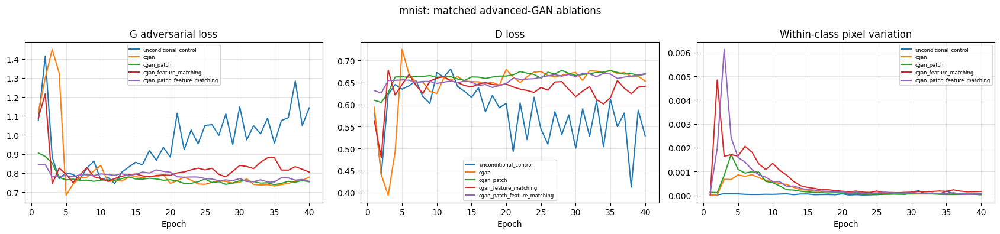

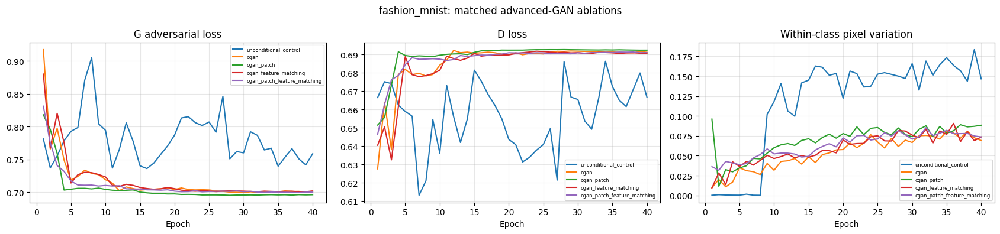

In [14]:
for dataset in DATASET_NAMES:
    fig,axes=plt.subplots(1,3,figsize=(17,4))
    for spec in CG_CONFIGS:
        history=pd.read_csv(CG_RESULTS/dataset/spec['name']/'history.csv')
        for ax,metric,title in zip(axes,['g_adversarial','d_loss','mean_within_class_pixel_mse'],
                                   ['G adversarial loss','D loss','Within-class pixel variation']):
            column=metric if metric=='mean_within_class_pixel_mse' else 'train_'+metric
            ax.plot(history.epoch,history[column],label=spec['name'])
            ax.set(title=title,xlabel='Epoch')
            ax.grid(alpha=0.3)
            ax.legend(fontsize=6)
    fig.suptitle(('SMOKE TEST | ' if SMOKE_TEST else '')+dataset+': matched advanced-GAN ablations')
    fig.tight_layout()
    fig.savefig(CG_RESULTS/f'{dataset}_variant_curves.png',dpi=130)
    plt.show()
    plt.close(fig)


### 2.6 Final class comparisons and remaining collapse

Real test images are grouped by true class, while generated rows show requested classes. They are independent examples. Three additional prior seeds were used for within-class variation diagnostics.

MNIST variants often repeated almost the same prototype within each class, and the unconditional control largely repeated one shape. Fashion-MNIST showed recognizable silhouettes but also noise and ambiguous classes. Conditioning, PatchGAN and FM did not remove all mode collapse.

A separate saved noise audit found distinct latent vectors and distinct plot indices. Generated images could be numerically different but visually almost identical. The repetition therefore reflects model behaviour rather than reused noise or duplicated grid cells.


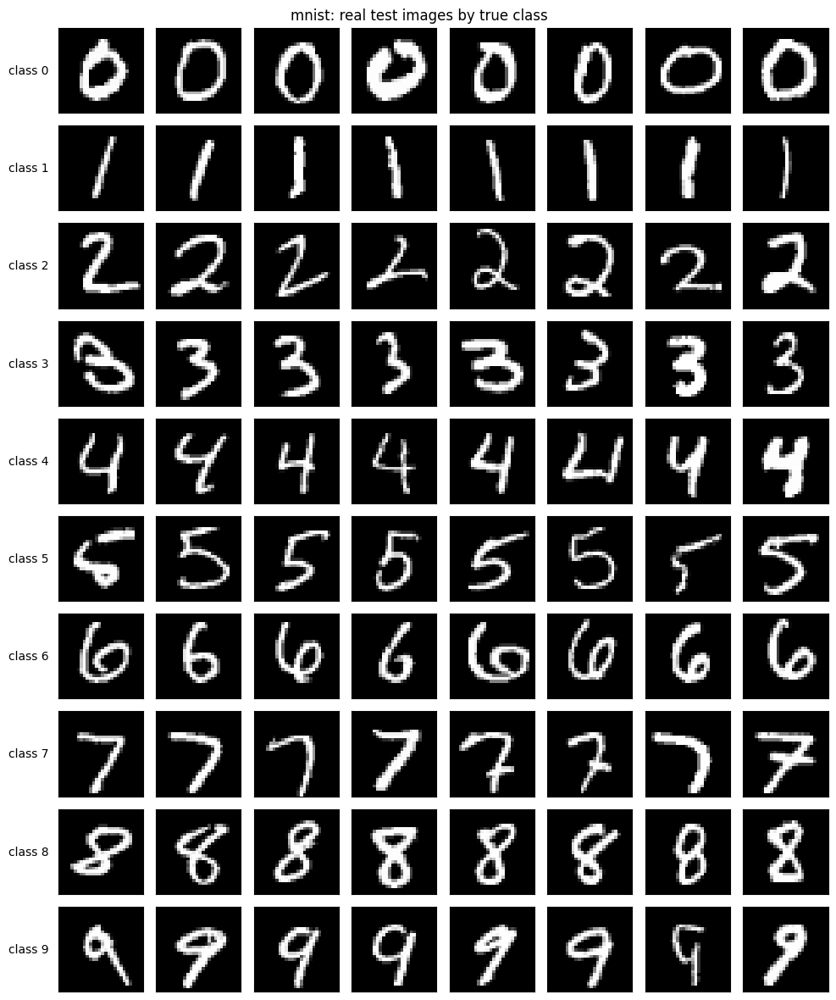

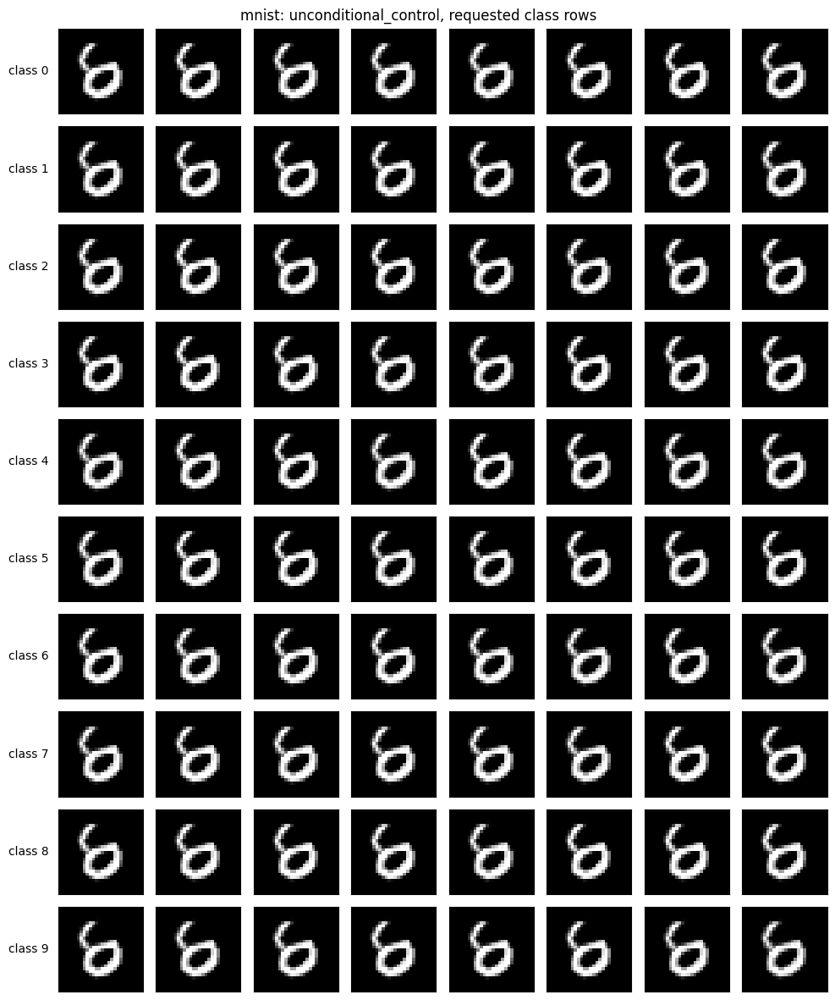

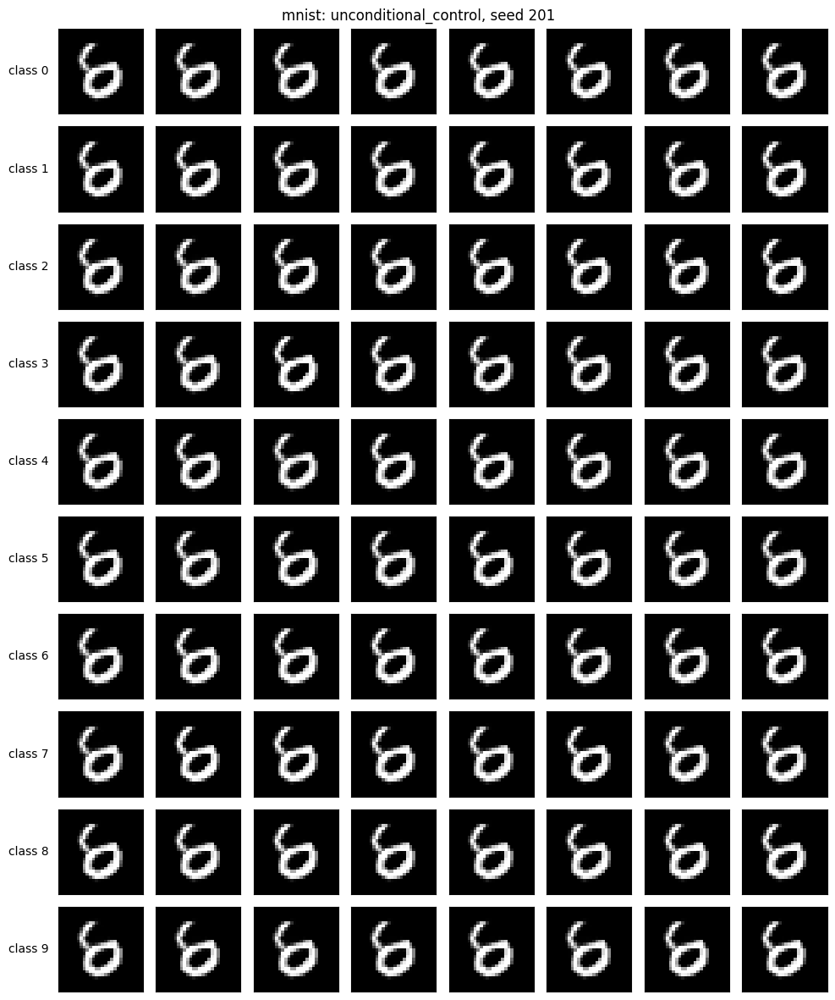

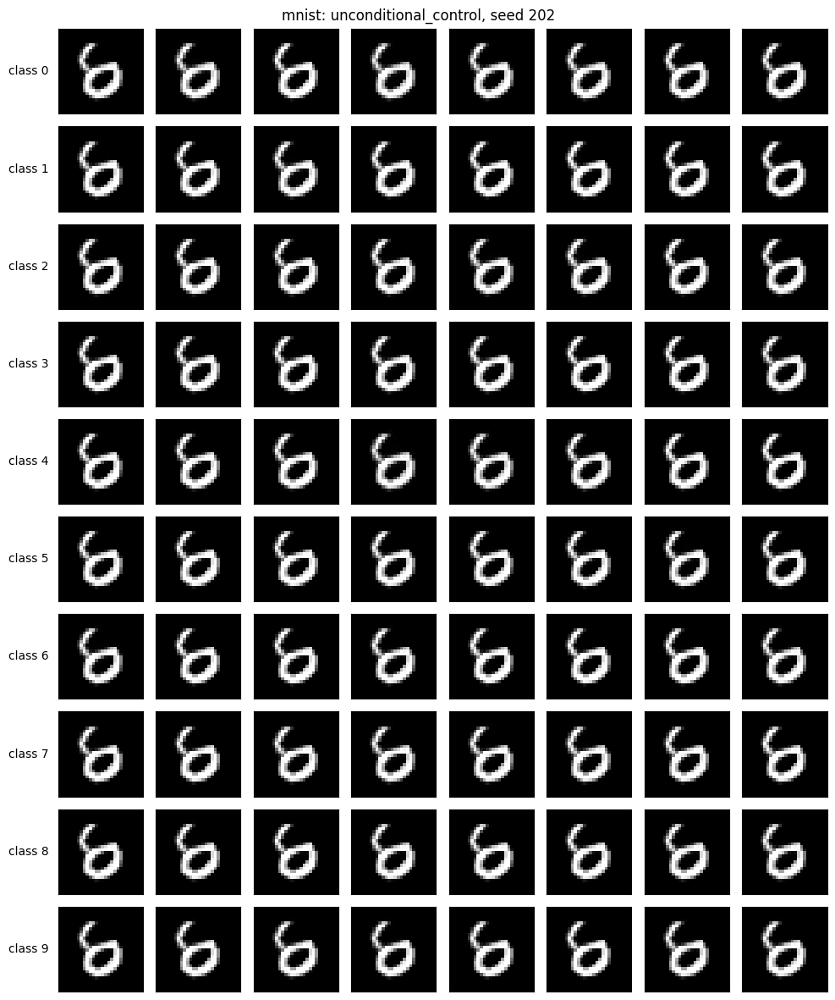

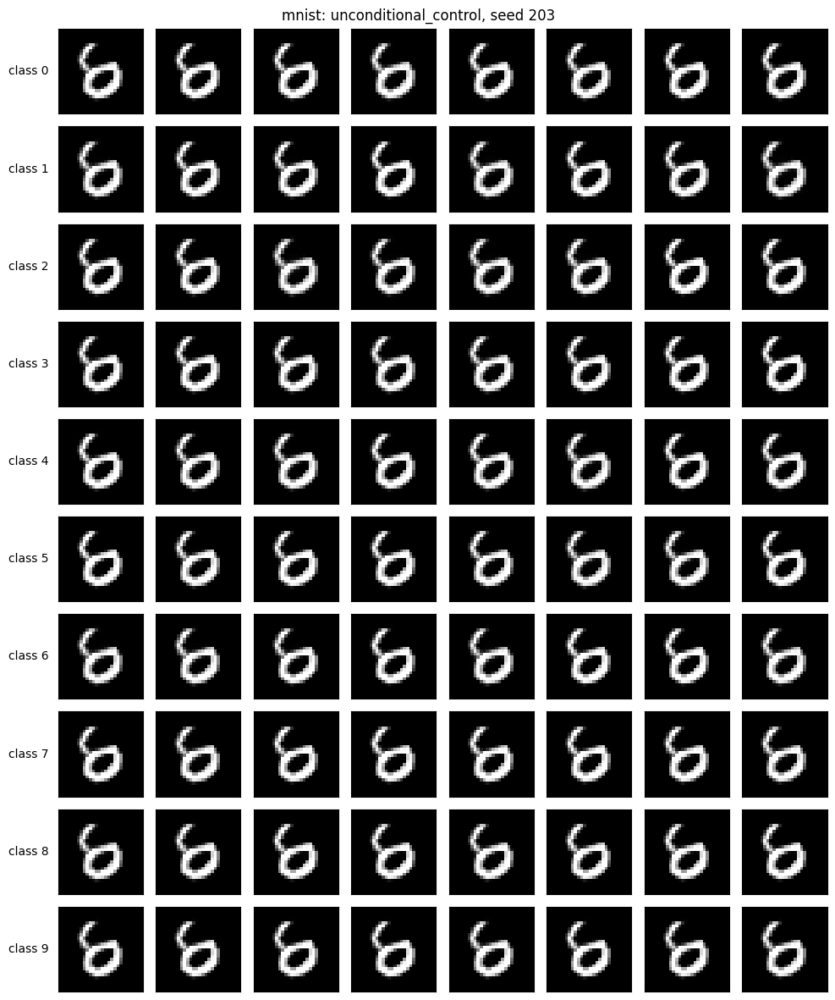

...

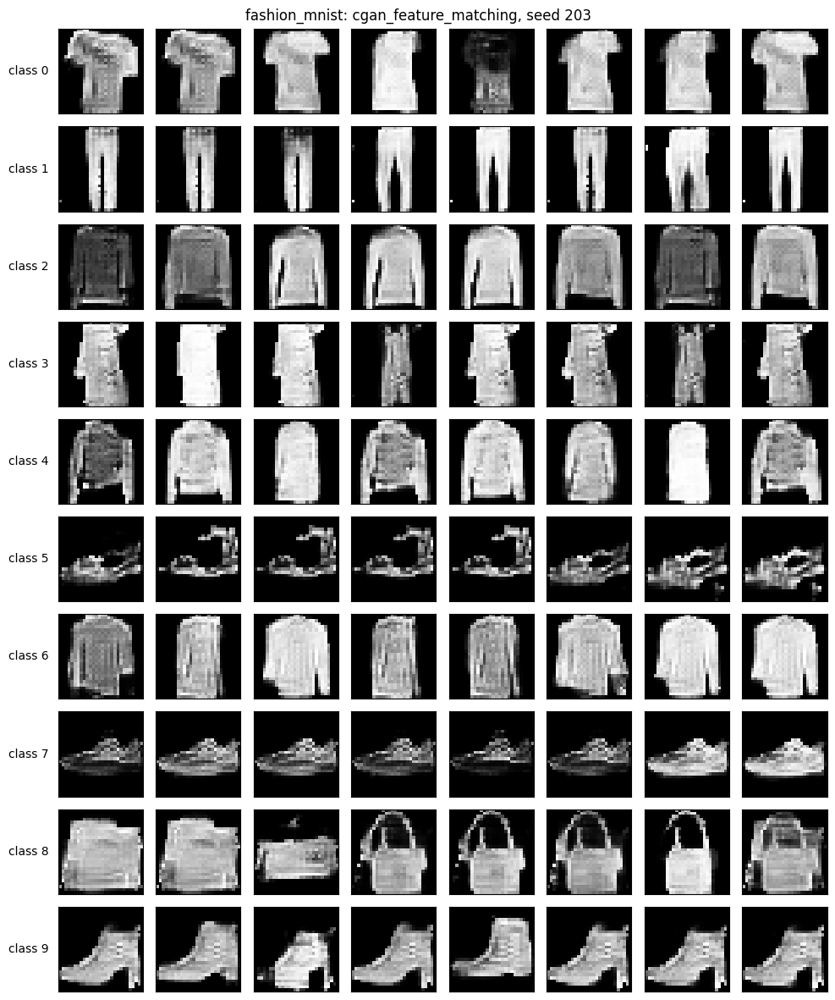

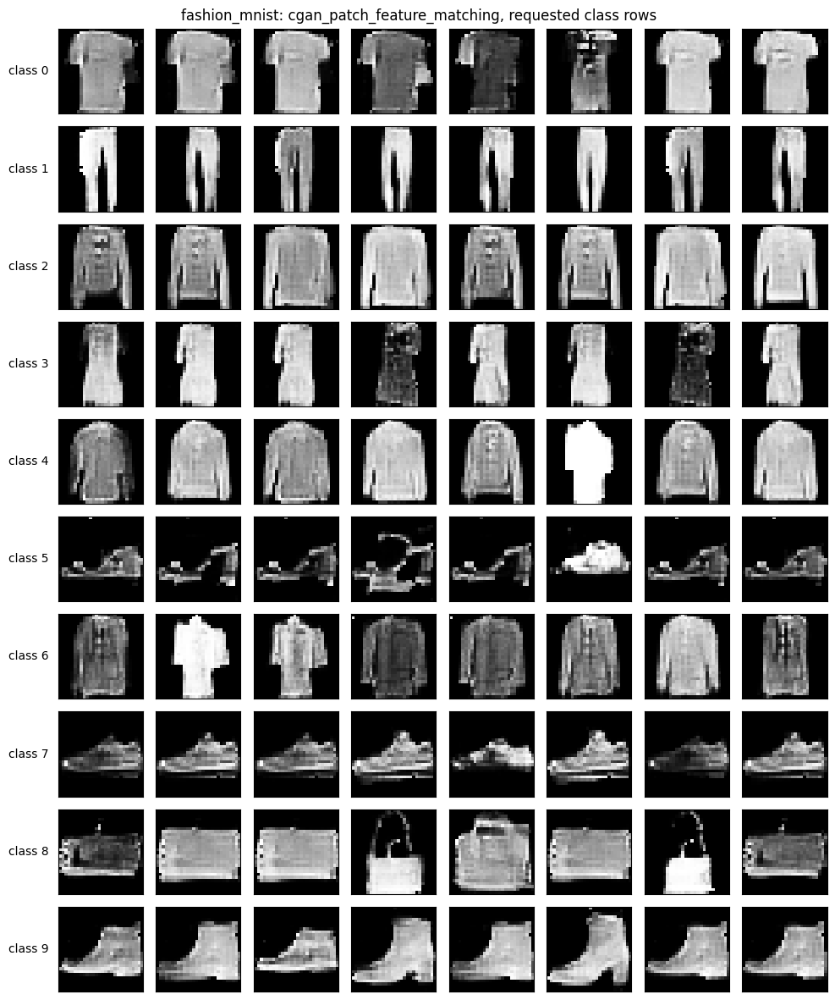

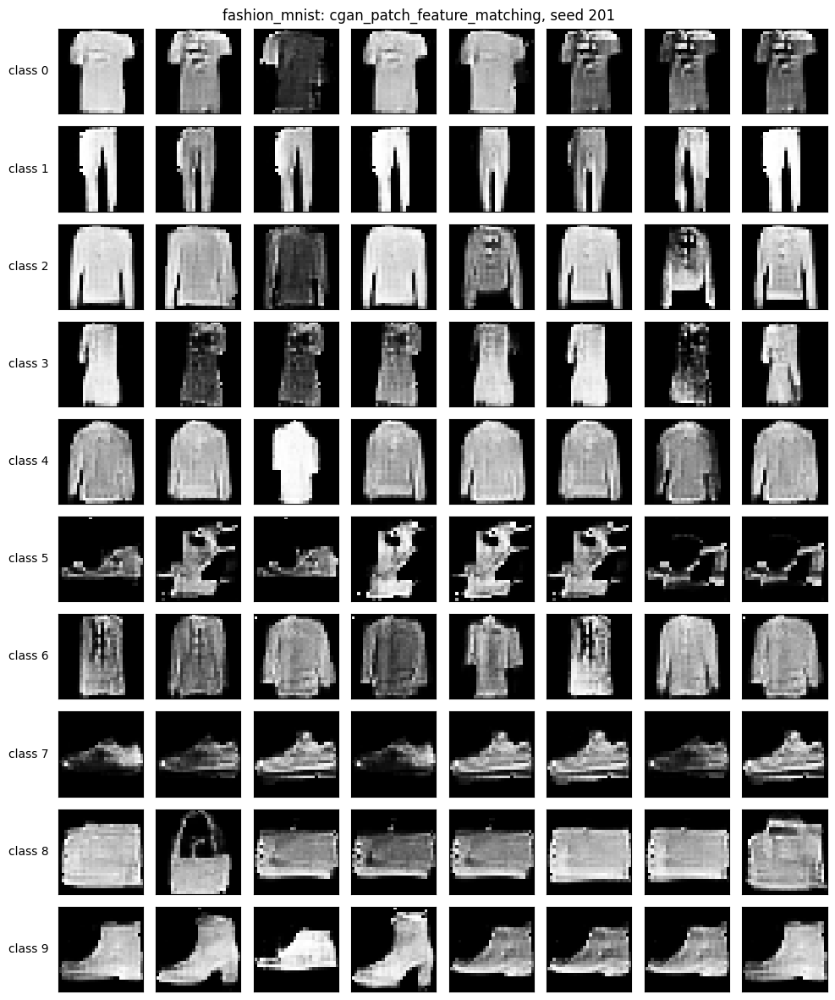

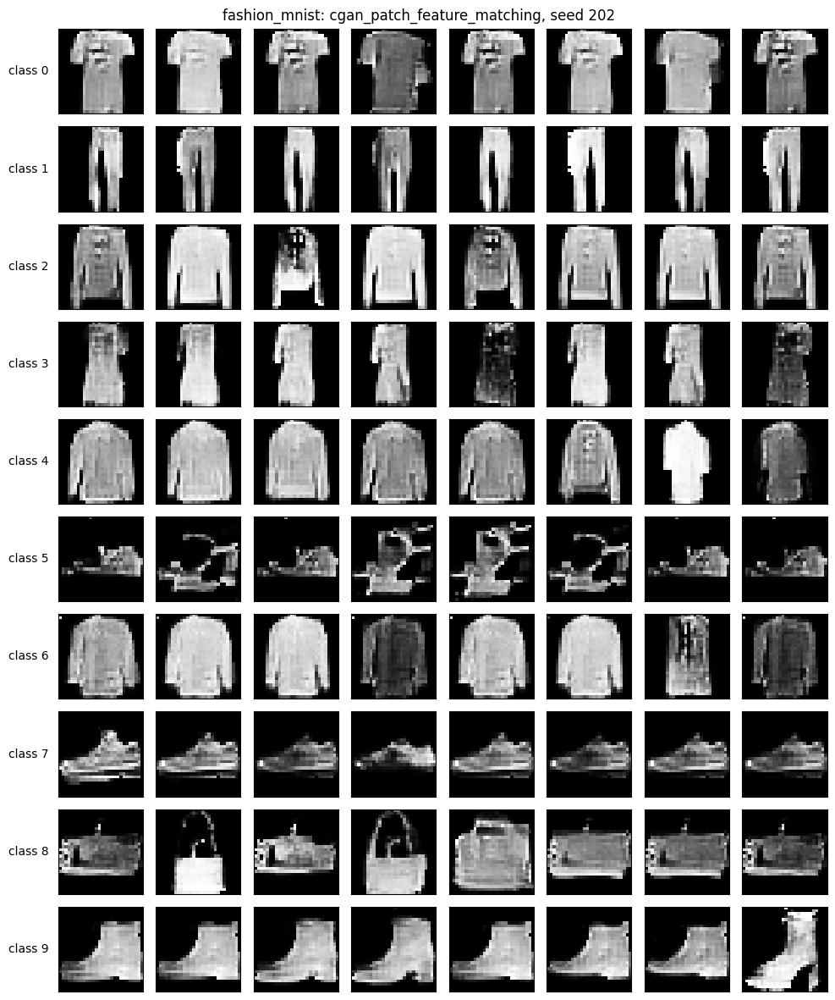

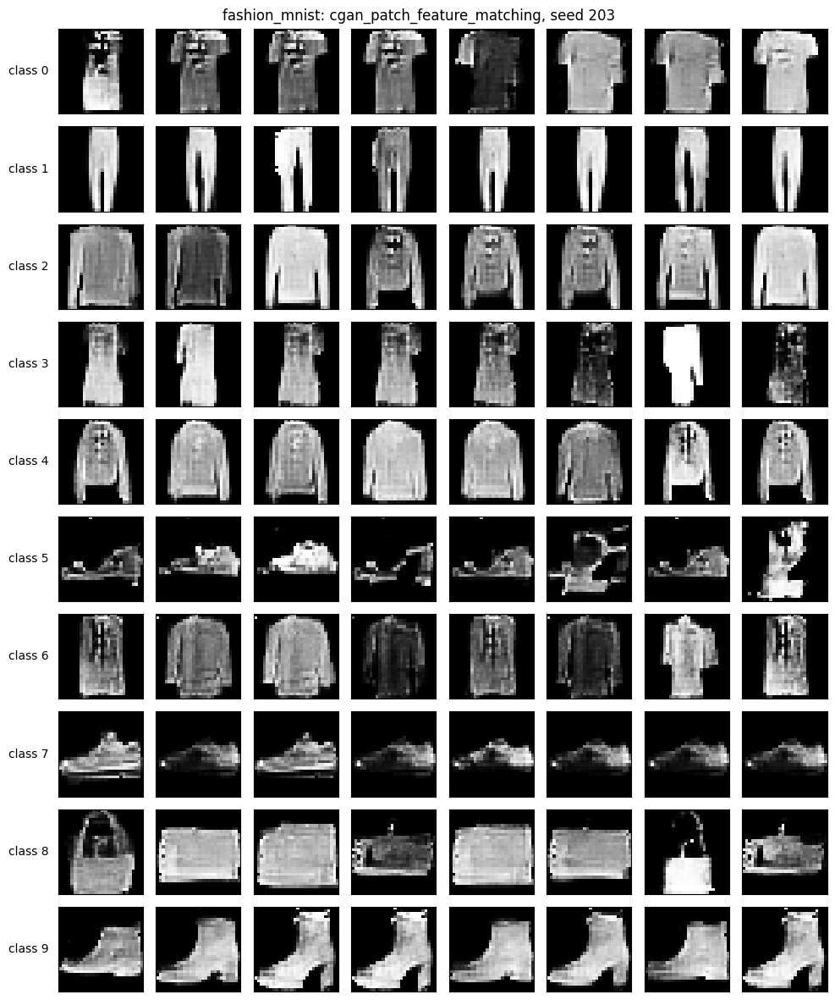

,dataset,variant,g_total,g_adversarial,feature_matching,d_loss,d_real_probability,d_fake_probability,interpretation,smoke_test
0,mnist,unconditional_control,0.833959,0.833959,0.000000,0.663174,0.551149,0.434345,"adversarial diagnostics, not perceptual quality",False
1,mnist,cgan,0.806501,0.806501,0.000000,0.617952,0.530937,0.447566,"adversarial diagnostics, not perceptual quality",False
2,mnist,cgan_patch,0.724687,0.724687,0.000000,0.651962,0.544100,0.488465,"adversarial diagnostics, not perceptual quality",False
3,mnist,cgan_feature_matching,1.379510,1.109960,0.026955,0.637441,0.450031,0.337629,"adversarial diagnostics, not perceptual quality",False
4,mnist,cgan_patch_feature_matching,0.902490,0.883458,0.001903,0.678813,0.462435,0.422096,"adversarial diagnostics, not perceptual quality",False
5,fashion_mnist,unconditional_control,0.612952,0.612952,0.000000,0.661401,0.590219,0.543335,"adversarial diagnostics, not perceptual quality",False
6,fashion_mnist,cgan,0.687747,0.687747,0.000000,0.691392,0.505966,0.503204,"adversarial diagnostics, not perceptual quality",False
7,fashion_mnist,cgan_patch,0.701913,0.701913,0.000000,0.692040,0.497537,0.495896,"adversarial diagnostics, not perceptual quality",False
8,fashion_mnist,cgan_feature_matching,0.741517,0.737516,0.000400,0.691344,0.481616,0.478471,"adversarial diagnostics, not perceptual quality",False
9,fashion_mnist,cgan_patch_feature_matching,0.710707,0.709536,0.000117,0.691023,0.495773,0.492401,"adversarial diagnostics, not perceptual quality",False


mean       std
dataset       variant                                        
fashion_mnist cgan                         0.065375  0.031311
              cgan_feature_matching        0.077069  0.029693
              cgan_patch                   0.088551  0.029086
              cgan_patch_feature_matching  0.079243  0.028896
              unconditional_control        0.129644  0.024674
mnist         cgan                         0.000051  0.000026
              cgan_feature_matching        0.000169  0.000068
              cgan_patch                   0.000027  0.000011
              cgan_patch_feature_matching  0.000070  0.000034
              unconditional_control        0.000091  0.000035

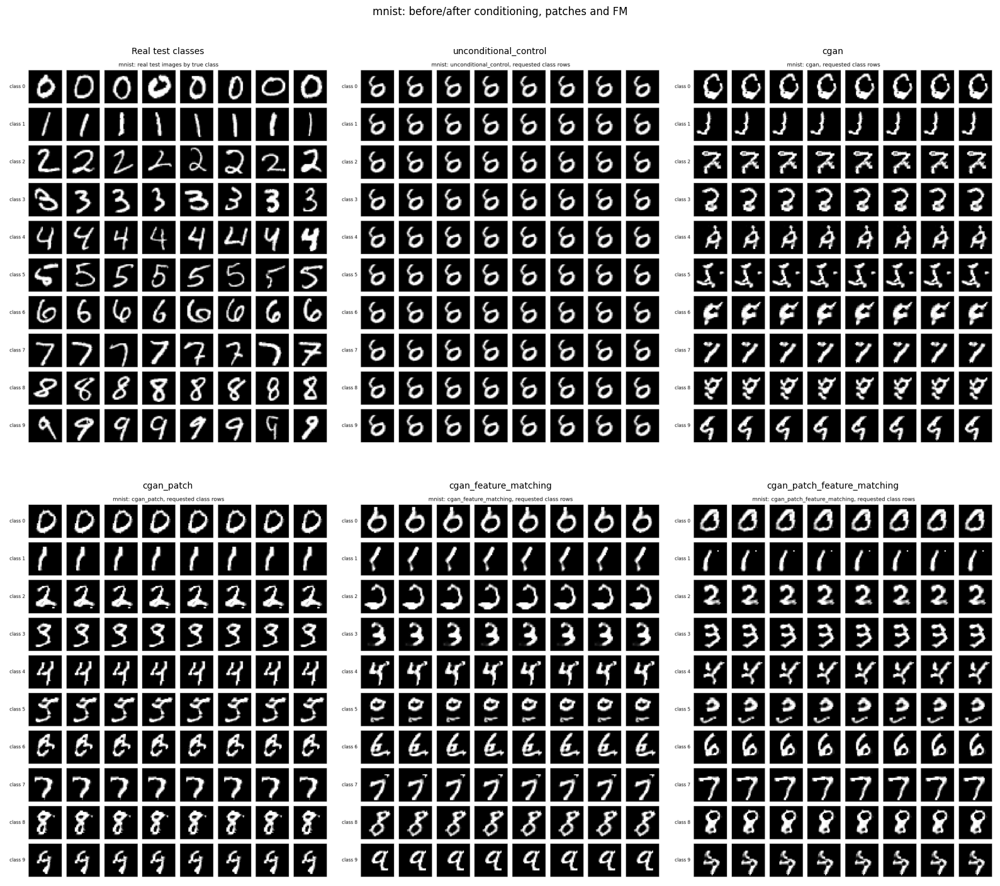

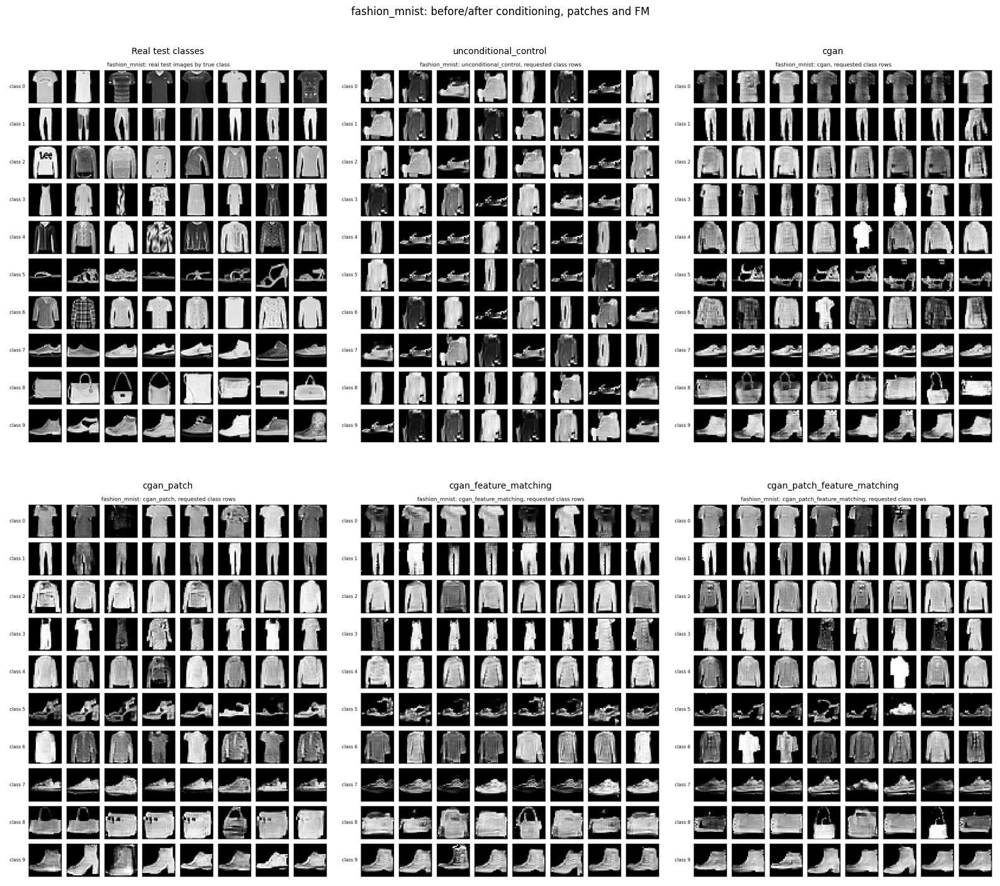

In [15]:
cg_test_rows=[]
cg_diversity_rows=[]
cg_final_grids={}
for dataset in DATASET_NAMES:
    ds=testing_loader(dataset).dataset
    buckets=[[] for _ in range(CG_CLASSES)]
    for image,label in ds:
        if len(buckets[int(label)])<CG_SAMPLES_PER_CLASS: buckets[int(label)].append(image)
        if all(len(bucket)==CG_SAMPLES_PER_CLASS for bucket in buckets): break
    real=torch.zeros(CG_CLASSES*CG_SAMPLES_PER_CLASS,1,28,28)
    for label,bucket in enumerate(buckets):
        for column,image in enumerate(bucket): real[label*CG_SAMPLES_PER_CLASS+column]=image
    show_class_grid(real,dataset+': real test images by true class',CG_RESULTS/f'{dataset}_real_classes.png')
    for run in (r for r in cg_runs if r['dataset']==dataset):
        spec=run['spec']
        generator=ConditionalGenerator(spec['conditional']).to(DEVICE)
        discriminator=ConditionalDiscriminator(spec['conditional'],spec['patch']).to(DEVICE)
        saved=torch.load(run['checkpoint'],map_location=DEVICE,weights_only=True)
        generator.load_state_dict(saved['generator'])
        discriminator.load_state_dict(saved['discriminator'])
        diagnostics=evaluate_conditional(generator,discriminator,testing_loader(dataset),spec['fm_weight'],seed=3030)
        cg_test_rows.append(dict(dataset=dataset,variant=spec['name'],**diagnostics,
                                 interpretation='adversarial diagnostics, not perceptual quality',smoke_test=SMOKE_TEST))
        fixed=generate_conditional(generator,seed=123)
        grid_path=CG_RESULTS/f'{dataset}_{spec["name"]}_classes.png'
        show_class_grid(fixed,f'{dataset}: {spec["name"]}, requested class rows',grid_path)
        cg_final_grids[(dataset,spec['name'])]=grid_path
        for seed in (201,202,203):
            images=generate_conditional(generator,seed=seed)
            show_class_grid(images,f'{dataset}: {spec["name"]}, seed {seed}',
                            CG_RESULTS/dataset/spec['name']/f'final_seed_{seed}.png')
            variations=within_class_variation(images,CG_SAMPLES_PER_CLASS)
            for label,value in enumerate(variations):
                cg_diversity_rows.append(dict(dataset=dataset,variant=spec['name'],seed=seed,
                                              requested_class=label,pairwise_pixel_mse=value))
cg_test_results=pd.DataFrame(cg_test_rows)
cg_test_results.to_csv(CG_RESULTS/'test_discriminator_diagnostics.csv',index=False)
cg_diversity=pd.DataFrame(cg_diversity_rows)
cg_diversity.to_csv(CG_RESULTS/'within_class_diversity.csv',index=False)
display(cg_test_results)
display(cg_diversity.groupby(['dataset','variant']).pairwise_pixel_mse.agg(['mean','std']))

for dataset in DATASET_NAMES:
    fig,axes=plt.subplots(2,3,figsize=(16,15))
    panels=[('Real test classes',CG_RESULTS/f'{dataset}_real_classes.png')]
    panels.extend((spec['name'],cg_final_grids[(dataset,spec['name'])]) for spec in CG_CONFIGS)
    for ax,(title,path) in zip(axes.flat,panels):
        ax.imshow(plt.imread(path))
        ax.set_title(title,fontsize=10)
        ax.axis('off')
    fig.suptitle(('SMOKE TEST | ' if SMOKE_TEST else '')+dataset+': before/after conditioning, patches and FM')
    fig.tight_layout()
    fig.savefig(CG_RESULTS/f'{dataset}_all_variants.png',dpi=130,bbox_inches='tight')
    plt.show()
    plt.close(fig)


## Part 3: Progressive Growing GAN

An unconditional RGB GAN was trained on CIFAR-10 at 4→8→16→32 pixels. New generator and critic blocks were activated at each stage, with fade-in followed by stabilization. Earlier weights and optimizer state were preserved.

This compact PGGAN-inspired model used equalized learning-rate layers, generator pixel normalization and WGAN-GP with critic drift regularization. It is not a full reproduction of the original model. No matched fixed-resolution control was trained, so this run cannot establish a causal quality or stability improvement.


In [17]:
import hashlib,tarfile,shutil

PG_RESOLUTIONS = [4,8,16,32]
PG_CHANNELS = [128,128,64,32]
PG_Z_DIM = 128
PG_BATCH_SIZES = {4:128,8:128,16:64,32:64}
PG_FADE_EPOCHS = {8:4,16:4,32:8}
PG_STABLE_EPOCHS = {4:4,8:4,16:8,32:16}
PG_LEARNING_RATE = 1e-3
PG_GP_WEIGHT = 10.
PG_DRIFT_WEIGHT = 1e-3
PG_SAMPLE_COUNT = 64
PG_DATA_SOURCE = 'CIFAR-10 official binary archive'
PG_RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
PG_RESULTS = HW/'results'/'progressive_gan'/('smoke' if SMOKE_TEST else 'full')/PG_RUN_ID
PG_CHECKPOINTS = ROOT/'.local'/'hw1'/'progressive_gan'/'checkpoints'/PG_RUN_ID
PG_RESULTS.mkdir(parents=True,exist_ok=True)
PG_CHECKPOINTS.mkdir(parents=True,exist_ok=True)
(PG_RESULTS/'environment.json').write_text(json.dumps(environment,indent=2))
print('Progressive GAN results:',PG_RESULTS)
print('Full schedule epochs:',sum(PG_FADE_EPOCHS.values())+sum(PG_STABLE_EPOCHS.values()))


Progressive GAN results: c:\Users\Admin\Desktop\GEN_AI_CV\HW1\results\progressive_gan\full\20261112T213856462231Z
Full schedule epochs: 48


### 3.1 CIFAR-10 and progressive image sizes

The official 50,000-image training set was split into 45,000 training and 5,000 validation examples with a fixed seed. The separate test set contained 10,000 images. Class labels were ignored.

The binary archive was checked against its published MD5, and only expected members were read. Images were cached as uint8 and mapped to [-1,1] for training. Real images were area-downsampled to the current stage's resolution. Both data resolution and the active network architecture changed during growth.


In [18]:
def file_md5(path):
    digest=hashlib.md5()
    with path.open('rb') as stream:
        for block in iter(lambda:stream.read(1024*1024),b''): digest.update(block)
    return digest.hexdigest()

def parse_cifar_binary(raw,expected_count):
    records=np.frombuffer(raw,dtype=np.uint8)
    if records.size!=expected_count*3073: raise ValueError('Invalid CIFAR binary batch size')
    records=records.reshape(expected_count,3073)
    labels=records[:,0].copy().astype(np.int64)
    if not ((labels>=0)&(labels<10)).all(): raise ValueError('Invalid CIFAR label')
    images=records[:,1:].copy().reshape(expected_count,3,32,32)
    return images,labels

class CIFARImages(torch.utils.data.Dataset):
    def __init__(self,images,labels):
        self.images=torch.as_tensor(images,dtype=torch.uint8)
        self.labels=torch.as_tensor(labels,dtype=torch.long)
    def __len__(self): return len(self.labels)
    def __getitem__(self,index):
        return self.images[index].float()/127.5-1,self.labels[index]

@lru_cache(maxsize=2)
def load_cifar10(train=True):
    folder=DATA_DIR/'cifar10'
    folder.mkdir(parents=True,exist_ok=True)
    path=folder/'cifar-10-binary.tar.gz'
    expected_md5='c32a1d4ab5d03f1284b67883e8d87530'
    if not path.exists() or file_md5(path)!=expected_md5:
        temporary=path.with_suffix('.download')
        try:
            print('Downloading official CIFAR-10 binary archive (~162 MB).',flush=True)
            url='https://www.cs.toronto.edu/~kriz/cifar-10-binary.tar.gz'
            with urllib.request.urlopen(url,timeout=120) as response,temporary.open('wb') as output:
                shutil.copyfileobj(response,output)
            if file_md5(temporary)!=expected_md5: raise ValueError('CIFAR archive checksum mismatch')
            temporary.replace(path)
        finally:
            temporary.unlink(missing_ok=True)
    names=[f'cifar-10-batches-bin/data_batch_{i}.bin' for i in range(1,6)] if train else ['cifar-10-batches-bin/test_batch.bin']
    batches={}
    with tarfile.open(path,mode='r|gz') as archive:
        for member in archive:
            if member.name in names:
                stream=archive.extractfile(member)
                if stream is None: raise ValueError('Missing CIFAR member')
                with stream: batches[member.name]=parse_cifar_binary(stream.read(),10000)
    if set(batches)!=set(names): raise ValueError('Missing CIFAR batch files')
    images=np.concatenate([batches[name][0] for name in names])
    labels=np.concatenate([batches[name][1] for name in names])
    return CIFARImages(images,labels)

def pg_data_loaders(stage):
    full=load_cifar10(train=True)
    train,val=random_split(full,[45000,5000],generator=torch.Generator().manual_seed(SEED))
    if SMOKE_TEST: train,val=Subset(train,range(64)),Subset(val,range(16))
    batch=PG_BATCH_SIZES[PG_RESOLUTIONS[stage]]
    options=dict(batch_size=batch,num_workers=0,pin_memory=DEVICE.type=='cuda')
    return (DataLoader(train,shuffle=True,generator=torch.Generator().manual_seed(SEED+stage),**options),
            DataLoader(val,shuffle=False,**options))

def pg_test_loader():
    dataset=load_cifar10(train=False)
    if SMOKE_TEST: dataset=Subset(dataset,range(16))
    return DataLoader(dataset,batch_size=PG_BATCH_SIZES[32],shuffle=False,num_workers=0)


### 3.2 Growing architecture and fade-in

All blocks were registered before training, but only blocks up to the current stage were active. Future blocks received no gradients.

The generator used pixel-normalized noise, an equalized linear layer and a 4×4 base block. Each growth block upsampled features and applied two 3×3 convolutions with LeakyReLU and pixel normalization. Each stage had its own 1×1 ToRGB layer.

New and previous RGB paths were blended before tanh:

$$G_\alpha(z)=\tanh\big((1-\alpha)\,\mathrm{ToRGB}_{old}(\mathrm{up}(h_{old}))+\alpha\,\mathrm{ToRGB}_{new}(h_{new})\big).$$

At alpha=0, the output matches nearest-neighbour upsampling of the previous generator. At alpha=1, it uses the new RGB path.

The critic used a FromRGB layer at each stage. Its new convolution/downsampling path was blended with the old path before the lower-resolution blocks and scalar head.

Equalized layers scaled normal weights by gain/sqrt(fan-in). Pixel normalization was used only in G. D had no batch-dependent normalization or minibatch-statistic layer, keeping the gradient penalty per image.


In [19]:
class EqualizedLinear(nn.Module):
    def __init__(self,inputs,outputs,gain=math.sqrt(2)):
        super().__init__()
        self.weight=nn.Parameter(torch.randn(outputs,inputs))
        self.bias=nn.Parameter(torch.zeros(outputs))
        self.scale=gain/math.sqrt(inputs)
    def forward(self,x): return F.linear(x,self.weight*self.scale,self.bias)

class EqualizedConv(nn.Module):
    def __init__(self,inputs,outputs,kernel=3,gain=math.sqrt(2)):
        super().__init__()
        self.weight=nn.Parameter(torch.randn(outputs,inputs,kernel,kernel))
        self.bias=nn.Parameter(torch.zeros(outputs))
        self.scale=gain/math.sqrt(inputs*kernel*kernel)
        self.padding=kernel//2
    def forward(self,x): return F.conv2d(x,self.weight*self.scale,self.bias,padding=self.padding)

class PixelNorm(nn.Module):
    def forward(self,x): return x*torch.rsqrt(x.square().mean(1,keepdim=True)+1e-8)

class ProgressiveGenerator(nn.Module):
    def __init__(self,z_dim=128,channels=(128,128,64,32)):
        super().__init__()
        self.base=nn.Sequential(PixelNorm(),EqualizedLinear(z_dim,channels[0]*4*4),
                                nn.Unflatten(1,(channels[0],4,4)),nn.LeakyReLU(0.2),PixelNorm(),
                                EqualizedConv(channels[0],channels[0]),nn.LeakyReLU(0.2),PixelNorm())
        self.blocks=nn.ModuleList([
            nn.Sequential(EqualizedConv(channels[i-1],channels[i]),nn.LeakyReLU(0.2),PixelNorm(),
                          EqualizedConv(channels[i],channels[i]),nn.LeakyReLU(0.2),PixelNorm())
            for i in range(1,len(channels))])
        self.to_rgb=nn.ModuleList([EqualizedConv(c,3,kernel=1,gain=1.) for c in channels])
    def forward(self,z,stage=0,alpha=1.):
        x=self.base(z)
        if stage==0: return torch.tanh(self.to_rgb[0](x))
        for level in range(1,stage+1):
            up=F.interpolate(x,scale_factor=2,mode='nearest')
            x=self.blocks[level-1](up)
            if level==stage:
                old=self.to_rgb[level-1](up)
                new=self.to_rgb[level](x)
                return torch.tanh((1-alpha)*old+alpha*new)

class ProgressiveCritic(nn.Module):
    def __init__(self,channels=(128,128,64,32)):
        super().__init__()
        self.from_rgb=nn.ModuleList([nn.Sequential(EqualizedConv(3,c,kernel=1),nn.LeakyReLU(0.2))
                                    for c in channels])
        self.blocks=nn.ModuleList([
            nn.Sequential(EqualizedConv(channels[i],channels[i]),nn.LeakyReLU(0.2),
                          EqualizedConv(channels[i],channels[i-1]),nn.LeakyReLU(0.2),nn.AvgPool2d(2))
            for i in range(1,len(channels))])
        self.final=nn.Sequential(EqualizedConv(channels[0],channels[0]),nn.LeakyReLU(0.2),
                                 nn.Flatten(),EqualizedLinear(channels[0]*4*4,1,gain=1.))
    def forward(self,image,stage=0,alpha=1.):
        if stage==0: return self.final(self.from_rgb[0](image)).flatten()
        new=self.blocks[stage-1](self.from_rgb[stage](image))
        old=self.from_rgb[stage-1](F.avg_pool2d(image,2))
        x=(1-alpha)*old+alpha*new
        for level in reversed(range(1,stage)): x=self.blocks[level-1](x)
        return self.final(x).flatten()

def fade_alpha(step,total_steps):
    return 1. if total_steps<=1 else min(1.,max(0.,step/(total_steps-1)))

def active_parameter_counts(generator,critic,stage,alpha):
    g_modules=[generator.base,*list(generator.blocks[:stage]),generator.to_rgb[stage]]
    d_modules=[critic.final,*list(critic.blocks[:stage]),critic.from_rgb[stage]]
    if stage>0 and alpha<1:
        g_modules.append(generator.to_rgb[stage-1])
        d_modules.append(critic.from_rgb[stage-1])
    return (sum(p.numel() for module in g_modules for p in module.parameters()),
            sum(p.numel() for module in d_modules for p in module.parameters()))


### 3.3 WGAN-GP loss and checks

This section used a real-valued critic without sigmoid or BCE:

$$L_D=\mathbb E[D(fake)]-\mathbb E[D(real)]+10\,\mathrm{GP}+0.001\,\mathbb E[D(real)^2],\qquad L_G=-\mathbb E[D(fake)].$$

$$\mathrm{GP}=\mathbb E[(\|\nabla_{\hat x}D(\hat x)\|_2-1)^2],\quad\hat x=\epsilon x+(1-\epsilon)G(z).$$

Each batch used one critic and one generator update. Critic updates did not change G; generator updates passed gradients through a parameter-frozen critic. The penalty used the current resolution and alpha.

Implementation checks covered alpha=0 continuity for both networks, output sizes, inactive-block gradients, a finite differentiable penalty and fade endpoints.


In [20]:
def progressive_gradient_penalty(critic,real,fake,stage,alpha):
    epsilon=torch.rand(len(real),1,1,1,device=real.device)
    mixed=(epsilon*real+(1-epsilon)*fake.detach()).requires_grad_(True)
    scores=critic(mixed,stage,alpha)
    gradient=torch.autograd.grad(scores,mixed,grad_outputs=torch.ones_like(scores),create_graph=True)[0]
    norm=(gradient.flatten(1).square().sum(1)+1e-8).sqrt()
    return (norm-1).square().mean()

def progressive_step(real,generator,critic,opt_g,opt_d,stage,alpha,z_dim):
    opt_g.zero_grad(set_to_none=True)
    opt_d.zero_grad(set_to_none=True)
    with torch.no_grad(): fake=generator(torch.randn(len(real),z_dim,device=real.device),stage,alpha)
    real_score,fake_score=critic(real,stage,alpha),critic(fake,stage,alpha)
    penalty=progressive_gradient_penalty(critic,real,fake,stage,alpha)
    d_loss=fake_score.mean()-real_score.mean()+PG_GP_WEIGHT*penalty+PG_DRIFT_WEIGHT*real_score.square().mean()
    if not torch.isfinite(d_loss): raise FloatingPointError('Non-finite progressive critic loss')
    d_loss.backward()
    opt_d.step()
    opt_d.zero_grad(set_to_none=True)
    for parameter in critic.parameters(): parameter.requires_grad_(False)
    try:
        fake=generator(torch.randn(len(real),z_dim,device=real.device),stage,alpha)
        g_loss=-critic(fake,stage,alpha).mean()
        if not torch.isfinite(g_loss): raise FloatingPointError('Non-finite progressive G loss')
        g_loss.backward()
        opt_g.step()
    finally:
        for parameter in critic.parameters(): parameter.requires_grad_(True)
    return dict(g_loss=g_loss.item(),critic_loss=d_loss.item(),gradient_penalty=penalty.item(),
                critic_real=real_score.mean().item(),critic_fake=fake_score.mean().item(),
                critic_gap=(real_score.mean()-fake_score.mean()).item())

def check_progressive_architecture():
    generator=ProgressiveGenerator(8,(8,8,4,4))
    critic=ProgressiveCritic((8,8,4,4))
    z=torch.randn(3,8)
    for stage,resolution in enumerate(PG_RESOLUTIONS):
        image=generator(z,stage,1.)
        assert image.shape==(3,3,resolution,resolution)
        assert critic(image,stage,1.).shape==(3,)
        if stage>0:
            previous=generator(z,stage-1,1.)
            torch.testing.assert_close(generator(z,stage,0.),F.interpolate(previous,scale_factor=2,mode='nearest'),atol=2e-6,rtol=2e-5)
            torch.testing.assert_close(critic(image,stage,0.),critic(F.avg_pool2d(image,2),stage-1,1.),atol=2e-6,rtol=2e-5)
    generator.zero_grad(set_to_none=True)
    generator(z,0,1.).sum().backward()
    assert all(p.grad is None for block in generator.blocks for p in block.parameters())
    penalty=progressive_gradient_penalty(critic,torch.rand(3,3,8,8)*2-1,generator(z,1,.5).detach(),1,.5)
    assert torch.isfinite(penalty)
    penalty.backward()
    assert any(p.grad is not None and torch.isfinite(p.grad).all() for p in critic.parameters())
    assert fade_alpha(0,10)==0. and fade_alpha(9,10)==1.
    # CIFAR parser: channels are planar, not interleaved RGB.
    record=np.concatenate([np.array([7],dtype=np.uint8),np.full(1024,10,dtype=np.uint8),
                           np.full(1024,20,dtype=np.uint8),np.full(1024,30,dtype=np.uint8)])
    images,labels=parse_cifar_binary(record.tobytes(),1)
    assert labels[0]==7 and images[0,:,0,0].tolist()==[10,20,30]
    print('Passed: stage shapes, exact fade continuity, inactive blocks, gradient penalty, alpha endpoints and CIFAR layout.')
check_progressive_architecture()


Passed: stage shapes, exact fade continuity, inactive blocks, gradient penalty, alpha endpoints and CIFAR layout.


### 3.4 Training schedule and snapshots

| Resolution | Fade epochs | Stabilization epochs | Batch size |
|---|---:|---:|---:|
| 4×4 | 0 | 4 | 128 |
| 8×8 | 4 | 4 | 128 |
| 16×16 | 4 | 8 | 64 |
| 32×32 | 8 | 16 | 64 |

The full run completed 48 epochs, about 2.16 million training-image presentations. Adam used learning rate 1e-3 and betas (0, 0.99). Alpha increased linearly from 0 to 1 during fade-in and stayed at 1 during stabilization. Growth did not restart the model or optimizer.

Logs include losses, gradient penalty, critic gap, resolution, phase, alpha and runtime. Fixed and fresh RGB snapshots were saved across stages. Low-resolution images were enlarged only for display using nearest-neighbour interpolation.


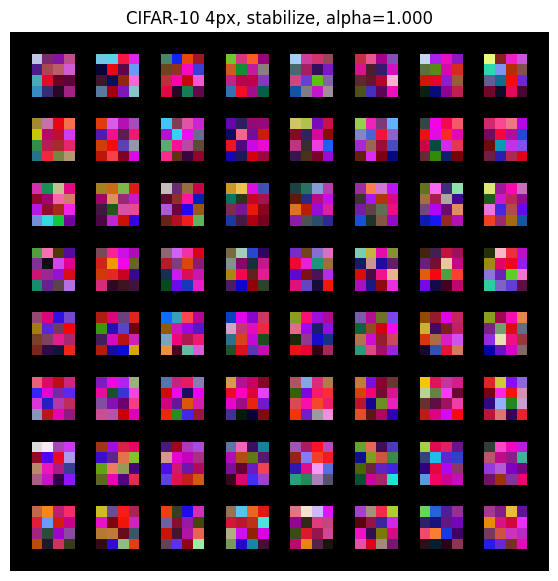

CIFAR 4px stabilize 1/4 | alpha 1.000->1.000 | G 0.925, critic -0.472, GP 0.010 | 4.1s


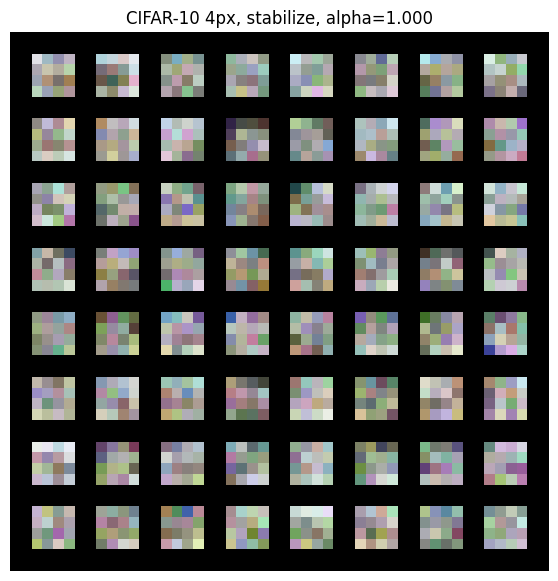

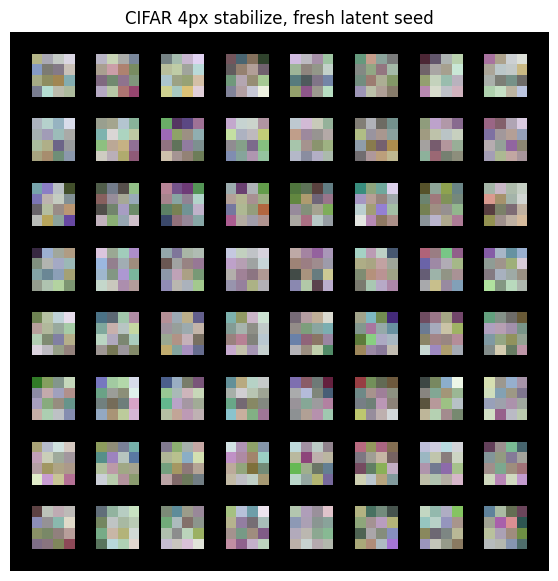

CIFAR 4px stabilize 2/4 | alpha 1.000->1.000 | G 0.058, critic 0.006, GP 0.010 | 4.0s
CIFAR 4px stabilize 3/4 | alpha 1.000->1.000 | G -0.043, critic 0.103, GP 0.007 | 4.0s
CIFAR 4px stabilize 4/4 | alpha 1.000->1.000 | G 0.010, critic 0.067, GP 0.005 | 3.9s


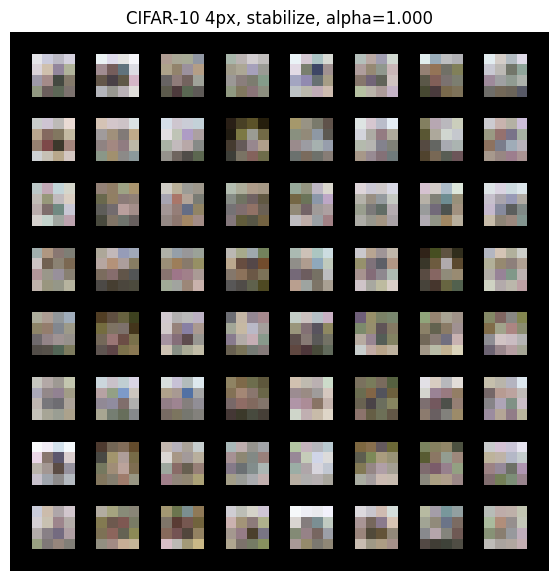

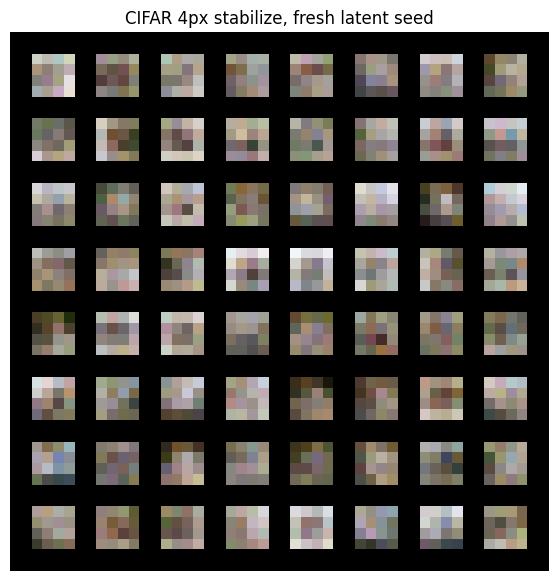

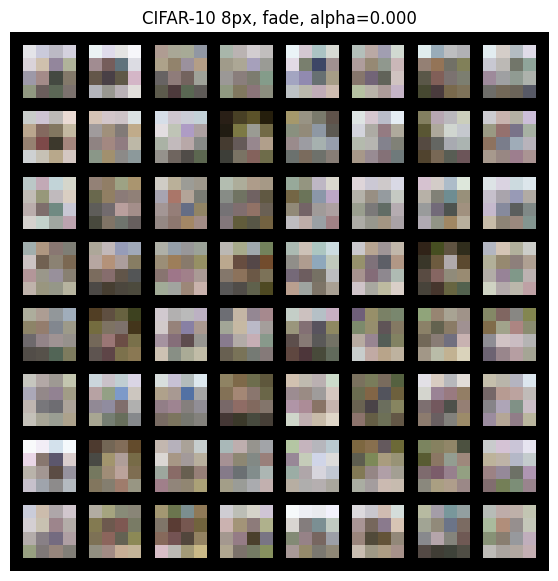

CIFAR 8px fade 1/4 | alpha 0.000->0.249 | G -0.528, critic 0.547, GP 0.012 | 6.0s


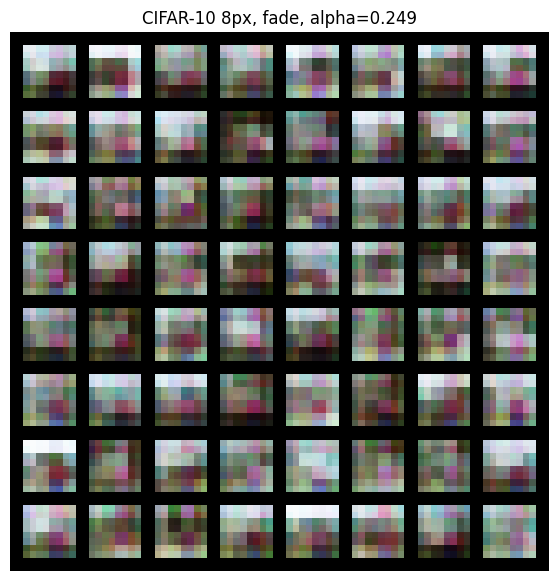

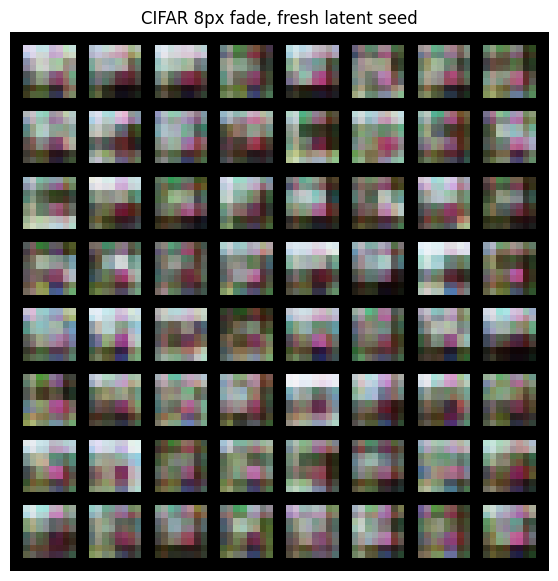

CIFAR 8px fade 2/4 | alpha 0.250->0.500 | G 0.401, critic 0.064, GP 0.010 | 5.8s
CIFAR 8px fade 3/4 | alpha 0.500->0.750 | G 1.087, critic -0.030, GP 0.011 | 5.8s
CIFAR 8px fade 4/4 | alpha 0.751->1.000 | G 1.193, critic -0.045, GP 0.010 | 5.9s


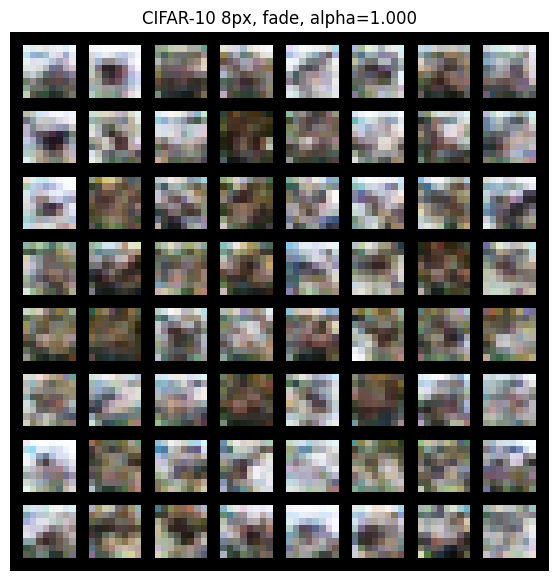

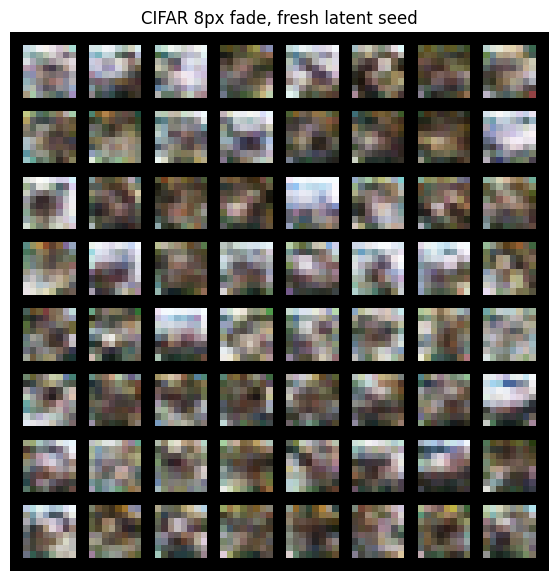

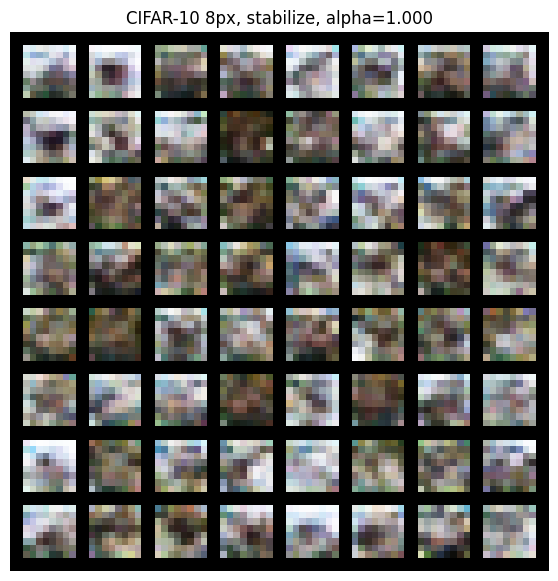

CIFAR 8px stabilize 1/4 | alpha 1.000->1.000 | G 0.675, critic -0.197, GP 0.010 | 5.9s


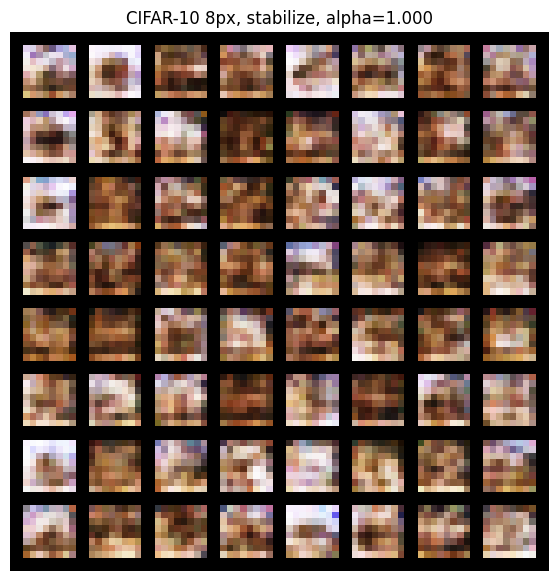

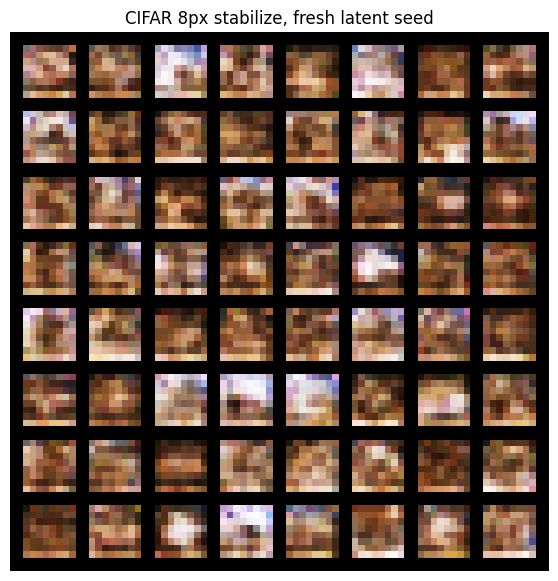

CIFAR 8px stabilize 2/4 | alpha 1.000->1.000 | G 0.710, critic -0.124, GP 0.008 | 5.9s
CIFAR 8px stabilize 3/4 | alpha 1.000->1.000 | G 0.260, critic -0.071, GP 0.008 | 5.9s
CIFAR 8px stabilize 4/4 | alpha 1.000->1.000 | G 0.081, critic -0.139, GP 0.008 | 5.9s


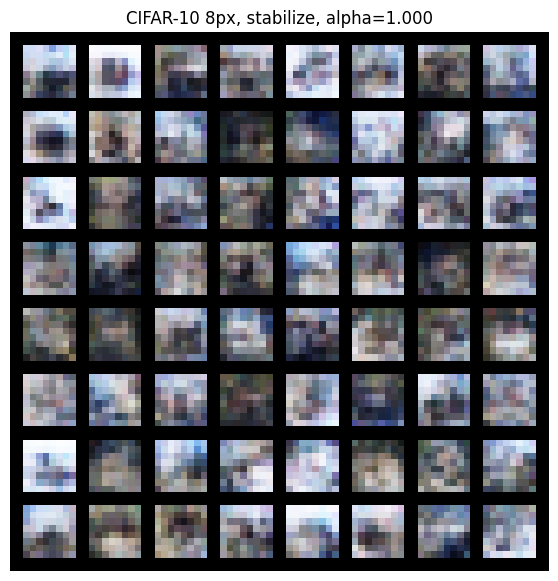

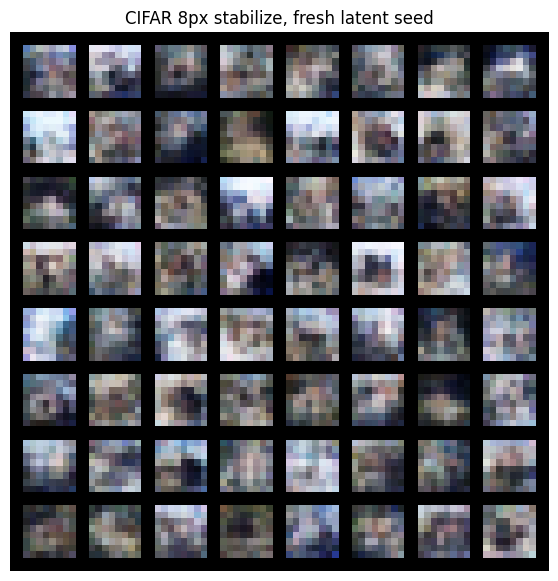

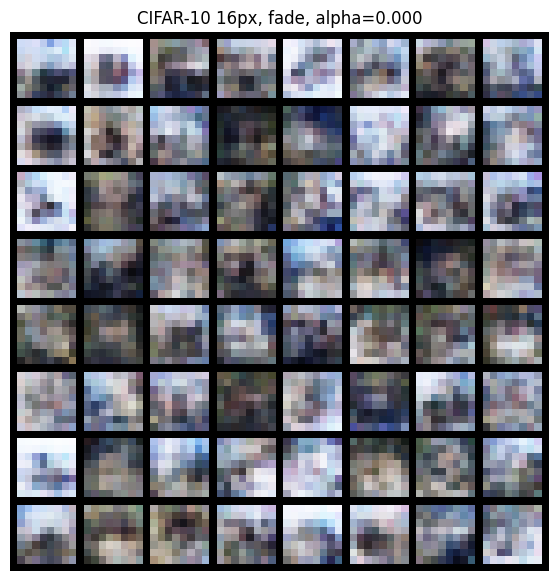

CIFAR 16px fade 1/4 | alpha 0.000->0.250 | G 1.777, critic 0.076, GP 0.018 | 14.0s


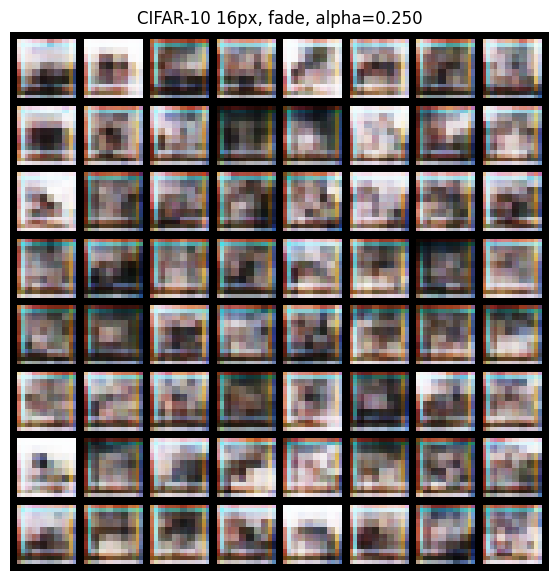

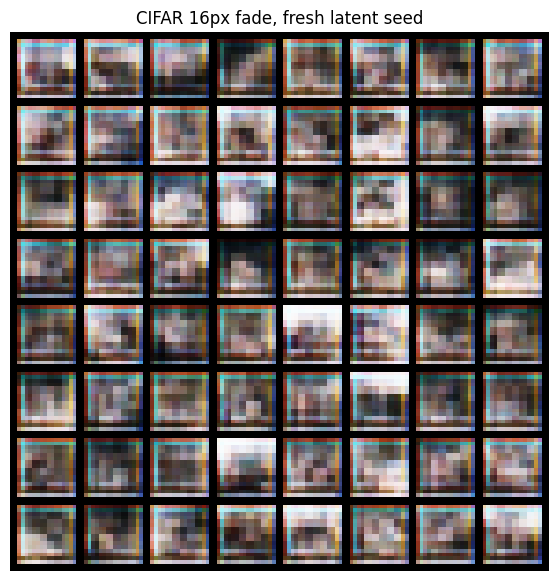

CIFAR 16px fade 2/4 | alpha 0.250->0.500 | G 3.173, critic -0.832, GP 0.017 | 14.0s
CIFAR 16px fade 3/4 | alpha 0.500->0.750 | G 2.354, critic -0.286, GP 0.012 | 14.3s
CIFAR 16px fade 4/4 | alpha 0.750->1.000 | G 1.153, critic -0.444, GP 0.010 | 14.1s


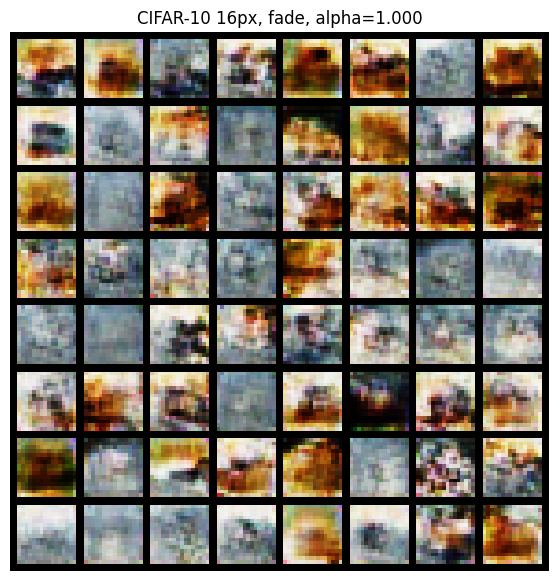

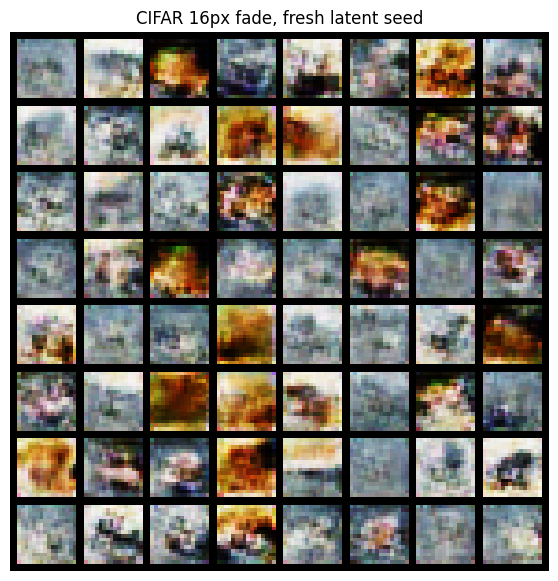

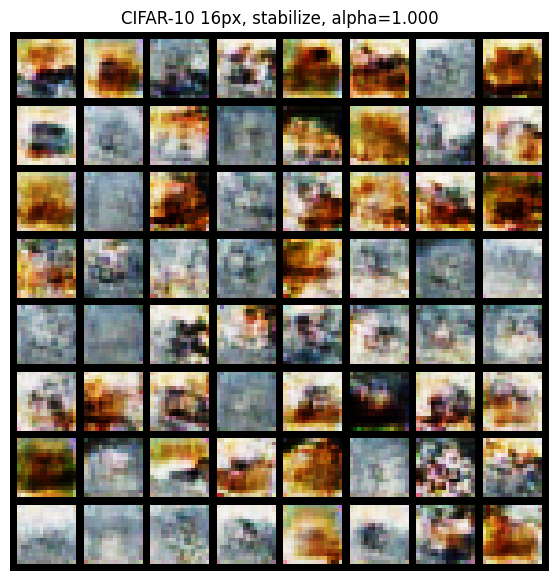

CIFAR 16px stabilize 1/8 | alpha 1.000->1.000 | G 0.098, critic -0.326, GP 0.006 | 14.0s


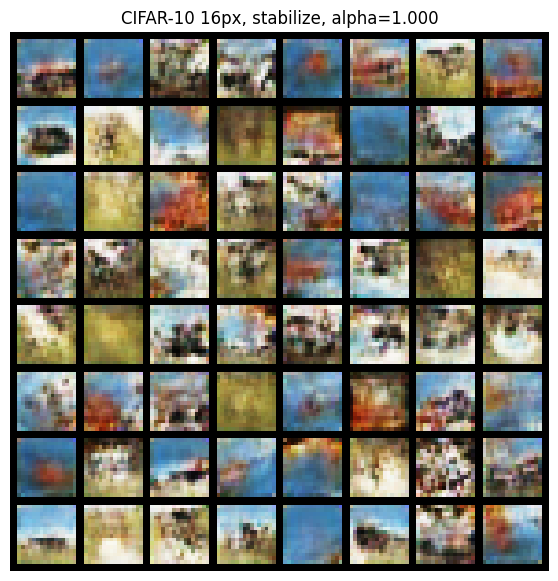

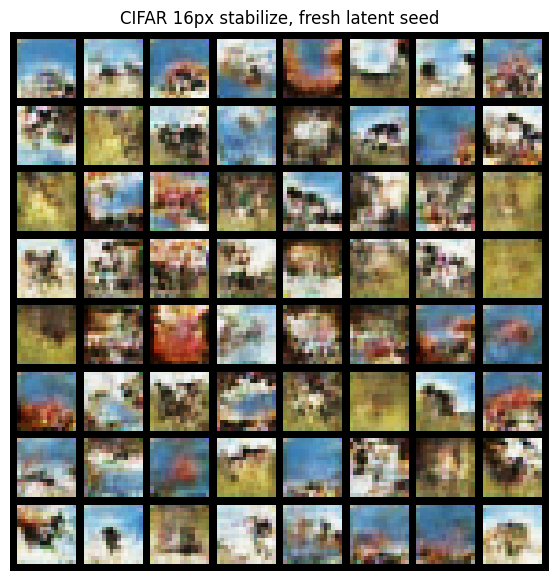

CIFAR 16px stabilize 2/8 | alpha 1.000->1.000 | G 0.499, critic -0.342, GP 0.005 | 14.0s
CIFAR 16px stabilize 3/8 | alpha 1.000->1.000 | G 0.243, critic -0.411, GP 0.005 | 13.8s
CIFAR 16px stabilize 4/8 | alpha 1.000->1.000 | G 0.491, critic -0.436, GP 0.006 | 13.9s


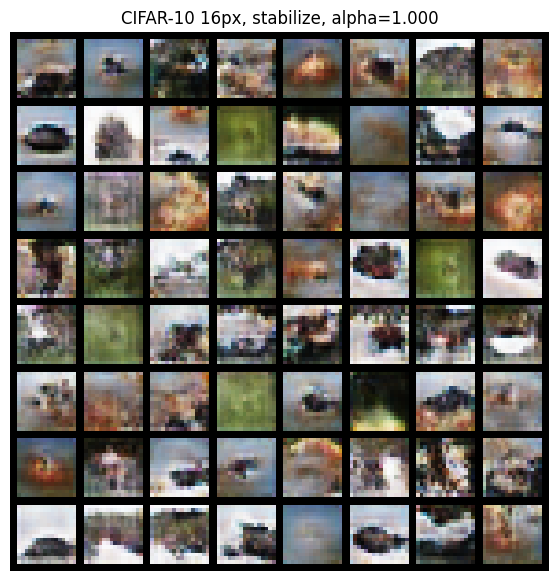

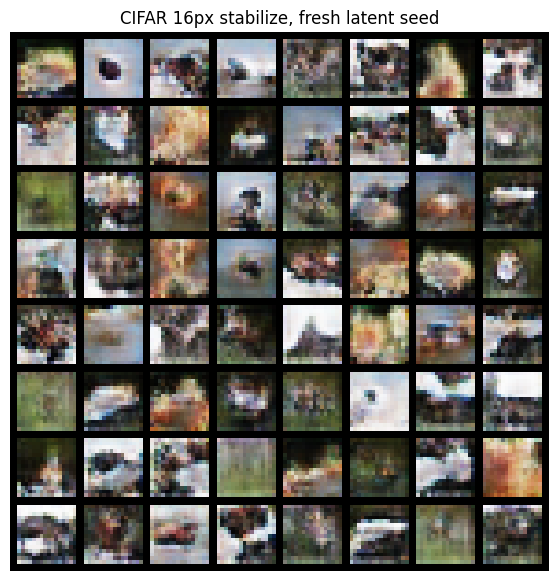

CIFAR 16px stabilize 5/8 | alpha 1.000->1.000 | G 0.635, critic -0.401, GP 0.007 | 13.8s
CIFAR 16px stabilize 6/8 | alpha 1.000->1.000 | G 0.807, critic -0.357, GP 0.007 | 13.9s
CIFAR 16px stabilize 7/8 | alpha 1.000->1.000 | G 0.799, critic -0.296, GP 0.007 | 14.0s
CIFAR 16px stabilize 8/8 | alpha 1.000->1.000 | G 0.420, critic -0.295, GP 0.007 | 13.8s


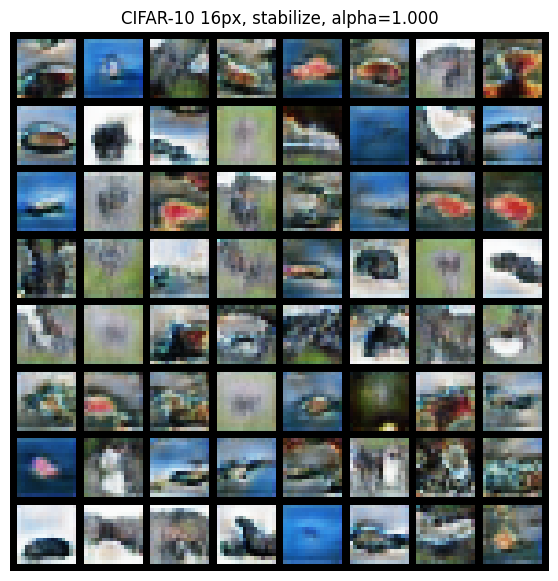

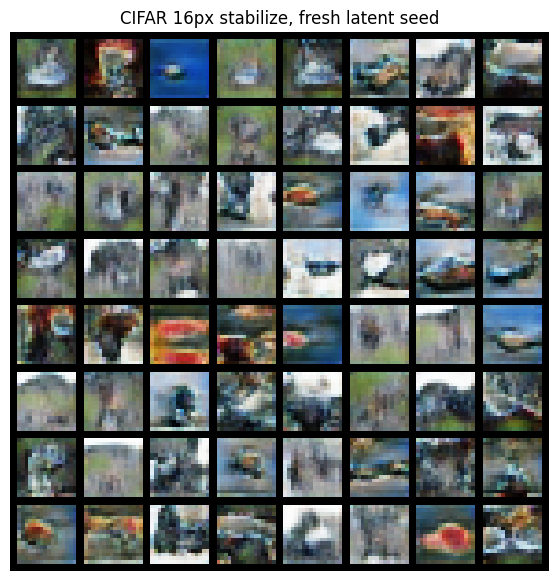

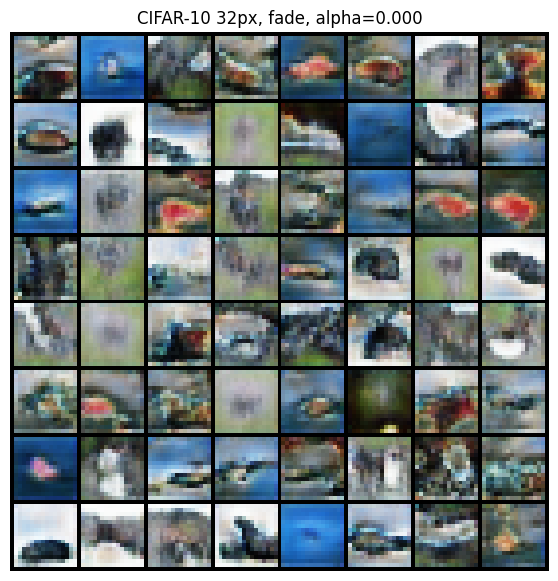

CIFAR 32px fade 1/8 | alpha 0.000->0.125 | G 1.291, critic -0.132, GP 0.018 | 20.9s


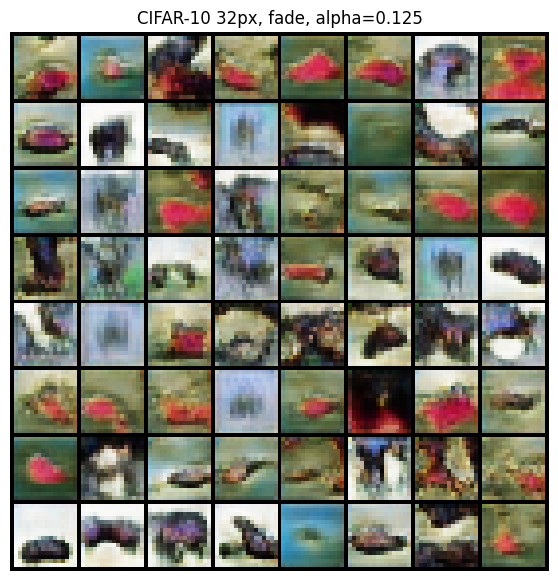

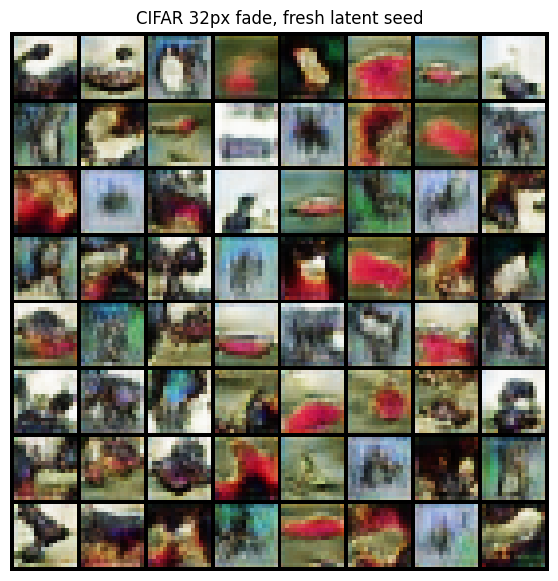

CIFAR 32px fade 2/8 | alpha 0.125->0.250 | G 2.617, critic -1.412, GP 0.016 | 21.0s
CIFAR 32px fade 3/8 | alpha 0.250->0.375 | G 1.630, critic -0.509, GP 0.009 | 21.1s
CIFAR 32px fade 4/8 | alpha 0.375->0.500 | G 0.721, critic -0.471, GP 0.008 | 21.0s


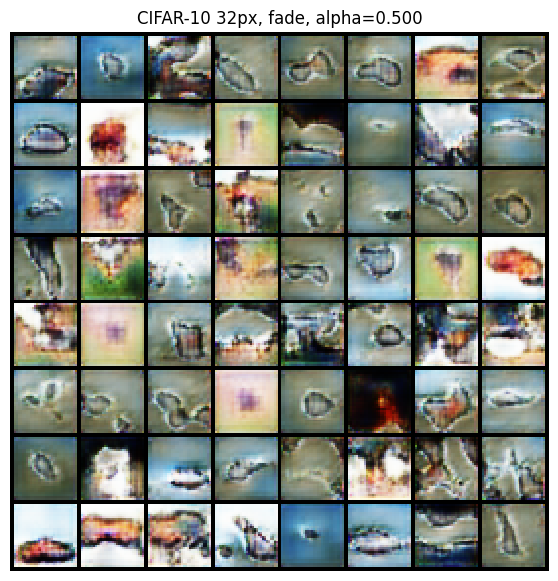

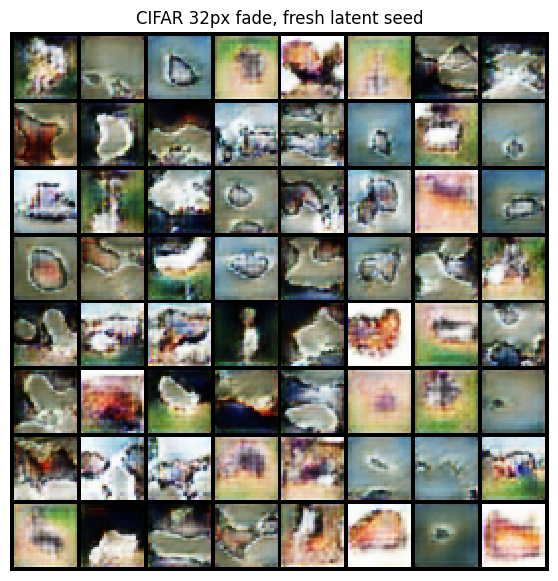

CIFAR 32px fade 5/8 | alpha 0.500->0.625 | G 1.173, critic -0.507, GP 0.008 | 20.7s
CIFAR 32px fade 6/8 | alpha 0.625->0.750 | G 1.069, critic -0.460, GP 0.006 | 20.8s
CIFAR 32px fade 7/8 | alpha 0.750->0.875 | G 0.863, critic -0.459, GP 0.006 | 20.7s
CIFAR 32px fade 8/8 | alpha 0.875->1.000 | G 0.891, critic -0.459, GP 0.005 | 20.9s


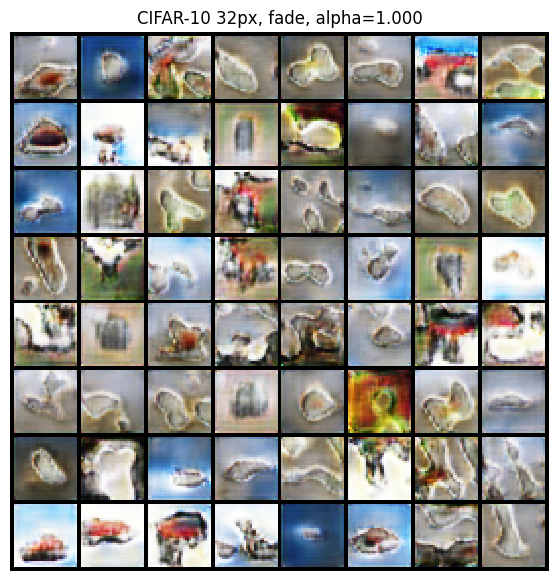

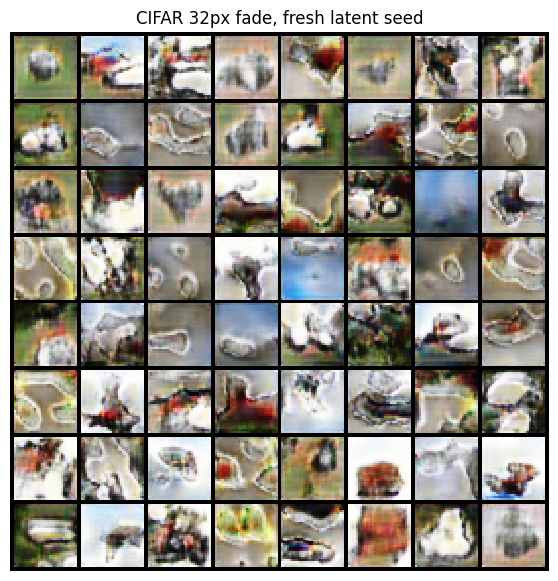

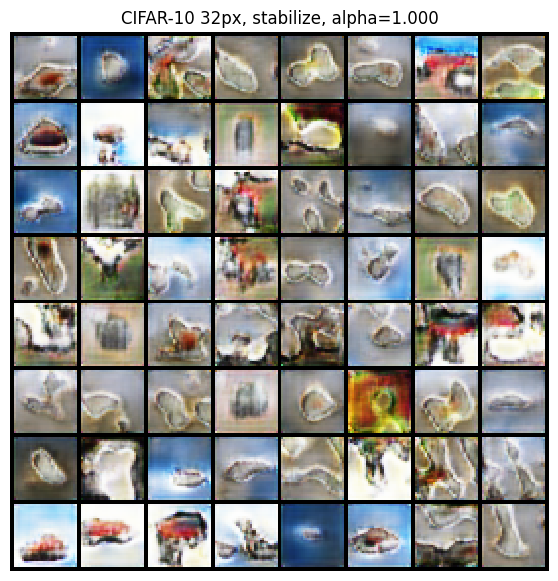

CIFAR 32px stabilize 1/16 | alpha 1.000->1.000 | G 0.884, critic -0.421, GP 0.005 | 20.7s


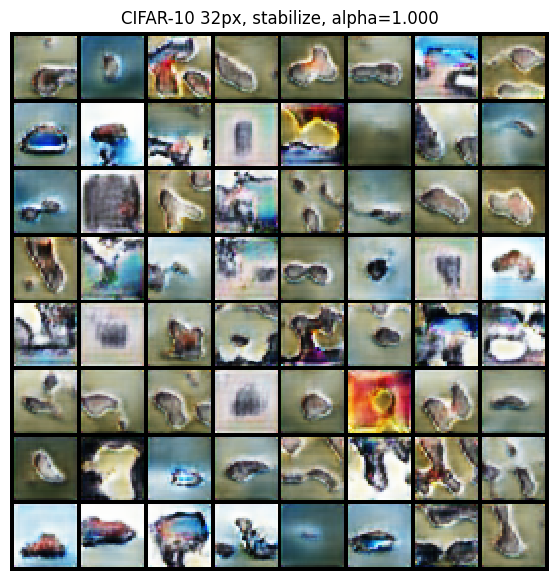

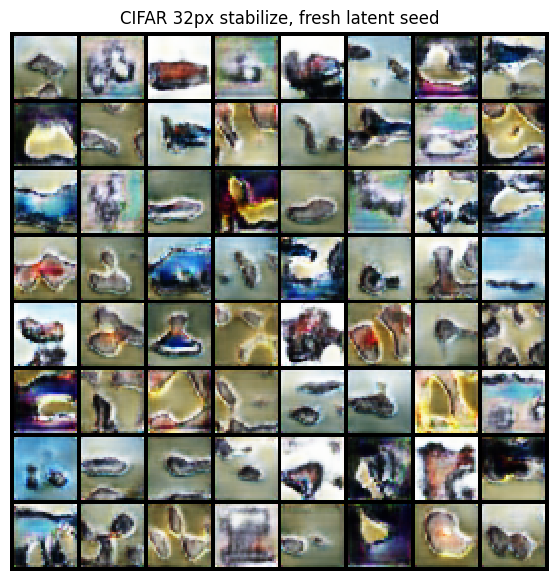

CIFAR 32px stabilize 2/16 | alpha 1.000->1.000 | G 0.792, critic -0.403, GP 0.005 | 20.7s
CIFAR 32px stabilize 3/16 | alpha 1.000->1.000 | G 0.650, critic -0.442, GP 0.005 | 21.2s
CIFAR 32px stabilize 4/16 | alpha 1.000->1.000 | G 0.807, critic -0.440, GP 0.006 | 21.1s


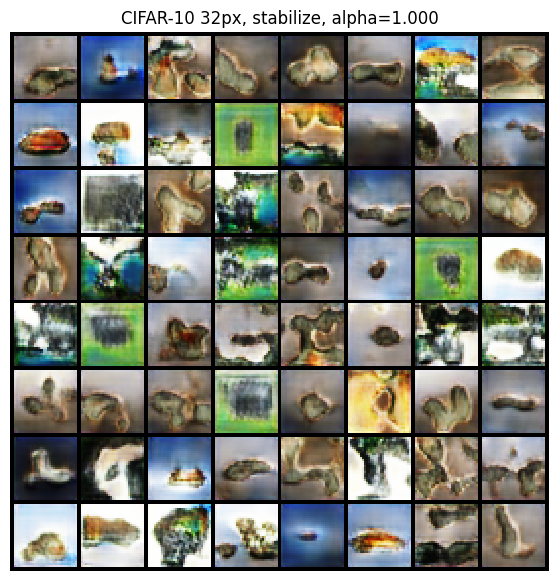

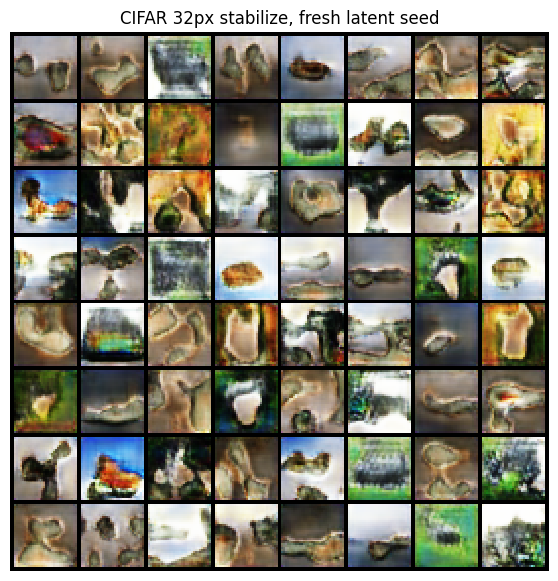

CIFAR 32px stabilize 5/16 | alpha 1.000->1.000 | G 0.879, critic -0.464, GP 0.006 | 21.0s
CIFAR 32px stabilize 6/16 | alpha 1.000->1.000 | G 0.845, critic -0.496, GP 0.006 | 20.9s
CIFAR 32px stabilize 7/16 | alpha 1.000->1.000 | G 0.877, critic -0.499, GP 0.006 | 20.8s
CIFAR 32px stabilize 8/16 | alpha 1.000->1.000 | G 0.944, critic -0.490, GP 0.006 | 20.8s


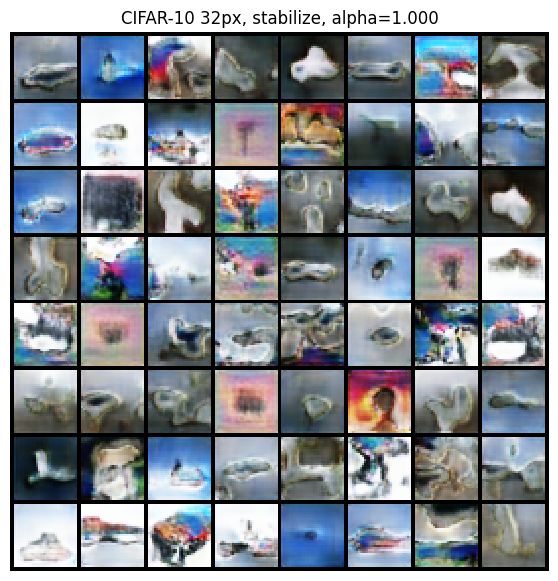

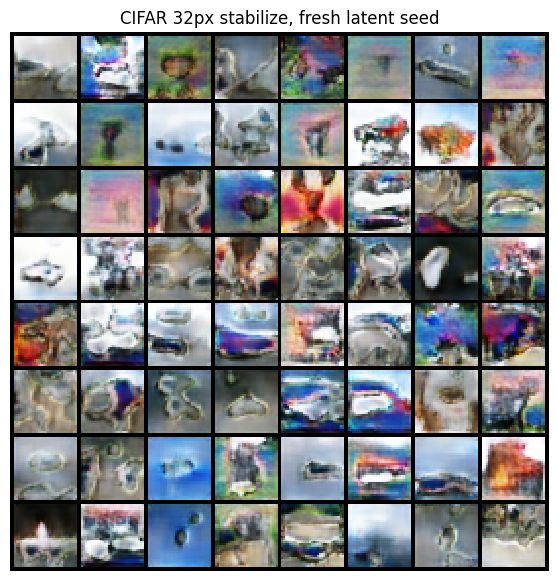

CIFAR 32px stabilize 9/16 | alpha 1.000->1.000 | G 1.002, critic -0.504, GP 0.006 | 20.7s
CIFAR 32px stabilize 10/16 | alpha 1.000->1.000 | G 0.860, critic -0.492, GP 0.006 | 20.8s
CIFAR 32px stabilize 11/16 | alpha 1.000->1.000 | G 1.046, critic -0.489, GP 0.007 | 20.9s
CIFAR 32px stabilize 12/16 | alpha 1.000->1.000 | G 0.765, critic -0.467, GP 0.007 | 21.2s


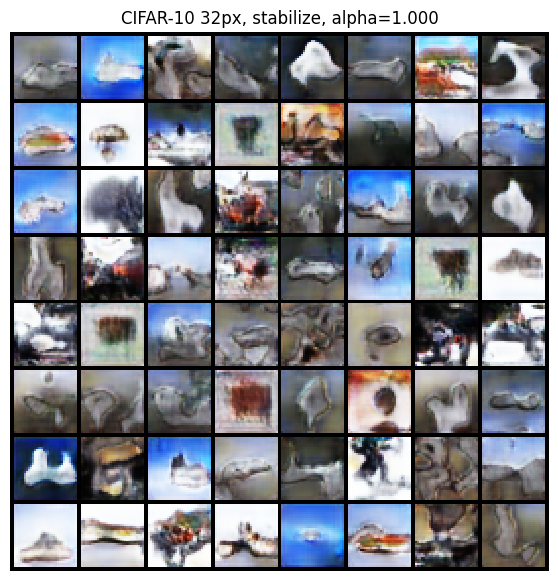

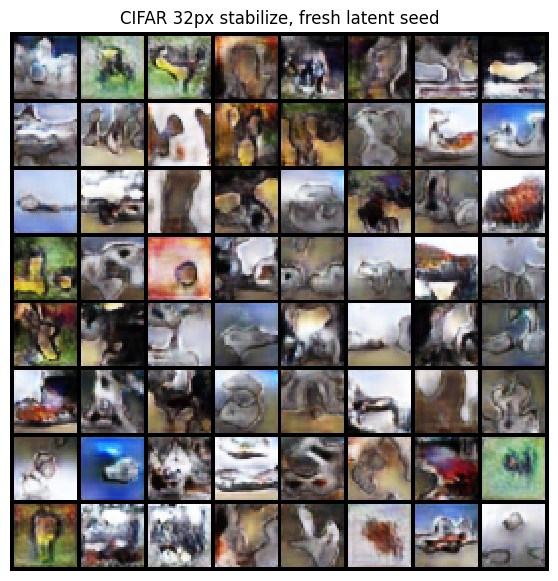

CIFAR 32px stabilize 13/16 | alpha 1.000->1.000 | G 0.875, critic -0.480, GP 0.006 | 21.0s
CIFAR 32px stabilize 14/16 | alpha 1.000->1.000 | G 0.758, critic -0.480, GP 0.006 | 20.9s
CIFAR 32px stabilize 15/16 | alpha 1.000->1.000 | G 0.826, critic -0.468, GP 0.006 | 20.8s
CIFAR 32px stabilize 16/16 | alpha 1.000->1.000 | G 0.654, critic -0.465, GP 0.006 | 20.7s


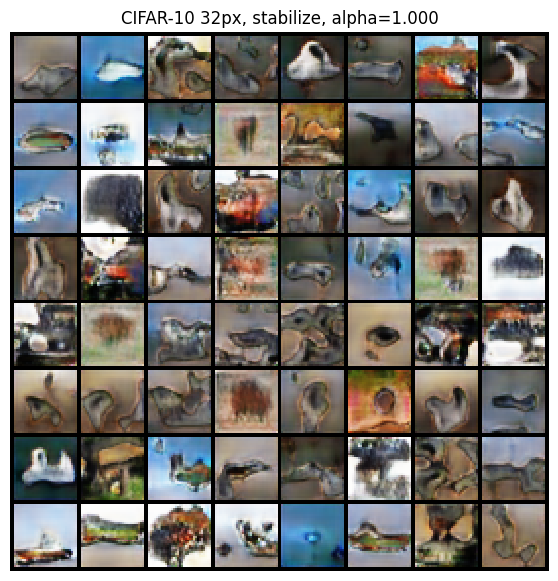

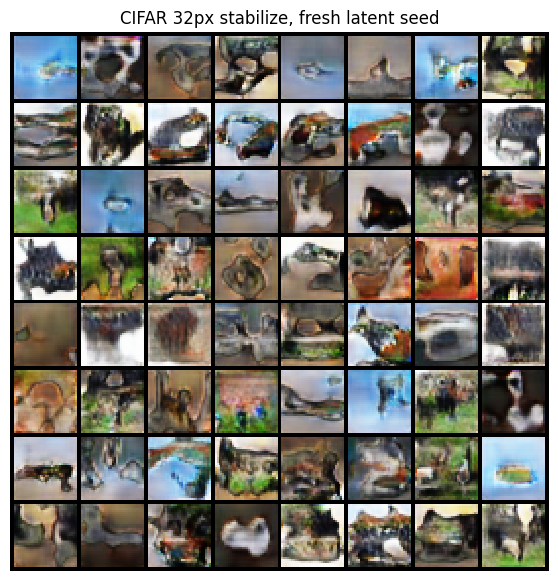

,global_epoch,resolution,stage,phase,phase_epoch,alpha_start,alpha_end,train_g_loss,train_critic_loss,train_gradient_penalty,train_critic_real,train_critic_fake,train_critic_gap,val_critic_real,val_critic_fake,val_critic_gap,val_g_loss,active_generator_parameters,active_critic_parameters,seconds
0,1,4,0,stabilize,1,1.000000,1.000000,0.924591,-0.471523,0.009558,-0.297477,-0.865041,0.567564,0.099145,0.021562,0.077583,-0.021562,412163,150145,4.120323
1,2,4,0,stabilize,2,1.000000,1.000000,0.057733,0.005961,0.009513,0.093678,0.004133,0.089545,-0.214312,-0.509073,0.294761,0.509073,412163,150145,3.964966
2,3,4,0,stabilize,3,1.000000,1.000000,-0.042962,0.102764,0.007014,0.069542,0.101852,-0.032310,0.532944,-0.052153,0.585097,0.052153,412163,150145,3.991068
3,4,4,0,stabilize,4,1.000000,1.000000,0.010216,0.067421,0.005375,0.028395,0.041803,-0.013408,0.192926,0.183376,0.009550,-0.183376,412163,150145,3.932697
4,5,8,1,fade,1,0.000000,0.249467,-0.527514,0.547092,0.011885,0.202264,0.629704,-0.427440,-0.151013,-0.100726,-0.050287,0.100726,707718,445825,6.045742
5,6,8,1,fade,2,0.250178,0.499645,0.401446,0.063971,0.009714,-0.118834,-0.153913,0.035079,-0.857359,-0.918456,0.061098,0.918456,707718,445825,5.839164
6,7,8,1,fade,3,0.500355,0.749822,1.087233,-0.029553,0.010506,-0.666101,-0.802945,0.136844,0.610926,0.295250,0.315677,-0.295250,707718,445825,5.834860
7,8,8,1,fade,4,0.750533,1.000000,1.193235,-0.045081,0.009867,-0.712389,-0.858252,0.145863,0.501273,0.132649,0.368624,-0.132649,707331,445313,5.867253
8,9,8,1,stabilize,1,1.000000,1.000000,0.674644,-0.196686,0.009875,-0.116571,-0.413540,0.296969,0.632934,1.448485,-0.815551,-1.448485,707331,445313,5.863231
9,10,8,1,stabilize,2,1.000000,1.000000,0.710325,-0.124331,0.008242,-0.207527,-0.416346,0.208819,-0.488483,-0.730237,0.241754,0.730237,707331,445313,5.896836


In [21]:
def pg_rgb_grid(images,nrow=8,padding=2):
    images=images.detach().cpu()
    n,c,h,w=images.shape
    columns=min(nrow,n)
    rows=math.ceil(n/columns)
    grid=images.new_zeros(3,rows*(h+padding)+padding,columns*(w+padding)+padding)
    for index,image in enumerate(images):
        row,column=divmod(index,columns)
        top,left=padding+row*(h+padding),padding+column*(w+padding)
        grid[:,top:top+h,left:left+w]=image
    return grid.permute(1,2,0).numpy()

@torch.no_grad()
def pg_generate(generator,stage,alpha,seed=123):
    generator.eval()
    rng=torch.Generator(device=DEVICE).manual_seed(seed)
    z=torch.randn(PG_SAMPLE_COUNT,PG_Z_DIM,device=DEVICE,generator=rng)
    return ((generator(z,stage,alpha)+1)/2).cpu()

def pg_show(images,title,path):
    fig,ax=plt.subplots(figsize=(7,7))
    ax.imshow(pg_rgb_grid(images),vmin=0,vmax=1,interpolation='nearest')
    ax.set_title(('SMOKE TEST | ' if SMOKE_TEST else '')+title)
    ax.axis('off')
    fig.savefig(path,dpi=120,bbox_inches='tight')
    plt.show()
    plt.close(fig)

@torch.no_grad()
def pg_evaluate(generator,critic,loader,stage,alpha,seed=2026):
    generator.eval()
    critic.eval()
    rng=torch.Generator(device=DEVICE).manual_seed(seed)
    real_total,fake_total,count=0.,0.,0
    resolution=PG_RESOLUTIONS[stage]
    for real,_ in loader:
        real=F.interpolate(real.to(DEVICE),size=(resolution,resolution),mode='area')
        fake=generator(torch.randn(len(real),PG_Z_DIM,device=DEVICE,generator=rng),stage,alpha)
        real_total+=critic(real,stage,alpha).sum().item()
        fake_total+=critic(fake,stage,alpha).sum().item()
        count+=len(real)
    return dict(critic_real=real_total/count,critic_fake=fake_total/count,
                critic_gap=(real_total-fake_total)/count,g_loss=-fake_total/count)

def train_progressive_gan():
    seed_all()
    generator=ProgressiveGenerator(PG_Z_DIM,PG_CHANNELS).to(DEVICE)
    critic=ProgressiveCritic(PG_CHANNELS).to(DEVICE)
    seed_all()
    opt_g=torch.optim.Adam(generator.parameters(),lr=PG_LEARNING_RATE,betas=(0.,0.99))
    opt_d=torch.optim.Adam(critic.parameters(),lr=PG_LEARNING_RATE,betas=(0.,0.99))
    config=dict(resolutions=PG_RESOLUTIONS,channels=PG_CHANNELS,z_dim=PG_Z_DIM,
                batch_sizes=PG_BATCH_SIZES,fade_epochs=PG_FADE_EPOCHS,stable_epochs=PG_STABLE_EPOCHS,
                learning_rate=PG_LEARNING_RATE,adam_betas=[0.,0.99],gradient_penalty=PG_GP_WEIGHT,
                drift=PG_DRIFT_WEIGHT,updates='one critic and one G step per batch',seed=SEED,
                data_source=PG_DATA_SOURCE,smoke_test=SMOKE_TEST,
                generator_parameters=sum(p.numel() for p in generator.parameters()),
                critic_parameters=sum(p.numel() for p in critic.parameters()))
    (PG_RESULTS/'config.json').write_text(json.dumps(config,indent=2))
    history,snapshots=[],[]
    global_epoch,global_step=0,0
    def snapshot(stage,alpha,phase,tag):
        filename=f'{PG_RESOLUTIONS[stage]}px_{phase}_{tag}.png'
        pg_show(pg_generate(generator,stage,alpha),f'CIFAR-10 {PG_RESOLUTIONS[stage]}px, {phase}, alpha={alpha:.3f}',
                PG_RESULTS/filename)
        snapshots.append(dict(resolution=PG_RESOLUTIONS[stage],stage=stage,phase=phase,
                              alpha=alpha,global_epoch=global_epoch,path=filename))
        (PG_RESULTS/'snapshots.json').write_text(json.dumps(snapshots,indent=2))
    for stage,resolution in enumerate(PG_RESOLUTIONS):
        train,val=pg_data_loaders(stage)
        if stage==0:
            config.update(train_size=len(train.dataset),validation_size=len(val.dataset))
            (PG_RESULTS/'config.json').write_text(json.dumps(config,indent=2))
        phases=[]
        if stage>0: phases.append(('fade',1 if SMOKE_TEST else PG_FADE_EPOCHS[resolution]))
        phases.append(('stabilize',1 if SMOKE_TEST else PG_STABLE_EPOCHS[resolution]))
        for phase,epochs in phases:
            phase_step,total_steps=0,epochs*len(train)
            snapshot(stage,0. if phase=='fade' else 1.,phase,'start')
            for phase_epoch in range(1,epochs+1):
                started=time.perf_counter()
                generator.train()
                critic.train()
                totals=dict(g_loss=0.,critic_loss=0.,gradient_penalty=0.,critic_real=0.,critic_fake=0.,critic_gap=0.)
                count,alphas=0,[]
                for real,_ in train:
                    alpha=fade_alpha(phase_step,total_steps) if phase=='fade' else 1.
                    real=F.interpolate(real.to(DEVICE),size=(resolution,resolution),mode='area')
                    values=progressive_step(real,generator,critic,opt_g,opt_d,stage,alpha,PG_Z_DIM)
                    for key,value in values.items(): totals[key]+=value*len(real)
                    count+=len(real)
                    alphas.append(alpha)
                    phase_step+=1
                    global_step+=1
                global_epoch+=1
                validation=pg_evaluate(generator,critic,val,stage,alpha)
                g_active,d_active=active_parameter_counts(generator,critic,stage,alpha)
                row=dict(global_epoch=global_epoch,resolution=resolution,stage=stage,phase=phase,
                         phase_epoch=phase_epoch,alpha_start=alphas[0],alpha_end=alpha,
                         **{'train_'+key:value/count for key,value in totals.items()},
                         **{'val_'+key:value for key,value in validation.items()},
                         active_generator_parameters=g_active,active_critic_parameters=d_active,
                         seconds=time.perf_counter()-started)
                history.append(row)
                pd.DataFrame(history).to_csv(PG_RESULTS/'history.csv',index=False)
                print(f'CIFAR {resolution}px {phase} {phase_epoch}/{epochs} | alpha {alphas[0]:.3f}->{alpha:.3f} | G {row["train_g_loss"]:.3f}, critic {row["train_critic_loss"]:.3f}, GP {row["train_gradient_penalty"]:.3f} | {row["seconds"]:.1f}s',flush=True)
                if phase_epoch==1 or phase_epoch%4==0 or phase_epoch==epochs:
                    snapshot(stage,alpha,phase,f'epoch_{phase_epoch:03d}')
                    pg_show(pg_generate(generator,stage,alpha,seed=1000+global_epoch),
                            f'CIFAR {resolution}px {phase}, fresh latent seed',
                            PG_RESULTS/f'{resolution}px_{phase}_fresh_{phase_epoch:03d}.png')
            checkpoint=dict(generator=generator.state_dict(),critic=critic.state_dict(),
                            optimizer_g=opt_g.state_dict(),optimizer_d=opt_d.state_dict(),
                            stage=stage,alpha=1.,phase=phase,global_epoch=global_epoch,
                            global_step=global_step,config=config)
            torch.save(checkpoint,PG_CHECKPOINTS/f'{resolution}px_{phase}.pt')
    final=PG_CHECKPOINTS/'final_32px.pt'
    torch.save(checkpoint,final)
    return dict(checkpoint=str(final),epochs=global_epoch,steps=global_step,
                seconds=sum(row['seconds'] for row in history),snapshots=snapshots)

pg_run=train_progressive_gan()
display(pd.read_csv(PG_RESULTS/'history.csv'))


### 3.5 Training curves and growth evolution

The curves show objectives, gradient penalty and alpha, with resolution boundaries. Loss scales change with resolution and critic capacity, so they are not direct visual-quality scores.

The evolution panels use the same latent inputs at each resolution and show the beginning and end of fade-in. Old and new weights both continued training during fade, so later images could change beyond the blending effect.


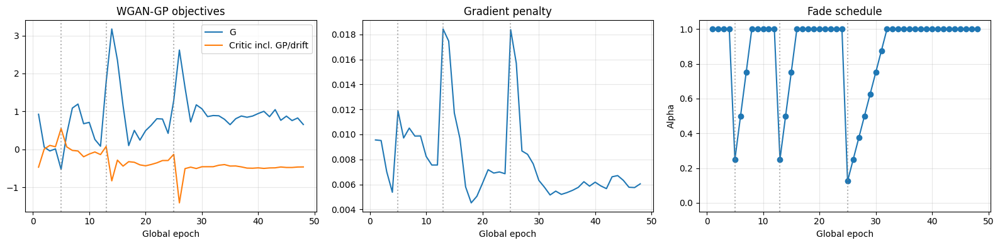

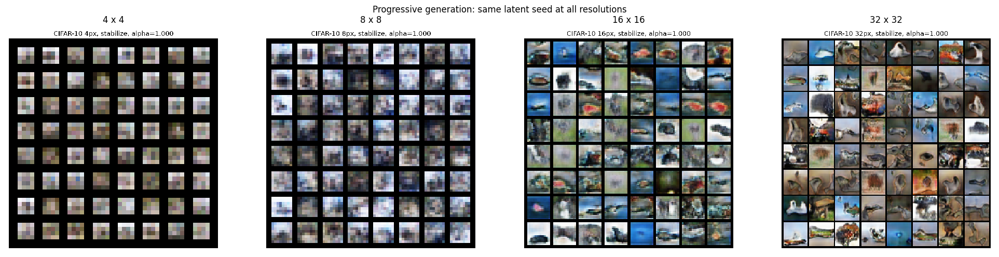

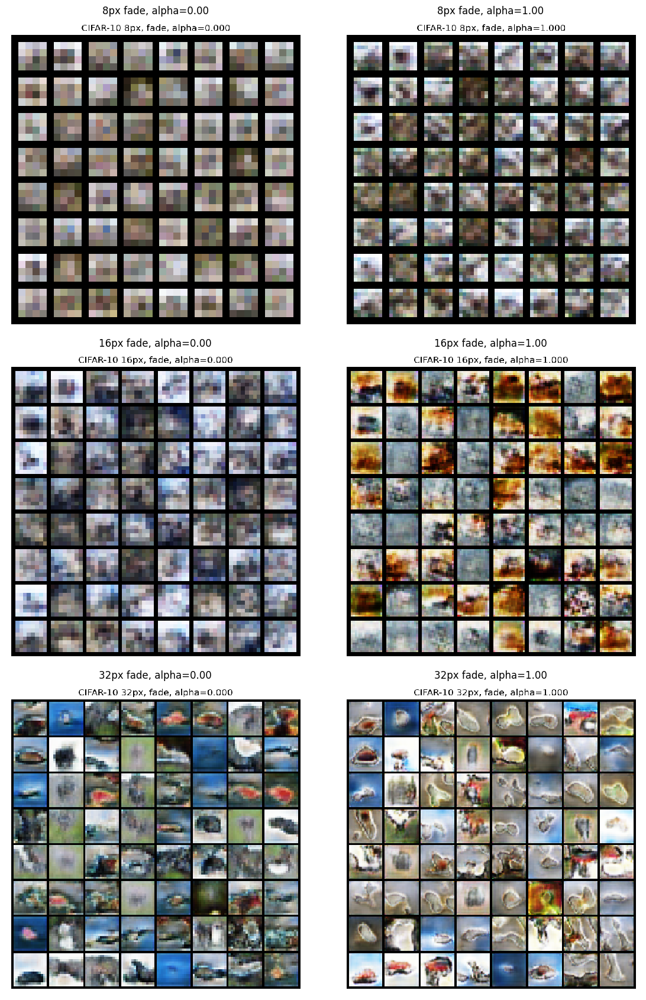

In [22]:
pg_history=pd.read_csv(PG_RESULTS/'history.csv')
fig,axes=plt.subplots(1,3,figsize=(16,4))
axes[0].plot(pg_history.global_epoch,pg_history.train_g_loss,label='G')
axes[0].plot(pg_history.global_epoch,pg_history.train_critic_loss,label='Critic incl. GP/drift')
axes[0].set(title='WGAN-GP objectives',xlabel='Global epoch')
axes[0].legend()
axes[1].plot(pg_history.global_epoch,pg_history.train_gradient_penalty,label='Gradient penalty')
axes[1].set(title='Gradient penalty',xlabel='Global epoch')
axes[2].plot(pg_history.global_epoch,pg_history.alpha_end,'o-',label='Alpha at epoch end')
axes[2].set(title='Fade schedule',xlabel='Global epoch',ylabel='Alpha',ylim=(-.05,1.05))
for ax in axes:
    for resolution in PG_RESOLUTIONS[1:]:
        first=pg_history.loc[pg_history.resolution==resolution,'global_epoch'].iloc[0]
        ax.axvline(first,color='gray',linestyle=':',alpha=.6)
    ax.grid(alpha=.3)
fig.tight_layout()
fig.savefig(PG_RESULTS/'training_and_growth_curves.png',dpi=130)
plt.show()
plt.close(fig)

fig,axes=plt.subplots(1,4,figsize=(20,5))
for ax,resolution in zip(axes,PG_RESOLUTIONS):
    selected=[s for s in pg_run['snapshots'] if s['resolution']==resolution and s['phase']=='stabilize'][-1]
    ax.imshow(plt.imread(PG_RESULTS/selected['path']),interpolation='nearest')
    ax.set_title(f'{resolution} x {resolution}')
    ax.axis('off')
fig.suptitle(('SMOKE TEST | ' if SMOKE_TEST else '')+'Progressive generation: same latent seed at all resolutions')
fig.tight_layout()
fig.savefig(PG_RESULTS/'resolution_evolution.png',dpi=130,bbox_inches='tight')
plt.show()
plt.close(fig)

fig,axes=plt.subplots(3,2,figsize=(12,17))
for row,resolution in enumerate(PG_RESOLUTIONS[1:]):
    candidates=[s for s in pg_run['snapshots'] if s['resolution']==resolution and s['phase']=='fade']
    for ax,snapshot in zip(axes[row],[candidates[0],candidates[-1]]):
        ax.imshow(plt.imread(PG_RESULTS/snapshot['path']),interpolation='nearest')
        ax.set_title(f'{resolution}px fade, alpha={snapshot["alpha"]:.2f}')
        ax.axis('off')
fig.tight_layout()
fig.savefig(PG_RESULTS/'fade_evolution.png',dpi=130,bbox_inches='tight')
plt.show()
plt.close(fig)


### 3.6 Final CIFAR-10 comparison

The final 32×32 checkpoint was compared with real test images and three additional latent seeds. Samples showed varied colours and some object-like structure, but blur and ambiguous objects remained.

Held-out critic diagnostics are not likelihood, FID, exact Wasserstein distance or class-coverage scores. Without a matched fixed-resolution model, the results describe this progressive run rather than proving that growth caused an improvement.


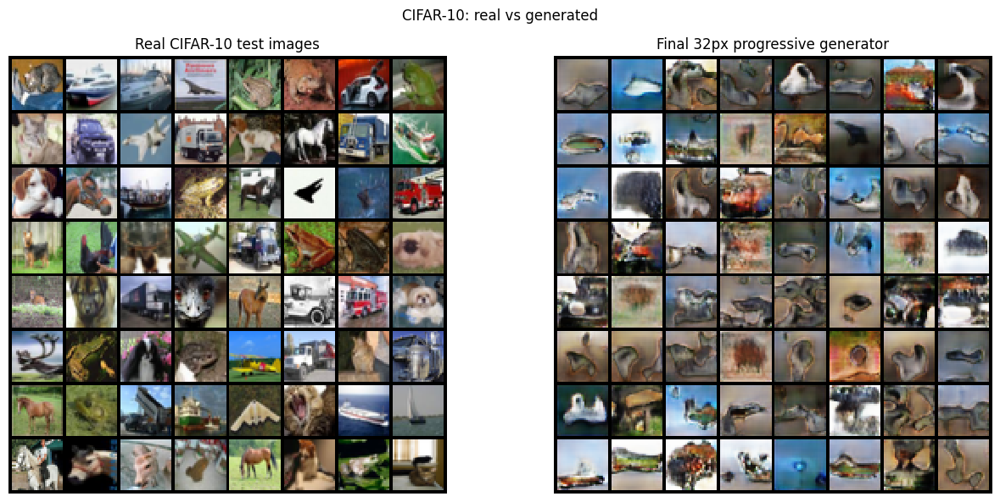

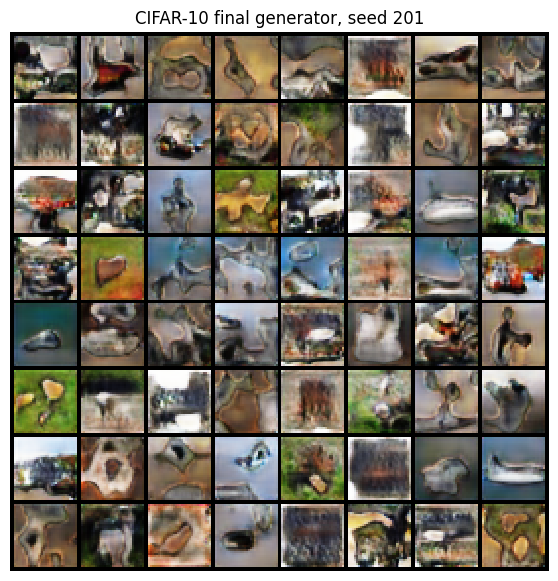

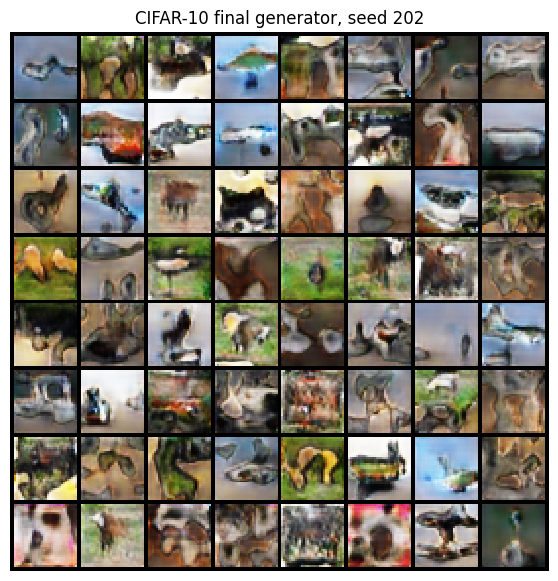

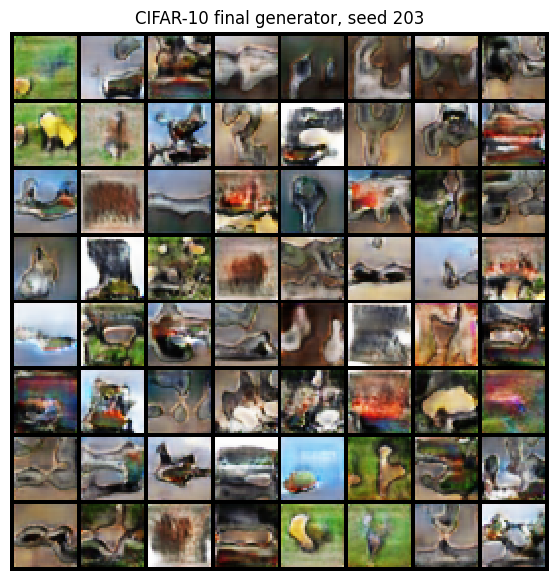

,critic_real,critic_fake,critic_gap,g_loss
0,1.995502,1.85984,0.135663,-1.85984


In [23]:
pg_saved=torch.load(pg_run['checkpoint'],map_location=DEVICE,weights_only=True)
pg_generator=ProgressiveGenerator(PG_Z_DIM,PG_CHANNELS).to(DEVICE)
pg_critic=ProgressiveCritic(PG_CHANNELS).to(DEVICE)
pg_generator.load_state_dict(pg_saved['generator'])
pg_critic.load_state_dict(pg_saved['critic'])
pg_test=pg_test_loader()
pg_test_values=pg_evaluate(pg_generator,pg_critic,pg_test,stage=3,alpha=1.,seed=3030)
pd.DataFrame([dict(dataset=PG_DATA_SOURCE,**pg_test_values,smoke_test=SMOKE_TEST,
                   interpretation='critic diagnostics, not image quality or likelihood')]).to_csv(PG_RESULTS/'test_critic_diagnostics.csv',index=False)
real=next(iter(pg_test))[0][:PG_SAMPLE_COUNT]
fake=pg_generate(pg_generator,3,1.)
fig,axes=plt.subplots(1,2,figsize=(13,6))
for ax,images,title in zip(axes,[(real+1)/2,fake],['Real CIFAR-10 test images','Final 32px progressive generator']):
    ax.imshow(pg_rgb_grid(images),vmin=0,vmax=1,interpolation='nearest')
    ax.set_title(title)
    ax.axis('off')
fig.suptitle('SMOKE TEST' if SMOKE_TEST else 'CIFAR-10: real vs generated')
fig.tight_layout()
fig.savefig(PG_RESULTS/'real_vs_generated_32px.png',dpi=130,bbox_inches='tight')
plt.show()
plt.close(fig)
for seed in (201,202,203):
    pg_show(pg_generate(pg_generator,3,1.,seed),f'CIFAR-10 final generator, seed {seed}',
            PG_RESULTS/f'final_seed_{seed}.png')
display(pd.DataFrame([pg_test_values]))
